In [1]:
import os
import pickle
import time

import sympy
from copy import deepcopy
from joblib import Parallel, delayed
from tqdm import tqdm
import seaborn as sns
from tabulate import tabulate
from models.factory import create_model_from_graph
from models.flow import causalflow_model
from models.kan import symbolic_kan_regressor
from utils.hyperparams import get_best_hyperparams
from utils.metrics import mmd, rf
from utils.paths import get_experiment_paths
import matplotlib.pyplot as plt
import ipywidgets as widgets
from datasets.sachs import ExperimentationModel, get_structural_equations_sachs, graph_sachs, noises_distr


No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


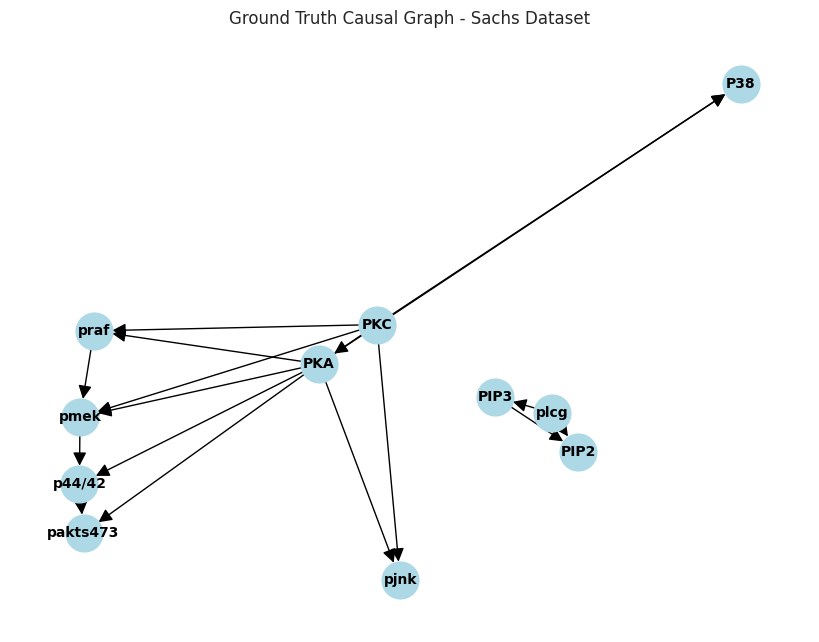

In [3]:
# Show the ground truth graph
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(graph_sachs)
nx.draw(graph_sachs, pos, with_labels=True, node_size=700, node_color='lightblue', font_size=10, font_weight='bold', arrowsize=20)
plt.title("Ground Truth Causal Graph - Sachs Dataset")
plt.show()

100%|██████████| 11/11 [00:05<00:00,  1.92it/s]


Train set shape: (1000, 11), Test set shape: (1000, 11), Num of interventions: 660


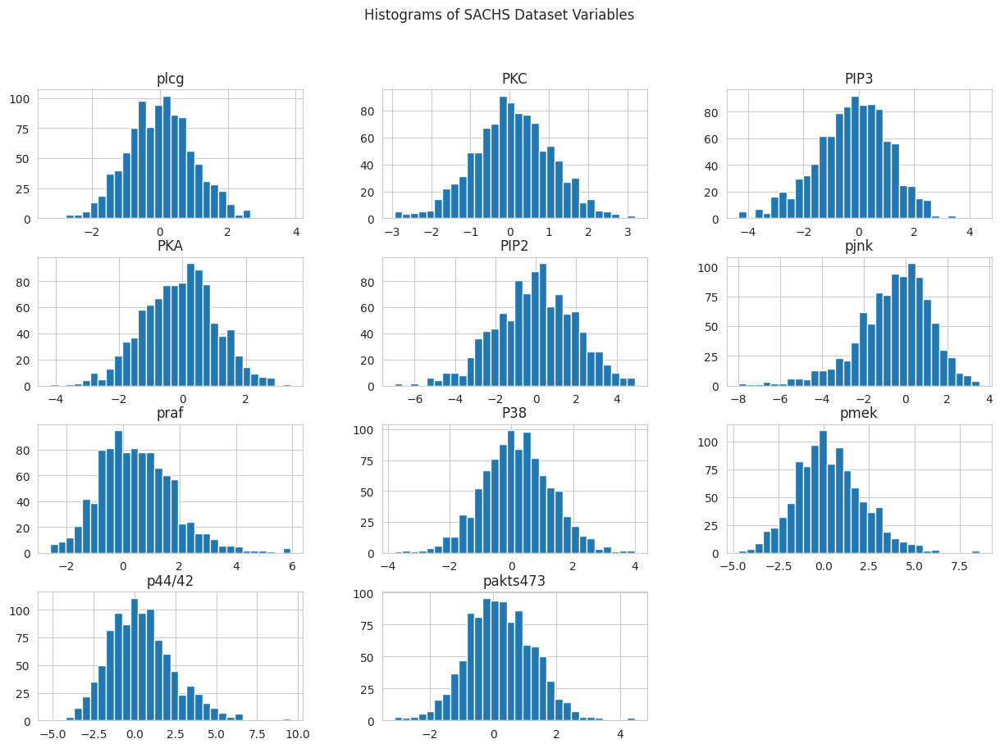

In [4]:
# Generate the SACHS dataset using the structural equations defined as examples in sachs_functions.py
num_samples_train = 1000
num_samples_eval = 1000
structural_equations = get_structural_equations_sachs()
sachs_generator = ExperimentationModel(graph_sachs, "sachs", structural_equations['additive'], noises_distr)
np.random.seed(42)  # Set seed for repeatability
factual_train, noise_train = sachs_generator.sample(num_samples_train)
factual_eval, noise_eval = sachs_generator.sample(num_samples_eval)

cf_min_val = -3
cf_max_val = 3
cf_step = 0.1
cf_vector_values = np.arange(cf_min_val, cf_max_val, cf_step)
data_cf_eval = []
inter_vector = []
for node in tqdm(factual_eval.columns):
    values = list(cf_vector_values)
    for value in values:
        inter_vector.append((node, value, sachs_generator.get_counterfactuals({node: lambda x: value}, noise_eval)[factual_eval.columns]))

print(f'Train set shape: {factual_train.shape}, Test set shape: {factual_eval.shape}, Num of interventions: {len(inter_vector)}')

paths = get_experiment_paths('sachs')
results_bdir = str(paths.root)
images_dir = str(paths.images)
samples_dir = str(paths.samples)
data_dir = str(paths.data)

factual_train.to_csv(os.path.join(data_dir, 'sachs_factual_train.csv'), index=False)
factual_eval.to_csv(os.path.join(data_dir, 'sachs_factual_eval.csv'), index=False)

with open(os.path.join(data_dir, 'sachs_interventions_eval.pkl'), 'wb') as f:
    pickle.dump(inter_vector, f, protocol=pickle.HIGHEST_PROTOCOL)

# Show a histogram of all the variables in the dataset, both of train and test
factual_train.hist(bins=30, figsize=(15, 10))
plt.suptitle("Histograms of SACHS Dataset Variables")
plt.show()


In [4]:
# Now, do a grid search to find the best hyperparameters for the proposed methods, note that this may take a while depending on the number of combinations and the dataset size

model_names = ['kan', 'kaam', 'anm', 'dbcm', 'flow']  # Put KAAM after KAN to reuse the hyperparameters found for KAN
load_best_params = True  # Set to True to load previously found best hyperparameters, this means that the grid search will be skipped if best hyperparameters were already found--the grid search is time-consuming (~1.5 hours), but training models with found hyperparameters is fast (~3 minutes)
verbose = True
n_threads = 30  # Number of threads for parallel hyperparameter search, be careful not to exceed your machine capabilities, in ours, it takes around 1.5 hours to do the full search with 30 threads

kan_params = {'hidden_dim': [0, 5], # Note that KAAM parameters are the same, only that mult_kan is False and hidden_dim is 0
              'batch_size': [-1],
              'grid': [1, 5, 10],
              'k': [1, 5, 10],
              'seed': [0],
              'lr': [0.01, 0.001, 0.0001],
              'early_stop': [True],
              'steps': [10000],
              'lamb': [1, 0.1, 0.001],
              'lamb_entropy': [0.1],
              'sparse_init': [False],
              'mult_kan': [False, True],
              'try_gpu': [False],
              'loss': ['mse']}
dbcm_params = {'num_epochs' : [100, 200, 500],
               'lr' : [0.01, 0.001, 0.0001],
               'batch_size': [32, 64, 128],
               'hidden_dim' : [32, 64, 128]}

flow_params = {'flow_type': ['CausalNSF', 'CausalMAF'],
               'hidden_dims': [(32, 32), (64, 64), (64, 64, 64), (128, 128)],
               'base_lr': [1e-2, 1e-3, 1e-4, 1e-5],
               'early_stopping_patience': [30],
               'scheduler': [None, 'plateau'],
               'batch_size': [256],
               'train_val_split': [(0.8, 0.2)],
               'max_epochs': [1000],
               'device': ['cpu'],
               'bins': [4, 8, 16]}

for model_name in model_names:
    # Create model
    params = {}
    if model_name == 'kan' or model_name == 'kaam':  # Note that the best hyperparameters are found for a single run, and for a number of data!
        params = get_best_hyperparams(model_name, 'sachs', kan_params, graph_sachs, factual_train, factual_eval, load_best_params, verbose, data_dir, n_threads)
    if model_name == 'dbcm':
        params = get_best_hyperparams(model_name, 'sachs', dbcm_params, graph_sachs, factual_train, factual_eval, load_best_params, verbose, data_dir, n_threads)
    if model_name == 'flow':
        params = get_best_hyperparams(model_name, 'sachs', flow_params, graph_sachs, factual_train, factual_eval, load_best_params, verbose, data_dir, n_threads)

    if model_name == 'flow':
        model = causalflow_model(graph_sachs, deepcopy(params))
        t = time.time()
        model.fit(data=factual_train)
        training_time = time.time() - t
    else:
        model = create_model_from_graph(graph_sachs, model_name, params=params)
        if model_name == 'anm':
            summary_auto_assignment = gcm.auto.assign_causal_mechanisms(model, factual_train, override_models=True) # Note: we can print the summary to know what has been selected
        # Fit model
        t = time.time()
        gcm.fit(model, data=factual_train)
        training_time = time.time() - t

    # Evaluate the model
    results = {'training_time': training_time, 'model': model_name}
    np.random.seed(42) # Set the seed for reproducibility
    ## Observational evaluation
    if model_name == 'flow':
        obs_samples = model.draw_samples(num_samples=len(factual_eval))
    else:
        obs_samples = gcm.draw_samples(model, num_samples=len(factual_eval))
    obs_samples = obs_samples[factual_eval.columns]  # Ensure the same column order
    obs_samples.to_csv(os.path.join(samples_dir, f"sachs_obs_samples_{model_name}.csv"), index=False)
    results['mmd_obs_avg'] = mmd(factual_eval.to_numpy(), obs_samples.to_numpy())
    results['rf_acc_obs_avg'] = rf(factual_eval.to_numpy(), obs_samples.to_numpy())

    ## Interventional and counterfactual evaluation
    def evaluate_cf(node, value, cf_eval):
        if model_name == 'flow':
            int_samples = model.interventional_samples({node: lambda x: value}, num_samples_to_draw=len(factual_eval))
            cf_estimates = model.counterfactual_samples({node: lambda x: value}, factual_samples=factual_eval)
        else:
            int_samples = gcm.interventional_samples(model, {node: lambda x: value}, num_samples_to_draw=len(factual_eval))
            cf_estimates = gcm.counterfactual_samples(model, {node: lambda x: value}, observed_data=factual_eval)
        int_samples = int_samples[factual_eval.columns]  # Ensure the same column order
        cf_estimates = cf_estimates[factual_eval.columns]
        mmd_int_ = mmd(cf_eval.to_numpy(), int_samples.to_numpy())
        rf_acc_int_ = rf(cf_eval.to_numpy(), int_samples.to_numpy())
        mse_cf_ = np.mean(np.square(cf_eval.to_numpy() - cf_estimates.to_numpy()))
        mae_cf_ = np.mean(np.abs(cf_eval.to_numpy() - cf_estimates.to_numpy()))
        int_samples_vector_ = (node, value, int_samples)
        cf_samples_vector_ = (node, value, cf_estimates)
        return mmd_int_, rf_acc_int_, mse_cf_, mae_cf_, int_samples_vector_, cf_samples_vector_

    out = Parallel(n_jobs=n_threads)(delayed(evaluate_cf)(node, value, cf_eval) for node, value, cf_eval in inter_vector)
    mmd_int = [v[0] for v in out]
    rf_acc_int = [v[1] for v in out]
    mse_cf = [v[2] for v in out]
    mae_cf = [v[3] for v in out]
    int_samples_vector = [v[4] for v in out]
    cf_samples_vector = [v[5] for v in out]

    with open(os.path.join(data_dir, f'sachs_interventional_eval_{model_name}.pkl'), 'wb') as f:
        pickle.dump(int_samples_vector, f, protocol=pickle.HIGHEST_PROTOCOL)
    with open(os.path.join(data_dir, f'sachs_cf_eval_{model_name}.pkl'), 'wb') as f:
        pickle.dump(cf_samples_vector, f, protocol=pickle.HIGHEST_PROTOCOL)


    results['mmd_int_avg'] = sum(mmd_int) / len(mmd_int)
    results['mmd_int_all'] = mmd_int
    results['rf_acc_int_avg'] = sum(rf_acc_int) / len(rf_acc_int)
    results['rf_acc_int_all'] = rf_acc_int

    results['mse_cf_avg'] = sum(mse_cf) / len(mse_cf)
    results['mse_cf_all'] = mse_cf
    results['mae_cf_avg'] = sum(mae_cf) / len(mae_cf)
    results['mae_cf_all'] = mae_cf

    if model_name == 'kaam':
        # Additionally, compute the goodness of fit of the formulas extracted by KAAM
        for node in model.graph.nodes:
            if hasattr(model.causal_mechanism(node), 'prediction_model'):
                x_names = sorted(model.graph.predecessors(node))
                X_eval = factual_eval[x_names].to_numpy()
                Y_eval = factual_eval[[node]].to_numpy()
                kan_object = model.causal_mechanism(node).prediction_model.model
                symb_obj = symbolic_kan_regressor(x_names, [node], model.causal_mechanism(node).prediction_model.hyperparameters['loss'])
                symb_obj.fit(kan_object, X_eval, Y_eval, val_split=0.2, r2_threshold=0.95, show_results=False, save_dir=None)
                Y_pred_formula = symb_obj.predict(X_eval)
                mae = np.mean(np.abs(Y_eval - Y_pred_formula))
                results[f'kaam_formula_{node}'] = symb_obj.get_formula()[0]
                results[f'mae_{node}'] = mae
                if len(x_names) == 1:
                    x_vals = np.linspace(min(X_eval), max(X_eval), 100)
                    y_pred_kaam = model.causal_mechanism(node).prediction_model.predict(x_vals.reshape(-1, 1))
                    y_pred_formula = sympy.lambdify(x_names, results[f'kaam_formula_{node}'])(x_vals)
                    results[f'kaam_pred_{node}'] = y_pred_kaam
                    results[f'formula_pred_{node}'] = y_pred_formula
                    results[f'x_vals_{node}'] = x_vals
        results['mae'] = np.mean([results[f'mae_{node}'] for node in model.graph.nodes if f'mae_{node}' in results])

    # Save the results
    with open(os.path.join(data_dir, f"sachs_results_{model_name}.pkl"), 'wb') as f:
        pickle.dump(results, f, protocol=pickle.HIGHEST_PROTOCOL)



No existing parameters found for kan and sachs, proceeding with grid search...
Starting grid search for kan on dataset sachs with 324 combinations...


No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:51.053914
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.1_False_2025-11-27_18:46:51.090261
saving model version 0.0
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.001_False_2025-11-27_18:46:51.162658
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.1_False_2025-11-27_18:46:51.162344
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:46:51.173006
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_1_False_2025-11-27_18:46:51.178986
saving model version 0.0
Using device: cpu
Using device

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:46:51.285205
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.001_False_2025-11-27_18:46:51.293673
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:46:51.310321
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_1_False_2025-11-27_18:46:51.357203
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.1_False_2025-11-27_18:46:51.370889
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.001_False_2025-11-27_18:46:51.384071
saving model version 0.0
Using device: cpu
check

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.001_False_2025-11-27_18:46:51.764875
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  5.94it/s]

Early stopping at step 157
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_1_False_2025-11-27_18:46:51.995667
saving model version 0.0
Early stopping at step 280
saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:03,  2.94it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.001_False_2025-11-27_18:46:52.193653
saving model version 0.0
Early stopping at step 379
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.1_False_2025-11-27_18:46:52.328492
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:05,  1.54it/s]

Early stopping at step 644
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.1_False_2025-11-27_18:46:52.457538
saving model version 0.0
Early stopping at step 596
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:46:52.471395
saving model version 0.0
Early stopping at step 544
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.001_False_2025-11-27_18:46:52.616714
saving model version 0.0
Early stopping at step 580
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.1_False_2025-11-27_18:46:52.650814
saving model version 0.0


Fitting causal mechanism of node pjnk:  27%|██▋       | 3/11 [00:01<00:03,  2.30it/s]

Early stopping at step 419
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_1_False_2025-11-27_18:46:52.681811
saving model version 0.0
Early stopping at step 14
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_1_False_2025-11-27_18:46:52.710509
saving model version 0.0
Early stopping at step 57
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_1_False_2025-11-27_18:46:52.819164
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:07,  1.24it/s]

Early stopping at step 64
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_1_False_2025-11-27_18:46:52.938484
saving model version 0.0
Early stopping at step 629
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.001_False_2025-11-27_18:46:52.995686
saving model version 0.0
Early stopping at step 656
saving model version 0.1
Early stopping at step 51
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.1_False_2025-11-27_18:46:53.036898
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_1_False_2025-11-27_18:46:53.038255
saving model version 0.0


Fitting causal mechanism of node p44/42:  73%|███████▎  | 8/11 [00:01<00:00,  6.38it/s]

Early stopping at step 91
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_1_False_2025-11-27_18:46:53.207745
saving model version 0.0
Early stopping at step 1749
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:53.927615
saving model version 0.0
Early stopping at step 507
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_1_False_2025-11-27_18:46:54.026154
saving model version 0.0
Early stopping at step 927
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.1_False_2025-11-27_18:46:54.107794
saving model version 0.0
Early stopping at step 989
saving model version 0.1


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:08,  1.00s/it] it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.001_False_2025-11-27_18:46:54.125957
saving model version 0.0
Early stopping at step 74
saving model version 0.1
Early stopping at step 164
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:54.250494
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:03<00:07,  1.03it/s] 

Early stopping at step 75
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:54.366633
saving model version 0.0
Early stopping at step 209
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.001_False_2025-11-27_18:46:54.437360
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:02<00:03,  1.84it/s]

Early stopping at step 198
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.1_False_2025-11-27_18:46:54.605672
saving model version 0.0
Early stopping at step 141
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:54.645379
saving model version 0.0
Early stopping at step 1046
saving model version 0.1
Early stopping at step 42
Using device: cpu
saving model version 0.1
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.001_False_2025-11-27_18:46:54.738715
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:54.741200
saving model version 0.0
Early stopping at step 152
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:03<00:02,  2.09it/s] 

Early stopping at step 58
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:54.847890
saving model version 0.0
Early stopping at step 71
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.001_False_2025-11-27_18:46:54.908831
saving model version 0.0
Early stopping at step 1091
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.1_False_2025-11-27_18:46:54.919437
saving model version 0.0
Early stopping at step 1596
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_1_False_2025-11-27_18:46:55.003960
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:16,  1.82s/it]

Early stopping at step 157
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.1_False_2025-11-27_18:46:55.057273
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:03<00:02,  1.83it/s] 

Early stopping at step 72
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.1_False_2025-11-27_18:46:55.280912
saving model version 0.0
Early stopping at step 191
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.001_False_2025-11-27_18:46:55.297924
saving model version 0.0
Early stopping at step 363
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.001_False_2025-11-27_18:46:55.360781
saving model version 0.0
Early stopping at step 338
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:55.387621
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:04<00:00,  2.93it/s]

Early stopping at step 90
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_1_False_2025-11-27_18:46:55.539089
saving model version 0.0
Early stopping at step 53
saving model version 0.1
Early stopping at step 469
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.1_False_2025-11-27_18:46:55.723990
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:04<00:05,  1.19it/s]

Early stopping at step 194
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.1_False_2025-11-27_18:46:55.830470
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:04<00:01,  2.07it/s]

Early stopping at step 1104
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.1_False_2025-11-27_18:46:56.105383
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0047543329127922584), 'PIP2': np.float64(0.021788955251148212), 'PKA': np.float64(0.0012926224465629188), 'pjnk': np.float64(0.02020225534016795), 'P38': np.float64(0.0029520178989398405), 'praf': np.float64(0.0032086862345717115), 'pmek': np.float64(0.004462312971184046), 'p44/42': np.float64(0.006527260182213834), 'pakts473': np.float64(0.0019632805754438154), 'all': np.float64(0.010972448091381759)}, 'rf_acc': {'PIP3': 0.54, 'PIP2': 0.505, 'PKA': 0.525, 'pjnk': 0.505, 'P38': 0.5225, 'praf': 0.53, 'pmek': 0.5125, 'p44/42

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:05<00:15,  1.99s/it] 

Early stopping at step 549
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.001_False_2025-11-27_18:46:56.416587
saving model version 0.0
Early stopping at step 2110
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:46:56.436095
saving model version 0.0
Early stopping at step 138
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.1_False_2025-11-27_18:46:56.484891
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:05<00:05,  1.04it/s]s]

Early stopping at step 135
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:46:56.634633
saving model version 0.0
Early stopping at step 645
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_1_False_2025-11-27_18:46:56.765705
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:05<00:14,  1.80s/it] 

Early stopping at step 99
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_1_False_2025-11-27_18:46:57.001763
saving model version 0.0
Early stopping at step 481
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.1_False_2025-11-27_18:46:57.037602
saving model version 0.0
Early stopping at step 1071
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.001_False_2025-11-27_18:46:57.068374
saving model version 0.0
Early stopping at step 391
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.01_0.001_False_2025-11-27_18:46:57.186343
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:05<00:00,  1.54it/s]

Early stopping at step 583
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.1_False_2025-11-27_18:46:57.344472
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:05<00:06,  1.14s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004850341662349655), 'PIP2': np.float64(0.021119698776954743), 'PKA': np.float64(0.0008423256525633693), 'pjnk': np.float64(0.022576671704592655), 'P38': np.float64(0.0028602365161904952), 'praf': np.float64(0.0039712790116874785), 'pmek': np.float64(0.00412034242675996), 'p44/42': np.float64(0.006148611436042395), 'pakts473': np.float64(0.0019165321503268329), 'all': np.float64(0.01095209649288087)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5575, 'PKA': 0.515, 'pjnk': 0.535, 'P38': 0.51, 'praf': 0.5275000000000001, 'pmek': 0.505, 'p44/42': 0.545, 'pakts473': 0.52, 'all': 0.655}}, MMD: {'PIP3': np.float64(0.004850341662349655), 'PIP2': np.float64(0.021119698776954743), 'PKA': np.float64(0.0008423256525633693), 'pjnk': np.float64(0.0225766

Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:06<00:04,  1.20it/s]it/s]

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_1_False_2025-11-27_18:46:57.933258
saving model version 0.0
Early stopping at step 483
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.001_False_2025-11-27_18:46:58.091039
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:06<00:07,  1.27s/it]

Early stopping at step 376
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.1_False_2025-11-27_18:46:58.380311
saving model version 0.0
Early stopping at step 4148
Early stopping at step 269
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.001_False_2025-11-27_18:46:58.520926
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:07<00:33,  3.68s/it]

Early stopping at step 110
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.1_False_2025-11-27_18:46:58.713471
saving model version 0.0
Early stopping at step 4220
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:46:58.878752
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:07<00:34,  3.80s/it]

Early stopping at step 1654
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.1_False_2025-11-27_18:46:59.021455
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:07<00:07,  1.40s/it] 

Early stopping at step 416
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.001_False_2025-11-27_18:46:59.291086
saving model version 0.0
Early stopping at step 478
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_1_False_2025-11-27_18:46:59.305185
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:07<00:01,  1.39it/s]

Early stopping at step 83
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.001_False_2025-11-27_18:46:59.570417
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00016340110976909017), 'PIP2': np.float64(0.0008236292830328118), 'PKA': np.float64(0.0005071378532728321), 'pjnk': np.float64(0.011157425927496023), 'P38': np.float64(0.003978417784638255), 'praf': np.float64(0.004431448341662758), 'pmek': np.float64(0.0016570394040459346), 'p44/42': np.float64(0.0016236966864101587), 'pakts473': np.float64(0.0024802743644698477), 'all': np.float64(0.0028440275351884203)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.525, 'PKA': 0.52, 'pjnk': 0.5175000000000001, 'P38': 0.5275, 'praf': 0.5125, '

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:08<00:00,  1.61it/s]

Early stopping at step 44
saving model version 0.1
Early stopping at step 1767
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:46:59.940511
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:08<00:08,  1.63s/it] 

Early stopping at step 842
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.1_False_2025-11-27_18:47:00.321890
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:09<00:05,  1.37s/it]

Early stopping at step 4058
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.001_False_2025-11-27_18:47:00.639688
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:09<00:42,  4.67s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00023440992395629134), 'PIP2': np.float64(0.0016115283029997096), 'PKA': np.float64(0.000592231190135073), 'pjnk': np.float64(0.013402309006662505), 'P38': np.float64(0.0032197878523931855), 'praf': np.float64(0.003713206646354994), 'pmek': np.float64(0.001861010140491337), 'p44/42': np.float64(0.0014265669748005916), 'pakts473': np.float64(0.0031417981480549306), 'all': np.float64(0.0031771759563575808)}, 'rf_acc': {'PIP3': 0.5075000000000001, 'PIP2': 0.55, 'PKA': 0.5225, 'pjnk': 0.5349999999999999, 'P38': 0.5075, 'praf': 0.53, 'pmek': 0.5, 'p44/42': 0.53, 'pakts473': 0.52, 'all': 0.53}}, MMD: {'PIP3': np.float64(0.00023440992395629134), 'PIP2': np.float64(0.0016115283029997096), 'PKA': np.float64(0.000592231190135073), 'pjnk': np

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:10<00:06,  1.64s/it]

Early stopping at step 874
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:47:01.594574
saving model version 0.0
Early stopping at step 4743
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.1_False_2025-11-27_18:47:01.618419
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004897126218164627), 'PIP2': np.float64(0.021313259479667), 'PKA': np.float64(0.000996677484248587), 'pjnk': np.float64(0.020939311487877976), 'P38': np.float64(0.0029240403677801563), 'praf': np.float64(0.004456824152218486), 'pmek': np.float64(0.0034235909463959935), 'p44/42': np.float64(0.005743683742658656

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:10<00:04,  1.41s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:47:01.793663
saving model version 0.0
Early stopping at step 963
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.1_False_2025-11-27_18:47:01.810874
saving model version 0.0
Early stopping at step 238
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_1_False_2025-11-27_18:47:01.998385
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  3.30it/s]

Early stopping at step 3340
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_1_False_2025-11-27_18:47:02.241099
saving model version 0.0
Early stopping at step 3259
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.1_False_2025-11-27_18:47:02.284841
saving model version 0.0
Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_1_False_2025-11-27_18:47:02.307692
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:11<00:04,  1.52s/it]

Early stopping at step 1037
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.001_False_2025-11-27_18:47:02.438695
saving model version 0.0
Early stopping at step 2462
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.001_False_2025-11-27_18:47:03.129102
saving model version 0.0
Early stopping at step 425
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_1_False_2025-11-27_18:47:03.153154
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:06<00:05,  1.01s/it] 

Early stopping at step 979
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.1_False_2025-11-27_18:47:03.358955
saving model version 0.0
Early stopping at step 1040


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:12<00:02,  1.45s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:47:03.560551
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:12<00:01,  1.14s/it]

Early stopping at step 254
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.1_False_2025-11-27_18:47:03.760832
saving model version 0.0
Early stopping at step 990
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.1_False_2025-11-27_18:47:04.348480
saving model version 0.0
Early stopping at step 664
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_1_False_2025-11-27_18:47:04.464211
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:08<00:04,  1.08s/it]t]

Early stopping at step 4607
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.001_False_2025-11-27_18:47:04.661757
saving model version 0.0
Early stopping at step 614
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:13<00:00,  1.24s/it]


Early stopping at step 105
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.001_False_2025-11-27_18:47:04.903342
saving model version 0.0
Early stopping at step 6405
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_1_False_2025-11-27_18:47:05.031238
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:13<01:02,  6.90s/it]

Early stopping at step 4602
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.1_False_2025-11-27_18:47:05.130935
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:13<00:16,  3.24s/it] 

Early stopping at step 7332
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_1_False_2025-11-27_18:47:05.378978
saving model version 0.0
Early stopping at step 497
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_1_False_2025-11-27_18:47:05.455622
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:09<00:03,  1.06s/it]

Early stopping at step 491
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.1_False_2025-11-27_18:47:05.698334
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:14<01:06,  7.35s/it]s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.1_False_2025-11-27_18:47:05.905980
saving model version 0.0
Early stopping at step 1217
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:47:06.252118
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:15<00:04,  2.01s/it]

Early stopping at step 1252
saving model version 0.1
Using device: cpu
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00045131741157400374), 'PIP2': np.float64(0.0016651581318368747), 'PKA': np.float64(0.0006816708047496789), 'pjnk': np.float64(0.012136512234724228), 'P38': np.float64(0.0029762972476365945), 'praf': np.float64(0.0038762015654916215), 'pmek': np.float64(0.001562498913763588), 'p44/42': np.float64(0.0006281991555183719), 'pakts473': np.float64(0.003363263729066368), 'all': np.float64(0.0029647728811627028)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5075, 'PKA': 0.5175, 'pjnk': 0.515, 'P38': 0.51, 'praf': 0.515, 'pmek': 0.5225, 'p44/42': 0.54, 'pakts473': 0.535, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.00045131741157400374), 'PIP2': np.float64(0.0016651581318368747

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:15<00:11,  2.82s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.1_False_2025-11-27_18:47:06.917528
saving model version 0.0
Early stopping at step 248
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_1_False_2025-11-27_18:47:06.934368
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.01_0.001_False_2025-11-27_18:47:06.935553
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:15<00:01,  1.62s/it]

Early stopping at step 106
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:16<00:00,  1.46s/it]


Early stopping at step 505
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.01_0.001_False_2025-11-27_18:47:08.195165
saving model version 0.0
Early stopping at step 1383
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_1_False_2025-11-27_18:47:08.241141
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:12<00:02,  1.50s/it]it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_1_False_2025-11-27_18:47:08.559697
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:47:08.582295
saving model version 0.0
Early stopping at step 122
saving model version 0.1
saving model version 0.1
Early stopping at step 6210
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_1_False_2025-11-27_18:47:08.686771
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.001_False_2025-11-27_18:47:08.700276
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:17<00:57,  7.15s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005164944339165478), 'PIP2': np.float64(0.0016495433819849747), 'PKA': np.float64(0.0006132756497119196), 'pjnk': np.float64(0.012147157996815316), 'P38': np.float64(0.003046170651876512), 'praf': np.float64(0.004025354022081373), 'pmek': np.float64(0.0015059266354980894), 'p44/42': np.float64(0.0008258709917472462), 'pakts473': np.float64(0.0034280305382112797), 'all': np.float64(0.0030425009932784075)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5125, 'PKA': 0.5075, 'pjnk': 0.5075, 'P38': 0.52, 'praf': 0.52, 'pmek': 0.5225, 'p44/42': 0.5025, 'pakts473': 0.5225, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.0005164944339165478), 'PIP2': np.float64(0.0016495433819849747), 'PKA': np.float64(0.0006132756497119196), 'pjnk': np.float64(0.0121471

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 133
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_1_False_2025-11-27_18:47:09.072651
saving model version 0.0
Early stopping at step 8449
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_1_False_2025-11-27_18:47:09.164185
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:17<01:19,  8.88s/it]

Early stopping at step 1374
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_1_False_2025-11-27_18:47:09.699263
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:03,  2.30it/s] 

Early stopping at step 312
saving model version 0.1
Using device: cpu
Early stopping at step 85
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_1_False_2025-11-27_18:47:09.898339
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_1_False_2025-11-27_18:47:09.903086
saving model version 0.0
Early stopping at step 14
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_1_False_2025-11-27_18:47:09.940386
saving model version 0.0


Fitting causal mechanism of node pjnk:  27%|██▋       | 3/11 [00:01<00:03,  2.30it/s]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00028798424408160717), 'PIP2': np.float64(0.0009241514715108146), 'PKA': np.float64(0.0005952267575709547), 'pjnk': np.float64(0.009594843627055982), 'P38': np.float64(0.0036646560703050834), 'praf': np.float64(0.004619276998511612), 'pmek': np.float64(0.0013811531366043628), 'p44/42': np.float64(0.0008436135992629934), 'pakts473': np.float64(0.0027408910137599607), 'all': np.float64(0.002552185749857161)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5025, 'PKA': 0.515, 'pjnk': 0.5125, 'P38': 0.515, 'praf': 0.5025, 'pmek': 0.5275000000000001, 'p44/42': 0.505, 'pakts473': 0.52, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.00028798424408160717), 'PIP2': np.float64(0.0009241514715108146), 'PKA': np.float64(0.0005952267575709547), 'pjnk': np.flo

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:01<00:00,  4.91it/s]

Early stopping at step 57
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_1_False_2025-11-27_18:47:10.331139
saving model version 0.0
Early stopping at step 171
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_1_False_2025-11-27_18:47:10.373277
saving model version 0.0
Early stopping at step 39
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_1_False_2025-11-27_18:47:10.503724
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:19<00:06,  1.56s/it]

Early stopping at step 2628
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.001_False_2025-11-27_18:47:10.609336
saving model version 0.0
Early stopping at step 61
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_1_False_2025-11-27_18:47:10.696461
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:19<00:03,  1.17s/it]

Early stopping at step 166
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_18:47:10.810389
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003674146386057897), 'PIP2': np.float64(0.001004290692400267), 'PKA': np.float64(0.0005435307921203281), 'pjnk': np.float64(0.009732569033881866), 'P38': np.float64(0.003655261578516922), 'praf': np.float64(0.004805450869959427), 'pmek': np.float64(0.0013741061095948748), 'p44/42': np.float64(0.0010859068173098008), 'pakts473': np.float64(0.0030005200510317964), 'all': np.float64(0.0026925135815367707)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5325, 'PKA': 0.5525, 'pjnk': 0.515, 'P38': 0.5125, 'praf': 0.525, 'pmek': 0.5025

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].80it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.001_False_2025-11-27_18:47:11.059749
saving model version 0.0
Early stopping at step 161
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.001_False_2025-11-27_18:47:11.177033
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  6.13it/s]

Early stopping at step 432
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_1_False_2025-11-27_18:47:11.498670
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:02<00:01,  2.25it/s]

Early stopping at step 362
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_1_False_2025-11-27_18:47:11.725812
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:20<00:02,  1.13s/it]

Early stopping at step 102
saving model version 0.1
Using device: cpu
Early stopping at step 324
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_1_False_2025-11-27_18:47:12.021206
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_18:47:12.027680
saving model version 0.0
Early stopping at step 322
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.001_False_2025-11-27_18:47:12.038017
saving model version 0.0
Early stopping at step 47
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:20<00:00,  1.90s/it]


Early stopping at step 171
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.001_False_2025-11-27_18:47:12.355909
saving model version 0.0
Early stopping at step 5389
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.1_False_2025-11-27_18:47:12.383640
saving model version 0.0
Early stopping at step 367
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_1_False_2025-11-27_18:47:12.429860
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:03<00:01,  1.74it/s]

Early stopping at step 209
saving model version 0.1
Early stopping at step 137
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_18:47:12.681579
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.001_False_2025-11-27_18:47:12.682608
saving model version 0.0
Early stopping at step 8100
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.1_False_2025-11-27_18:47:12.777862
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:21<01:05,  8.18s/it] 

Early stopping at step 2941
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.1_False_2025-11-27_18:47:12.989958
saving model version 0.0
Early stopping at step 141
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.001_False_2025-11-27_18:47:13.089057
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:02<00:01,  3.01it/s]

Early stopping at step 132
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_18:47:13.209284
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.1_False_2025-11-27_18:47:13.282329
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:21<01:38, 10.91s/it]

Early stopping at step 5474
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.001_False_2025-11-27_18:47:13.655972
saving model version 0.0
Early stopping at step 233
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.001_False_2025-11-27_18:47:13.735285
saving model version 0.0
Early stopping at step 158
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_18:47:13.833188
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:03<00:02,  1.89it/s]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004893614729329143), 'PIP2': np.float64(0.022232185386413028), 'PKA': np.float64(0.0008411022615057995), 'pjnk': np.float64(0.022537121268678795), 'P38': np.float64(0.0028449280804956345), 'praf': np.float64(0.0034929088444711764), 'pmek': np.float64(0.0038614100495086845), 'p44/42': np.float64(0.006614312766731301), 'pakts473': np.float64(0.0024422013215982252), 'all': np.float64(0.010957290775774897)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5225, 'PKA': 0.505, 'pjnk': 0.5525, 'P38': 0.51, 'praf': 0.525, 'pmek': 0.515, 'p44/42': 0.515, 'pakts473': 0.545, 'all': 0.6375}}, MMD: {'PIP3': np.float64(0.004893614729329143), 'PIP2': np.float64(0.022232185386413028), 'PKA': np.float64(0.0008411022615057995), 'pjnk': np.float64(0.0225371212686

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 6452
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:47:14.921871
saving model version 0.0
Early stopping at step 318
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_18:47:15.030448
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:04<00:02,  1.38it/s]

Early stopping at step 2002
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.1_False_2025-11-27_18:47:15.181158
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:17<00:19,  3.29s/it]

Early stopping at step 3675
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_1_False_2025-11-27_18:47:16.059156
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:47:16.149898
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:14<01:04,  7.18s/it]s/it]

Early stopping at step 2054
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.001_False_2025-11-27_18:47:16.564479
saving model version 0.0
Early stopping at step 3737
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.001_False_2025-11-27_18:47:16.643934
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:25<00:32,  5.42s/it]

Early stopping at step 2406
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.1_False_2025-11-27_18:47:16.982440
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:25<00:29,  4.88s/it]

saving model version 0.1
Early stopping at step 1462
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.1_False_2025-11-27_18:47:17.468156
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.001_False_2025-11-27_18:47:17.474690
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:26<01:57, 13.00s/it]

Early stopping at step 630
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_1_False_2025-11-27_18:47:18.001158
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:26<01:59, 13.28s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.1_False_2025-11-27_18:47:18.753785
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:27<02:03, 13.76s/it]

Early stopping at step 1430
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.001_False_2025-11-27_18:47:19.306377
saving model version 0.0
Early stopping at step 6310
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.1_False_2025-11-27_18:47:19.378716
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:27<01:23, 10.38s/it] 

Early stopping at step 6277
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.001_False_2025-11-27_18:47:20.105977
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:28<01:26, 10.84s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026431161171904805), 'PIP2': np.float64(0.025718226816427547), 'PKA': np.float64(0.001279212960761611), 'pjnk': np.float64(0.02457490662345374), 'P38': np.float64(0.002961690058608135), 'praf': np.float64(0.00326383447347689), 'pmek': np.float64(0.0034429118773883216), 'p44/42': np.float64(0.005563700850662712), 'pakts473': np.float64(0.0017760821627118561), 'all': np.float64(0.011410758349158723)}, 'rf_acc': {'PIP3': 0.5525, 'PIP2': 0.5175, 'PKA': 0.5225, 'pjnk': 0.54, 'P38': 0.505, 'praf': 0.52, 'pmek': 0.5275000000000001, 'p44/42': 0.5275, 'pakts473': 0.5525, 'all': 0.7025}}, MMD: {'PIP3': np.float64(0.0026431161171904805), 'PIP2': np.float64(0.025718226816427547), 'PKA': np.float64(0.001279212960761611), 'pjnk': np.float64(0.02

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:29<01:31, 11.39s/it] 

Early stopping at step 3585
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:47:21.942038
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:30<00:35,  5.97s/it]

Early stopping at step 6331
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_1_False_2025-11-27_18:47:22.579751
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:31<01:30, 11.30s/it] 

Early stopping at step 4932
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_1_False_2025-11-27_18:47:23.547886
saving model version 0.0
Early stopping at step 6524
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_1_False_2025-11-27_18:47:23.594086
saving model version 0.0
saving model version 0.1
Early stopping at step 4893
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.1_False_2025-11-27_18:47:23.681008
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.001_False_2025-11-27_18:47:23.692612
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:32<00:12,  6.16s/it]it]

Early stopping at step 78
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:14<00:00,  1.36s/it]


Early stopping at step 4954
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.1_False_2025-11-27_18:47:23.986820
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:32<00:11,  5.88s/it]

Early stopping at step 418
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.001_False_2025-11-27_18:47:24.566248
saving model version 0.0
Early stopping at step 836
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_1_False_2025-11-27_18:47:24.604720
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:33<00:34,  5.71s/it]s/it]

Early stopping at step 129
saving model version 0.1
Early stopping at step 426
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.01_0.1_False_2025-11-27_18:47:24.875990
saving model version 0.0
Early stopping at step 1441
saving model version 0.1
Using device: cpu


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:04<00:19,  2.19s/it]s/it]

checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.1_False_2025-11-27_18:47:25.049457
saving model version 0.0
Early stopping at step 1976
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.001_False_2025-11-27_18:47:25.482178
saving model version 0.0
Early stopping at step 898
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_1_False_2025-11-27_18:47:25.555709
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:34<00:34,  5.69s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0047945525305232994), 'PIP2': np.float64(0.02178150745966012), 'PKA': np.float64(0.0012524366277441024), 'pjnk': np.float64(0.018599350301049977), 'P38': np.float64(0.0027973480668463946), 'praf': np.float64(0.0015886127229363112), 'pmek': np.float64(0.0033051282905642854), 'p44/42': np.float64(0.005290631302342863), 'pakts473': np.float64(0.002240191444593087), 'all': np.float64(0.01019429302411079)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5325, 'PKA': 0.53, 'pjnk': 0.5025, 'P38': 0.5349999999999999, 'praf': 0.545, 'pmek': 0.5325, 'p44/42': 0.5075, 'pakts473': 0.5375, 'all': 0.6725}}, MMD: {'PIP3': np.float64(0.0047945525305232994), 'PIP2': np.float64(0.02178150745966012), 'PKA': np.float64(0.0012524366277441024), 'pjnk': np.float64(0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 5383
saving model version 0.1
Early stopping at step 4269
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_1_False_2025-11-27_18:47:26.170310
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.001_False_2025-11-27_18:47:26.171203
saving model version 0.0
Early stopping at step 571
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:35<00:00,  3.19s/it]


Early stopping at step 1168
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_1_False_2025-11-27_18:47:26.529921
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:35<00:23,  4.65s/it] 

Early stopping at step 2915
saving model version 0.1
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003904354367898488), 'PIP2': np.float64(0.0012799404741010711), 'PKA': np.float64(0.0005524610768439242), 'pjnk': np.float64(0.009731264792465), 'P38': np.float64(0.0033419786043540345), 'praf': np.float64(0.004836661551385624), 'pmek': np.float64(0.0015682933238375663), 'p44/42': np.float64(0.0010224228261526136), 'pakts473': np.float64(0.002889628162707991), 'all': np.float64(0.002689926266635001)}, 'rf_acc': {'PIP3': 0.5625, 'PIP2': 0.515, 'PKA': 0.5549999999999999, 'pjnk': 0.5075, 'P38': 0.5025, 'praf': 0.5325, 'pmek': 0.5425, 'p44/42': 0.5225, 'pakts473': 0.525, 'all': 0.5375}}, MMD: {'PIP3': np.float64(0.0003904354367898488), 'PIP2': np.float64(0.0012799404741010711), 'P

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]3,  3.07s/it]

Early stopping at step 97
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_1_False_2025-11-27_18:47:27.531334
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:36<00:08,  2.69s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.001_False_2025-11-27_18:47:27.680181
saving model version 0.0
Early stopping at step 182
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_1_False_2025-11-27_18:47:27.798108
saving model version 0.0
Early stopping at step 459
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_1_False_2025-11-27_18:47:27.849118
saving model version 0.0
Early stopping at step 928
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_1_False_2025-11-27_18:47:28.104976
saving model version 0.0
Early stopping at step 1374
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.001_False_2025-11-27_18:47:28.137328
savin

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:10,  1.19s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.001_False_2025-11-27_18:47:28.405215
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004816354486448793), 'PIP2': np.float64(0.0020242878655202245), 'PKA': np.float64(0.0006070364928002503), 'pjnk': np.float64(0.01215934334798996), 'P38': np.float64(0.0030216703546308565), 'praf': np.float64(0.004009932679345352), 'pmek': np.float64(0.0017982108299418043), 'p44/42': np.float64(0.0008964300855027751), 'pakts473': np.float64(0.0034545664662999354), 'all': np.float64(0.003072096978798844)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5175, 'PKA': 0.5125, 'pjnk': 0.5225, 'P38': 0.5075000000000001, 'praf': 0.5275, 'pmek': 0.54, 'p44/42': 0.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]01s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.1_False_2025-11-27_18:47:28.671304
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004345136590395704), 'PIP2': np.float64(0.0005889608682222436), 'PKA': np.float64(0.0005178013646313095), 'pjnk': np.float64(0.010831330091108704), 'P38': np.float64(0.003743141611645906), 'praf': np.float64(0.005170348394690327), 'pmek': np.float64(0.0017858234009183738), 'p44/42': np.float64(0.0021782455266939893), 'pakts473': np.float64(0.0022515890507923686), 'all': np.float64(0.00291527804088898)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5075000000000001, 'PKA': 0.51, 'pjnk': 0.51, 'P38': 0.5175, 'praf': 0.515, 'pmek': 0.5575, 'p44/42': 0.5075, 'pakts473': 0.5225, 'a

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 4330
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.1_False_2025-11-27_18:47:30.041217
saving model version 0.0
Early stopping at step 1621
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_1_False_2025-11-27_18:47:30.123940
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:38<00:26,  5.38s/it] 

Early stopping at step 319
saving model version 0.1
Using device: cpu
Early stopping at step 4441
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_1_False_2025-11-27_18:47:31.289454
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_18:47:31.308257
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_1_False_2025-11-27_18:47:31.406438
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:40<01:58, 14.79s/it] t]

Early stopping at step 6403
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.1_False_2025-11-27_18:47:31.985334
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:40<00:38,  7.71s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:47:32.352679
saving model version 0.0
Early stopping at step 389
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_18:47:32.437195
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:22<00:04,  4.05s/it]

Early stopping at step 649
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_1_False_2025-11-27_18:47:32.818903
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:41<00:10,  3.41s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_1_False_2025-11-27_18:47:33.484205
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:42<00:07,  3.61s/it]

Early stopping at step 2583
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_1_False_2025-11-27_18:47:33.672746
saving model version 0.0
Early stopping at step 2754
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.1_False_2025-11-27_18:47:34.008939
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:13<00:40,  5.01s/it] 

Early stopping at step 3780
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_1_False_2025-11-27_18:47:34.997586
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.1_False_2025-11-27_18:47:35.056201
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:37<00:28,  7.17s/it]

Early stopping at step 970
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_1_False_2025-11-27_18:47:35.198464
saving model version 0.0
Early stopping at step 2719
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.001_False_2025-11-27_18:47:35.289455
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:09<00:29,  3.68s/it] s/it]

Early stopping at step 9518
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_1_False_2025-11-27_18:47:35.655561
saving model version 0.0
Early stopping at step 1339
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:25<00:00,  2.32s/it]


Early stopping at step 430
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:47:36.025662
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:44<02:11, 16.47s/it] 

Early stopping at step 2459
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_1_False_2025-11-27_18:47:36.383381
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:44<00:33,  6.73s/it] 

Early stopping at step 66
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_1_False_2025-11-27_18:47:36.752616
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:45<00:19,  4.91s/it]

Early stopping at step 1845
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.1_False_2025-11-27_18:47:37.198070
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:16<00:18,  3.15s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004850347199764626), 'PIP2': np.float64(0.0214697272277814), 'PKA': np.float64(0.0008716296956421399), 'pjnk': np.float64(0.02118666453133411), 'P38': np.float64(0.002883083490570093), 'praf': np.float64(0.004106570807616783), 'pmek': np.float64(0.004040424641788998), 'p44/42': np.float64(0.00661052553148489), 'pakts473': np.float64(0.0017165373126113437), 'all': np.float64(0.010994488250806622)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5175000000000001, 'PKA': 0.5125, 'pjnk': 0.5075, 'P38': 0.51, 'praf': 0.51, 'pmek': 0.51, 'p44/42': 0.525, 'pakts473': 0.505, 'all': 0.6725}}, MMD: {'PIP3': np.float64(0.004850347199764626), 'PIP2': np.float64(0.0214697272277814), 'PKA': np.float64(0.0008716296956421399), 'pjnk': np.float64(0.02118666453

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 1762
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.001_False_2025-11-27_18:47:38.407385
saving model version 0.0
Early stopping at step 152
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_1_False_2025-11-27_18:47:38.506717
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  4.58it/s]

Early stopping at step 146
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.1_False_2025-11-27_18:47:38.690157
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.001_False_2025-11-27_18:47:38.876997
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:39<00:31,  7.81s/it]

Early stopping at step 158
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_1_False_2025-11-27_18:47:39.145357
saving model version 0.0
Early stopping at step 14
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_1_False_2025-11-27_18:47:39.200324
saving model version 0.0
Early stopping at step 562
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_1_False_2025-11-27_18:47:39.335001
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:47<00:12,  4.24s/it]

Early stopping at step 77
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_1_False_2025-11-27_18:47:39.533963
saving model version 0.0
Early stopping at step 7019
saving model version 0.1
Early stopping at step 1796
saving model version 0.1


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:01<00:01,  3.82it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.1_False_2025-11-27_18:47:39.737036
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.001_False_2025-11-27_18:47:39.745786
saving model version 0.0
Early stopping at step 91
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_1_False_2025-11-27_18:47:39.918467
saving model version 0.0
Early stopping at step 1235
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.1_False_2025-11-27_18:47:39.992420
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:19<00:15,  3.05s/it] 

Early stopping at step 73
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_1_False_2025-11-27_18:47:40.240589
saving model version 0.0
Early stopping at step 342
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.1_False_2025-11-27_18:47:40.428023
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:07,  1.11it/s] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.1_False_2025-11-27_18:47:40.797857
saving model version 0.0
Early stopping at step 134
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_1_False_2025-11-27_18:47:40.831619
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:02<00:00,  2.78it/s]

Early stopping at step 1270
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.001_False_2025-11-27_18:47:41.071844
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:15<00:12,  2.56s/it] 

Early stopping at step 243
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.1_False_2025-11-27_18:47:41.382972
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:03<00:04,  1.49it/s]

Early stopping at step 152
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.1_False_2025-11-27_18:47:41.931152
saving model version 0.0
Early stopping at step 2915
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_1_False_2025-11-27_18:47:42.012190
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:50<00:10,  5.10s/it]

Early stopping at step 1752
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.001_False_2025-11-27_18:47:42.251282
saving model version 0.0
Early stopping at step 104
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.1_False_2025-11-27_18:47:42.296947
saving model version 0.0
Early stopping at step 2758
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_1_False_2025-11-27_18:47:42.340754
saving model version 0.0
Early stopping at step 32
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_1_False_2025-11-27_18:47:42.430016
saving model version 0.0


Fitting causal mechanism of node pjnk:  27%|██▋       | 3/11 [00:27<01:11,  8.96s/it]

Early stopping at step 6470
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.001_False_2025-11-27_18:47:42.724552
saving model version 0.0
Early stopping at step 169
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.1_False_2025-11-27_18:47:42.853259
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:04<00:01,  1.79it/s]

Early stopping at step 4090
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.1_False_2025-11-27_18:47:43.127041
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:51<00:34,  8.69s/it]

Early stopping at step 462
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_1_False_2025-11-27_18:47:43.701261
saving model version 0.0
Early stopping at step 1369
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.1_False_2025-11-27_18:47:43.717583
saving model version 0.0
Early stopping at step 1332
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.001_False_2025-11-27_18:47:43.860604
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:18<00:10,  2.63s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:47:44.057626
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:52<00:52, 10.49s/it] 

Early stopping at step 1461
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.001_False_2025-11-27_18:47:44.616768
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:53<00:35,  8.80s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.001_False_2025-11-27_18:47:45.153474
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:53<01:02, 10.49s/it]

Early stopping at step 633
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_1_False_2025-11-27_18:47:45.429111
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:30<00:12,  3.09s/it]

Early stopping at step 1166
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_1_False_2025-11-27_18:47:46.151092
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:54<00:04,  4.82s/it]

Early stopping at step 5837
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_1_False_2025-11-27_18:47:46.565875
saving model version 0.0
Early stopping at step 1509
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.001_False_2025-11-27_18:47:46.720834
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:55<00:31,  7.93s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:47:47.414770
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:45<00:54,  9.09s/it]

Early stopping at step 415
saving model version 0.1
Early stopping at step 6817
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_1_False_2025-11-27_18:47:47.719707
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:56<01:07, 11.18s/it]

Early stopping at step 2282
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.001_False_2025-11-27_18:47:48.613037
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.001_False_2025-11-27_18:47:48.698724
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:57<00:54, 10.98s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.1_False_2025-11-27_18:47:49.149793
saving model version 0.0
Early stopping at step 7429
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_1_False_2025-11-27_18:47:49.244865
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:58<01:08, 11.34s/it]

Early stopping at step 3764
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.1_False_2025-11-27_18:47:50.317911
saving model version 0.0
Early stopping at step 4073
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.001_False_2025-11-27_18:47:50.387047
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004885285758286839), 'PIP2': np.float64(0.02221077255926629), 'PKA': np.float64(0.0008787251518745931), 'pjnk': np.float64(0.02172161581991694), 'P38': np.float64(0.0028187806868675835), 'praf': np.float64(0.003490037011399272), 'pmek': np.float64(0.0037385789134286584), 'p44/42': np.float64(0.006971360241383

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s] 7.00s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:47:50.624953
saving model version 0.0
Early stopping at step 144
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:47:51.197436
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  3.49it/s]

Early stopping at step 2909
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.1_False_2025-11-27_18:47:51.595140
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:30<00:13,  4.59s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.001_False_2025-11-27_18:47:51.898925
saving model version 0.0
Early stopping at step 2314
saving model version 0.1
Using device: cpu
Early stopping at step 3282
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:47:51.927478
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.1_False_2025-11-27_18:47:51.941780
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_1_False_2025-11-27_18:47:52.006253
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:00<02:55, 21.92s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_18:47:52.182446
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:22<01:41, 11.25s/it]

Early stopping at step 1745
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.001_False_2025-11-27_18:47:52.631444
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:01<00:35,  8.97s/it]

Early stopping at step 340
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:47:52.891890
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:06,  1.15it/s] 

Early stopping at step 3576
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_1_False_2025-11-27_18:47:53.669834
saving model version 0.0
Early stopping at step 243
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:47:53.811847
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:03<00:03,  1.54it/s]s/it]

Early stopping at step 74
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_1_False_2025-11-27_18:47:54.066965
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:26<02:00, 13.42s/it]

Early stopping at step 3356
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_1_False_2025-11-27_18:47:54.315445
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:39<00:13,  4.54s/it]

Early stopping at step 158
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:47:54.628519
saving model version 0.0
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:47:54.796977
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.1_False_2025-11-27_18:47:54.805505
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:03<03:04, 23.05s/it] 

Early stopping at step 4522
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_1_False_2025-11-27_18:47:55.085991
saving model version 0.0
Early stopping at step 103
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:47:55.187692
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:04<00:02,  1.52it/s]

saving model version 0.1
Early stopping at step 3191
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.1_False_2025-11-27_18:47:55.321207
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.001_False_2025-11-27_18:47:55.340408
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:48<02:20, 17.60s/it] t]

Early stopping at step 164
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:47:56.029267
saving model version 0.0
Early stopping at step 3678
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_1_False_2025-11-27_18:47:56.073713
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:04<00:15,  7.90s/it]

Early stopping at step 3128
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.001_False_2025-11-27_18:47:56.385299
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004847490141548394), 'PIP2': np.float64(0.01940709429841192), 'PKA': np.float64(0.0013086491967351233), 'pjnk': np.float64(0.01965223035919994), 'P38': np.float64(0.002856938619755889), 'praf': np.float64(0.0022703191944928314), 'pmek': np.float64(0.004009253238441146), 'p44/42': np.float64(0.005857453723745243), 'pakts473': np.float64(0.002584930179315603), 'all': np.float64(0.010561999948256906)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5075, 'PKA': 0.505, 'pjnk': 0.525, 'P38': 0.525, 'praf': 0.52, 'pmek': 0.5225, 'p44/42

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]6,  6.70s/it]

Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_1_False_2025-11-27_18:47:56.647169
saving model version 0.0


Fitting causal mechanism of node PIP2:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 536
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.1_False_2025-11-27_18:47:57.267589
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:19<00:03,  3.43s/it]

Early stopping at step 391
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.1_False_2025-11-27_18:47:58.805948
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:07<03:22, 25.33s/it] 

Early stopping at step 3181
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.001_0.1_False_2025-11-27_18:47:58.965192
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:01<00:07,  7.95s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.1_False_2025-11-27_18:47:59.286212
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:08<01:01, 12.37s/it] 

Early stopping at step 1776
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:00<00:00,  5.47s/it]


Early stopping at step 3506
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.001_False_2025-11-27_18:48:00.385674
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:09<00:25,  8.62s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005269565712952007), 'PIP2': np.float64(0.0009726416737353416), 'PKA': np.float64(0.00057712524457465), 'pjnk': np.float64(0.013012124269693781), 'P38': np.float64(0.003310567022124844), 'praf': np.float64(0.003882089439941394), 'pmek': np.float64(0.0019507984066825523), 'p44/42': np.float64(0.0016978228944958262), 'pakts473': np.float64(0.003217507917340323), 'all': np.float64(0.0031890004133904304)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.52, 'PKA': 0.5475, 'pjnk': 0.515, 'P38': 0.5225, 'praf': 0.55, 'pmek': 0.525, 'p44/42': 0.505, 'pakts473': 0.5125, 'all': 0.5375}}, MMD: {'PIP3': np.float64(0.0005269565712952007), 'PIP2': np.float64(0.0009726416737353416), 'PKA': np.float64(0.00057712524457465), 'pjnk': np.float64(0.013012124269

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:09<00:07,  7.06s/it]

Early stopping at step 7071
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.1_False_2025-11-27_18:48:01.244357
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:09<01:11, 14.23s/it] 

Early stopping at step 5546
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.001_False_2025-11-27_18:48:01.601028
saving model version 0.0
Early stopping at step 3541
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:48:01.684562
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00017291654641882204), 'PIP2': np.float64(0.000841707751845111), 'PKA': np.float64(0.0005102985578703256), 'pjnk': np.float64(0.011257823638121334), 'P38': np.float64(0.0038918263436634737), 'praf': np.float64(0.0042477356765574514), 'pmek': np.float64(0.0016449901267870937), 'p44/42': np.float64(0.001608

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].74s/it]

Early stopping at step 315
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:11<00:00,  6.47s/it]


Early stopping at step 3463
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_1_False_2025-11-27_18:48:03.710925
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:49<00:11,  5.82s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.001_False_2025-11-27_18:48:04.329717
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:13<01:04, 12.92s/it] 

Early stopping at step 6145
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.001_False_2025-11-27_18:48:04.989309
saving model version 0.0
Early stopping at step 2383
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:07<00:00,  6.13s/it]


Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004891972237677011), 'PIP2': np.float64(0.02125819361516268), 'PKA': np.float64(0.0009541255760822098), 'pjnk': np.float64(0.017857326976143284), 'P38': np.float64(0.0027496199148131506), 'praf': np.float64(0.004490435703923934), 'pmek': np.float64(0.004044155269087968), 'p44/42': np.float64(0.006587929247715896), 'pakts473': np.float64(0.0016094378233200146), 'all': np.float64(0.010821986998791888)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5475, 'PKA': 0.505, 'pjnk': 0.54, 'P38': 0.5225, 'praf': 0.51, 'pmek': 0.5025, 'p44/42': 0.52, 'pakts473': 0.5025, 'all': 0.6775}}, MMD: {'PIP3': np.float64(0.004891972237677011), 'PIP2': np.float64(0.02125819361516268), 'PKA': np.float64(0.0009541255760822098), 'pjnk': np.float64(0.01785732697614328

Fitting causal mechanism of node PIP2:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 9531
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:48:05.943595
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:04<00:58, 11.73s/it] 

Early stopping at step 2175
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_1_False_2025-11-27_18:48:06.530086
saving model version 0.0
Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_1_False_2025-11-27_18:48:06.613418
saving model version 0.0


Fitting causal mechanism of node pjnk:  27%|██▋       | 3/11 [00:10<00:26,  3.32s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00023495054177402608), 'PIP2': np.float64(0.001613148511071305), 'PKA': np.float64(0.0005951746866793561), 'pjnk': np.float64(0.013516552501186774), 'P38': np.float64(0.0030377748150683948), 'praf': np.float64(0.0035876530429107545), 'pmek': np.float64(0.001849846232807817), 'p44/42': np.float64(0.0014065735333913532), 'pakts473': np.float64(0.003154953548072492), 'all': np.float64(0.0031553860098286757)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5475, 'PKA': 0.5075, 'pjnk': 0.52, 'P38': 0.5025, 'praf': 0.5025, 'pmek': 0.5175000000000001, 'p44/42': 0.515, 'pakts473': 0.52, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.00023495054177402608), 'PIP2': np.float64(0.001613148511071305), 'PKA': np.float64(0.0005951746866793561), 'pjnk': np.floa

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:05<00:24,  2.73s/it]

Early stopping at step 5699
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.1_False_2025-11-27_18:48:07.974919
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:16<00:21, 10.86s/it]

Early stopping at step 495
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_1_False_2025-11-27_18:48:08.440310
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:11<00:08,  1.74s/it] 

Early stopping at step 8321
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_1_False_2025-11-27_18:48:10.266629
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:19<01:11, 14.36s/it] 

Early stopping at step 707
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_1_False_2025-11-27_18:48:10.762064
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:14<00:07,  1.87s/it]

Early stopping at step 9778
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_1_False_2025-11-27_18:48:11.727078
saving model version 0.0
Early stopping at step 3483
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.1_False_2025-11-27_18:48:11.886431
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:10<00:49,  5.45s/it]t]

Early stopping at step 3010
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:48:12.074134
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.001_False_2025-11-27_18:48:12.250016
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:46<00:18,  9.21s/it]

Early stopping at step 560
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_1_False_2025-11-27_18:48:12.610826
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:16<00:05,  1.86s/it]

Early stopping at step 1892
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.1_False_2025-11-27_18:48:13.193262
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:22<00:09,  9.20s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.1_False_2025-11-27_18:48:13.438891
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:44<02:08, 16.09s/it] 

Early stopping at step 3638
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.1_False_2025-11-27_18:48:14.001218
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:22<00:55, 13.81s/it]

Early stopping at step 471
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.01_0.001_False_2025-11-27_18:48:14.364126
saving model version 0.0
Early stopping at step 6424
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.001_False_2025-11-27_18:48:14.433727
saving model version 0.0
Early stopping at step 8066
saving model version 0.1


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:23<01:36, 16.13s/it]t]it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_1_False_2025-11-27_18:48:14.562290
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.001_False_2025-11-27_18:48:14.816889
saving model version 0.0
Early stopping at step 9952
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_1_False_2025-11-27_18:48:14.848479
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:24<00:00,  2.22s/it]


Early stopping at step 120
saving model version 0.1
Early stopping at step 1265
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_1_False_2025-11-27_18:48:16.382858
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:19<00:04,  2.35s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005759835683826209), 'PIP2': np.float64(0.0004858042799669171), 'PKA': np.float64(0.000496457430809949), 'pjnk': np.float64(0.010824620303823584), 'P38': np.float64(0.0041712364978472305), 'praf': np.float64(0.004594189568396967), 'pmek': np.float64(0.0017095723885891534), 'p44/42': np.float64(0.0019118376350865107), 'pakts473': np.float64(0.002610595628850354), 'all': np.float64(0.002894011191603485)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5175, 'PKA': 0.52, 'pjnk': 0.535, 'P38': 0.54, 'praf': 0.505, 'pmek': 0.5125, 'p44/42': 0.53, 'pakts473': 0.555, 'all': 0.5275}}, MMD: {'PIP3': np.float64(0.0005759835683826209), 'PIP2': np.float64(0.0004858042799669171), 'PKA': np.float64(0.000496457430809949), 'pjnk': np.float64(0.0108246203

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:26<00:49, 12.46s/it]

Early stopping at step 1883
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.001_0.001_False_2025-11-27_18:48:18.081977
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:26<00:08,  8.68s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.1_False_2025-11-27_18:48:18.486952
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:27<00:57, 14.32s/it]

Early stopping at step 2943
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.001_False_2025-11-27_18:48:19.193005
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:53<00:08,  8.54s/it]

saving model version 0.1
Early stopping at step 972
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.001_False_2025-11-27_18:48:19.983668
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_1_False_2025-11-27_18:48:20.034680
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:52<02:29, 18.65s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:48:20.299325
saving model version 0.0
Early stopping at step 8068
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.001_False_2025-11-27_18:48:20.345164
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:29<00:55, 13.80s/it]

Early stopping at step 2966
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.1_False_2025-11-27_18:48:20.997457
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:20<00:55,  6.98s/it] 

Early stopping at step 3021
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.001_False_2025-11-27_18:48:21.527685
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:19<01:00,  7.55s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00029968338617958334), 'PIP2': np.float64(0.000941991994904523), 'PKA': np.float64(0.0005733215510047573), 'pjnk': np.float64(0.009901315556193224), 'P38': np.float64(0.0036454498557477732), 'praf': np.float64(0.004740261943816715), 'pmek': np.float64(0.0014739436629943592), 'p44/42': np.float64(0.0007913743156916508), 'pakts473': np.float64(0.0028317651280836964), 'all': np.float64(0.002630373529901364)}, 'rf_acc': {'PIP3': 0.55, 'PIP2': 0.525, 'PKA': 0.5325, 'pjnk': 0.51, 'P38': 0.515, 'praf': 0.53, 'pmek': 0.5025, 'p44/42': 0.525, 'pakts473': 0.5075000000000001, 'all': 0.53}}, MMD: {'PIP3': np.float64(0.00029968338617958334), 'PIP2': np.float64(0.000941991994904523), 'PKA': np.float64(0.0005733215510047573), 'pjnk': np.float6

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 265
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_1_False_2025-11-27_18:48:22.845158
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  4.17it/s]

Early stopping at step 135
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_1_False_2025-11-27_18:48:23.145478
saving model version 0.0
Early stopping at step 28
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_1_False_2025-11-27_18:48:23.208327
saving model version 0.0


Fitting causal mechanism of node pjnk:  27%|██▋       | 3/11 [00:00<00:02,  3.78it/s]

Early stopping at step 3403
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_1_False_2025-11-27_18:48:23.431850
saving model version 0.0
Early stopping at step 118
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_1_False_2025-11-27_18:48:23.472754
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_1_False_2025-11-27_18:48:23.508064
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:01<00:00,  6.06it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.1_False_2025-11-27_18:48:23.770990
saving model version 0.0
Early stopping at step 3897
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:32<00:00,  8.43s/it]


Early stopping at step 238
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_1_False_2025-11-27_18:48:24.019186
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:01<00:00,  4.85it/s]

Early stopping at step 2304
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_1_False_2025-11-27_18:48:24.960844
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:48:25.103166
saving model version 0.0
saving model version 0.1
Early stopping at step 482
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_1_False_2025-11-27_18:48:25.116299
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.1_False_2025-11-27_18:48:25.141513
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:33<01:52, 18.77s/it]s]

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_1_False_2025-11-27_18:48:25.233553
saving model version 0.0
Early stopping at step 53
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:03<00:00,  3.67it/s]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:48:25.572134
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:24<00:26,  4.48s/it]t]

Early stopping at step 2209
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.1_False_2025-11-27_18:48:25.760375
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.001_False_2025-11-27_18:48:26.505974
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:35<00:27, 13.74s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00046139045738624596), 'PIP2': np.float64(0.0016775618031443784), 'PKA': np.float64(0.0006487923023529296), 'pjnk': np.float64(0.012389299404996779), 'P38': np.float64(0.0029842265393799083), 'praf': np.float64(0.003882043040031702), 'pmek': np.float64(0.0016461180157085753), 'p44/42': np.float64(0.0005966950884652711), 'pakts473': np.float64(0.003437877500271136), 'all': np.float64(0.0030287753800712913)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5075, 'PKA': 0.505, 'pjnk': 0.5375, 'P38': 0.5125, 'praf': 0.5075000000000001, 'pmek': 0.5275000000000001, 'p44/42': 0.5449999999999999, 'pakts473': 0.5525, 'all': 0.5225}}, MMD: {'PIP3': np.float64(0.00046139045738624596), 'PIP2': np.float64(0.0016775618031443784), 'PKA': np.float64(0.000648

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 135
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.1_False_2025-11-27_18:48:27.300381
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_18:48:27.456542
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:57<02:50, 21.26s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004549786281456192), 'PIP2': np.float64(0.01953509239686002), 'PKA': np.float64(0.001130314753794659), 'pjnk': np.float64(0.021676098000930066), 'P38': np.float64(0.002360825582610193), 'praf': np.float64(0.0016742239362202982), 'pmek': np.float64(0.003501368772547253), 'p44/42': np.float64(0.004790598858850137), 'pakts473': np.float64(0.00264685336849102), 'all': np.float64(0.010168612705648838)}, 'rf_acc': {'PIP3': 0.5525, 'PIP2': 0.52, 'PKA': 0.505, 'pjnk': 0.515, 'P38': 0.53, 'praf': 0.5625, 'pmek': 0.5, 'p44/42': 0.5025, 'pakts473': 0.535, 'all': 0.67}}, MMD: {'PIP3': np.float64(0.004549786281456192), 'PIP2': np.float64(0.01953509239686002), 'PKA': np.float64(0.001130314753794659), 'pjnk': np.float64(0.021676098000930066), 'P38

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 130
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_18:48:27.960529
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  5.80it/s]

Early stopping at step 517
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.1_False_2025-11-27_18:48:28.764163
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:05,  1.40it/s] 

Early stopping at step 4126
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_1_False_2025-11-27_18:48:29.102645
saving model version 0.0
Early stopping at step 153
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.1_False_2025-11-27_18:48:29.165773
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:02<00:02,  2.30it/s]

Early stopping at step 2150
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.001_False_2025-11-27_18:48:29.432483
saving model version 0.0
Early stopping at step 566
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_18:48:29.581379
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:06,  1.29it/s] 

Early stopping at step 248
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.1_False_2025-11-27_18:48:29.880563
saving model version 0.0
Early stopping at step 19
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.1_False_2025-11-27_18:48:29.951457
saving model version 0.0
Early stopping at step 148
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_18:48:29.967729
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_1_False_2025-11-27_18:48:30.004692
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:28<00:12, 12.65s/it]

Early stopping at step 1514
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.1_False_2025-11-27_18:48:30.638162
saving model version 0.0
Early stopping at step 248
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_18:48:30.692887
saving model version 0.0
Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_18:48:30.778724
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:03<00:02,  1.87it/s]

Early stopping at step 371
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.1_False_2025-11-27_18:48:30.995814
saving model version 0.0
Early stopping at step 104
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_18:48:31.101928
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:03<00:01,  2.58it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.1_False_2025-11-27_18:48:31.371565
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:39<02:02, 20.42s/it]

Early stopping at step 3198
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_0.1_False_2025-11-27_18:48:31.878450
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:11<00:11, 11.32s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.001_1_False_2025-11-27_18:48:32.849602
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:18<00:12, 12.20s/it]

Early stopping at step 884
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.1_False_2025-11-27_18:48:33.682488
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:06<00:02,  1.05s/it]

Early stopping at step 233
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.1_False_2025-11-27_18:48:34.377562
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:07<00:00,  1.04it/s]

Early stopping at step 1278
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_18:48:34.754670
saving model version 0.0
Early stopping at step 3181
saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:43<00:12, 12.56s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_18:48:34.951128
saving model version 0.0
Early stopping at step 6039
saving model version 0.1
Early stopping at step 5111
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_1_False_2025-11-27_18:48:35.144737
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:06<01:19, 13.28s/it]

Early stopping at step 611
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.1_False_2025-11-27_18:48:35.283836
saving model version 0.0
Early stopping at step 5980
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.1_False_2025-11-27_18:48:35.351149
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:08<00:00,  1.30it/s]


Early stopping at step 220
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_18:48:35.388683
saving model version 0.0
Early stopping at step 351
saving model version 0.1
Early stopping at step 4108
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_1_False_2025-11-27_18:48:35.571817
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:08<00:50, 10.07s/it] 

Early stopping at step 461
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:09<00:00,  1.21it/s]


Early stopping at step 1554
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.001_False_2025-11-27_18:48:37.012276
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_1_False_2025-11-27_18:48:37.124432
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:31<01:24, 10.57s/it] 

saving model version 0.1
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0006061381780447794), 'PIP2': np.float64(0.0007784745343549782), 'PKA': np.float64(0.0005137837451276717), 'pjnk': np.float64(0.011036743300230745), 'P38': np.float64(0.0037190637673634175), 'praf': np.float64(0.0051729759569087985), 'pmek': np.float64(0.001799126668174389), 'p44/42': np.float64(0.002172810916330481), 'pakts473': np.float64(0.002573410039484303), 'all': np.float64(0.002949716049303386)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.525, 'PKA': 0.52, 'pjnk': 0.5, 'P38': 0.525, 'praf': 0.5175000000000001, 'pmek': 0.5025, 'p44/42': 0.52, 'pakts473': 0.5075, 'all': 0.5225}}, MMD: {'PIP3': np.float64(0.0006061381780447794), 'PIP2': np.float64(0.0007784745343549782), 'PKA': np.float64(0.00051378374512

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:32<00:32,  5.50s/it]

Early stopping at step 145
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_1_False_2025-11-27_18:48:37.464100
saving model version 0.0
Early stopping at step 3103
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.001_False_2025-11-27_18:48:37.602677
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:46<00:12, 12.96s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004739466721787489), 'PIP2': np.float64(0.0217541704679024), 'PKA': np.float64(0.0012528494867259932), 'pjnk': np.float64(0.023753529306630328), 'P38': np.float64(0.002753427944310771), 'praf': np.float64(0.0015818432058272158), 'pmek': np.float64(0.0033190702056905552), 'p44/42': np.float64(0.005209890635958003), 'pakts473': np.float64(0.0019076542912217498), 'all': np.float64(0.010695682448006671)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5275, 'PKA': 0.5275, 'pjnk': 0.5125, 'P38': 0.5, 'praf': 0.5425, 'pmek': 0.525, 'p44/42': 0.535, 'pakts473': 0.5225, 'all': 0.665}}, MMD: {'PIP3': np.float64(0.004739466721787489), 'PIP2': np.float64(0.0217541704679024), 'PKA': np.float64(0.0012528494867259932), 'pjnk': np.float64(0.02375352930663032

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003791947130631357), 'PIP2': np.float64(0.0008793103625436283), 'PKA': np.float64(0.000662153575195723), 'pjnk': np.float64(0.010410811458334668), 'P38': np.float64(0.004222887276358778), 'praf': np.float64(0.004933860136458912), 'pmek': np.float64(0.0017214968278420617), 'p44/42': np.float64(0.001953561242691637), 'pakts473': np.float64(0.0015895949171669255), 'all': np.float64(0.0027360397933374747)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.5375, 'PKA': 0.5025, 'pjnk': 0.5, 'P38': 0.5275000000000001, 'praf': 0.5125, 'pmek': 0.5225, 'p44/42': 0.5449999999999999, 'pakts473': 0.5349999999999999, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.0003791947130631357), 'PIP2': np.float64(0.0008793103625436283), 'PKA': np.float64(0.000662153

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.1_False_2025-11-27_18:48:39.969395
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.001_False_2025-11-27_18:48:40.052202
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:48<00:46, 15.51s/it]

Early stopping at step 5496
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:39<00:00,  9.06s/it]


Early stopping at step 1286
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.001_False_2025-11-27_18:48:41.411640
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:14,  1.63s/it]

Early stopping at step 2756
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_1_False_2025-11-27_18:48:42.051577
saving model version 0.0
Early stopping at step 1272
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:50<00:00, 10.08s/it]


Early stopping at step 2632
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.1_False_2025-11-27_18:48:42.651553
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:41<00:26,  6.71s/it]

Early stopping at step 1995
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.1_False_2025-11-27_18:48:43.009491
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026320927621135137), 'PIP2': np.float64(0.024606896776560694), 'PKA': np.float64(0.0012876063691482642), 'pjnk': np.float64(0.025026935551794693), 'P38': np.float64(0.0029561830816873247), 'praf': np.float64(0.003376980658280071), 'pmek': np.float64(0.003625938204690593), 'p44/42': np.float64(0.004488032345854487), 'pakts473': np.float64(0.001722145858962354), 'all': np.float64(0.011487114001610066)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.54, 'PKA': 0.5325, 'pjnk': 0.505, 'P38': 0.5225, 'praf': 0.5125, 'pmek': 0.515, 'p

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].49s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:48:44.108655
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:42<00:46, 15.34s/it]

Early stopping at step 9760
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.001_False_2025-11-27_18:48:44.997486
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00041335174904644223), 'PIP2': np.float64(0.001305135334532248), 'PKA': np.float64(0.0005548856813484271), 'pjnk': np.float64(0.009669069106060912), 'P38': np.float64(0.003462467169193073), 'praf': np.float64(0.0047641290686004645), 'pmek': np.float64(0.0016389575234802), 'p44/42': np.float64(0.0009739741947701885), 'pakts473': np.float64(0.0029766220070466254), 'all': np.float64(0.002640693383038517)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5375, 'PKA': 0.5349999999999999, 'pjnk': 0.5225, 'P38': 0.5175000000000001, 

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:08<00:07,  1.28s/it]t]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:48:45.277107
saving model version 0.0
Early stopping at step 120
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_1_False_2025-11-27_18:48:45.359066
saving model version 0.0
Early stopping at step 9437
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.001_False_2025-11-27_18:48:46.087970
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_18:48:46.100646
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:16<01:28, 14.77s/it]

Early stopping at step 1019
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_1_False_2025-11-27_18:48:47.360571
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_1_False_2025-11-27_18:48:47.394179
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:10<00:07,  1.48s/it]

Early stopping at step 5952
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_1_False_2025-11-27_18:48:48.002732
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:20<00:42, 10.74s/it]

Early stopping at step 438
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_1_False_2025-11-27_18:48:48.263532
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:10<00:03,  1.03s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.001_False_2025-11-27_18:48:48.562439
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:30<02:18, 15.36s/it]

Early stopping at step 9266
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:48:48.977014
saving model version 0.0
Early stopping at step 2583
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.001_False_2025-11-27_18:48:49.025048
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:47<00:31,  7.82s/it]

Early stopping at step 4033
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:57<00:00, 10.72s/it]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.001_False_2025-11-27_18:48:49.463682
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:57<01:46, 21.39s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_1_False_2025-11-27_18:48:50.137085
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:53<00:10, 10.71s/it]

Early stopping at step 4373
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_1_False_2025-11-27_18:48:50.468250
saving model version 0.0
Early stopping at step 1631
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.1_False_2025-11-27_18:48:50.505188
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:49<00:21,  7.04s/it]

Early stopping at step 529
saving model version 0.1
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.000514873494729895), 'PIP2': np.float64(0.002072770268933155), 'PKA': np.float64(0.0006065224819825632), 'pjnk': np.float64(0.012083329002785193), 'P38': np.float64(0.0029402752745859573), 'praf': np.float64(0.003968006528459744), 'pmek': np.float64(0.0018337093166527207), 'p44/42': np.float64(0.0008526603096795649), 'pakts473': np.float64(0.0034745518704467626), 'all': np.float64(0.003016314861392866)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5125, 'PKA': 0.515, 'pjnk': 0.51, 'P38': 0.505, 'praf': 0.5075000000000001, 'pmek': 0.515, 'p44/42': 0.5075000000000001, 'pakts473': 0.51, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.000514873494729895), 'PIP2': np.float64(0.002072770268933155

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:48:52.250206
saving model version 0.0
Early stopping at step 4073
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.001_False_2025-11-27_18:48:52.661685
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:14<00:45,  5.64s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_1_False_2025-11-27_18:48:53.590053
saving model version 0.0
Early stopping at step 3857
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.1_False_2025-11-27_18:48:53.722291
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:15<00:47,  5.91s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002628708823180115), 'PIP2': np.float64(0.02481553206774534), 'PKA': np.float64(0.0012979082966310118), 'pjnk': np.float64(0.02369838028879745), 'P38': np.float64(0.0028937792937638873), 'praf': np.float64(0.0032128131578110786), 'pmek': np.float64(0.003997998147273862), 'p44/42': np.float64(0.005903926650464464), 'pakts473': np.float64(0.0016435241562797742), 'all': np.float64(0.011399214164383165)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.5375, 'PKA': 0.5349999999999999, 'pjnk': 0.5675, 'P38': 0.525, 'praf': 0.5025, 'pmek': 0.5425, 'p44/42': 0.5175000000000001, 'pakts473': 0.5175000000000001, 'all': 0.6675}}, MMD: {'PIP3': np.float64(0.002628708823180115), 'PIP2': np.float64(0.02481553206774534), 'PKA': np.float64(0.00129790829663101

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 223
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.1_False_2025-11-27_18:48:54.334680
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  4.95it/s]

Early stopping at step 1528
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.001_False_2025-11-27_18:48:54.605780
saving model version 0.0
Early stopping at step 153
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.1_False_2025-11-27_18:48:54.708556
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:02,  3.65it/s] 

Early stopping at step 139
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.1_False_2025-11-27_18:48:54.966947
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  5.12it/s]

Early stopping at step 495
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_1_False_2025-11-27_18:48:55.335933
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:03<01:06, 16.60s/it]

Early stopping at step 306
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.1_False_2025-11-27_18:48:55.686034
saving model version 0.0
Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.1_False_2025-11-27_18:48:55.751195
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:01<00:01,  2.93it/s]

Early stopping at step 1375
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.001_False_2025-11-27_18:48:56.060981
saving model version 0.0
Early stopping at step 3989
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_1_False_2025-11-27_18:48:56.143200
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:18<00:05,  2.68s/it]

Early stopping at step 300
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.1_False_2025-11-27_18:48:56.459468
saving model version 0.0
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_1_False_2025-11-27_18:48:56.605259
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_1_False_2025-11-27_18:48:56.630212
saving model version 0.0
Early stopping at step 6944


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:05<00:33, 16.60s/it]

saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:36<00:00,  8.73s/it]


Early stopping at step 1459
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.1_False_2025-11-27_18:48:57.369546
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:19<00:22,  3.69s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.1_False_2025-11-27_18:48:58.374915
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:07<00:33, 16.98s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.1_False_2025-11-27_18:48:58.928389
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:07<01:54, 22.97s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.000504710664209318), 'PIP2': np.float64(0.0014924142401503415), 'PKA': np.float64(0.0005883620950006829), 'pjnk': np.float64(0.013396583268749818), 'P38': np.float64(0.0030087488730987655), 'praf': np.float64(0.004334010550573697), 'pmek': np.float64(0.002033607521284675), 'p44/42': np.float64(0.0018860759680863204), 'pakts473': np.float64(0.0031241884690338395), 'all': np.float64(0.003292973003833355)}, 'rf_acc': {'PIP3': 0.535, 'PIP2': 0.5, 'PKA': 0.565, 'pjnk': 0.525, 'P38': 0.5275000000000001, 'praf': 0.53, 'pmek': 0.505, 'p44/42': 0.535, 'pakts473': 0.515, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.000504710664209318), 'PIP2': np.float64(0.0014924142401503415), 'PKA': np.float64(0.0005883620950006829), 'pjnk': np.float64(0.0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

saving model version 0.1
Early stopping at step 205
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.001_False_2025-11-27_18:49:00.044944
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.001_False_2025-11-27_18:49:00.046323
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  4.19it/s]t]

Early stopping at step 3784
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:49:00.335322
saving model version 0.0
Early stopping at step 158
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.001_False_2025-11-27_18:49:00.432837
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:02,  3.33it/s] 

Early stopping at step 1528
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.1_False_2025-11-27_18:49:00.550367
saving model version 0.0
Early stopping at step 140
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.001_False_2025-11-27_18:49:00.694543
saving model version 0.0
Early stopping at step 134
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:49:00.738903
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:08<00:20,  2.53s/it] t]

Early stopping at step 28
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:49:00.818363
saving model version 0.0


Fitting causal mechanism of node pjnk:  27%|██▋       | 3/11 [00:08<00:20,  2.53s/it]

Early stopping at step 189
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.1_False_2025-11-27_18:49:01.262338
saving model version 0.0
Early stopping at step 124
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:49:01.283013
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:49:01.345782
saving model version 0.0
Early stopping at step 293
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.001_False_2025-11-27_18:49:01.379482
saving model version 0.0
Early stopping at step 24
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0

Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:01<00:01,  2.93it/s]s/it]

Early stopping at step 139
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.001_False_2025-11-27_18:49:02.006800
saving model version 0.0
Early stopping at step 214
saving model version 0.1
Early stopping at step 2212
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.001_False_2025-11-27_18:49:02.151146
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:24<00:21,  4.22s/it] 

Early stopping at step 282
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:49:02.393449
saving model version 0.0
Early stopping at step 3811
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.001_False_2025-11-27_18:49:02.452653
saving model version 0.0
Early stopping at step 126
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.001_False_2025-11-27_18:49:02.525543
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:24<00:12,  3.12s/it]s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:49:02.665319
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:00<00:32, 16.28s/it]

Early stopping at step 2209
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.1_False_2025-11-27_18:49:03.513104
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:25<00:21,  4.38s/it] 

Early stopping at step 8637
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.1_False_2025-11-27_18:49:03.770024
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.1_False_2025-11-27_18:49:03.813618
saving model version 0.0
Early stopping at step 114
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.1_False_2025-11-27_18:49:03.858872
saving model version 0.0
Early stopping at step 421


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:11<00:01,  1.00it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:49:03.941452
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:49:04.064319
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:11<00:00,  1.23it/s]

Early stopping at step 46
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_1_False_2025-11-27_18:49:04.145593
saving model version 0.0
Early stopping at step 3933
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_1_False_2025-11-27_18:49:04.279167
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:12<00:00,  1.10s/it]


Early stopping at step 52
saving model version 0.1
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00022614794963915497), 'PIP2': np.float64(0.0011268125460109912), 'PKA': np.float64(0.0006286647346561702), 'pjnk': np.float64(0.013653446197644747), 'P38': np.float64(0.0032402265103891326), 'praf': np.float64(0.003971251710853441), 'pmek': np.float64(0.001906736485880911), 'p44/42': np.float64(0.0016655942267340684), 'pakts473': np.float64(0.0027301841970123197), 'all': np.float64(0.003049662989036639)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.53, 'PKA': 0.505, 'pjnk': 0.505, 'P38': 0.5275000000000001, 'praf': 0.54, 'pmek': 0.5425, 'p44/42': 0.5225, 'pakts473': 0.5025, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.00022614794963915497), 'PIP2': np.float64(0.0011268125460109912), 'PKA': np

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 576
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:28<00:00,  2.56s/it]


Early stopping at step 1268
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.001_False_2025-11-27_18:49:06.977769
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:07<00:02,  1.45s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004702653367536391), 'PIP2': np.float64(0.019941683062212667), 'PKA': np.float64(0.001148229892035002), 'pjnk': np.float64(0.021466331086790635), 'P38': np.float64(0.002359249933070018), 'praf': np.float64(0.0016505218152736978), 'pmek': np.float64(0.0034977303459067244), 'p44/42': np.float64(0.004794425056089846), 'pakts473': np.float64(0.0024502535141118775), 'all': np.float64(0.01018884846063417)}, 'rf_acc': {'PIP3': 0.55, 'PIP2': 0.515, 'PKA': 0.5075000000000001, 'pjnk': 0.505, 'P38': 0.53, 'praf': 0.545, 'pmek': 0.52, 'p44/42': 0.525, 'pakts473': 0.5125, 'all': 0.64}}, MMD: {'PIP3': np.float64(0.004702653367536391), 'PIP2': np.float64(0.019941683062212667), 'PKA': np.float64(0.001148229892035002), 'pjnk': np.float64(0.021466331

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:16<00:37, 18.54s/it]

Early stopping at step 185
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.01_0.001_False_2025-11-27_18:49:07.724222
saving model version 0.0
Early stopping at step 6313Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004549658928325595), 'PIP2': np.float64(0.020114443891128375), 'PKA': np.float64(0.001236480935130957), 'pjnk': np.float64(0.01938786458960351), 'P38': np.float64(0.0026590608420139494), 'praf': np.float64(0.004083674702147877), 'pmek': np.float64(0.0033340456368181615), 'p44/42': np.float64(0.005399782431851796), 'pakts473': np.float64(0.0025330343119241983), 'all': np.float64(0.010462951976687784)}, 'rf_acc': {'PIP3': 0.55, 'PIP2': 0.52, 'PKA': 0.5175, 'pjnk': 0.5125, 'P38': 0.5475, 'praf': 

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:16<00:00, 12.40s/it]


Early stopping at step 99
saving model version 0.1
Early stopping at step 8725
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_18:49:08.328404
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:38<01:24, 16.86s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.1_False_2025-11-27_18:49:09.180090
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:17<02:06, 25.28s/it] 

Early stopping at step 4400
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_1_False_2025-11-27_18:49:10.215335
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:18<00:48, 16.10s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.009821112662284248), 'PIP2': np.float64(0.011729428426454747), 'PKA': np.float64(0.0005444655341378946), 'pjnk': np.float64(0.00997729615745191), 'P38': np.float64(0.0036174418154770738), 'praf': np.float64(0.004828014825591365), 'pmek': np.float64(0.00147367281726285), 'p44/42': np.float64(0.001070429835647313), 'pakts473': np.float64(0.0029511202160192873), 'all': np.float64(0.00493702508583449)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.52, 'PKA': 0.5025, 'pjnk': 0.515, 'P38': 0.5175000000000001, 'praf': 0.515, 'pmek': 0.52, 'p44/42': 0.5175, 'pakts473': 0.5225, 'all': 0.6225}}, MMD: {'PIP3': np.float64(0.009821112662284248), 'PIP2': np.float64(0.011729428426454747), 'PKA': np.float64(0.0005444655341378946), 'pjnk': np.float64(0.

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:32<00:13,  4.60s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002103057203669545), 'PIP2': np.float64(0.0006263978284065663), 'PKA': np.float64(0.0005676071070239708), 'pjnk': np.float64(0.011207483178675592), 'P38': np.float64(0.004211286918032853), 'praf': np.float64(0.00462354385793462), 'pmek': np.float64(0.0016401330126233349), 'p44/42': np.float64(0.0019356956485788723), 'pakts473': np.float64(0.0020320809077628565), 'all': np.float64(0.002726546121008755)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.5175, 'PKA': 0.51, 'pjnk': 0.5225, 'P38': 0.5075, 'praf': 0.5125, 'pmek': 0.5075, 'p44/42': 0.5175000000000001, 'pakts473': 0.515, 'all': 0.5}}, MMD: {'PIP3': np.float64(0.0002103057203669545), 'PIP2': np.float64(0.0006263978284065663), 'PKA': np.float64(0.0005676071070239708), 'pjnk': np.flo

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 2958
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.1_False_2025-11-27_18:49:11.832450
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:33<00:13,  4.60s/it]

Early stopping at step 6681
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_1_False_2025-11-27_18:49:12.069180
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:06<00:45, 11.26s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.1_False_2025-11-27_18:49:12.628919
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:05<03:08, 23.50s/it] 

Early stopping at step 2011
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.1_False_2025-11-27_18:49:13.174298
saving model version 0.0
Early stopping at step 1849
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.001_False_2025-11-27_18:49:13.256631
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:05<00:24,  2.75s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.001_False_2025-11-27_18:49:13.471462
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:06<01:22, 20.61s/it]

Early stopping at step 7597
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_1_False_2025-11-27_18:49:15.096500
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [02:23<00:17, 17.15s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_1_False_2025-11-27_18:49:16.479775
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:36<01:46, 13.27s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.1_False_2025-11-27_18:49:17.771972
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [02:26<00:17, 17.69s/it]

Early stopping at step 1119
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_1_False_2025-11-27_18:49:18.097083
saving model version 0.0
Early stopping at step 2537
saving model version 0.1
Early stopping at step 1420
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_1_False_2025-11-27_18:49:18.215891
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.1_False_2025-11-27_18:49:18.220231
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:11<00:30,  3.85s/it] 

Early stopping at step 1415
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.001_False_2025-11-27_18:49:18.583627
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:10<00:30,  3.82s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_1_False_2025-11-27_18:49:20.586047
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:53<00:51, 17.07s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:49:20.955802
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:29<01:09, 23.31s/it]

Early stopping at step 3760
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.001_0.1_False_2025-11-27_18:49:21.227647
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [02:29<00:18, 18.64s/it]

Early stopping at step 3898
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.1_False_2025-11-27_18:49:21.813412
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [02:20<00:17, 17.13s/it]

Early stopping at step 1340
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.1_False_2025-11-27_18:49:22.175969
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:14<00:16,  2.83s/it]

Early stopping at step 1310
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.001_False_2025-11-27_18:49:22.413263
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_1_0.0001_0.001_False_2025-11-27_18:49:22.551740
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [02:31<00:18, 18.50s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.1_False_2025-11-27_18:49:23.267361
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:40<01:52, 14.12s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004664212363222453), 'PIP2': np.float64(0.023449007604346872), 'PKA': np.float64(0.0008789874125734176), 'pjnk': np.float64(0.023426049493049605), 'P38': np.float64(0.002884481181703147), 'praf': np.float64(0.004079262644426929), 'pmek': np.float64(0.007589584074713884), 'p44/42': np.float64(0.010602416756835376), 'pakts473': np.float64(0.0017294395737925683), 'all': np.float64(0.012766549733334909)}, 'rf_acc': {'PIP3': 0.5425, 'PIP2': 0.5175, 'PKA': 0.52, 'pjnk': 0.51, 'P38': 0.5475, 'praf': 0.5175, 'pmek': 0.5125, 'p44/42': 0.5225, 'pakts473': 0.505, 'all': 0.6925}}, MMD: {'PIP3': np.float64(0.004664212363222453), 'PIP2': np.float64(0.023449007604346872), 'PKA': np.float64(0.0008789874125734176), 'pjnk': np.float64(0.023426049493

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:06<03:10, 23.82s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.001_False_2025-11-27_18:49:24.214949
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_1_False_2025-11-27_18:49:25.558063
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:20<01:32, 10.30s/it]

Early stopping at step 5894
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.001_False_2025-11-27_18:49:27.654311
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:49<00:16,  8.20s/it]

Early stopping at step 1323
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_1_False_2025-11-27_18:49:28.547487
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:23<00:58,  7.25s/it] 

Early stopping at step 8195
saving model version 0.1
Early stopping at step 126
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_1_False_2025-11-27_18:49:28.784308
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_1_False_2025-11-27_18:49:28.786252
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [02:37<00:19, 19.41s/it]

Early stopping at step 8857
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.1_False_2025-11-27_18:49:29.302009
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:00<01:19, 19.82s/it]

Early stopping at step 4811
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_1_False_2025-11-27_18:49:30.081868
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:24<00:39, 13.14s/it]

Early stopping at step 1703
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.001_False_2025-11-27_18:49:30.394099
saving model version 0.0
Early stopping at step 6400
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.1_False_2025-11-27_18:49:30.453928
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:52<00:17,  8.70s/it]it]

Early stopping at step 2541
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.1_False_2025-11-27_18:49:31.196805
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:23<00:22,  4.56s/it] 

Early stopping at step 2453
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.001_False_2025-11-27_18:49:31.510001
saving model version 0.0
Early stopping at step 119
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.1_False_2025-11-27_18:49:31.665278
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:24<00:13,  3.39s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.001_False_2025-11-27_18:49:31.733973
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:49:31.839151
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:46<02:16, 17.05s/it] 

Early stopping at step 144
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.001_False_2025-11-27_18:49:31.939498
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:24<00:13,  3.37s/it]

Early stopping at step 9900
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.1_False_2025-11-27_18:49:32.255952
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:41<01:43, 25.92s/it]

Early stopping at step 7361
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_1_False_2025-11-27_18:49:32.771383
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_1_False_2025-11-27_18:49:32.806419
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:53<00:43,  8.78s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.1_False_2025-11-27_18:49:33.410293
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:32<00:35, 17.54s/it]

Early stopping at step 9990
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.001_False_2025-11-27_18:49:34.036749
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:32<00:33, 16.61s/it]

Early stopping at step 2999
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_1_False_2025-11-27_18:49:35.410486
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_1_False_2025-11-27_18:49:35.450375
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:30<00:21,  4.28s/it]

Early stopping at step 1877
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.1_False_2025-11-27_18:49:35.653179
saving model version 0.0
Early stopping at step 1366
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.001_False_2025-11-27_18:49:35.790264
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:28<00:10,  3.51s/it]s/it]

Early stopping at step 3515
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:44<00:00, 14.97s/it]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.001_False_2025-11-27_18:49:36.428244
saving model version 0.0
Early stopping at step 429
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_1_False_2025-11-27_18:49:36.444077
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:31<00:07,  2.61s/it]

Early stopping at step 3275
saving model version 0.1
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:46<00:00, 15.09s/it]


Early stopping at step 7581
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:46<00:00, 15.17s/it]


Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005612200790673372), 'PIP2': np.float64(0.0016788286675000208), 'PKA': np.float64(0.000604281667248352), 'pjnk': np.float64(0.012428140752372974), 'P38': np.float64(0.0029885959790104666), 'praf': np.float64(0.00404516697663726), 'pmek': np.float64(0.0015894488620737945), 'p44/42': np.float64(0.0008760080696582628), 'pakts473': np.float64(0.0034295505481870547), 'all': np.float64(0.003086067748991006)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.5075, 'PKA': 0.5025, 'pjnk': 0.5025, 'P38': 0.5125, 'praf': 0.515, 'pmek': 0.505, 'p44/42': 0.5125, 'pakts473': 0.5075000000000001, 'all': 0.5325}}, MMD: {'PIP3': np.float64(0.0005612200790673372), 'PIP2': np.float64(0.0016788286675000208), 'PKA': np.float64(0.000604281667248352), 'pjnk': np.f

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 8840
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_18:49:38.781226
saving model version 0.0
Early stopping at step 3791
saving model version 0.1
Early stopping at step 176
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_1_False_2025-11-27_18:49:38.880786
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:47<00:00, 15.25s/it]


Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.003716087748791841), 'PIP2': np.float64(0.015381705145582458), 'PKA': np.float64(0.0007220796353988312), 'pjnk': np.float64(0.016933545697975227), 'P38': np.float64(0.002998328331350608), 'praf': np.float64(0.002357570639040074), 'pmek': np.float64(0.003442858420627193), 'p44/42': np.float64(0.002056003713507115), 'pakts473': np.float64(0.003551335018013191), 'all': np.float64(0.005984268079870292)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5175, 'PKA': 0.51, 'pjnk': 0.505, 'P38': 0.505, 'praf': 0.5325, 'pmek': 0.5175000000000001, 'p44/42': 0.5525, 'pakts473': 0.5075000000000001, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.003716087748791841), 'PIP2': np.float64(0.015381705145582458), 'PKA': np.float64(0.0007220796353988312), 'pjnk':

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  5.12it/s]

Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_1_False_2025-11-27_18:49:39.493997
saving model version 0.0
Early stopping at step 169
Early stopping at step 157
saving model version 0.1
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.1_False_2025-11-27_18:49:39.860708
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.001_False_2025-11-27_18:49:39.861080
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  4.23it/s]

Early stopping at step 143
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_1_False_2025-11-27_18:49:40.109891
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.1_False_2025-11-27_18:49:40.145573
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_1_False_2025-11-27_18:49:40.181392
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:01<00:01,  3.20it/s]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.003512403740803416), 'PIP2': np.float64(0.014920784820127153), 'PKA': np.float64(0.0006420808901119734), 'pjnk': np.float64(0.014938877436831421), 'P38': np.float64(0.0036381760054206014), 'praf': np.float64(0.0025528169387427635), 'pmek': np.float64(0.0025225260482204526), 'p44/42': np.float64(0.0014817705666586578), 'pakts473': np.float64(0.003139055828505821), 'all': np.float64(0.005181873406225446)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5025, 'PKA': 0.5275000000000001, 'pjnk': 0.5075, 'P38': 0.5025, 'praf': 0.515, 'pmek': 0.5325, 'p44/42': 0.5075, 'pakts473': 0.5125, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.003512403740803416), 'PIP2': np.float64(0.014920784820127153), 'PKA': np.float64(0.0006420808901119734), 'pjnk': np

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:33<00:15,  5.01s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.1_False_2025-11-27_18:49:40.628757
saving model version 0.0
Early stopping at step 139
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_1_False_2025-11-27_18:49:40.778196
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:01<00:20,  6.70s/it]

Early stopping at step 145
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.001_False_2025-11-27_18:49:40.895180
saving model version 0.0
Early stopping at step 143
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.1_False_2025-11-27_18:49:40.902399
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.1_False_2025-11-27_18:49:40.946537
saving model version 0.0
Early stopping at step 4094
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_1_False_2025-11-27_18:49:40.970459
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:39<00:00, 14.49s/it]


Early stopping at step 193
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.001_False_2025-11-27_18:49:41.645345
saving model version 0.0
Early stopping at step 386
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_1_False_2025-11-27_18:49:41.656985
saving model version 0.0
Early stopping at step 204
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.1_False_2025-11-27_18:49:41.761157
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:02<00:02,  2.19it/s] 

Early stopping at step 2699
saving model version 0.1
Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.001_False_2025-11-27_18:49:41.890132
saving model version 0.0
Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.1_False_2025-11-27_18:49:41.904156
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:02<00:01,  2.72it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.1_False_2025-11-27_18:49:42.348690
saving model version 0.0
Early stopping at step 392
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_1_False_2025-11-27_18:49:42.449794
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:04<00:01,  1.54it/s]

Early stopping at step 129
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.001_False_2025-11-27_18:49:42.617047
saving model version 0.0
Early stopping at step 62
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_1_False_2025-11-27_18:49:42.752484
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:04<00:00,  1.79it/s]

Early stopping at step 69
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:04<00:00,  2.33it/s]


Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.001296143670687866), 'PIP2': np.float64(0.0022228492109444), 'PKA': np.float64(0.0006548857079770043), 'pjnk': np.float64(0.013604192362259182), 'P38': np.float64(0.003031686395362887), 'praf': np.float64(0.0030640427774664136), 'pmek': np.float64(0.0013547531826452186), 'p44/42': np.float64(0.003080921704040618), 'pakts473': np.float64(0.003176545822871746), 'all': np.float64(0.0033216251911454275)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5125, 'PKA': 0.51, 'pjnk': 0.525, 'P38': 0.5175, 'praf': 0.5075000000000001, 'pmek': 0.51, 'p44/42': 0.5225, 'pakts473': 0.505, 'all': 0.5375}}, MMD: {'PIP3': np.float64(0.001296143670687866), 'PIP2': np.float64(0.0022228492109444), 'PKA': np.float64(0.0006548857079770043), 'pjnk': np.float64(0.0

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:52<00:46, 23.11s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:49:43.577551
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002508334184732064), 'PIP2': np.float64(0.0014265620131249657), 'PKA': np.float64(0.000675029143037964), 'pjnk': np.float64(0.012567358225307634), 'P38': np.float64(0.0028526069841867674), 'praf': np.float64(0.0037431270621901547), 'pmek': np.float64(0.001900873514137369), 'p44/42': np.float64(0.0016011924644943054), 'pakts473': np.float64(0.002285589420132017), 'all': np.float64(0.0030547656883797014)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.535, 'PKA': 0.5025, 'pjnk': 0.5175, 'P38': 0.515, 'praf': 0.505, 'pmek': 0.515, 'p44/42': 0.505, 'pakts473': 0.505, 'all': 0.51}},

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 3720
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.001_False_2025-11-27_18:49:45.130225
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004816526794747533), 'PIP2': np.float64(0.020562925504029494), 'PKA': np.float64(0.0010260738629986887), 'pjnk': np.float64(0.020660412487612523), 'P38': np.float64(0.0024101213893065188), 'praf': np.float64(0.0016828468150409392), 'pmek': np.float64(0.0035643845195223456), 'p44/42': np.float64(0.005213602639778103), 'pakts473': np.float64(0.002288404944917777), 'all': np.float64(0.010395356757868401)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5175, 'PKA': 0.535, 'pjnk': 0.5125, 'P38': 0.525, 'praf': 0.535, 'pmek': 0.5025

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]4, 14.99s/it]

Early stopping at step 1641
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.1_False_2025-11-27_18:49:45.621535
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:04<00:20,  2.25s/it]

Early stopping at step 1525
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_1_False_2025-11-27_18:49:46.414905
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_1_False_2025-11-27_18:49:46.571627
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:55<00:44, 22.03s/it]

Early stopping at step 126
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_1_False_2025-11-27_18:49:46.719982
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:06<00:06,  1.13s/it]

Early stopping at step 3940
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_1_False_2025-11-27_18:49:47.119986
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:42<00:09,  4.55s/it]

Early stopping at step 1465
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.001_False_2025-11-27_18:49:47.476093
saving model version 0.0
Early stopping at step 3966
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.001_0.1_False_2025-11-27_18:49:47.584323
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:46<00:16, 16.55s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.001_False_2025-11-27_18:49:47.793888
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:23<01:46, 11.87s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_1_False_2025-11-27_18:49:48.409997
saving model version 0.0
Early stopping at step 1074
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:46<00:00,  9.70s/it]


Early stopping at step 1261
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.001_False_2025-11-27_18:49:49.498248
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:10<00:04,  2.35s/it]

Early stopping at step 2158
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_1_False_2025-11-27_18:49:49.928719
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:05<00:26,  2.92s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_1_False_2025-11-27_18:49:50.475048
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0007365983828721001), 'PIP2': np.float64(0.0006718541309743697), 'PKA': np.float64(0.0004997337351990705), 'pjnk': np.float64(0.010597642292101361), 'P38': np.float64(0.0038746940994063284), 'praf': np.float64(0.004285796680141618), 'pmek': np.float64(0.0017049152962652636), 'p44/42': np.float64(0.0019106069811865023), 'pakts473': np.float64(0.0028892884285529608), 'all': np.float64(0.0028358913186957713)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.5125, 'PKA': 0.5075000000000001, 'pjnk': 0.51, 'P38': 0.52, 'praf': 0.515, 'pmek': 0.565, 'p44/42': 0.5

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:11<00:05,  2.60s/it]it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.1_False_2025-11-27_18:49:50.646382
saving model version 0.0
Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.01_0.1_False_2025-11-27_18:49:50.885191
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.001_False_2025-11-27_18:49:50.924886
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:33<01:48, 18.13s/it]s/it]

Early stopping at step 125
saving model version 0.1
Early stopping at step 1474
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.1_False_2025-11-27_18:49:51.376500
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:10<00:29,  3.71s/it] 

Early stopping at step 131
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:12<00:00,  1.10s/it]


Early stopping at step 1409
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.001_False_2025-11-27_18:49:52.351544
saving model version 0.0
Early stopping at step 1558
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_1_False_2025-11-27_18:49:52.431460
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_1_False_2025-11-27_18:49:52.519434
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [00:11<00:12,  2.41s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.001_False_2025-11-27_18:49:52.931736
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:46<00:40, 20.30s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00025495500347361144), 'PIP2': np.float64(0.0015375049117170025), 'PKA': np.float64(0.0005926386411553297), 'pjnk': np.float64(0.013564564096714471), 'P38': np.float64(0.0032520483011957424), 'praf': np.float64(0.004031767639517292), 'pmek': np.float64(0.00192496809906606), 'p44/42': np.float64(0.0031777417659770713), 'pakts473': np.float64(0.0031533994888931494), 'all': np.float64(0.003619231380192822)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5025, 'PKA': 0.505, 'pjnk': 0.5075, 'P38': 0.51, 'praf': 0.5075, 'pmek': 0.5075, 'p44/42': 0.5, 'pakts473': 0.54, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.00025495500347361144), 'PIP2': np.float64(0.0015375049117170025), 'PKA': np.float64(0.0005926386411553297), 'pjnk': np.float64(0.01356456

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:43<00:48,  8.07s/it]

Early stopping at step 36
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_False_2025-11-27_18:49:54.080160
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002632189447309141), 'PIP2': np.float64(0.000831319535879449), 'PKA': np.float64(0.0005213994042392311), 'pjnk': np.float64(0.011348831728386521), 'P38': np.float64(0.004040220569532127), 'praf': np.float64(0.004745610261765676), 'pmek': np.float64(0.0016439959314443753), 'p44/42': np.float64(0.0017535354884162802), 'pakts473': np.float64(0.0023871843669482917), 'all': np.float64(0.00284691276854776)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.5449999999999999, 'PKA': 0.5575, 'pjnk': 0.51, 'P38': 0.5025, 'praf': 0.5125, 'pmek

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:00, 14.21it/s]

Early stopping at step 27
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_False_2025-11-27_18:49:54.312794
saving model version 0.0
Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_True_2025-11-27_18:49:54.412467
saving model version 0.0


Fitting causal mechanism of node PKA:  36%|███▋      | 4/11 [00:00<00:00, 12.46it/s] 

Early stopping at step 21
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_True_2025-11-27_18:49:54.539272
saving model version 0.0
Early stopping at step 436
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_1_False_2025-11-27_18:49:54.691584
saving model version 0.0
Early stopping at step 28
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_True_2025-11-27_18:49:54.727374
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:00<00:00,  8.66it/s] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:49:54.779897
saving model version 0.0
Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_True_2025-11-27_18:49:54.885771
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:00<00:00,  7.93it/s]

Early stopping at step 161
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_False_2025-11-27_18:49:54.992368
saving model version 0.0
Early stopping at step 3597
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_1_False_2025-11-27_18:49:55.173080
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:50<00:05,  5.45s/it]

Early stopping at step 49
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_True_2025-11-27_18:49:55.197621
saving model version 0.0
Early stopping at step 61
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_False_2025-11-27_18:49:55.283645
saving model version 0.0
Early stopping at step 24
Early stopping at step 1463
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.1_False_2025-11-27_18:49:55.376328
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_True_2025-11-27_18:49:55.379040
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:01<00:00,  5.67it/s]

Early stopping at step 22
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_False_2025-11-27_18:49:55.409250
saving model version 0.0
Early stopping at step 37
saving model version 0.1
Using device: cpu


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:01<00:00,  4.66it/s]

checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_False_2025-11-27_18:49:55.600548
saving model version 0.0
Early stopping at step 47
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_1_True_2025-11-27_18:49:55.681699
saving model version 0.0
Early stopping at step 36
saving model version 0.1
Early stopping at step 18
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:01<00:00,  6.42it/s]


Early stopping at step 1400
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.001_False_2025-11-27_18:49:56.310413
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:12<00:15,  2.55s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.1_False_2025-11-27_18:49:56.716616
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [03:05<02:06, 31.63s/it]

Early stopping at step 639
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:51<00:00,  4.72s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002656698351583886), 'PIP2': np.float64(0.0017391454001657314), 'PKA': np.float64(0.0012320913236201214), 'pjnk': np.float64(0.020835616799913637), 'P38': np.float64(0.002882870705816276), 'praf': np.float64(0.004498493588946828), 'pmek': np.float64(0.0015940521844527433), 'p44/42': np.float64(0.0044662927954052245), 'pakts473': np.float64(0.001582153998213487), 'all': np.float64(0.020093299583803015)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5349999999999999, 'PKA': 0.5175, 'pjnk': 0.5075, 'P38': 0.51, 'praf': 0.525, 'pmek': 0.5175000000000001, 'p44/42': 0.53, 'pakts473': 0.5275000000000001, 'all': 0.8275}}, MMD: {'PIP3': np.float64(0.002656698351583886), 'PIP2': np.float64(0.0017391454001657314), 'PKA': np.float64(0.0012320913236201214

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 94
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_True_2025-11-27_18:49:58.512500
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  4.27it/s]

Early stopping at step 205
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_False_2025-11-27_18:49:58.810165
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.1_False_2025-11-27_18:49:58.925734
saving model version 0.0
Early stopping at step 93
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_True_2025-11-27_18:49:58.968413
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:02,  3.06it/s] 

Early stopping at step 21
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_True_2025-11-27_18:49:59.073432
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004772084911373153), 'PIP2': np.float64(0.02011203660082872), 'PKA': np.float64(0.001242139800915143), 'pjnk': np.float64(0.017572690563752325), 'P38': np.float64(0.0026621619096998117), 'praf': np.float64(0.0040247334077377905), 'pmek': np.float64(0.0033920233675250877), 'p44/42': np.float64(0.005365769106856821), 'pakts473': np.float64(0.002453096282135192), 'all': np.float64(0.010263426198613756)}, 'rf_acc': {'PIP3': 0.5175000000000001, 'PIP2': 0.5325, 'PKA': 0.5, 'pjnk': 0.5075000000000001, 'P38': 0.5075000000000001, 'pr

Fitting causal mechanism of node P38:  45%|████▌     | 5/11 [00:01<00:01,  5.63it/s] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.1_False_2025-11-27_18:49:59.289217
saving model version 0.0
Early stopping at step 120
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_False_2025-11-27_18:49:59.336089
saving model version 0.0
Early stopping at step 70
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_True_2025-11-27_18:49:59.417010
saving model version 0.0
Early stopping at step 114
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_False_2025-11-27_18:49:59.602572
saving model version 0.0
Early stopping at step 76
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_True_2025-11-27_18:49:59.782457
saving model

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:01<00:01,  3.92it/s]

Early stopping at step 34
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_True_2025-11-27_18:49:59.967010
saving model version 0.0
Early stopping at step 149
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_False_2025-11-27_18:50:00.141713
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:02<00:02,  2.37it/s]

Early stopping at step 151
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_False_2025-11-27_18:50:00.193551
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:02,  2.67it/s] 

Early stopping at step 57
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_False_2025-11-27_18:50:00.522540
saving model version 0.0
Early stopping at step 119
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_True_2025-11-27_18:50:00.575772
saving model version 0.0
Early stopping at step 153
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_False_2025-11-27_18:50:00.658254
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  3.36it/s]s]

Early stopping at step 61
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_False_2025-11-27_18:50:00.892707
saving model version 0.0
Early stopping at step 49
saving model version 0.1


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:01<00:01,  3.90it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_False_2025-11-27_18:50:01.090803
saving model version 0.0
Early stopping at step 132
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_True_2025-11-27_18:50:01.161407
saving model version 0.0
Early stopping at step 1118
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.1_False_2025-11-27_18:50:01.207401
saving model version 0.0
Early stopping at step 129
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:03<00:00,  3.35it/s]


Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_False_2025-11-27_18:50:01.292733
saving model version 0.0
Early stopping at step 22
saving model version 0.1
Early stopping at step 102
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_False_2025-11-27_18:50:01.453314
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:02<00:00,  3.48it/s]

Early stopping at step 174
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_False_2025-11-27_18:50:02.064663
saving model version 0.0
Early stopping at step 6881
saving model version 0.1
Early stopping at step 139
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.001_False_2025-11-27_18:50:02.107011
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_False_2025-11-27_18:50:02.111241
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:04<00:01,  1.66it/s]t]

Early stopping at step 152
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_False_2025-11-27_18:50:02.582547
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:03<00:00,  2.37it/s]

Early stopping at step 53
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:03<00:00,  3.03it/s]


Early stopping at step 2050
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.1_False_2025-11-27_18:50:03.060074
saving model version 0.0
Early stopping at step 1888
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.001_False_2025-11-27_18:50:03.185537
saving model version 0.0
Early stopping at step 7673
saving model version 0.1
Early stopping at step 185
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.1_False_2025-11-27_18:50:03.211533
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.1_False_2025-11-27_18:50:03.213643
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:05<00:01,  1.34it/s]

Early stopping at step 155
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.1_False_2025-11-27_18:50:03.702552
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:22<00:12,  3.15s/it]

Early stopping at step 177
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.001_False_2025-11-27_18:50:04.046630
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:20<00:11,  2.93s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0013631477167164174), 'PIP2': np.float64(0.002709518501022745), 'PKA': np.float64(0.0010923425253126506), 'pjnk': np.float64(0.01728144463923753), 'P38': np.float64(0.0031459549502340645), 'praf': np.float64(0.003996585672852104), 'pmek': np.float64(0.00147677519985967), 'p44/42': np.float64(0.0006564524559831142), 'pakts473': np.float64(0.0031974433105033118), 'all': np.float64(0.00460872007809876)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5325, 'PKA': 0.53, 'pjnk': 0.51, 'P38': 0.5225, 'praf': 0.5175, 'pmek': 0.5, 'p44/42': 0.5225, 'pakts473': 0.5575, 'all': 0.6025}}, MMD: {'PIP3': np.float64(0.0013631477167164174), 'PIP2': np.float64(0.002709518501022745), 'PKA': np.float64(0.0010923425253126506), 'pjnk': np.float64(0.01728144463923

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:06<00:00,  1.13it/s]

Early stopping at step 33
saving model version 0.1
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0009491931774388007), 'PIP2': np.float64(0.0003426667503001468), 'PKA': np.float64(0.0005546716752319325), 'pjnk': np.float64(0.012266917127242483), 'P38': np.float64(0.004837823345129388), 'praf': np.float64(0.006456318770546865), 'pmek': np.float64(0.001713274118631536), 'p44/42': np.float64(0.001266657168372265), 'pakts473': np.float64(0.002345682753036038), 'all': np.float64(0.0031226072887905465)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.54, 'PKA': 0.54, 'pjnk': 0.515, 'P38': 0.5, 'praf': 0.55, 'pmek': 0.5025, 'p44/42': 0.5175, 'pakts473': 0.5125, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.0009491931774388007), 'PIP2': np.float64(0.0003426667503001468), 'PKA': np.float64(0.0005546

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 110
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_True_2025-11-27_18:50:04.960904
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:03,  2.84it/s]

Early stopping at step 124
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_False_2025-11-27_18:50:05.235781
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  4.97it/s]

Early stopping at step 97
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_True_2025-11-27_18:50:05.685328
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:04,  1.97it/s] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_1_False_2025-11-27_18:50:05.914889
saving model version 0.0
Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_1_False_2025-11-27_18:50:06.002923
saving model version 0.0
Early stopping at step 234
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_False_2025-11-27_18:50:06.014642
saving model version 0.0


Fitting causal mechanism of node pjnk:  27%|██▋       | 3/11 [00:01<00:03,  2.26it/s]/it]

Early stopping at step 22
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_False_2025-11-27_18:50:06.102002
saving model version 0.0
Early stopping at step 151
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_False_2025-11-27_18:50:06.619726
saving model version 0.0
Early stopping at step 1641
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.1_False_2025-11-27_18:50:06.656288
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:59<00:08,  8.17s/it]

Early stopping at step 201
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_True_2025-11-27_18:50:06.900661
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:02<00:03,  1.78it/s]

Early stopping at step 63
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_True_2025-11-27_18:50:07.405323
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003228749354915461), 'PIP2': np.float64(0.0014077632744700086), 'PKA': np.float64(0.0006498169299553602), 'pjnk': np.float64(0.013939915325005825), 'P38': np.float64(0.002879658108185801), 'praf': np.float64(0.006031777994257359), 'pmek': np.float64(0.0019297627445572507), 'p44/42': np.float64(0.0012622311142690412), 'pakts473': np.float64(0.0016165291357185252), 'all': np.float64(0.0035654093790988828)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5225, 'PKA': 0.5225, 'pjnk': 0.505, 'P38': 0.515, 'praf': 0.505, 'pmek': 0.53499999

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]83it/s] 

checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:07.592476
saving model version 0.0
Early stopping at step 31
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_True_2025-11-27_18:50:07.680673
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:03<00:01,  2.13it/s]

Early stopping at step 1561
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.001_0.001_False_2025-11-27_18:50:07.993738
saving model version 0.0
Early stopping at step 435
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_False_2025-11-27_18:50:08.028870
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:03<00:02,  1.82it/s]s/it]

Early stopping at step 91
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_True_2025-11-27_18:50:08.365131
saving model version 0.0
Early stopping at step 130
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:08.423724
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:08.542371
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:02,  3.43it/s] 

Early stopping at step 2644
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_1_False_2025-11-27_18:50:08.649760
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:28<00:09,  4.76s/it]

Early stopping at step 109
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:09.248902
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  3.07it/s]

Early stopping at step 451
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_False_2025-11-27_18:50:09.481463
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:04<00:02,  1.29it/s]

Early stopping at step 185
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_True_2025-11-27_18:50:09.766386
saving model version 0.0
Early stopping at step 99
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_False_2025-11-27_18:50:09.851913
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:05<00:01,  1.49it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_1_False_2025-11-27_18:50:10.055753
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:30<00:24, 12.09s/it]

Early stopping at step 181
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:10.535250
saving model version 0.0
Early stopping at step 116
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.01_0.001_True_2025-11-27_18:50:10.610299
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:06<00:00,  1.25it/s]

Early stopping at step 24
saving model version 0.1
Early stopping at step 1787
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:03<00:00,  5.80s/it]


Early stopping at step 96
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:11.264319
saving model version 0.0
Early stopping at step 2047
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.1_False_2025-11-27_18:50:11.393102
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:30<00:13,  4.47s/it]

Early stopping at step 1142
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:04<00:00,  5.86s/it]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_1_0.0001_0.001_False_2025-11-27_18:50:12.711344
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.1_False_2025-11-27_18:50:12.747382
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:27<02:03, 13.72s/it]s/it]

Early stopping at step 2041
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.001_False_2025-11-27_18:50:12.952660
saving model version 0.0
Early stopping at step 9509
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.1_False_2025-11-27_18:50:13.014395
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:05<01:50, 22.12s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002447782909282825), 'PIP2': np.float64(0.0013266310145543248), 'PKA': np.float64(0.0006530572943003188), 'pjnk': np.float64(0.013668319943800245), 'P38': np.float64(0.0028950160270644343), 'praf': np.float64(0.003939797047620153), 'pmek': np.float64(0.0019179838126843762), 'p44/42': np.float64(0.0015746277827951571), 'pakts473': np.float64(0.0027526179885934976), 'all': np.float64(0.0030818339470217726)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5275000000000001, 'PKA': 0.52, 'pjnk': 0.52, 'P38': 0.5225, 'praf': 0.5225, 'pmek': 0.54, 'p44/42': 0.5175, 'pakts473': 0.5075000000000001, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0002447782909282825), 'PIP2': np.float64(0.0013266310145543248), 'PKA': np.float64(0.0006530572943003188), 'p

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 7847
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_1_False_2025-11-27_18:50:13.511995
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]3, 23.48s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003075986934666375), 'PIP2': np.float64(0.0009145234436996885), 'PKA': np.float64(0.0004968566402412389), 'pjnk': np.float64(0.016990263651027515), 'P38': np.float64(0.004282951997014006), 'praf': np.float64(0.006666826842086526), 'pmek': np.float64(0.0017609908581074363), 'p44/42': np.float64(0.002664924422971837), 'pakts473': np.float64(0.00278383340091215), 'all': np.float64(0.0034223264022554822)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.525, 'PKA': 0.52, 'pjnk': 0.5175, 'P38': 0.5325, 'praf': 0.5125, 'pmek': 0.5125, 'p44/42': 0.5275, 'pakts473': 0.5700000000000001, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.0003075986934666375), 'PIP2': np.float64(0.0009145234436996885), 'PKA': np.float64(0.0004968566402412389), 'pjnk': np.float6

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [03:22<00:25, 25.28s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_False_2025-11-27_18:50:13.897628
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.001_False_2025-11-27_18:50:13.947910
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.001_False_2025-11-27_18:50:14.051082
saving model version 0.0
Early stopping at step 414
saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:06<00:03,  1.27s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:14.100979
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_1_False_2025-11-27_18:50:15.060785
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00022690153618487585), 'PIP2': np.float64(0.0008600118189359129), 'PKA': np.float64(0.0005973642309743399), 'pjnk': np.float64(0.011215105566415584), 'P38': np.float64(0.0031741199276977827), 'praf': np.float64(0.004411894949599926), 'pmek': np.float64(0.0016670556929735403), 'p44/42': np.float64(0.0018108628508353153), 'pakts473': np.float64(0.0021467933665092476), 'all': np.float64(0.002

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]2, 22.11s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_18:50:15.399718
saving model version 0.0
Early stopping at step 169
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:15.419866
saving model version 0.0
Early stopping at step 394

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:10<00:00,  1.02it/s]



saving model version 0.1
Early stopping at step 1383
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_False_2025-11-27_18:50:17.300011
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:04<00:18,  2.02s/it]

Early stopping at step 337
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_1_True_2025-11-27_18:50:17.769135
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027275051025618113), 'PIP2': np.float64(0.0017068236064116116), 'PKA': np.float64(0.0010386113993853252), 'pjnk': np.float64(0.021344016956846068), 'P38': np.float64(0.0028827678366138976), 'praf': np.float64(0.0044967631067127645), 'pmek': np.float64(0.0015716368255638269), 'p44/42': np.float64(0.011994908789972225), 'pakts473': np.float64(0.0015700918973867717), 'all': np.float64(0.01683832602030877)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.515, 'PKA': 0.515, 'pjnk': 0.5125, 'P38': 0.5025, 'praf': 0.515, 'pmek': 0.5325, 'p44

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]1,  1.60s/it]

Early stopping at step 65
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:10<00:00,  1.03it/s]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.1_False_2025-11-27_18:50:18.548329
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:07<03:15, 24.39s/it] 

Early stopping at step 932
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_True_2025-11-27_18:50:19.043130
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:05<00:24,  2.67s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:50:19.353892
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:04<00:19,  2.19s/it]

Early stopping at step 884
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_False_2025-11-27_18:50:19.552091
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_1_False_2025-11-27_18:50:19.693709
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_1_False_2025-11-27_18:50:19.741090
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [01:09<01:05, 13.03s/it]

Early stopping at step 944
saving model version 0.1
Using device: cpu
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026611057625459678), 'PIP2': np.float64(0.0023461110222570136), 'PKA': np.float64(0.0012376770832678297), 'pjnk': np.float64(0.018659379673377052), 'P38': np.float64(0.0028801409895490293), 'praf': np.float64(0.00449464283459966), 'pmek': np.float64(0.0016047725815615532), 'p44/42': np.float64(0.004512275246520203), 'pakts473': np.float64(0.001659729696542267), 'all': np.float64(0.019747138458770852)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5075000000000001, 'PKA': 0.5175000000000001, 'pjnk': 0.5, 'P38': 0.5375, 'praf': 0.515, 'pmek': 0.5025, 'p44/42': 0.52, 'pakts473': 0.5075000000000001, 'all': 0.79}}, MMD: {'PIP3': np.float64(0.0026611057625459678), 'PIP2': np.fl

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:15,  1.68s/it]

saving model version 0.1
Early stopping at step 1183
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:50:22.512910
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.1_False_2025-11-27_18:50:22.527432
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:17<00:00, 12.49s/it]


Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.1_False_2025-11-27_18:50:22.719360
saving model version 0.0
Early stopping at step 4756
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.001_False_2025-11-27_18:50:23.893431
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:32<01:42, 34.13s/it]

Early stopping at step 888
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_True_2025-11-27_18:50:24.928856
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026056680818574707), 'PIP2': np.float64(0.024920828749147583), 'PKA': np.float64(0.0012923094644288202), 'pjnk': np.float64(0.02408100487063758), 'P38': np.float64(0.002884815339644131), 'praf': np.float64(0.0035655445800777397), 'pmek': np.float64(0.004875738357736914), 'p44/42': np.float64(0.015141818860051948), 'pakts473': np.float64(0.0015160768906912203), 'all': np.float64(0.017052806908128493)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5075, 'PKA': 0.5325, 'pjnk': 0.515, 'P38': 0.515, 'praf': 0.5125, 'pmek': 0.5025, 'p

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:07<00:20,  2.56s/it] 

Early stopping at step 1168
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_False_2025-11-27_18:50:25.343427
saving model version 0.0
Early stopping at step 9742
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.001_False_2025-11-27_18:50:25.425898
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:07<01:53, 22.71s/it] 

Early stopping at step 3298
saving model version 0.1
Early stopping at step 134
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_True_2025-11-27_18:50:25.762874
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:12<00:12,  2.06s/it]

Early stopping at step 1431
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_False_2025-11-27_18:50:27.548490
saving model version 0.0
Early stopping at step 585
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_True_2025-11-27_18:50:27.727096
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:09<00:11,  1.88s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.003299623166446164), 'PIP2': np.float64(0.022617127907624934), 'PKA': np.float64(0.0009701456828176136), 'pjnk': np.float64(0.022142729621374646), 'P38': np.float64(0.0027552743567808013), 'praf': np.float64(0.004491142802729997), 'pmek': np.float64(0.006859580498709383), 'p44/42': np.float64(0.012568849632772716), 'pakts473': np.float64(0.0016060165166984497), 'all': np.float64(0.013722626663291049)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5275, 'PKA': 0.5375, 'pjnk': 0.5125, 'P38': 0.5, 'praf': 0.5175000000000001, 'pmek': 0.55, 'p44/42': 0.525, 'pakts473': 0.5325, 'all': 0.695}}, MMD: {'PIP3': np.float64(0.003299623166446164), 'PIP2': np.float64(0.022617127907624934), 'PKA': np.float64(0.0009701456828176136), 'pjnk': np.float64(0.0

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:01<00:00, 16.46s/it]


Early stopping at step 1590
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_False_2025-11-27_18:50:28.293722
saving model version 0.0
saving model version 0.1
Early stopping at step 3955
saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:17<00:27,  9.19s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_1_False_2025-11-27_18:50:28.488543
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.001_False_2025-11-27_18:50:28.510608
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:37<02:50, 19.00s/it]

Early stopping at step 4280
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_1_False_2025-11-27_18:50:29.406402
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:48<00:08,  8.85s/it]

Early stopping at step 566
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_False_2025-11-27_18:50:29.901542
saving model version 0.0
Early stopping at step 1159
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_True_2025-11-27_18:50:30.061559
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:05<00:22,  2.52s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_True_2025-11-27_18:50:30.153190
saving model version 0.0


Fitting causal mechanism of node PKA:  18%|█▊        | 2/11 [00:05<00:22,  2.52s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004831775482360023), 'PIP2': np.float64(0.01945159309267086), 'PKA': np.float64(0.0012757554709263985), 'pjnk': np.float64(0.024241099650773812), 'P38': np.float64(0.002754451587135276), 'praf': np.float64(0.0018959233814865861), 'pmek': np.float64(0.003706327698080547), 'p44/42': np.float64(0.0046571961114350025), 'pakts473': np.float64(0.001848015405621517), 'all': np.float64(0.010908891389273756)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5375, 'PKA': 0.5275000000000001, 'pjnk': 0.515, 'P38': 0.5075000000000001, 'praf': 0.5525, 'pmek': 0.52, 'p44/42': 0.52, 'pakts473': 0.51, 'all': 0.665}}, MMD: {'PIP3': np.float64(0.004831775482360023), 'PIP2': np.float64(0.01945159309267086), 'PKA': np.float64(0.0012757554709263985), 'pjnk': np.flo

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 534
saving model version 0.1
Early stopping at step 874
saving model version 0.1


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:14<00:13,  2.62s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_True_2025-11-27_18:50:32.232272
saving model version 0.0
saving model version 0.1
Early stopping at step 844
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_False_2025-11-27_18:50:32.536033
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:17<00:20,  3.40s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.001_False_2025-11-27_18:50:33.071270
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:09<01:19, 13.33s/it]

Early stopping at step 191
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_True_2025-11-27_18:50:33.281166
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:15<00:08,  2.17s/it]

Early stopping at step 1201
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_True_2025-11-27_18:50:33.690556
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:19<00:18,  3.70s/it] 

Early stopping at step 2256
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_False_2025-11-27_18:50:34.220184
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002694634115255612), 'PIP2': np.float64(0.02542591473576039), 'PKA': np.float64(0.0012481095126605224), 'pjnk': np.float64(0.01796317067994735), 'P38': np.float64(0.0026952709058016833), 'praf': np.float64(0.003980502435244504), 'pmek': np.float64(0.00321793566983275), 'p44/42': np.float64(0.0054101062417970525), 'pakts473': np.float64(0.0023937361261486823), 'all': np.float64(0.010836995499434399)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.51, 'PKA': 0.505, 'pjnk': 0.505, 'P38': 0.5075, 'praf': 0.505, 'pmek': 0.5349999999999

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:21<00:13,  3.30s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_False_2025-11-27_18:50:34.409984
saving model version 0.0
Early stopping at step 1011
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_True_2025-11-27_18:50:34.551927
saving model version 0.0
Early stopping at step 91
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_False_2025-11-27_18:50:34.580888
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].34s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0012145384883900379), 'PIP2': np.float64(0.0017936018790492003), 'PKA': np.float64(0.0005915294796501325), 'pjnk': np.float64(0.011280492651658536), 'P38': np.float64(0.003856612624132394), 'praf': np.float64(0.0036667678143678106), 'pmek': np.float64(0.0013572771149109597), 'p44/42': np.float64(0.004002968127425288), 'pakts473': np.float64(0.0026255475666088213), 'all': np.float64(0.002962567724320908)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.53, 'PKA': 0.515, 'pjnk': 0.515, 'P38': 0.5275, 'praf': 0.51, 'pmek': 0.5449999999999999, 'p44/42': 0.52, 'pakts473': 0.5025, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0012145384883900379), 'PIP2': np.float64(0.0017936018790492003), 'PKA': np.float64(0.0005915294796501325), 'pjnk': np.floa

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:34<00:00, 14.01s/it]


Early stopping at step 597
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_False_2025-11-27_18:50:35.848832
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:20<00:16,  3.37s/it] 

Early stopping at step 663
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_True_2025-11-27_18:50:36.694755
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:18<00:07,  2.53s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.1_False_2025-11-27_18:50:37.465364
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:46<00:59, 29.74s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_1_False_2025-11-27_18:50:37.737180
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002594610602875136), 'PIP2': np.float64(0.0009125205276764303), 'PKA': np.float64(0.000575895043075314), 'pjnk': np.float64(0.012838501706324945), 'P38': np.float64(0.0031219841235101686), 'praf': np.float64(0.0037225876216452347), 'pmek': np.float64(0.0019507467581498794), 'p44/42': np.float64(0.0016670155303452061), 'pakts473': np.float64(0.0031769425545389307), 'all': np.float64(0.0030975058063692495)}, 'rf_acc': {'PIP3': 0.535, 'PIP2': 0.5075000000000001, 'PKA': 0.5449999999999999, 'pjnk': 0.54, 'P38': 0.52, 'praf': 0.5325, 'pmek': 0.53, 'p4

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]6, 16.08s/it]

Early stopping at step 26
saving model version 0.1
Using device: cpu
Early stopping at step 680checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_False_2025-11-27_18:50:38.191328

saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_True_2025-11-27_18:50:38.208976
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:24<00:15,  3.93s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_1_False_2025-11-27_18:50:38.577883
saving model version 0.0
Early stopping at step 41
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_False_2025-11-27_18:50:38.707366
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:02,  3.27it/s] 

Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_False_2025-11-27_18:50:38.981005
saving model version 0.0
Early stopping at step 1164
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_False_2025-11-27_18:50:39.099607
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:25<00:11,  3.71s/it]

Early stopping at step 22
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_False_2025-11-27_18:50:39.280147
saving model version 0.0
Early stopping at step 645
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_False_2025-11-27_18:50:39.413082
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:24<00:13,  3.43s/it]

Early stopping at step 43
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_False_2025-11-27_18:50:39.829586
saving model version 0.0
Early stopping at step 1304
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_False_2025-11-27_18:50:40.005588
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:18<00:16,  3.20s/it] 

Early stopping at step 641
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_True_2025-11-27_18:50:40.311666
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:22<00:05,  2.85s/it]

Early stopping at step 58
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_False_2025-11-27_18:50:40.534145
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:02<00:01,  2.29it/s]

Early stopping at step 22
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_False_2025-11-27_18:50:40.846673
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:02<00:00,  2.50it/s]

Early stopping at step 1183
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_1_False_2025-11-27_18:50:41.772637
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:57<01:05, 10.90s/it]

Early stopping at step 7123
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.001_False_2025-11-27_18:50:43.199018
saving model version 0.0
Early stopping at step 274


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:05<00:01,  1.03s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_False_2025-11-27_18:50:43.378471
saving model version 0.0
Early stopping at step 654
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_True_2025-11-27_18:50:43.625921
saving model version 0.0
Early stopping at step 779
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_False_2025-11-27_18:50:43.722636
saving model version 0.0
Early stopping at step 8040
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.1_False_2025-11-27_18:50:43.791466
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:02<00:25, 12.64s/it]it]

Early stopping at step 40
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:05<00:00,  1.84it/s]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.1_False_2025-11-27_18:50:44.288580
saving model version 0.0
Early stopping at step 1193
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_False_2025-11-27_18:50:44.390710
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:26<00:00,  2.41s/it]


Early stopping at step 152
saving model version 0.1
Early stopping at step 987
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_True_2025-11-27_18:50:44.763468
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.1_False_2025-11-27_18:50:44.808955
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:01<00:31, 15.94s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.1_False_2025-11-27_18:50:45.701026
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:38<01:40, 25.14s/it]

Early stopping at step 9090
saving model version 0.1
Early stopping at step 2291
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_True_2025-11-27_18:50:46.060889
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:21<00:20,  4.20s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002645537826487021), 'PIP2': np.float64(0.0017492678785347993), 'PKA': np.float64(0.0012523599658019746), 'pjnk': np.float64(0.02120707336436234), 'P38': np.float64(0.0028880457597932896), 'praf': np.float64(0.004491616280938526), 'pmek': np.float64(0.0015823972851645163), 'p44/42': np.float64(0.016852180314112508), 'pakts473': np.float64(0.0015792453868722633), 'all': np.float64(0.01719377024254498)}, 'rf_acc': {'PIP3': 0.5175000000000001, 'PIP2': 0.5325, 'PKA': 0.5275, 'pjnk': 0.505, 'P38': 0.525, 'praf': 0.5275000000000001, 'pmek': 0.5075000000000001, 'p44/42': 0.55, 'pakts473': 0.505, 'all': 0.765}}, MMD: {'PIP3': np.float64(0.002645537826487021), 'PIP2': np.float64(0.0017492678785347993), 'PKA': np.float64(0.0012523599658019746)

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 26
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_True_2025-11-27_18:50:47.031595
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  5.97it/s]

Early stopping at step 13
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_True_2025-11-27_18:50:47.237731
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:01,  5.45it/s] 

Early stopping at step 22
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_True_2025-11-27_18:50:47.522269
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:00<00:00,  6.20it/s]

Early stopping at step 26
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_True_2025-11-27_18:50:47.904469
saving model version 0.0
saving model version 0.1
Using device: cpu


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:02<03:01, 22.73s/it] 

checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.1_False_2025-11-27_18:50:48.089922
saving model version 0.0
Early stopping at step 26
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_True_2025-11-27_18:50:48.288835
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:06,  1.35it/s]

Early stopping at step 217
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_False_2025-11-27_18:50:48.338842
saving model version 0.0
Early stopping at step 1755
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.001_False_2025-11-27_18:50:48.650683
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.1_False_2025-11-27_18:50:48.776346
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].35s/it]s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004680902352496075), 'PIP2': np.float64(0.019925351758639298), 'PKA': np.float64(0.0007647722245164301), 'pjnk': np.float64(0.017997882298650514), 'P38': np.float64(0.0035765285414933734), 'praf': np.float64(0.002585642214616879), 'pmek': np.float64(0.003053060679298114), 'p44/42': np.float64(0.0024172238028536963), 'pakts473': np.float64(0.003766671733001381), 'all': np.float64(0.007494384225717798)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5225, 'PKA': 0.515, 'pjnk': 0.525, 'P38': 0.5175, 'praf': 0.5475, 'pmek': 0.5175000000000001, 'p44/42': 0.5475, 'pakts473': 0.5175, 'all': 0.625}}, MMD: {'PIP3': np.float64(0.004680902352496075), 'PIP2': np.float64(0.019925351758639298), 'PKA': np.float64(0.0007647722245164301), 'pjnk': np.flo

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:02<00:01,  2.64it/s]

Early stopping at step 26
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_True_2025-11-27_18:50:49.329530
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:50:49.407832
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:04<00:51, 17.04s/it]s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.1_False_2025-11-27_18:50:50.008515
saving model version 0.0
Early stopping at step 53
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_1_True_2025-11-27_18:50:50.040034
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:03<00:00,  2.08it/s]

Early stopping at step 18
saving model version 0.1
Early stopping at step 122
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_True_2025-11-27_18:50:50.316465
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:06,  1.36it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_1_False_2025-11-27_18:50:50.615945
saving model version 0.0
Early stopping at step 1226
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_False_2025-11-27_18:50:50.736966
saving model version 0.0
Early stopping at step 842
saving model version 0.1
Early stopping at step 1938
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_True_2025-11-27_18:50:50.779271
saving model version 0.0
Using device: cpu
Early stopping at step 404
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.001_0.1_False_2025-11-27_18:50:50.786205

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:03<00:11,  1.46s/it] s/it]


saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_False_2025-11-27_18:50:50.795882
saving model version 0.0
Early stopping at step 86
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_False_2025-11-27_18:50:51.412624
saving model version 0.0
Early stopping at step 5160
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:11<00:00, 12.00s/it]


Early stopping at step 1400
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_False_2025-11-27_18:50:51.685788
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:38<00:05,  5.09s/it]

Early stopping at step 64
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_False_2025-11-27_18:50:52.175366
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:05<00:04,  1.23it/s] 

Early stopping at step 1481
saving model version 0.1
Early stopping at step 374
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:39<00:00,  3.61s/it]


Early stopping at step 3152
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_False_2025-11-27_18:50:53.232891
saving model version 0.0
Early stopping at step 241
saving model version 0.1
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026289462909527828), 'PIP2': np.float64(0.002509440929378992), 'PKA': np.float64(0.001289069286741773), 'pjnk': np.float64(0.018757651223228478), 'P38': np.float64(0.00289515495468351), 'praf': np.float64(0.004499754930016864), 'pmek': np.float64(0.001581316820343237), 'p44/42': np.float64(0.004838875527926834), 'pakts473': np.float64(0.0015777032062510576), 'all': np.float64(0.019556075661655847)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5375, 'PKA': 0.525, 'pjnk': 0.535, 'P3

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:04<00:13,  1.70s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004572141081069514), 'PIP2': np.float64(0.01996842321241299), 'PKA': np.float64(0.0012623429657599994), 'pjnk': np.float64(0.020049383843236623), 'P38': np.float64(0.002745550020775589), 'praf': np.float64(0.0041325573953892025), 'pmek': np.float64(0.0027821474746154706), 'p44/42': np.float64(0.005645927057770894), 'pakts473': np.float64(0.0025141115643385614), 'all': np.float64(0.010682297678931918)}, 'rf_acc': {'PIP3': 0.5475, 'PIP2': 0.505, 'PKA': 0.5025, 'pjnk': 0.555, 'P38': 0.5125, 'praf': 0.5325, 'pmek': 0.5225, 'p44/42': 0.55, 'pakts473': 0.515, 'all': 0.6775}}, MMD: {'PIP3': np.float64(0.004572141081069514), 'PIP2': np.float64(0.01996842321241299), 'PKA': np.float64(0.0012623429657599994), 'pjnk': np.float64(0.02004938384

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_True_2025-11-27_18:50:53.737351
saving model version 0.0
Early stopping at step 164
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_False_2025-11-27_18:50:53.884815
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:07<00:04,  1.07s/it]

Early stopping at step 146
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_True_2025-11-27_18:50:54.641392
saving model version 0.0
Early stopping at step 148
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_False_2025-11-27_18:50:54.685746
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:05,  1.50it/s]

Early stopping at step 77
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_True_2025-11-27_18:50:54.854215
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005322947632054875), 'PIP2': np.float64(0.0016129048279631686), 'PKA': np.float64(0.0006396148150346059), 'pjnk': np.float64(0.01521494502166254), 'P38': np.float64(0.0028462040480362605), 'praf': np.float64(0.004471703236065827), 'pmek': np.float64(0.0015296617353407482), 'p44/42': np.float64(0.0011432954980794552), 'pakts473': np.float64(0.0015574331695474841), 'all': np.float64(0.0037172240050082905)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.52, 'PKA': 0.5275000000000001, 'pjnk': 0.54, 'P38': 0.525, 'praf': 0.525, 'pmek': 0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]06it/s] 

Early stopping at step 5578
saving model version 0.1
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003748446625408963), 'PIP2': np.float64(0.0011350584714807654), 'PKA': np.float64(0.0005324272110153183), 'pjnk': np.float64(0.011256810503187054), 'P38': np.float64(0.0032415158752695516), 'praf': np.float64(0.004859220418612198), 'pmek': np.float64(0.0016753229796276914), 'p44/42': np.float64(0.001760560664839872), 'pakts473': np.float64(0.0024135824175802734), 'all': np.float64(0.0029111465183113694)}, 'rf_acc': {'PIP3': 0.5475, 'PIP2': 0.53, 'PKA': 0.505, 'pjnk': 0.5025, 'P38': 0.5125, 'praf': 0.54, 'pmek': 0.5349999999999999, 'p44/42': 0.5075, 'pakts473': 0.5025, 'all': 0.5075}}, MMD: {'PIP3': np.float64(0.0003748446625408963), 'PIP2': np.float64(0.0011350584714807654)

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:04,  2.16it/s]t]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_18:50:55.739304
saving model version 0.0
Early stopping at step 157
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_False_2025-11-27_18:50:55.887552
saving model version 0.0
Early stopping at step 77
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_True_2025-11-27_18:50:55.974406
saving model version 0.0
Early stopping at step 177
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_True_2025-11-27_18:50:56.121310
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:07,  1.06it/s] 

Early stopping at step 34
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_True_2025-11-27_18:50:56.537850
saving model version 0.0
Early stopping at step 49
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_True_2025-11-27_18:50:56.562783
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:03<00:03,  1.82it/s]

Early stopping at step 1093
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.001_False_2025-11-27_18:50:56.951803
saving model version 0.0
Early stopping at step 141
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_True_2025-11-27_18:50:57.108186
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:07,  1.27it/s]s/it]

Early stopping at step 66
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_True_2025-11-27_18:50:57.196189
saving model version 0.0
Early stopping at step 2158
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_True_2025-11-27_18:50:57.230747
saving model version 0.0
Early stopping at step 1573
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:16<00:00,  6.93s/it]


Early stopping at step 27
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_True_2025-11-27_18:50:57.526282
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:05,  1.57it/s] 

Early stopping at step 1057
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.001_0.1_True_2025-11-27_18:50:57.739376
saving model version 0.0
Early stopping at step 298
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_False_2025-11-27_18:50:57.789274
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:08,  1.06s/it] s/it]

saving model version 0.1
Early stopping at step 87
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.001_False_2025-11-27_18:50:57.987646
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_True_2025-11-27_18:50:57.988189
saving model version 0.0
Early stopping at step 222
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_False_2025-11-27_18:50:58.045042
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:11<00:03,  1.60s/it]

Early stopping at step 125
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_True_2025-11-27_18:50:58.370836
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:09<00:02,  1.15s/it]

Early stopping at step 132
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_False_2025-11-27_18:50:58.779344
saving model version 0.0
Early stopping at step 98
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_True_2025-11-27_18:50:58.857253
saving model version 0.0
Early stopping at step 128
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_True_2025-11-27_18:50:58.930786
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:03<00:04,  1.49it/s]

Early stopping at step 378
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:43<00:00,  4.00s/it]


Early stopping at step 116
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_False_2025-11-27_18:50:59.758766
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00032908591905034257), 'PIP2': np.float64(0.0016242124092443744), 'PKA': np.float64(0.0005957657058462962), 'pjnk': np.float64(0.013571150585596548), 'P38': np.float64(0.002941305799708971), 'praf': np.float64(0.003983321770438808), 'pmek': np.float64(0.001915031804780698), 'p44/42': np.float64(0.0015298708190650823), 'pakts473': np.float64(0.00304101842506177), 'all': np.float64(0.003212646014609022)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.51, 'PKA': 0.505, 'pjnk': 0.525, 'P38': 0.5075000000000001, 'praf': 0.5175, 'pmek': 

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]22it/s] 

Early stopping at step 164
saving model version 0.1
Early stopping at step 222
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_True_2025-11-27_18:51:00.251414
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_False_2025-11-27_18:51:00.255262
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:13<00:01,  1.78s/it]

Early stopping at step 165
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.1_True_2025-11-27_18:51:00.609287
saving model version 0.0
Early stopping at step 34
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:13<00:00,  1.26s/it]


Early stopping at step 160
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_True_2025-11-27_18:51:00.885935
saving model version 0.0
Early stopping at step 21
saving model version 0.1
Early stopping at step 1360
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.001_False_2025-11-27_18:51:01.038895
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:36<00:50, 12.71s/it]

Early stopping at step 125
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_True_2025-11-27_18:51:01.312455
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:07<00:00,  1.05it/s]

Early stopping at step 571
saving model version 0.1
Early stopping at step 24
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:08<00:00,  1.37it/s]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0007628208630118261), 'PIP2': np.float64(0.0008020075411774297), 'PKA': np.float64(0.0005916912348004066), 'pjnk': np.float64(0.009923386487959207), 'P38': np.float64(0.0037395574853892333), 'praf': np.float64(0.005082348180658225), 'pmek': np.float64(0.0015910073366605104), 'p44/42': np.float64(0.0013878614705802317), 'pakts473': np.float64(0.002828556583788), 'all': np.float64(0.00273955906653478)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5075000000000001, 'PKA': 0.505, 'pjnk': 0.5449999999999999, 'P38': 0.525, 'praf': 0.51, 'pmek': 0.5, 'p44/42': 0.51, 'pakts473': 0.5325, 'all': 0.5225}}, MMD: {'PIP3': np.float64(0.0007628208630118261), 'PIP2': np.float64(0.0008020075411774297), 'PKA': np.float64(0.0005916912348004066), 'pjnk': np

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.1_False_2025-11-27_18:51:02.959513
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00031039596140380876), 'PIP2': np.float64(0.0009006110914827614), 'PKA': np.float64(0.0007064721429972387), 'pjnk': np.float64(0.013480276063693508), 'P38': np.float64(0.0029378382519702484), 'praf': np.float64(0.004808615492653101), 'pmek': np.float64(0.0012730310016491053), 'p44/42': np.float64(0.0005829710643756592), 'pakts473': np.float64(0.0016100556052451864), 'all': np.float64(0.0033728403927305584)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5225, 'PKA': 0.5525, 'pjnk': 0.5275, 'P38': 0.5225, 'praf': 0.565, 'pmek': 0.5575, 'p44/42': 0.565, 'pa

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]6, 16.59s/it]

Early stopping at step 2682
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_False_2025-11-27_18:51:03.324643
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:42<00:21,  7.23s/it]

Early stopping at step 333
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_True_2025-11-27_18:51:03.633662
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:08<00:06,  1.52s/it]

Early stopping at step 542
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_False_2025-11-27_18:51:03.908246
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00019792338260815612), 'PIP2': np.float64(0.0010704711451959836), 'PKA': np.float64(0.0010481985049145548), 'pjnk': np.float64(0.01476293274754159), 'P38': np.float64(0.0033165229193267143), 'praf': np.float64(0.004061990857494591), 'pmek': np.float64(0.001400398499237454), 'p44/42': np.float64(0.0008108400573634267), 'pakts473': np.float64(0.003209063111547228), 'all': np.float64(0.004093323645774083)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.505, 'PKA': 0.5375, 'pjnk': 0.52, 'P38': 0.5025, 'praf': 0.5225, 'pmek': 0.525, 'p44/42

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].77s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002228150989570521), 'PIP2': np.float64(0.0005856181502443825), 'PKA': np.float64(0.000707100639280922), 'pjnk': np.float64(0.01219893200458344), 'P38': np.float64(0.003734705164323504), 'praf': np.float64(0.004794313883344947), 'pmek': np.float64(0.0013321516084575658), 'p44/42': np.float64(0.0010560789801539183), 'pakts473': np.float64(0.0029539557306855757), 'all': np.float64(0.002764955857336271)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5349999999999999, 'PKA': 0.505, 'pjnk': 0.515, 'P38': 0.5275, 'praf': 0.5275, 'pmek': 0.52, 'p44/42': 0.54, 'pakts473': 0.585, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0002228150989570521), 'PIP2': np.float64(0.0005856181502443825), 'PKA': np.float64(0.000707100639280922), 'pjnk': np.float64(0.01

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 1105
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_False_2025-11-27_18:51:04.703824
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:11<00:36,  4.56s/it] 

Early stopping at step 74
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_False_2025-11-27_18:51:05.329407
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:11<00:13,  2.25s/it]

Early stopping at step 65
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_False_2025-11-27_18:51:05.959023
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:12<00:08,  1.80s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.001_False_2025-11-27_18:51:06.248518
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:48<01:51, 27.88s/it]

Early stopping at step 51
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_False_2025-11-27_18:51:06.479733
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:13<00:05,  1.43s/it]

Early stopping at step 1019
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_False_2025-11-27_18:51:07.335997
saving model version 0.0
Early stopping at step 108
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_False_2025-11-27_18:51:07.440225
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:14<00:03,  1.30s/it]t]

Early stopping at step 563
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_False_2025-11-27_18:51:08.443228
saving model version 0.0
Early stopping at step 433
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_True_2025-11-27_18:51:08.547046
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:13<00:07,  2.50s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_False_2025-11-27_18:51:09.355433
saving model version 0.0
Early stopping at step 103
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_False_2025-11-27_18:51:09.436065
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:14<00:04,  2.11s/it]

Early stopping at step 8791
saving model version 0.1
Early stopping at step 9325
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_False_2025-11-27_18:51:09.674998
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_True_2025-11-27_18:51:09.675015
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:39<02:56, 19.60s/it]

Early stopping at step 325
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_False_2025-11-27_18:51:10.236782
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:16<00:03,  1.74s/it]

Early stopping at step 180
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_True_2025-11-27_18:51:10.743071
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:15<00:04,  2.41s/it]

Early stopping at step 2559
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_True_2025-11-27_18:51:11.033960
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:46<00:24,  8.11s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.001_False_2025-11-27_18:51:11.619468
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.001_False_2025-11-27_18:51:11.679893
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:20<01:16, 38.13s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.0001_0.1_False_2025-11-27_18:51:12.001960
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:51:12.080829
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:26<00:37, 18.69s/it]it]

Early stopping at step 218
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.01_0.001_False_2025-11-27_18:51:12.314400
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:18<00:01,  1.84s/it]

Early stopping at step 1789
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_False_2025-11-27_18:51:12.884809
saving model version 0.0
Early stopping at step 58
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:19<00:00,  1.79s/it]


Early stopping at step 1207
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_False_2025-11-27_18:51:13.160920
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:10<00:45,  5.05s/it]

Early stopping at step 881
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_True_2025-11-27_18:51:14.049293
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:10<00:45,  5.02s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002788934022348588), 'PIP2': np.float64(0.0007028302431053568), 'PKA': np.float64(0.0006378476370967334), 'pjnk': np.float64(0.010050495082768451), 'P38': np.float64(0.004898077162064474), 'praf': np.float64(0.004199291037596531), 'pmek': np.float64(0.0014543316044546284), 'p44/42': np.float64(0.0010038237937017858), 'pakts473': np.float64(0.002297379412300349), 'all': np.float64(0.002621816676448341)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.505, 'PKA': 0.5125, 'pjnk': 0.5125, 'P38': 0.51, 'praf': 0.525, 'pmek': 0.52, 'p44/42': 0.5175000000000001, 'pakts473': 0.5549999999999999, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.0002788934022348588), 'PIP2': np.float64(0.0007028302431053568), 'PKA': np.float64(0.0006378476370967334), 'pj

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.1_False_2025-11-27_18:51:16.077329
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:30<01:47, 17.98s/it]

Early stopping at step 1558
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_False_2025-11-27_18:51:16.630893
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:12<00:55,  6.12s/it]

saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:48<00:00, 20.77s/it]


Early stopping at step 1025
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_False_2025-11-27_18:51:17.497996
saving model version 0.0
Early stopping at step 1340
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_True_2025-11-27_18:51:17.670601
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:13<00:59,  6.62s/it]s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.1_False_2025-11-27_18:51:18.515398
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:11<01:22, 27.36s/it]

Early stopping at step 88
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_True_2025-11-27_18:51:18.988913
saving model version 0.0
Early stopping at step 1441
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_True_2025-11-27_18:51:19.055177
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:16<01:16,  8.46s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0010769302031422567), 'PIP2': np.float64(0.0016446510650174329), 'PKA': np.float64(0.0006632464424020101), 'pjnk': np.float64(0.013044438768312738), 'P38': np.float64(0.0030317973681651678), 'praf': np.float64(0.0031497301609521022), 'pmek': np.float64(0.001260467532381404), 'p44/42': np.float64(0.0026450420583845613), 'pakts473': np.float64(0.0032086461040924386), 'all': np.float64(0.0032353176149860774)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.5075000000000001, 'PKA': 0.5125, 'pjnk': 0.5125, 'P38': 0.5125, 'praf': 0.52, 'pmek': 0.5, 'p44/42': 0.5025, 'pakts473': 0.555, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.0010769302031422567), 'PIP2': np.float64(0.0016446510650174329), 'PKA': np.float64(0.0006632464424020101), 'pjnk': np.f

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:54<00:16,  8.22s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_1_False_2025-11-27_18:51:20.589250
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_1_False_2025-11-27_18:51:20.663226
saving model version 0.0


Fitting causal mechanism of node praf:  55%|█████▍    | 6/11 [01:36<01:33, 18.71s/it]

Early stopping at step 618
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:27<00:00,  2.49s/it]


saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:40<00:00, 14.62s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026929338371436407), 'PIP2': np.float64(0.0016970957842193934), 'PKA': np.float64(0.0011620084697486766), 'pjnk': np.float64(0.021543568692096393), 'P38': np.float64(0.0028824841979506743), 'praf': np.float64(0.00449555358199738), 'pmek': np.float64(0.001568146292043493), 'p44/42': np.float64(0.010840028690303205), 'pakts473': np.float64(0.0015698714426833904), 'all': np.float64(0.017015903378853836)}, 'rf_acc': {'PIP3': 0.57, 'PIP2': 0.505, 'PKA': 0.54, 'pjnk': 0.505, 'P38': 0.5, 'praf': 0.525, 'pmek': 0.5175000000000001, 'p44/42': 0.5, 'pakts473': 0.5025, 'all': 0.7725}}, MMD: {'PIP3': np.float64(0.0026929338371436407), 'PIP2': np.float64(0.0016970957842193934), 'PKA': np.float64(0.0011620084697486766), 'pjnk': np.float64(0.02154

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 1478
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_1_True_2025-11-27_18:51:25.750706
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:30<00:06,  6.13s/it]

Early stopping at step 6346
saving model version 0.1
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005879538182861355), 'PIP2': np.float64(0.001927680301284318), 'PKA': np.float64(0.0007431292127856315), 'pjnk': np.float64(0.012934702306901968), 'P38': np.float64(0.0028568485407298727), 'praf': np.float64(0.0036001392957897282), 'pmek': np.float64(0.0014339252475504827), 'p44/42': np.float64(0.0013726986115195627), 'pakts473': np.float64(0.0024006998240323485), 'all': np.float64(0.0031185670453504066)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5075000000000001, 'PKA': 0.5175000000000001, 'pjnk': 0.505, 'P38': 0.5125, 'praf': 0.5175, 'pmek': 0.5525, 'p44/42': 0.5775, 'pakts473': 0.5225, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.0005879538182861355), 'PIP2': np.float64(0.001927

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:30<00:00,  2.81s/it]


saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.001_False_2025-11-27_18:51:27.205381
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_1_False_2025-11-27_18:51:27.208932
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [02:16<00:18, 18.53s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.1_False_2025-11-27_18:51:27.935517
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:16<02:04, 24.89s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026508051901290575), 'PIP2': np.float64(0.002497992028545837), 'PKA': np.float64(0.0012450313659007062), 'pjnk': np.float64(0.018678129220524142), 'P38': np.float64(0.0028829415204040254), 'praf': np.float64(0.004494853649803621), 'pmek': np.float64(0.001596621957472566), 'p44/42': np.float64(0.011365291124262766), 'pakts473': np.float64(0.0017264211645829919), 'all': np.float64(0.016845581838273116)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5175000000000001, 'PKA': 0.5175, 'pjnk': 0.5125, 'P38': 0.525, 'praf': 0.5225, 'pmek': 0.52, 'p44/42': 0.515, 'pakts473': 0.5025, 'all': 0.7825}}, MMD: {'PIP3': np.float64(0.0026508051901290575), 'PIP2': np.float64(0.002497992028545837), 'PKA': np.float64(0.0012450313659007062), 'pjnk': np.float64(0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 19
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_False_2025-11-27_18:51:29.031554
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  6.48it/s]

Early stopping at step 1187
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_True_2025-11-27_18:51:29.651247
saving model version 0.0
Early stopping at step 40
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_False_2025-11-27_18:51:29.727080
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:03,  2.63it/s] 

Early stopping at step 13
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_False_2025-11-27_18:51:29.951972
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  4.26it/s]

Early stopping at step 24
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_False_2025-11-27_18:51:30.369560
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:01<00:01,  3.50it/s] 

Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_False_2025-11-27_18:51:30.976920
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:02<00:01,  2.65it/s]

Early stopping at step 50
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_False_2025-11-27_18:51:31.798017
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:03<00:01,  1.98it/s]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_False_2025-11-27_18:51:32.268250
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:03<00:00,  2.02it/s]

Early stopping at step 1157
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.1_False_2025-11-27_18:51:32.728115
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:21<01:16, 19.15s/it]

Early stopping at step 1240
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_True_2025-11-27_18:51:33.494622
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:31<01:27, 10.95s/it] 

Early stopping at step 112
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_False_2025-11-27_18:51:33.859409
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:05<00:00,  1.22it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.0001_0.001_False_2025-11-27_18:51:34.292853
saving model version 0.0
saving model version 0.1
Early stopping at step 1589
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_True_2025-11-27_18:51:34.437181
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_18:51:34.444149
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:04<00:32, 32.38s/it]

Early stopping at step 40
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:05<00:00,  1.89it/s]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.1_False_2025-11-27_18:51:34.935237
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:43<01:20, 40.46s/it]

Early stopping at step 3967
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_1_False_2025-11-27_18:51:36.082293
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:51<00:41, 13.84s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002681268120013902), 'PIP2': np.float64(0.0017872106759669881), 'PKA': np.float64(0.0011392262763744165), 'pjnk': np.float64(0.02068189482856686), 'P38': np.float64(0.002887638106929158), 'praf': np.float64(0.004488299059725032), 'pmek': np.float64(0.0015647638858983237), 'p44/42': np.float64(0.009514085932021077), 'pakts473': np.float64(0.0015755957677208166), 'all': np.float64(0.016867685464238225)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5, 'PKA': 0.505, 'pjnk': 0.5075, 'P38': 0.5075, 'praf': 0.525, 'pmek': 0.5349999999999999, 'p44/42': 0.515, 'pakts473': 0.505, 'all': 0.7675}}, MMD: {'PIP3': np.float64(0.002681268120013902), 'PIP2': np.float64(0.0017872106759669881), 'PKA': np.float64(0.0011392262763744165), 'pjnk': np.float64(0.020

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 24
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_True_2025-11-27_18:51:37.413308
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  3.42it/s]

Early stopping at step 29
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_True_2025-11-27_18:51:38.161137
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:03,  2.07it/s] 

Early stopping at step 24
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_True_2025-11-27_18:51:38.727574
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:02,  2.67it/s]

Early stopping at step 26
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_True_2025-11-27_18:51:39.414410
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:02<00:02,  2.17it/s] 

Early stopping at step 24
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_True_2025-11-27_18:51:40.041165
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:03<00:02,  1.97it/s]

Early stopping at step 3341
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_False_2025-11-27_18:51:40.383376
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.001_False_2025-11-27_18:51:40.427814
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:49<02:06, 21.09s/it]

Early stopping at step 33
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_True_2025-11-27_18:51:40.889987
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:04<00:01,  1.65it/s]

Early stopping at step 19
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_True_2025-11-27_18:51:41.399486
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:04<00:01,  1.73it/s]

Early stopping at step 6988
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_False_2025-11-27_18:51:42.178282
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:07<03:10, 23.83s/it] 

Early stopping at step 3326
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_True_2025-11-27_18:51:42.383855
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:17<00:12, 12.39s/it]

Early stopping at step 52
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_1_True_2025-11-27_18:51:42.639535
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:05<00:00,  1.29it/s]

Early stopping at step 728
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_True_2025-11-27_18:51:43.043466
saving model version 0.0
Early stopping at step 996
saving model version 0.1
Early stopping at step 18
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_True_2025-11-27_18:51:43.104939
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:06<00:00,  1.75it/s]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.001_False_2025-11-27_18:51:44.326912
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:26<01:32, 30.83s/it]

Early stopping at step 2851
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_False_2025-11-27_18:51:44.735933
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:40<02:02, 15.28s/it] 

Early stopping at step 4057
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_False_2025-11-27_18:51:45.033851
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:41<02:09, 16.23s/it] 

Early stopping at step 5503
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:34<00:00, 14.07s/it]


Early stopping at step 4229
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_True_2025-11-27_18:51:45.699871
saving model version 0.0
Early stopping at step 598
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:20<00:00,  7.34s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00264603881038572), 'PIP2': np.float64(0.0021925537906140047), 'PKA': np.float64(0.0012740725463480373), 'pjnk': np.float64(0.018957749805043278), 'P38': np.float64(0.002880762898119116), 'praf': np.float64(0.00450271011922021), 'pmek': np.float64(0.0015883745918120473), 'p44/42': np.float64(0.004476626276678108), 'pakts473': np.float64(0.0015699653040566197), 'all': np.float64(0.019804590250053655)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.52, 'PKA': 0.5175000000000001, 'pjnk': 0.5425, 'P38': 0.54, 'praf': 0.5225, 'pmek': 0.535, 'p44/42': 0.52, 'pakts473': 0.5075000000000001, 'all': 0.8175}}, MMD: {'PIP3': np.float64(0.00264603881038572), 'PIP2': np.float64(0.0021925537906140047), 'PKA': np.float64(0.0012740725463480373), 'pjnk': np.fl

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:55<00:00, 26.87s/it]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.001_False_2025-11-27_18:51:47.354680
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:55<00:37, 37.40s/it]A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.


Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027176066735105087), 'PIP2': np.float64(0.02444073569177796), 'PKA': np.float64(0.001255788869455543), 'pjnk': np.float64(0.01800108582510096), 'P38': np.float64(0.002738934041883967), 'praf': np.float64(0.004038025646508792), 'pmek': np.float64(0.0033522308511245713), 'p44/42': np.float64(0.005895734979064371), 'pakts473': np.float64(0.002478736567834483), 'all': np.float64(0.011060100187018862)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5075000000000001, 'PKA': 0.505, 'pjnk': 0.5075000000000001, 'P38': 0.505, 'praf': 0.525, 'pmek': 0.5125, 'p44/42': 0.5025, 'pakts473': 0.52, 'all': 0.7}}, MMD: {'PIP3': np.float64(0.0027176066735105087), 'PIP2': np.float64(0.02444073569177796), 'PKA': np.float64(0.001255788869455543), 'pjnk': np.floa

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002659950134528355), 'PIP2': np.float64(0.0023420690212165862), 'PKA': np.float64(0.0012462823920059707), 'pjnk': np.float64(0.01867000733339963), 'P38': np.float64(0.0028866252295974837), 'praf': np.float64(0.004493683671452864), 'pmek': np.float64(0.0016047759166020192), 'p44/42': np.float64(0.0045087223273474475), 'pakts473': np.float64(0.0017124857916902547), 'all': np.float64(0.019739630941666975)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.5175000000000001, 'PKA': 0.5225, 'pjnk': 0.505, 'P38': 0.52, 'praf': 0.5225, 'pmek': 0.5025, 'p44/42': 0.51, 'pakts473': 0.52, 'all': 0.785}}, MMD: {'PIP3': np.float64(0.002659950134528355), 'PIP2': np.float64(0.0023420690212165862), 'PKA': np.float64(0.0012462823920059707), 'pjnk': np.float64(0.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004743456922836509), 'PIP2': np.float64(0.020062882947159855), 'PKA': np.float64(0.0008140617105684145), 'pjnk': np.float64(0.019802852127369208), 'P38': np.float64(0.003000945394843191), 'praf': np.float64(0.0023683776281863134), 'pmek': np.float64(0.0038690605272952983), 'p44/42': np.float64(0.0031953090278462604), 'pakts473': np.float64(0.003913730539644167), 'all': np.float64(0.008256412619647158)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.515, 'PKA': 0.5075000000000001, 'pjnk': 0.5025, 'P38': 0.5525, 'praf': 0.525, 'pmek': 0.5025, 'p44/42': 0.5275, 'pakts473': 0.52, 'all': 0.6075}}, MMD: {'PIP3': np.float64(0.004743456922836509), 'PIP2': np.float64(0.020062882947159855), 'PKA': np.float64(0.0008140617105684145), 'pjnk': np.float64

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:51:50.263200
saving model version 0.0
Early stopping at step 246
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_False_2025-11-27_18:51:50.585025
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:14,  1.57s/it]

Early stopping at step 256
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_False_2025-11-27_18:51:51.876379
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:04<00:18,  2.00s/it]

Early stopping at step 949
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_True_2025-11-27_18:51:52.594485
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:50<00:40,  8.14s/it] 

Early stopping at step 1206
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_False_2025-11-27_18:51:52.985701
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:48<00:55,  9.22s/it]

Early stopping at step 145
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_True_2025-11-27_18:51:53.312645
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:16,  1.79s/it]

Early stopping at step 156
saving model version 0.1
Early stopping at step 984
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:51:53.513100
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_False_2025-11-27_18:51:53.518696
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:50<00:58,  9.71s/it]

Early stopping at step 958
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_True_2025-11-27_18:51:53.818376
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:08<01:57, 23.57s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.1_False_2025-11-27_18:51:54.050735
saving model version 0.0
Early stopping at step 8657
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_False_2025-11-27_18:51:54.875593
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:26<04:08, 31.01s/it] 

Early stopping at step 1756
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_False_2025-11-27_18:51:55.716935
saving model version 0.0
Early stopping at step 195
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_True_2025-11-27_18:51:55.748740
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:51<00:26,  6.59s/it]

saving model version 0.1
Early stopping at step 373
Using device: cpu
saving model version 0.1
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.1_False_2025-11-27_18:51:56.039755
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_False_2025-11-27_18:51:56.054696
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:08<00:25,  3.19s/it] t]

Early stopping at step 109
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_True_2025-11-27_18:51:56.364309
saving model version 0.0
Early stopping at step 160
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:51:56.491282
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:06<00:17,  2.19s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_1_False_2025-11-27_18:51:56.938862
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:35<00:19, 19.06s/it]

Early stopping at step 33
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:51:57.188184
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:06<00:07,  1.19s/it]

Early stopping at step 334
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_False_2025-11-27_18:51:57.976089
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:10<00:29,  3.71s/it] 

Early stopping at step 85
Early stopping at step 203
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_False_2025-11-27_18:51:58.899331
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:51:58.903291
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:08<00:06,  1.34s/it] 

Early stopping at step 62
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_False_2025-11-27_18:51:59.181821
saving model version 0.0
Early stopping at step 1366
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.1_False_2025-11-27_18:51:59.355582
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:14<01:13, 18.36s/it]

Early stopping at step 119
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_True_2025-11-27_18:51:59.459703
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:09<00:11,  1.90s/it]

Early stopping at step 639
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_True_2025-11-27_18:51:59.687634
saving model version 0.0
Early stopping at step 40
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:51:59.823178
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:09<00:04,  1.22s/it]

Early stopping at step 66
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_False_2025-11-27_18:51:59.999590
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:12<00:09,  1.91s/it] 

Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:52:00.518402
saving model version 0.0
Early stopping at step 67
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_False_2025-11-27_18:52:00.598484
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:12<00:09,  1.85s/it] 

saving model version 0.1
Early stopping at step 52
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_False_2025-11-27_18:52:01.762897
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:13<00:06,  1.66s/it]

Early stopping at step 8191
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_True_2025-11-27_18:52:01.946902
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:31<04:25, 33.21s/it] 

Early stopping at step 2438
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_True_2025-11-27_18:52:02.186268
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:57<01:03, 12.64s/it] 

Early stopping at step 181
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_False_2025-11-27_18:52:02.710121
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:15<00:08,  2.14s/it]

Early stopping at step 134
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_True_2025-11-27_18:52:03.215768
saving model version 0.0
Early stopping at step 1275
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_False_2025-11-27_18:52:03.295529
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:58<00:47,  9.52s/it] 

Early stopping at step 158
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:52:03.450767
saving model version 0.0
Early stopping at step 43
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_False_2025-11-27_18:52:03.483298
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:16<00:05,  1.75s/it]t]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.001_False_2025-11-27_18:52:04.334670
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:40<00:45, 22.62s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005124962470557382), 'PIP2': np.float64(0.0015423089831106962), 'PKA': np.float64(0.0007158255672129465), 'pjnk': np.float64(0.010905900070597552), 'P38': np.float64(0.0030267310313076834), 'praf': np.float64(0.004750424758608096), 'pmek': np.float64(0.0014509660569550498), 'p44/42': np.float64(0.0017326710499506737), 'pakts473': np.float64(0.0018119689097901848), 'all': np.float64(0.0028126072965390936)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.51, 'PKA': 0.5525, 'pjnk': 0.51, 'P38': 0.5225, 'praf': 0.5325, 'pmek': 0.5425, 'p44/42': 0.505, 'pakts473': 0.5025, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0005124962470557382), 'PIP2': np.float64(0.0015423089831106962), 'PKA': np.float64(0.0007158255672129465), 'pjnk': np.float64(0.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 172
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_False_2025-11-27_18:52:04.991137
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:17<00:06,  2.11s/it]

Early stopping at step 953
saving model version 0.1
Early stopping at step 62
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_True_2025-11-27_18:52:05.204922
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_True_2025-11-27_18:52:05.239725
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:15<00:09,  2.31s/it]

Early stopping at step 93
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_False_2025-11-27_18:52:06.243979
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:07,  1.26it/s]

Early stopping at step 200
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_True_2025-11-27_18:52:07.133644
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:16<00:02,  2.22s/it]

Early stopping at step 21
saving model version 0.1
Early stopping at step 276
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_False_2025-11-27_18:52:07.790074
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:20<00:04,  2.50s/it]

Early stopping at step 129
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_True_2025-11-27_18:52:08.516087
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:18<00:07,  2.59s/it]

Early stopping at step 1501
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_False_2025-11-27_18:52:09.149473
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:06<00:56, 11.37s/it] 

Early stopping at step 266
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_False_2025-11-27_18:52:10.014365
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002602398164063269), 'PIP2': np.float64(0.0011563407938827153), 'PKA': np.float64(0.0010169561074038214), 'pjnk': np.float64(0.01528423440836213), 'P38': np.float64(0.002347050637206527), 'praf': np.float64(0.004140479346137149), 'pmek': np.float64(0.001205133710250328), 'p44/42': np.float64(0.0003920191011486107), 'pakts473': np.float64(0.0031576818506212634), 'all': np.float64(0.004233835131801977)}, 'rf_acc': {'PIP3': 0.56, 'PIP2': 0.51, 'PKA': 0.5, 'pjnk': 0.5449999999999999, 'P38': 0.525, 'praf': 0.515, 'pmek': 0.

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:22<00:05,  2.96s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_True_2025-11-27_18:52:10.353912
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 217
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.1_False_2025-11-27_18:52:10.959000
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:23<00:02,  2.69s/it]

Early stopping at step 298
saving model version 0.1
Using device: cpu
Early stopping at step 3182
saving model version 0.1
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_False_2025-11-27_18:52:11.166649
saving model version 0.0
Early stopping at step 7225
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_False_2025-11-27_18:52:11.340704
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:36<01:52, 18.80s/it]

Early stopping at step 9398
saving model version 0.1
Early stopping at step 38
saving model version 0.1
Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_False_2025-11-27_18:52:11.763385
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:07<00:07,  1.31s/it]

Early stopping at step 1684
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_False_2025-11-27_18:52:12.184414
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:12<01:03, 12.63s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.1_False_2025-11-27_18:52:12.502663
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:01<01:15, 25.13s/it]

Early stopping at step 169
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_True_2025-11-27_18:52:12.908882
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:11,  1.28s/it]

Early stopping at step 194
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_True_2025-11-27_18:52:13.354589
saving model version 0.0
Early stopping at step 141
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_False_2025-11-27_18:52:13.520856
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:08<00:07,  1.44s/it] t]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027298497836084623), 'PIP2': np.float64(0.0016921597006871458), 'PKA': np.float64(0.0010232025997133354), 'pjnk': np.float64(0.02136239427015696), 'P38': np.float64(0.002883642545852938), 'praf': np.float64(0.004503287391067756), 'pmek': np.float64(0.0015808831156933767), 'p44/42': np.float64(0.010900065027192762), 'pakts473': np.float64(0.0015670305121030514), 'all': np.float64(0.016948879457019284)}, 'rf_acc': {'PIP3': 0.5075000000000001, 'PIP2': 0.505, 'PKA': 0.525, 'pjnk': 0.505, 'P38': 0.5175000000000001, 'praf': 0.505, 'pmek': 0.5225, 'p44/42': 0.505, 'pakts473': 0.505, 'all': 0.78}}, MMD: {'PIP3': np.float64(0.0027298497836084623), 'PIP2': np.float64(0.0016921597006871458), 'PKA': np.float64(0.0010232025997133354), 'pjnk': 

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:11<00:28,  9.62s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004041715186003936), 'PIP2': np.float64(0.0012123549259592803), 'PKA': np.float64(0.0006367224488644796), 'pjnk': np.float64(0.012939803798440397), 'P38': np.float64(0.002904478307364844), 'praf': np.float64(0.0038530595439607573), 'pmek': np.float64(0.0013583752279324735), 'p44/42': np.float64(0.0008907521893601889), 'pakts473': np.float64(0.0018105257158117505), 'all': np.float64(0.0038837160367363177)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5125, 'PKA': 0.5225, 'pjnk': 0.5175, 'P38': 0.505, 'praf': 0.5325, 'pmek': 0.5125, 'p44/42': 0.505, 'pakts473': 0.5125, 'all': 0.5675}}, MMD: {'PIP3': np.float64(0.0004041715186003936), 'PIP2': np.float64(0.0012123549259592803), 'PKA': np.float64(0.0006367224488644796), 'pjnk': np.float64(0.0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 242
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_False_2025-11-27_18:52:14.685775
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]3,  3.47s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0010304942955577934), 'PIP2': np.float64(0.0013252038256640342), 'PKA': np.float64(0.0005830025834562269), 'pjnk': np.float64(0.010678951318611851), 'P38': np.float64(0.003779448276713171), 'praf': np.float64(0.0036602080401059167), 'pmek': np.float64(0.0009536536824340525), 'p44/42': np.float64(0.003518820949610424), 'pakts473': np.float64(0.0026386982621923183), 'all': np.float64(0.0028402709423679395)}, 'rf_acc': {'PIP3': 0.5625, 'PIP2': 0.5025, 'PKA': 0.525, 'pjnk': 0.5175000000000001, 'P38': 0.52, 'praf': 0.51, 'pmek': 0.52, 'p44/42': 0.5025, 'pakts473': 0.5349999999999999, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.0010304942955577934), 'PIP2': np.float64(0.0013252038256640342), 'PKA': np.float64(0.0005830025834562269), 

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:28<00:00,  2.57s/it]


Early stopping at step 234
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_False_2025-11-27_18:52:16.475534
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:11<00:07,  1.87s/it]

Early stopping at step 134
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.01_0.001_True_2025-11-27_18:52:17.152914
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:27<00:03,  3.41s/it]

Early stopping at step 799
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_False_2025-11-27_18:52:17.882556
saving model version 0.0
Early stopping at step 25
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:28<00:00,  2.57s/it]


Early stopping at step 2333
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_True_2025-11-27_18:52:18.246968
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:47<01:57, 19.59s/it]

Early stopping at step 776
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_False_2025-11-27_18:52:18.646047
saving model version 0.0
Early stopping at step 152
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_True_2025-11-27_18:52:18.742411
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:08<00:07,  1.58s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00029417055222191735), 'PIP2': np.float64(0.0005446517342069246), 'PKA': np.float64(0.0006367484722823447), 'pjnk': np.float64(0.010768159780509379), 'P38': np.float64(0.004792276120538008), 'praf': np.float64(0.005076467453176137), 'pmek': np.float64(0.0014524398766316837), 'p44/42': np.float64(0.0013578809117265056), 'pakts473': np.float64(0.002334138401765884), 'all': np.float64(0.0026987770469318884)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.525, 'PKA': 0.5075, 'pjnk': 0.5025, 'P38': 0.5025, 'praf': 0.51, 'pmek': 0.5525, 'p44/42': 0.555, 'pakts473': 0.52, 'all': 0.5075000000000001}}, MMD: {'PIP3': np.float64(0.00029417055222191735), 'PIP2': np.float64(0.0005446517342069246), 'PKA': np.float64(0.0006367484722823447), 'pjnk': np.f

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 130
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_True_2025-11-27_18:52:21.188519
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003008315189639843), 'PIP2': np.float64(0.0010063339678231253), 'PKA': np.float64(0.0004387842199045089), 'pjnk': np.float64(0.011324940576981635), 'P38': np.float64(0.0036599720389028922), 'praf': np.float64(0.006129248304998058), 'pmek': np.float64(0.00206777591233831), 'p44/42': np.float64(0.0017087844238805605), 'pakts473': np.float64(0.002985405095885185), 'all': np.float64(0.0028944198555186373)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.5175, 'PKA': 0.5275000000000001, 'pjnk': 0.515, 'P38': 0.5075, 'praf': 0.5025, 'pm

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:10<00:07,  1.83s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_10_0.0001_0.1_False_2025-11-27_18:52:21.538520
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:30<00:42, 42.27s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_18:52:21.743207
saving model version 0.0
Early stopping at step 444
saving model version 0.1


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:47<01:40, 20.16s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_False_2025-11-27_18:52:21.963139
saving model version 0.0
Early stopping at step 6007
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_True_2025-11-27_18:52:22.022190
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.001_False_2025-11-27_18:52:23.723906
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:33<02:16, 27.30s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_1_False_2025-11-27_18:52:24.635337
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:40<00:44, 22.20s/it]

Early stopping at step 181
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_False_2025-11-27_18:52:24.851350
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:20<00:05,  2.91s/it]

Early stopping at step 8991
saving model version 0.1
Early stopping at step 1357
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_True_2025-11-27_18:52:26.785120
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:22<00:23, 11.57s/it]

Early stopping at step 349
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_True_2025-11-27_18:52:27.683637
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:17<00:09,  3.18s/it]

Early stopping at step 930
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_False_2025-11-27_18:52:28.325429
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:25<00:31, 10.57s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004451150761074163), 'PIP2': np.float64(0.0202816730465204), 'PKA': np.float64(0.0008778039477341792), 'pjnk': np.float64(0.026806546832297995), 'P38': np.float64(0.00403142902379372), 'praf': np.float64(0.00310331650129525), 'pmek': np.float64(0.003984594988176604), 'p44/42': np.float64(0.003927290803900307), 'pakts473': np.float64(0.00342818459003591), 'all': np.float64(0.009232157148604814)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5425, 'PKA': 0.51, 'pjnk': 0.5325, 'P38': 0.5175, 'praf': 0.5075000000000001, 'pmek': 0.51, 'p44/42': 0.5025, 'pakts473': 0.53, 'all': 0.63}}, MMD: {'PIP3': np.float64(0.004451150761074163), 'PIP2': np.float64(0.0202816730465204), 'PKA': np.float64(0.0008778039477341792), 'pjnk': np.float64(0.026806

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:19<00:05,  2.82s/it]

Early stopping at step 1414
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_True_2025-11-27_18:52:31.536306
saving model version 0.0
Early stopping at step 1548
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.001_False_2025-11-27_18:52:31.594488
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:41<01:27, 21.75s/it]t]

Early stopping at step 3391
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_False_2025-11-27_18:52:33.356011
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:28<01:01, 15.39s/it]

Early stopping at step 2351
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_True_2025-11-27_18:52:34.297198
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:29<01:12, 18.20s/it]

Early stopping at step 1602
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_False_2025-11-27_18:52:37.509997
saving model version 0.0
Early stopping at step 862
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_18:52:37.562821
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:15<01:11,  7.91s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.1_False_2025-11-27_18:52:38.444257
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_False_2025-11-27_18:52:38.554825
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [02:10<02:36, 26.03s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_False_2025-11-27_18:52:39.511470
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [01:24<06:19, 42.17s/it]

Early stopping at step 1432
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_False_2025-11-27_18:52:40.650290
saving model version 0.0
Early stopping at step 5106
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_False_2025-11-27_18:52:40.759005
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.001_False_2025-11-27_18:52:40.814084
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:22<01:16, 38.34s/it]

Early stopping at step 1012
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_True_2025-11-27_18:52:43.947490
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:39<00:07,  7.77s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.1_False_2025-11-27_18:52:44.165269
saving model version 0.0
Early stopping at step 1120
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_1_False_2025-11-27_18:52:44.262884
saving model version 0.0
Early stopping at step 3193
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_True_2025-11-27_18:52:44.619932
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:09<01:23, 20.86s/it]

Early stopping at step 992
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_True_2025-11-27_18:52:45.400967
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:26<01:57, 13.05s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.001_False_2025-11-27_18:52:45.810400
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [03:21<00:28, 28.18s/it]

Early stopping at step 1209
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_True_2025-11-27_18:52:46.334872
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [01:21<06:08, 40.96s/it]s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_False_2025-11-27_18:52:46.597128
saving model version 0.0
Early stopping at step 155
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:42<00:00,  9.35s/it]


Early stopping at step 2091
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_False_2025-11-27_18:52:49.351873
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:35<02:41, 17.89s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004967537223791174), 'PIP2': np.float64(0.0007162321946165839), 'PKA': np.float64(0.0006015996820551983), 'pjnk': np.float64(0.010417688273021919), 'P38': np.float64(0.0034509225075506356), 'praf': np.float64(0.006056314080637115), 'pmek': np.float64(0.0014237102341025931), 'p44/42': np.float64(0.001608782845265888), 'pakts473': np.float64(0.003346848743070785), 'all': np.float64(0.002771512256639963)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.525, 'PKA': 0.5425, 'pjnk': 0.5025, 'P38': 0.505, 'praf': 0.51, 'pmek': 0.5325, 'p44/42': 0.505, 'pakts473': 0.51, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.0004967537223791174), 'PIP2': np.float64(0.0007162321946165839), 'PKA': np.float64(0.0006015996820551983), 'pjnk': np.float64(0.0104176

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:40<00:08,  8.12s/it]

Early stopping at step 1611
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_True_2025-11-27_18:52:50.837004
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:36<02:46, 18.47s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.1_False_2025-11-27_18:52:51.993957
saving model version 0.0
Early stopping at step 388
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:47<00:00,  4.31s/it]


Early stopping at step 91
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:42<00:00,  3.83s/it]


Early stopping at step 606
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:51<00:00, 10.12s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002656383225366765), 'PIP2': np.float64(0.0020308450840620385), 'PKA': np.float64(0.0012393132467386492), 'pjnk': np.float64(0.01905465883649793), 'P38': np.float64(0.00290514437905387), 'praf': np.float64(0.004494930601604885), 'pmek': np.float64(0.0016236328673905343), 'p44/42': np.float64(0.011774764137327143), 'pakts473': np.float64(0.001612020817833737), 'all': np.float64(0.01681718413533939)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.515, 'PKA': 0.51, 'pjnk': 0.51, 'P38': 0.5025, 'praf': 0.525, 'pmek': 0.5025, 'p44/42': 0.515, 'pakts473': 0.5075000000000001, 'all': 0.78}}, MMD: {'PIP3': np.float64(0.002656383225366765), 'PIP2': np.float64(0.0020308450840620385), 'PKA': np.float64(0.0012393132467386492), 'pjnk': np.float64(0.019054

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002800145316758096), 'PIP2': np.float64(0.0017114834668569001), 'PKA': np.float64(0.000982400328211952), 'pjnk': np.float64(0.021006619016624484), 'P38': np.float64(0.0028602604540404197), 'praf': np.float64(0.004495179925264936), 'pmek': np.float64(0.001570158373702335), 'p44/42': np.float64(0.011017991739273314), 'pakts473': np.float64(0.001559049925910383), 'all': np.float64(0.01676489111337598)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.5075000000000001, 'PKA': 0.515, 'pjnk': 0.545, 'P38': 0.525, 'praf': 0.5225, 'pmek': 0.505, 'p44/42': 0.5425, 'pakts473': 0.505, 'all': 0.75}}, MMD: {'PIP3': np.float64(0.002800145316758096), 'PIP2': np.float64(0.0017114834668569001), 'PKA': np.float64(0.000982400328211952), 'pjnk': np.float64(0.0210

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 1556
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_False_2025-11-27_18:52:56.034284
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:56<00:29, 14.75s/it]

Early stopping at step 2865
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_False_2025-11-27_18:53:05.195053
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:02<00:36, 18.26s/it]

Early stopping at step 4188
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_False_2025-11-27_18:53:06.909227
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:32<01:32, 23.02s/it]

Early stopping at step 1626
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_True_2025-11-27_18:53:07.134462
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:37<02:48, 18.77s/it]

saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [06:16<00:00, 34.22s/it]


Early stopping at step 804
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_True_2025-11-27_18:53:08.590431
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:49<02:18, 17.27s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.004406331450260481), 'PIP2': np.float64(0.02046496136409426), 'PKA': np.float64(0.0008841695733455834), 'pjnk': np.float64(0.027819815381374347), 'P38': np.float64(0.0031621584345359333), 'praf': np.float64(0.0028338853064402425), 'pmek': np.float64(0.004670918718831407), 'p44/42': np.float64(0.004747087449788134), 'pakts473': np.float64(0.003682166225305483), 'all': np.float64(0.009822358749254412)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.5475, 'PKA': 0.5325, 'pjnk': 0.5375, 'P38': 0.5125, 'praf': 0.535, 'pmek': 0.5549999999999999, 'p44/42': 0.515, 'pakts473': 0.5075000000000001, 'all': 0.6}}, MMD: {'PIP3': np.float64(0.004406331450260481), 'PIP2': np.float64(0.02046496136409426), 'PKA': np.float64(0.0008841695733455834), 'pjnk': np

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_False_2025-11-27_18:53:10.563090
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:00,  9.23it/s]

Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_False_2025-11-27_18:53:10.890374
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:01,  5.02it/s] 

Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_False_2025-11-27_18:53:11.099366
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:00<00:00,  6.76it/s]

Early stopping at step 70
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_False_2025-11-27_18:53:11.582049
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:01<00:01,  4.14it/s] 

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_False_2025-11-27_18:53:11.892321
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:01<00:01,  3.83it/s]

Early stopping at step 216
saving model version 0.1
Early stopping at step 188
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_False_2025-11-27_18:53:12.817377
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_True_2025-11-27_18:53:12.819596
saving model version 0.0
Early stopping at step 845
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_True_2025-11-27_18:53:12.924756
saving model version 0.0
Early stopping at step 24
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_False_2025-11-27_18:53:12.979566
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:02<00:00,  2.72it/s]

Early stopping at step 5629
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_False_2025-11-27_18:53:13.081463
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:45<02:22, 28.40s/it] 

Early stopping at step 203
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_False_2025-11-27_18:53:13.951373
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:03<00:00,  1.83it/s]

Early stopping at step 54
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:03<00:00,  2.80it/s]


saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_1_False_2025-11-27_18:53:16.227795
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_True_2025-11-27_18:53:16.316432
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [01:56<08:46, 58.47s/it]s/it]

Early stopping at step 1908
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.1_False_2025-11-27_18:53:16.449478
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00261840398415647), 'PIP2': np.float64(0.0018996003992099997), 'PKA': np.float64(0.0013051967822440558), 'pjnk': np.float64(0.02178908812576663), 'P38': np.float64(0.0029087120363761043), 'praf': np.float64(0.004520390980365274), 'pmek': np.float64(0.0015920058347245192), 'p44/42': np.float64(0.012066360398787501), 'pakts473': np.float64(0.0015638219846564327), 'all': np.float64(0.017152921400897858)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5075000000000001, 'PKA': 0.515, 'pjnk': 0.51, 'P38': 0.515, 'praf': 0.5125, 'pmek': 0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]6, 16.42s/it]

checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:16.628937
saving model version 0.0
Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:16.873160
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  8.22it/s]

Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:17.160448
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:01,  5.23it/s] 

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:17.394197
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:00<00:00,  6.64it/s]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:17.655235
saving model version 0.0
Early stopping at step 7659
saving model version 0.1
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:17.818931
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:53<00:00, 21.25s/it]


Early stopping at step 3749
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_False_2025-11-27_18:53:18.360355
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:13<01:11, 23.97s/it]

Early stopping at step 126
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:19.083488
saving model version 0.0
Early stopping at step 12
saving model version 0.1


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:02<00:00,  2.47it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:19.277103
saving model version 0.0
Early stopping at step 8113
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_True_2025-11-27_18:53:20.211381
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:49<02:37, 31.44s/it] 

Early stopping at step 363
saving model version 0.1
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0007754052187221028), 'PIP2': np.float64(0.0019019197227971851), 'PKA': np.float64(0.0006806509793338966), 'pjnk': np.float64(0.012190983792636945), 'P38': np.float64(0.003110329923080468), 'praf': np.float64(0.0038379317007197766), 'pmek': np.float64(0.0010422450529155025), 'p44/42': np.float64(0.0012834705806824553), 'pakts473': np.float64(0.0024459138907241273), 'all': np.float64(0.002873069102670933)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.54, 'PKA': 0.5175000000000001, 'pjnk': 0.5, 'P38': 0.5125, 'praf': 0.505, 'pmek': 0.53, 'p44/42': 0.555, 'pakts473': 0.5225, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.0007754052187221028), 'PIP2': np.float64(0.0019019197227971851), 'PKA'

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 69
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_False_2025-11-27_18:53:21.266431
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  5.35it/s]

Early stopping at step 259
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_1_True_2025-11-27_18:53:21.703050
saving model version 0.0
Early stopping at step 115
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_False_2025-11-27_18:53:21.880811
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:02,  2.74it/s] s/it]

Early stopping at step 28
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:05<00:00,  2.03it/s]


Early stopping at step 133
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_False_2025-11-27_18:53:22.488348
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  3.02it/s]

Early stopping at step 3105
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_True_2025-11-27_18:53:22.761204
saving model version 0.0
Early stopping at step 55
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_False_2025-11-27_18:53:22.833505
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:01<00:01,  2.98it/s] 

Early stopping at step 56
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_False_2025-11-27_18:53:23.181966
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:02<00:01,  2.95it/s]

Early stopping at step 98
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_False_2025-11-27_18:53:23.715545
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:02<00:01,  2.53it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.000408179312264334), 'PIP2': np.float64(0.0009253378846020288), 'PKA': np.float64(0.0006434296856920874), 'pjnk': np.float64(0.014284104496075312), 'P38': np.float64(0.002841267552856075), 'praf': np.float64(0.005589142536416181), 'pmek': np.float64(0.0012976605129908503), 'p44/42': np.float64(0.0010474054940303734), 'pakts473': np.float64(0.0015190836765898164), 'all': np.float64(0.003639570424191052)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.53, 'PKA': 0.505, 'pjnk': 0.5125, 'P38': 0.525, 'praf': 0.5275000000000001, 'pmek': 0.5349999999999999, 'p44/42': 0.505, 'pakts473': 0.525, 'all': 0.53}}, MMD: {'PIP3': np.float64(0.000408179312264334), 'PIP2': np.float64(0.0009253378846020288), 'PKA': np.float64(0.0006434296856920874), 'pjnk':

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 50
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_True_2025-11-27_18:53:24.587515
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  4.23it/s]

Early stopping at step 126
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_False_2025-11-27_18:53:24.878653
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:03<00:01,  1.61it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026310866123494536), 'PIP2': np.float64(0.0017399287804450436), 'PKA': np.float64(0.0013030427726498095), 'pjnk': np.float64(0.018703041980874024), 'P38': np.float64(0.002863393657308033), 'praf': np.float64(0.004508814926755256), 'pmek': np.float64(0.0015326055603468447), 'p44/42': np.float64(0.012364412420897808), 'pakts473': np.float64(0.0016081259220246391), 'all': np.float64(0.017813877414847745)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5075000000000001, 'PKA': 0.5349999999999999, 'pjnk': 0.5025, 'P38': 0.5225, 'praf': 0.5175000000000001, 'pmek': 0.5375, 'p44/42': 0.5075000000000001, 'pakts473': 0.505, 'all': 0.7725}}, MMD: {'PIP3': np.float64(0.0026310866123494536), 'PIP2': np.float64(0.0017399287804450436), 'PKA': np.float64(0.00

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 86
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_True_2025-11-27_18:53:25.468526
saving model version 0.0
Early stopping at step 63
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_False_2025-11-27_18:53:25.552709
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  5.16it/s]

Early stopping at step 59
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_True_2025-11-27_18:53:25.941914
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:02,  2.79it/s]

Early stopping at step 107
saving model version 0.1
Early stopping at step 181
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_False_2025-11-27_18:53:26.212409
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_False_2025-11-27_18:53:26.219540
saving model version 0.0
Early stopping at step 40
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_True_2025-11-27_18:53:26.352883
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:02<00:01,  2.68it/s] it/s]

Early stopping at step 30
saving model version 0.1
Early stopping at step 62
Early stopping at step 22saving model version 0.1

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_False_2025-11-27_18:53:26.584340
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_True_2025-11-27_18:53:26.592327
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:02<00:01,  2.98it/s]

Early stopping at step 54
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_False_2025-11-27_18:53:26.962112
saving model version 0.0
Early stopping at step 1745
saving model version 0.1
Early stopping at step 56
Using device: cpu
saving model version 0.1
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.001_0.001_False_2025-11-27_18:53:27.111909
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_True_2025-11-27_18:53:27.121723
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:03<00:01,  2.55it/s]s/it]

Early stopping at step 47
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_False_2025-11-27_18:53:27.301041
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:02<00:01,  2.95it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.001_False_2025-11-27_18:53:27.561455
saving model version 0.0
Early stopping at step 57
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_False_2025-11-27_18:53:27.696697
saving model version 0.0
Early stopping at step 92
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_True_2025-11-27_18:53:28.030956
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:03<00:00,  2.53it/s]

Early stopping at step 80
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_False_2025-11-27_18:53:28.229223
saving model version 0.0
Early stopping at step 70
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.1_True_2025-11-27_18:53:28.656774
saving model version 0.0
Early stopping at step 6150
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_True_2025-11-27_18:53:28.759864
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:54<01:22, 27.60s/it]it/s]

Early stopping at step 119
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_False_2025-11-27_18:53:28.943845
saving model version 0.0
Early stopping at step 8675
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_True_2025-11-27_18:53:29.054054
saving model version 0.0
Early stopping at step 27
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:03<00:00,  2.77it/s]


Early stopping at step 58
saving model version 0.1
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0008323139526871248), 'PIP2': np.float64(0.0023428787660024764), 'PKA': np.float64(0.0006777367241018739), 'pjnk': np.float64(0.01354669896493843), 'P38': np.float64(0.002403293213990576), 'praf': np.float64(0.004378544236847692), 'pmek': np.float64(0.0017117653897541496), 'p44/42': np.float64(0.0013942159220328154), 'pakts473': np.float64(0.003568853261097571), 'all': np.float64(0.003688117271341773)}, 'rf_acc': {'PIP3': 0.5075000000000001, 'PIP2': 0.51, 'PKA': 0.5275000000000001, 'pjnk': 0.5075000000000001, 'P38': 0.5075, 'praf': 0.525, 'pmek': 0.54, 'p44/42': 0.505, 'pakts473': 0.515, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.0008323139526871248), 'PIP2': np.float64(0.0023428787

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 47
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_True_2025-11-27_18:53:29.657211
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_10_0.0001_0.001_False_2025-11-27_18:53:29.755604
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:11<00:41, 41.47s/it]

Early stopping at step 2742
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_18:53:30.111297
saving model version 0.0
Early stopping at step 65
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_True_2025-11-27_18:53:30.264949
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:03,  2.63it/s] 

Early stopping at step 2142
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_False_2025-11-27_18:53:30.380882
saving model version 0.0
Early stopping at step 31
saving model version 0.1
Using device: cpu

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  4.01it/s]


checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_True_2025-11-27_18:53:30.542837
saving model version 0.0
Early stopping at step 40
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_True_2025-11-27_18:53:30.962692
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:01<00:01,  3.36it/s] 

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_True_2025-11-27_18:53:31.198989
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:01<00:01,  3.58it/s]

Early stopping at step 908
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_True_2025-11-27_18:53:31.555981
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.1_False_2025-11-27_18:53:31.625923
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00024741472422007416), 'PIP2': np.float64(0.0009309760907979525), 'PKA': np.float64(0.0007215569443704828), 'pjnk': np.float64(0.009097229003963814), 'P38': np.float64(0.003650269618700741), 'praf': np.float64(0.007250138811917273), 'pmek': np.float64(0.001628119698073749), 'p44/42': np.float64(0.0014712369443165008), 'pakts473': n

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:02<00:01,  2.80it/s]t]

Early stopping at step 52
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_True_2025-11-27_18:53:31.747739
saving model version 0.0
Early stopping at step 1043
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_False_2025-11-27_18:53:31.850935
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:27<00:41, 20.90s/it]

Early stopping at step 404
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:29<00:00, 13.55s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0015373868654146028), 'PIP2': np.float64(0.0027127183337531946), 'PKA': np.float64(0.0008522971003792623), 'pjnk': np.float64(0.016710199223418543), 'P38': np.float64(0.002283511520622783), 'praf': np.float64(0.0037864600050957486), 'pmek': np.float64(0.0016859186137603288), 'p44/42': np.float64(0.0011889054629332652), 'pakts473': np.float64(0.0033169419731741145), 'all': np.float64(0.0041650448746812785)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5275000000000001, 'PKA': 0.5275, 'pjnk': 0.51, 'P38': 0.505, 'praf': 0.51, 'pmek': 0.5175, 'p44/42': 0.515, 'pakts473': 0.515, 'all': 0.535}}, MMD: {'PIP3': np.float64(0.0015373868654146028), 'PIP2': np.float64(0.0027127183337531946), 'PKA': np.float64(0.0008522971003792623), 'pjnk': np.float6

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:03<00:00,  2.08it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_True_2025-11-27_18:53:32.525061
saving model version 0.0
Early stopping at step 88
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_True_2025-11-27_18:53:33.094794
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:03,  2.63it/s]

Early stopping at step 106
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.01_0.001_True_2025-11-27_18:53:33.634491
saving model version 0.0
Early stopping at step 208
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_False_2025-11-27_18:53:33.675820
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:05,  1.39it/s] it/s]

Early stopping at step 26
saving model version 0.1
Early stopping at step 195
saving model version 0.1
Using device: cpu
Early stopping at step 99
saving model version 0.1checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_18:53:33.986760
saving model version 0.0

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_True_2025-11-27_18:53:34.005995
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:04,  1.66it/s] 

Early stopping at step 227
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_False_2025-11-27_18:53:34.623472
saving model version 0.0
Early stopping at step 82
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_True_2025-11-27_18:53:34.661293
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004376504706659068), 'PIP2': np.float64(0.0006987921901157046), 'PKA': np.float64(0.0005102654877994217), 'pjnk': np.float64(0.010587878459053401), 'P38': np.float64(0.0037584503757004395), 'praf': np.float64(0.005489760617499284), 'pmek': np.float64(0.0016077201083817272), 'p44/42': np.float64(0.00132032482936539

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].21it/s]

saving model version 0.1
Early stopping at step 98
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_True_2025-11-27_18:53:35.556847
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:03<00:02,  1.73it/s] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_True_2025-11-27_18:53:35.702721
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:03<00:01,  2.20it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_5_0.0001_0.1_False_2025-11-27_18:53:36.127480
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:25<00:33, 33.69s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00018423808834577837), 'PIP2': np.float64(0.000767944485455696), 'PKA': np.float64(0.0007221892549141851), 'pjnk': np.float64(0.013056261411378611), 'P38': np.float64(0.004643159492523696), 'praf': np.float64(0.0076829937817358696), 'pmek': np.float64(0.0018994348656701243), 'p44/42': np.float64(0.0016239325720305287), 'pakts473': np.float64(0.002118524657425569), 'all': np.float64(0.003181081245018924)}, 'rf_acc': {'PIP3': 0.535, 'PIP2': 0.535, 'PKA': 0.5025, 'pjnk': 0.5549999999999999, 'P38': 0.5075000000000001, 'praf': 0.535, 'pmek': 0.5625, 'p44/42': 0.525, 'pakts473': 0.515, 'all': 0.5075000000000001}}, MMD: {'PIP3': np.float64(0.00018423808834577837), 'PIP2': np.float64(0.000767944485455696), 'PKA': np.float64(0.000722189254

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:09,  1.10s/it]

Early stopping at step 791
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_False_2025-11-27_18:53:38.555238
saving model version 0.0
Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.001557277186273076), 'PIP2': np.float64(0.0034908185216681042), 'PKA': np.float64(0.0006575541682182218), 'pjnk': np.float64(0.012633134302329374), 'P38': np.float64(0.0031601463131790686), 'praf': np.float64(0.0029768807846524137), 'pmek': np.float64(0.0015501515692210033), 'p44/42': np.float64(0.00246265270418089), 'pakts473': np.float64(0.0034214606914239054), 'all': np.float64(0.00372299257031361)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5125, 'PKA': 0.5025, 'pjnk': 0.525, 'P38': 0.505, 'praf': 0.51, 'pmek': 0.5, 'p44/4

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]52s/it] 

Early stopping at step 4041
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_False_2025-11-27_18:53:38.965143
saving model version 0.0
Early stopping at step 428
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_True_2025-11-27_18:53:39.064236
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:06<00:03,  1.30s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_True_2025-11-27_18:53:39.194932
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:06<00:01,  1.05it/s]

Early stopping at step 660
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_False_2025-11-27_18:53:39.660790
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:04<00:14,  1.78s/it] 

Early stopping at step 393
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_True_2025-11-27_18:53:39.883423
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:14,  1.56s/it]

Early stopping at step 237
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_False_2025-11-27_18:53:40.495248
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:05<00:06,  1.04s/it]

Early stopping at step 1172
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_True_2025-11-27_18:53:41.378897
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:27<01:41, 16.85s/it]

Early stopping at step 503
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_False_2025-11-27_18:53:41.582331
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:12,  1.42s/it]

Early stopping at step 684
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_False_2025-11-27_18:53:42.336779
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:10<00:08,  2.17s/it]

Early stopping at step 410
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_False_2025-11-27_18:53:43.005889
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:08<00:07,  1.45s/it] 

Early stopping at step 462
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_False_2025-11-27_18:53:44.682551
saving model version 0.0
Early stopping at step 530
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_True_2025-11-27_18:53:44.864935
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:08<00:23,  2.99s/it] 

Early stopping at step 807
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_True_2025-11-27_18:53:45.041870
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:12<00:02,  2.40s/it]

Early stopping at step 610
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_False_2025-11-27_18:53:45.861361
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:07<00:20,  2.61s/it] 

Early stopping at step 253
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_False_2025-11-27_18:53:46.133099
saving model version 0.0
Early stopping at step 1323
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_True_2025-11-27_18:53:46.183819
saving model version 0.0
Early stopping at step 165
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_True_2025-11-27_18:53:46.234825
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:09<00:10,  1.74s/it]t]

Early stopping at step 4921
saving model version 0.1
Early stopping at step 500
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_False_2025-11-27_18:53:46.587639
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:11<00:08,  2.06s/it]

Early stopping at step 227
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:14<00:00,  1.32s/it]


Early stopping at step 7242
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_False_2025-11-27_18:53:48.627759
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:14<01:25, 28.44s/it]

Early stopping at step 308
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_True_2025-11-27_18:53:49.116315
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:12<00:10,  2.06s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026817165126352682), 'PIP2': np.float64(0.002218505437275753), 'PKA': np.float64(0.0012751418093013278), 'pjnk': np.float64(0.01914405704866151), 'P38': np.float64(0.0024266084063271354), 'praf': np.float64(0.004495241492047275), 'pmek': np.float64(0.0012720371418764032), 'p44/42': np.float64(0.017535086422793333), 'pakts473': np.float64(0.0017449911478202296), 'all': np.float64(0.017639671998816442)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5225, 'PKA': 0.5025, 'pjnk': 0.5025, 'P38': 0.51, 'praf': 0.5275000000000001, 'pmek': 0.55, 'p44/42': 0.5175000000000001, 'pakts473': 0.5375, 'all': 0.7725}}, MMD: {'PIP3': np.float64(0.0026817165126352682), 'PIP2': np.float64(0.002218505437275753), 'PKA': np.float64(0.0012751418093013278), 'pjnk': n

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 546
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_False_2025-11-27_18:53:49.586366
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:10<00:13,  2.20s/it]

Early stopping at step 641
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_False_2025-11-27_18:53:51.057646
saving model version 0.0
Early stopping at step 213
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_True_2025-11-27_18:53:51.128833
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:14<00:08,  2.04s/it]

Early stopping at step 387
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_True_2025-11-27_18:53:51.702467
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:10,  1.18s/it]

Early stopping at step 475
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_False_2025-11-27_18:53:53.055702
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:14<00:12,  2.56s/it] 

Early stopping at step 3917
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_False_2025-11-27_18:53:54.694495
saving model version 0.0
Early stopping at step 236
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_False_2025-11-27_18:53:54.793638
saving model version 0.0
Early stopping at step 404
saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:18<00:07,  2.53s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_True_2025-11-27_18:53:54.864589
saving model version 0.0
Early stopping at step 470
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_True_2025-11-27_18:53:54.911155
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:05<00:16,  2.03s/it] 

Early stopping at step 714
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_False_2025-11-27_18:53:56.190365
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:21<00:06,  3.45s/it]

Early stopping at step 380
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_True_2025-11-27_18:53:57.126864
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:07<00:09,  1.53s/it]

Early stopping at step 783
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_True_2025-11-27_18:53:57.578230
saving model version 0.0
Early stopping at step 2020
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_1_False_2025-11-27_18:53:57.650701
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:25<00:04,  4.80s/it]

Early stopping at step 440
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_False_2025-11-27_18:53:57.930553
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:19<00:07,  2.56s/it]

Early stopping at step 4987
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_True_2025-11-27_18:53:58.349726
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [03:27<02:13, 33.35s/it]

Early stopping at step 230
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_True_2025-11-27_18:53:58.774859
saving model version 0.0
Early stopping at step 1914
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_True_2025-11-27_18:53:58.840896
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:54<00:59, 29.63s/it]

Early stopping at step 112
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_True_2025-11-27_18:53:59.669308
saving model version 0.0
Early stopping at step 1531
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_False_2025-11-27_18:53:59.827315
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:46<02:03, 20.57s/it]

Early stopping at step 411
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:28<00:00,  2.60s/it]


Early stopping at step 689
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_True_2025-11-27_18:54:01.772936
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:25<00:07,  3.81s/it]

Early stopping at step 1321
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_18:54:02.285898
saving model version 0.0
Early stopping at step 888
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_False_2025-11-27_18:54:02.450324
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:27<00:04,  4.28s/it]

Early stopping at step 398
saving model version 0.1
Early stopping at step 1104
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_True_2025-11-27_18:54:02.559198
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_True_2025-11-27_18:54:02.588716
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:43<01:34, 18.85s/it] 

Early stopping at step 705
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_False_2025-11-27_18:54:03.203892
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002630499266117803), 'PIP2': np.float64(0.0018734715356991671), 'PKA': np.float64(0.0012981425222463594), 'pjnk': np.float64(0.024013514163984784), 'P38': np.float64(0.0028878166735920585), 'praf': np.float64(0.004495804600552877), 'pmek': np.float64(0.0015996928945296585), 'p44/42': np.float64(0.018894479982357937), 'pakts473': np.float64(0.0015565464618250147), 'all': np.float64(0.01704738251543958)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.52, 'PKA': 0.5075000000000001, 'pjnk': 0.5525, 'P38': 0.5075000000000001, 'praf': 0.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s] 3.35s/it]

Early stopping at step 282
saving model version 0.1
Early stopping at step 330


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:29<00:00,  2.71s/it]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.1_True_2025-11-27_18:54:05.070583
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:28<00:03,  3.66s/it]

Early stopping at step 450
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_True_2025-11-27_18:54:06.246790
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:16<00:04,  2.36s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0012679553430882118), 'PIP2': np.float64(0.0027098837730623604), 'PKA': np.float64(0.0008004403941652694), 'pjnk': np.float64(0.020334140914075927), 'P38': np.float64(0.002298154640867245), 'praf': np.float64(0.003935642833464592), 'pmek': np.float64(0.002082659657133057), 'p44/42': np.float64(0.0016094754031209524), 'pakts473': np.float64(0.0032686845281767463), 'all': np.float64(0.004847830293199795)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5025, 'PKA': 0.515, 'pjnk': 0.52, 'P38': 0.5075, 'praf': 0.51, 'pmek': 0.525, 'p44/42': 0.53, 'pakts473': 0.525, 'all': 0.5625}}, MMD: {'PIP3': np.float64(0.0012679553430882118), 'PIP2': np.float64(0.0027098837730623604), 'PKA': np.float64(0.0008004403941652694), 'pjnk': np.float64(0.02033414091

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:04<00:20,  2.25s/it]

Early stopping at step 686
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_False_2025-11-27_18:54:08.185352
saving model version 0.0
Early stopping at step 362
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:31<00:00,  2.86s/it]


Early stopping at step 424
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.001_0.001_True_2025-11-27_18:54:09.492406
saving model version 0.0
Early stopping at step 200
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:30<00:00,  2.81s/it]


Early stopping at step 3505
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_False_2025-11-27_18:54:10.352554
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:20<01:34, 10.48s/it]

Early stopping at step 177
saving model version 0.1
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002314576672600266), 'PIP2': np.float64(0.004650567569837727), 'PKA': np.float64(0.0008153375040356181), 'pjnk': np.float64(0.019135204724323507), 'P38': np.float64(0.002534737534598208), 'praf': np.float64(0.0028323907998413222), 'pmek': np.float64(0.0020668255873287356), 'p44/42': np.float64(0.0016406014798659996), 'pakts473': np.float64(0.0033890500003983526), 'all': np.float64(0.005116854123818126)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.52, 'PKA': 0.51, 'pjnk': 0.5075000000000001, 'P38': 0.5125, 'praf': 0.5275000000000001, 'pmek': 0.5025, 'p44/42': 0.5, 'pakts473': 0.505, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.002314576672600266), 'PIP2': np.float64(0.004650567569837727),

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 8512
saving model version 0.1
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00048124135525817735), 'PIP2': np.float64(0.0016292892425613381), 'PKA': np.float64(0.0006960265432612855), 'pjnk': np.float64(0.010223804399074998), 'P38': np.float64(0.0035179312903104165), 'praf': np.float64(0.005026189572432727), 'pmek': np.float64(0.0015509512591076469), 'p44/42': np.float64(0.0017529492573500338), 'pakts473': np.float64(0.0025065372492071303), 'all': np.float64(0.0029757399895896652)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.505, 'PKA': 0.505, 'pjnk': 0.5025, 'P38': 0.51, 'praf': 0.505, 'pmek': 0.5025, 'p44/42': 0.52, 'pakts473': 0.5025, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.00048124135525817735), 'PIP2': np.float64(0.0016292892425613381), 'PKA': np.float

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:09<00:28,  3.50s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0006356560501624697), 'PIP2': np.float64(0.0017059611275854758), 'PKA': np.float64(0.0008252973518383389), 'pjnk': np.float64(0.01300887276451479), 'P38': np.float64(0.0032982639083704024), 'praf': np.float64(0.0058607382402048325), 'pmek': np.float64(0.0018572273531552996), 'p44/42': np.float64(0.0012057160439008507), 'pakts473': np.float64(0.0025751217018711303), 'all': np.float64(0.00305069646773104)}, 'rf_acc': {'PIP3': 0.54, 'PIP2': 0.5375, 'PKA': 0.5375, 'pjnk': 0.5325, 'P38': 0.51, 'praf': 0.505, 'pmek': 0.5325, 'p44/42': 0.505, 'pakts473': 0.52, 'all': 0.515}}, MMD: {'PIP3': np.float64(0.0006356560501624697), 'PIP2': np.float64(0.0017059611275854758), 'PKA': np.float64(0.0008252973518383389), 'pjnk': np.float64(0.01300887

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:28<00:35, 35.48s/it]

Early stopping at step 440
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_True_2025-11-27_18:54:15.056418
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:55<01:08, 17.03s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.000900508765130148), 'PIP2': np.float64(0.002336678828365746), 'PKA': np.float64(0.0007321744885713244), 'pjnk': np.float64(0.01442560529619974), 'P38': np.float64(0.00287253759164674), 'praf': np.float64(0.003143987456000197), 'pmek': np.float64(0.001095993300748277), 'p44/42': np.float64(0.0011032258987362376), 'pakts473': np.float64(0.0030435183776115204), 'all': np.float64(0.0032891696761156997)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.505, 'PKA': 0.51, 'pjnk': 0.5, 'P38': 0.515, 'praf': 0.515, 'pmek': 0.525, 'p44/42': 0.52, 'pakts473': 0.5225, 'all': 0.5075000000000001}}, MMD: {'PIP3': np.float64(0.000900508765130148), 'PIP2': np.float64(0.002336678828365746), 'PKA': np.float64(0.0007321744885713244), 'pjnk': np.float64(0.014

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:01<01:08, 17.14s/it]

Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_False_2025-11-27_18:54:16.164419
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  6.27it/s]

Early stopping at step 40
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_False_2025-11-27_18:54:16.807497
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:02,  2.77it/s] 

Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_False_2025-11-27_18:54:17.156491
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  3.85it/s]

Early stopping at step 86
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_False_2025-11-27_18:54:18.418608
saving model version 0.0
Early stopping at step 1065
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_True_2025-11-27_18:54:18.557366
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:15<00:18,  3.07s/it]

Early stopping at step 1200
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_False_2025-11-27_18:54:18.792702
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [02:03<02:24, 24.07s/it]

Early stopping at step 217
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_False_2025-11-27_18:54:21.498746
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:05<00:05,  1.26s/it]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_False_2025-11-27_18:54:21.882185
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:06<00:03,  1.01s/it]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_False_2025-11-27_18:54:22.275030
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:06<00:01,  1.21it/s]

Early stopping at step 1275
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_False_2025-11-27_18:54:22.856241
saving model version 0.0
Early stopping at step 51
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_False_2025-11-27_18:54:22.978150
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:07<00:00,  1.26it/s]

Early stopping at step 48
saving model version 0.1
Early stopping at step 1405
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_True_2025-11-27_18:54:23.714941
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:54<01:47, 21.41s/it] 

Early stopping at step 6489
saving model version 0.1
Early stopping at step 877
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_True_2025-11-27_18:54:23.868004
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_True_2025-11-27_18:54:23.929037
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_True_2025-11-27_18:54:23.981576
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:20<00:10,  2.67s/it]t]

Early stopping at step 1957
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_False_2025-11-27_18:54:25.466578
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:36<01:39, 12.41s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002621464382962291), 'PIP2': np.float64(0.0017555565537201723), 'PKA': np.float64(0.0012981989104802194), 'pjnk': np.float64(0.02110952182210757), 'P38': np.float64(0.0028864821796784623), 'praf': np.float64(0.004435548288388547), 'pmek': np.float64(0.0016003204948075167), 'p44/42': np.float64(0.004861228868143774), 'pakts473': np.float64(0.0015590848034564564), 'all': np.float64(0.019469622248959984)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5325, 'PKA': 0.5475, 'pjnk': 0.5075, 'P38': 0.51, 'praf': 0.5225, 'pmek': 0.55, 'p44/42': 0.5225, 'pakts473': 0.515, 'all': 0.81}}, MMD: {'PIP3': np.float64(0.002621464382962291), 'PIP2': np.float64(0.0017555565537201723), 'PKA': np.float64(0.0012981989104802194), 'pjnk': np.float64(0.0211095218221

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 21
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_True_2025-11-27_18:54:26.299563
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  5.75it/s]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_True_2025-11-27_18:54:26.672302
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:00<00:02,  3.90it/s] 

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_True_2025-11-27_18:54:27.004460
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  4.82it/s]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_True_2025-11-27_18:54:27.379589
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:01<00:01,  3.93it/s] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_True_2025-11-27_18:54:27.608059
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:01<00:00,  4.05it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.001_False_2025-11-27_18:54:28.585605
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:38<01:20, 40.26s/it]

Early stopping at step 97
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_True_2025-11-27_18:54:29.063329
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:03<00:01,  1.68it/s]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_True_2025-11-27_18:54:29.294131
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:03<00:00,  2.04it/s]

Early stopping at step 21
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_1_True_2025-11-27_18:54:29.680585
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:03<00:00,  2.18it/s]

Early stopping at step 37
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:04<00:00,  2.47it/s]


Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0014376402303684088), 'PIP2': np.float64(0.002741641461376343), 'PKA': np.float64(0.0005785779401594748), 'pjnk': np.float64(0.010280814959603535), 'P38': np.float64(0.003921259270313615), 'praf': np.float64(0.003365823069533591), 'pmek': np.float64(0.0009968211731631316), 'p44/42': np.float64(0.002893618551018551), 'pakts473': np.float64(0.0028983026127553657), 'all': np.float64(0.0031522949323405935)}, 'rf_acc': {'PIP3': 0.57, 'PIP2': 0.5075, 'PKA': 0.525, 'pjnk': 0.5175000000000001, 'P38': 0.5075000000000001, 'praf': 0.5075000000000001, 'pmek': 0.5425, 'p44/42': 0.52, 'pakts473': 0.53, 'all': 0.5275}}, MMD: {'PIP3': np.float64(0.0014376402303684088), 'PIP2': np.float64(0.002741641461376343), 'PKA': np.float64(0.000578577940

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 3300
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_True_2025-11-27_18:54:32.965769
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:22<01:39, 11.03s/it]

Early stopping at step 100
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_False_2025-11-27_18:54:33.222074
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026298592442737245), 'PIP2': np.float64(0.001669774536448676), 'PKA': np.float64(0.0013193760841243574), 'pjnk': np.float64(0.018795452790522083), 'P38': np.float64(0.0028700366760725515), 'praf': np.float64(0.004511168139794908), 'pmek': np.float64(0.0015163582655854935), 'p44/42': np.float64(0.005247031927898438), 'pakts473': np.float64(0.0015412210465607368), 'all': np.float64(0.01754508959164003)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.505, 'PKA': 0.5225, 'pjnk': 0.5275, 'P38': 0.5025, 'praf': 0.5275000000000001, 'pmek': 

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].79it/s]

Early stopping at step 1195
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_False_2025-11-27_18:54:33.883070
saving model version 0.0
Early stopping at step 59
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_False_2025-11-27_18:54:34.035381
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:05,  1.50it/s] 

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_True_2025-11-27_18:54:34.249439
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:03,  2.28it/s]

Early stopping at step 33
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_True_2025-11-27_18:54:34.980006
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:04,  1.78it/s] 

Early stopping at step 137
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_False_2025-11-27_18:54:35.569592
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:03<00:04,  1.39it/s]

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_True_2025-11-27_18:54:35.843522
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:02<00:02,  2.04it/s]

Early stopping at step 56
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_False_2025-11-27_18:54:36.341703
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:04<00:03,  1.36it/s] 

Early stopping at step 43
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_True_2025-11-27_18:54:36.756278
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:03<00:03,  1.64it/s] 

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_True_2025-11-27_18:54:37.213560
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:03<00:02,  1.77it/s]

Early stopping at step 92
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_False_2025-11-27_18:54:37.513379
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:05<00:03,  1.16it/s]

Early stopping at step 4409
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_False_2025-11-27_18:54:38.013498
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:24<01:52, 12.46s/it]

Early stopping at step 3093
saving model version 0.1
Early stopping at step 50
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_False_2025-11-27_18:54:38.221336
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_True_2025-11-27_18:54:38.228455
saving model version 0.0
saving model version 0.1
Early stopping at step 55
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_False_2025-11-27_18:54:38.329250
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_True_2025-11-27_18:54:38.332381
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:04<00:02,  1.38it/s]

Early stopping at step 124
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_False_2025-11-27_18:54:39.873385
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:07<00:02,  1.06s/it]

Early stopping at step 4883
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_False_2025-11-27_18:54:40.205372
saving model version 0.0
Early stopping at step 111
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_True_2025-11-27_18:54:40.346026
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:06<00:02,  1.10s/it]

Early stopping at step 52
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_False_2025-11-27_18:54:40.603298
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:08<00:00,  1.04it/s]

Early stopping at step 36
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.1_True_2025-11-27_18:54:40.929600
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:07<00:00,  1.05it/s]

Early stopping at step 950
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_True_2025-11-27_18:54:41.256456
saving model version 0.0
Early stopping at step 60
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:09<00:00,  1.18it/s]


Early stopping at step 53
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:08<00:00,  1.28it/s]


Early stopping at step 1006
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_False_2025-11-27_18:54:43.345190
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_False_2025-11-27_18:54:43.503910
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [03:28<10:10, 76.26s/it] 

Early stopping at step 2882
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_True_2025-11-27_18:54:43.689519
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_True_2025-11-27_18:54:43.827390
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:40<00:10,  5.42s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00025997089246354577), 'PIP2': np.float64(0.004281618498261253), 'PKA': np.float64(0.0008011397373356433), 'pjnk': np.float64(0.01930442199264526), 'P38': np.float64(0.0022839280441632193), 'praf': np.float64(0.004297920541756484), 'pmek': np.float64(0.002492281450506173), 'p44/42': np.float64(0.0019183633611596917), 'pakts473': np.float64(0.003630213300622187), 'all': np.float64(0.004227576849481607)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5475, 'PKA': 0.5225, 'pjnk': 0.5275, 'P38': 0.535, 'praf': 0.54, 'pmek': 0.5125, 'p44/42': 0.52, 'pakts473': 0.5175000000000001, 'all': 0.53}}, MMD: {'PIP3': np.float64(0.00025997089246354577), 'PIP2': np.float64(0.004281618498261253), 'PKA': np.float64(0.0008011397373356433), 'pjnk': np.float64(0.0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:44.767489
saving model version 0.0
Early stopping at step 34
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:45.237785
saving model version 0.0
Early stopping at step 1177
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_True_2025-11-27_18:54:45.280529
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:31<01:02, 20.69s/it]

Early stopping at step 61
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:46.061173
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:03,  2.08it/s] 

Early stopping at step 43
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:46.671351
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:02,  2.60it/s]

Early stopping at step 54
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:47.492027
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:02<00:02,  1.97it/s] 

Early stopping at step 60
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:48.388359
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_False_2025-11-27_18:54:48.450946
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:14<01:15, 37.62s/it]

Early stopping at step 52
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:49.268162
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_False_2025-11-27_18:54:49.409595
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [03:24<10:00, 75.07s/it] No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Early stopping at step 89
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:50.576973
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:05<00:01,  1.14it/s]

Early stopping at step 52
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_False_2025-11-27_18:54:51.364243
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:22<01:33, 23.33s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_True_2025-11-27_18:54:51.789850
saving model version 0.0
Early stopping at step 30
saving model version 0.1
Early stopping at step 1102
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_True_2025-11-27_18:54:51.865807
saving model version 0.0
Early stopping at step 55
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_True_2025-11-27_18:54:53.544423
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:07,  1.14it/s]

Early stopping at step 33
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_True_2025-11-27_18:54:54.167346
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:06,  1.30it/s] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.007860044463058435), 'PIP2': np.float64(0.0008294996556716949), 'PKA': np.float64(0.000473924866672526), 'pjnk': np.float64(0.011256248999716889), 'P38': np.float64(0.003888065691829201), 'praf': np.float64(0.005696017930311936), 'pmek': np.float64(0.0023674989235294985), 'p44/42': np.float64(0.010409048014788258), 'pakts473': np.float64(0.0025786655616647502), 'all': np.float64(0.0038290861770419182)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.515, 'PKA': 0.5075000000000001, 'pjnk': 0.505, 'P38': 0.525, 'praf': 0.5125, 'pmek': 0.5025, 'p44/42': 0.5175, 'pakts473': 0.5075000000000001, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.007860044463058435), 'PIP2': np.float64(0.0008294996556716949), 'PKA': np.float64(0.000473924866672526), 'pjnk

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 50
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_True_2025-11-27_18:54:55.127168
saving model version 0.0
Early stopping at step 2464
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_18:54:55.186897
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:33<01:50, 27.53s/it]

Early stopping at step 43
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_True_2025-11-27_18:54:56.054088
saving model version 0.0
Early stopping at step 130
saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:07,  1.27it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_False_2025-11-27_18:54:56.243685
saving model version 0.0
Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_True_2025-11-27_18:54:56.521952
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:04<00:02,  1.58it/s]

Early stopping at step 9158
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [05:11<00:00, 28.34s/it]


Early stopping at step 40
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_True_2025-11-27_18:54:57.398223
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:05<00:02,  1.42it/s]

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.01_0.001_True_2025-11-27_18:54:58.430711
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:06<00:01,  1.25it/s]

Early stopping at step 214
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_False_2025-11-27_18:54:58.954723
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:04<00:12,  1.59s/it] 

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0009347916830915182), 'PIP2': np.float64(0.00274310254925092), 'PKA': np.float64(0.0006610388160427361), 'pjnk': np.float64(0.014686934199138024), 'P38': np.float64(0.002924730487320115), 'praf': np.float64(0.0033482150647995423), 'pmek': np.float64(0.001134944456342768), 'p44/42': np.float64(0.0010960950755029009), 'pakts473': np.float64(0.0032294803923906823), 'all': np.float64(0.0034584647114123124)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.505, 'PKA': 0.5625, 'pjnk': 0.5125, 'P38': 0.53, 'praf': 0.5025, 'pmek': 0.54, 'p44/42': 0.52, 'pakts473': 0.54, 'all': 0.55}}, MMD: {'PIP3': np.float64(0.0009347916830915182), 'PIP2': np.float64(0.00274310254925092), 'PKA': np.float64(0.0006610388160427361), 'pjnk': np.float64(0.01468693419913

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:07<00:00,  1.08it/s]

Early stopping at step 115
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_False_2025-11-27_18:55:00.361304
saving model version 0.0
Early stopping at step 3746
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_True_2025-11-27_18:55:00.484689
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:49<02:23, 17.90s/it] 

Early stopping at step 53
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:09<00:00,  1.20it/s]


Early stopping at step 110
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_True_2025-11-27_18:55:01.630345
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:09,  1.06s/it]

Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_True_2025-11-27_18:55:02.502543
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:07,  1.02it/s] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005716813684544242), 'PIP2': np.float64(0.0004295898374823137), 'PKA': np.float64(0.03028420926816644), 'pjnk': np.float64(0.005993630372999825), 'P38': np.float64(0.005126407525392285), 'praf': np.float64(0.007168018643189056), 'pmek': np.float64(0.008929897653421115), 'p44/42': np.float64(0.013748288786931795), 'pakts473': np.float64(0.0003741766939907576), 'all': np.float64(0.008700428557441353)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.505, 'PKA': 0.5475, 'pjnk': 0.51, 'P38': 0.5025, 'praf': 0.51, 'pmek': 0.5325, 'p44/42': 0.515, 'pakts473': 0.5025, 'all': 0.5975}}, MMD: {'PIP3': np.float64(0.0005716813684544242), 'PIP2': np.float64(0.0004295898374823137), 'PKA': np.float64(0.03028420926816644), 'pjnk': np.float64(0.005993630372

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:04<00:05,  1.02it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_False_2025-11-27_18:55:04.429263
saving model version 0.0
Early stopping at step 119
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_True_2025-11-27_18:55:04.462978
saving model version 0.0
Early stopping at step 124
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_True_2025-11-27_18:55:06.342476
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:06<00:06,  1.23s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_True_2025-11-27_18:55:06.605462
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:07<00:03,  1.05it/s]

Early stopping at step 5940
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_True_2025-11-27_18:55:08.307493
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:33<00:38, 38.24s/it]

Early stopping at step 630
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_False_2025-11-27_18:55:08.515108
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:13<00:15,  3.08s/it] 

Early stopping at step 2537
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_False_2025-11-27_18:55:09.861525
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:54<02:38, 31.62s/it] 

Early stopping at step 4078
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_True_2025-11-27_18:55:10.257792
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:56<02:44, 20.59s/it] 

Early stopping at step 1406
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_True_2025-11-27_18:55:10.881957
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:59<01:05, 11.00s/it]

Early stopping at step 388
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_True_2025-11-27_18:55:12.622071
saving model version 0.0
Early stopping at step 1200
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_True_2025-11-27_18:55:12.742289
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:58<00:45, 22.67s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_True_2025-11-27_18:55:12.894058
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:13<00:03,  1.79s/it]

Early stopping at step 9742
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_True_2025-11-27_18:55:14.545584
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [04:44<02:17, 45.76s/it]

Early stopping at step 6243
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_False_2025-11-27_18:55:15.479924
saving model version 0.0
Early stopping at step 5735


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:07<03:13, 24.16s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_False_2025-11-27_18:55:15.688880
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:02<03:03, 22.97s/it] 

Early stopping at step 676
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_False_2025-11-27_18:55:17.421846
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:22<00:18,  4.74s/it]

Early stopping at step 1060
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_False_2025-11-27_18:55:18.469270
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:14<01:03,  7.02s/it]

Early stopping at step 155
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_False_2025-11-27_18:55:19.555245
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:24<00:11,  3.99s/it]

Early stopping at step 1396
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:45<00:00, 25.93s/it]


Early stopping at step 1742
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_False_2025-11-27_18:55:20.825753
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:07<01:17, 25.80s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_10_0.0001_0.001_False_2025-11-27_18:55:21.361730
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:30<00:43, 43.95s/it]

Early stopping at step 225
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_False_2025-11-27_18:55:22.631736
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:27<00:07,  3.72s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.001002428827666546), 'PIP2': np.float64(0.0007352269285016977), 'PKA': np.float64(0.000706874400397739), 'pjnk': np.float64(0.010847792329665262), 'P38': np.float64(0.0036115237826458424), 'praf': np.float64(0.005759698422280413), 'pmek': np.float64(0.0011775606140831396), 'p44/42': np.float64(0.0010474333234975486), 'pakts473': np.float64(0.0034173099521253025), 'all': np.float64(0.002736706525700794)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5225, 'PKA': 0.51, 'pjnk': 0.52, 'P38': 0.5225, 'praf': 0.505, 'pmek': 0.515, 'p44/42': 0.5, 'pakts473': 0.5325, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.001002428827666546), 'PIP2': np.float64(0.0007352269285016977), 'PKA': np.float64(0.000706874400397739), 'pjnk': np.float64(0.010847792329

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 7669
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_False_2025-11-27_18:55:23.167461
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:09<01:17, 12.95s/it]

Early stopping at step 1977
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_True_2025-11-27_18:55:23.315476
saving model version 0.0
Early stopping at step 1894
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_False_2025-11-27_18:55:23.963286
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:16<01:20, 13.34s/it]

Early stopping at step 1628
saving model version 0.1
Early stopping at step 2632
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_True_2025-11-27_18:55:27.175860
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_True_2025-11-27_18:55:27.209679
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:16<01:02, 12.49s/it] t]

Early stopping at step 865
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_False_2025-11-27_18:55:30.008740
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:25<01:11,  8.90s/it] 

Early stopping at step 8732
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_True_2025-11-27_18:55:30.279024
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [04:10<11:59, 89.92s/it] 

Early stopping at step 994
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_False_2025-11-27_18:55:32.149680
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [03:17<01:55, 28.95s/it]

Early stopping at step 574
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_True_2025-11-27_18:55:33.087950
saving model version 0.0
Early stopping at step 2497
saving model version 0.1


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:20<01:31, 15.26s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_False_2025-11-27_18:55:33.261405
saving model version 0.0
Early stopping at step 9312
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_False_2025-11-27_18:55:33.960473
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [05:05<01:24, 42.35s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_False_2025-11-27_18:55:34.741217
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:30<00:50, 50.97s/it]

Early stopping at step 1312
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_True_2025-11-27_18:55:36.423938
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:36<00:08,  8.20s/it]

Early stopping at step 8748
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.001_False_2025-11-27_18:55:39.589958
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:05<00:41, 41.61s/it]

Early stopping at step 278
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:42<00:00,  3.89s/it]


Early stopping at step 6987
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_True_2025-11-27_18:55:43.985656
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:40<00:21, 21.56s/it]

Early stopping at step 2465
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_True_2025-11-27_18:55:44.507951
saving model version 0.0
Early stopping at step 2818
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_False_2025-11-27_18:55:44.595326
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:55<01:20, 20.06s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026322130007997435), 'PIP2': np.float64(0.0018688345443171883), 'PKA': np.float64(0.0013056649926237451), 'pjnk': np.float64(0.018968461227932165), 'P38': np.float64(0.002409094935508449), 'praf': np.float64(0.004496592515306541), 'pmek': np.float64(0.001263703602386257), 'p44/42': np.float64(0.011069186480259452), 'pakts473': np.float64(0.0015610431137929037), 'all': np.float64(0.01714706662632348)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.52, 'PKA': 0.55, 'pjnk': 0.5325, 'P38': 0.5325, 'praf': 0.5275000000000001, 'pmek': 0.5225, 'p44/42': 0.525, 'pakts473': 0.5125, 'all': 0.77}}, MMD: {'PIP3': np.float64(0.0026322130007997435), 'PIP2': np.float64(0.0018688345443171883), 'PKA': np.float64(0.0013056649926237451), 'pjnk': np.float64(0.0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 2189
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_True_2025-11-27_18:55:45.912444
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:35<00:57, 14.26s/it]

Early stopping at step 1228
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_False_2025-11-27_18:55:47.428009
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:42<00:52,  8.80s/it]

Early stopping at step 656
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_True_2025-11-27_18:55:47.911961
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [03:28<00:25, 25.41s/it]

Early stopping at step 809
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_True_2025-11-27_18:55:48.691430
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:25<01:15,  9.48s/it] 

Early stopping at step 2095
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_1_False_2025-11-27_18:55:51.443199
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:56<00:11, 11.12s/it]

Early stopping at step 4161
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_False_2025-11-27_18:55:52.027767
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:44<01:27, 17.45s/it] 

Early stopping at step 6510
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_True_2025-11-27_18:55:52.514781
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [02:56<13:14, 88.33s/it]

Early stopping at step 164
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:34<00:00, 19.46s/it]


Early stopping at step 1047
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_True_2025-11-27_18:55:55.340613
saving model version 0.0
Early stopping at step 1432
saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [03:41<00:28, 28.60s/it]

Early stopping at step 538
Using device: saving model version 0.1
cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_True_2025-11-27_18:55:55.532794
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_False_2025-11-27_18:55:55.550961
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:51<00:43,  8.61s/it] 

Early stopping at step 3370
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_False_2025-11-27_18:55:56.098611
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:43<01:26, 17.38s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00040189213254382405), 'PIP2': np.float64(0.0006806132459646896), 'PKA': np.float64(0.0005626400241242058), 'pjnk': np.float64(0.011378164357405463), 'P38': np.float64(0.0034803809807245623), 'praf': np.float64(0.005963256628800262), 'pmek': np.float64(0.001627506693875569), 'p44/42': np.float64(0.001514095670231752), 'pakts473': np.float64(0.003074324723071342), 'all': np.float64(0.002787994307950181)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.53, 'PKA': 0.5375, 'pjnk': 0.5275000000000001, 'P38': 0.515, 'praf': 0.505, 'pmek': 0.515, 'p44/42': 0.5075000000000001, 'pakts473': 0.5225, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.00040189213254382405), 'PIP2': np.float64(0.0006806132459646896), 'PKA': np.float64(0.0005626400241242058), 'p

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:02<00:00,  5.70s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026258838115186256), 'PIP2': np.float64(0.0017453509924960642), 'PKA': np.float64(0.0012916230197285161), 'pjnk': np.float64(0.02440749001919318), 'P38': np.float64(0.0028826376147830235), 'praf': np.float64(0.004344581945192827), 'pmek': np.float64(0.0015983202043966527), 'p44/42': np.float64(0.017825667473566842), 'pakts473': np.float64(0.001576059729024415), 'all': np.float64(0.01612414828980424)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5349999999999999, 'PKA': 0.52, 'pjnk': 0.5275, 'P38': 0.51, 'praf': 0.5225, 'pmek': 0.52, 'p44/42': 0.55, 'pakts473': 0.5225, 'all': 0.755}}, MMD: {'PIP3': np.float64(0.0026258838115186256), 'PIP2': np.float64(0.0017453509924960642), 'PKA': np.float64(0.0012916230197285161), 'pjnk': np.float64(0.024

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:45<01:26, 28.72s/it]

Early stopping at step 3755
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [05:27<00:00, 29.79s/it]
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:33<01:51, 37.07s/it]

Early stopping at step 2583
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_True_2025-11-27_18:56:02.630279
saving model version 0.0
Early stopping at step 2087
saving model version 0.1
Early stopping at step 3082
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_18:56:03.699979
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].40s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:56:04.437658
saving model version 0.0
Early stopping at step 920
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_True_2025-11-27_18:56:04.901367
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:42<00:52,  8.73s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_False_2025-11-27_18:56:05.613229
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005232897525000446), 'PIP2': np.float64(0.0012353706028673805), 'PKA': np.float64(0.000587798417941765), 'pjnk': np.float64(0.010050060075456724), 'P38': np.float64(0.0036648210884119292), 'praf': np.float64(0.004801010750240975), 'pmek': np.float64(0.0016291125416103558), 'p44/42': np.float64(0.0014648118983998648), 'pakts473': np.float64(0.002818004848888833), 'all': np.float64(0.0027607048740579954)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.51, 'PKA': 0.5, 'pjnk': 0.5, 'P38': 0.51, 'praf': 0.505, 'pmek': 0.5325, 'p44/42': 0.5325, 'pakts473'

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:51<00:00, 21.08s/it]


Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_18:56:05.748073
saving model version 0.0
Early stopping at step 356
saving model version 0.1
Early stopping at step 842
saving model version 0.1


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:01<00:36,  9.12s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_False_2025-11-27_18:56:05.962249
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002678336868779496), 'PIP2': np.float64(0.0021851950788078778), 'PKA': np.float64(0.0012910839452595635), 'pjnk': np.float64(0.019142662985951797), 'P38': np.float64(0.0024060488921013867), 'praf': np.float64(0.004494346202820743), 'pmek': np.float64(0.001272741817516021), 'p44/42': np.float64(0.01581089245238676), 'pakts473': np.float64(0.001768891304194109), 'all': np.float64(0.017384426466210967)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.5025, 'PKA': 0.505, 'pjnk': 0.515, 'P38': 0.5275, 'praf': 0.5325, 'pmek': 0.515, 'p44/42': 0.5075, 'pakts473': 0.5, 'all': 0.7675}}, MMD: {

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 3156
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_False_2025-11-27_18:56:07.617602
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:18<01:02, 20.92s/it]

Early stopping at step 2119
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_False_2025-11-27_18:56:08.076065
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:54<01:03, 15.84s/it]

Early stopping at step 2897
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_True_2025-11-27_18:56:08.321978
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:57<00:49, 16.62s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00042852527784131844), 'PIP2': np.float64(0.0016014869419750388), 'PKA': np.float64(0.0006621814614051758), 'pjnk': np.float64(0.011567819002901603), 'P38': np.float64(0.002831370172027947), 'praf': np.float64(0.003249642652739748), 'pmek': np.float64(0.0017158324120295498), 'p44/42': np.float64(0.0006437934031129355), 'pakts473': np.float64(0.0031659291384570354), 'all': np.float64(0.0029375397900072153)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.515, 'PKA': 0.54, 'pjnk': 0.5075000000000001, 'P38': 0.5025, 'praf': 0.535, 'pmek': 0.5325, 'p44/42': 0.5075, 'pakts473': 0.5225, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.00042852527784131844), 'PIP2': np.float64(0.0016014869419750388), 'PKA': np.float64(0.0006621814614051758), 'pjnk': np.f

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [03:19<14:56, 99.57s/it]

Early stopping at step 751
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_False_2025-11-27_18:56:09.741878
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:24<01:05,  8.25s/it] 

Early stopping at step 2144
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_False_2025-11-27_18:56:10.070818
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:56<01:05, 32.66s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_True_2025-11-27_18:56:11.076612
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [04:44<13:46, 103.27s/it] 

Early stopping at step 429
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:56:11.692272
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:07<00:32,  3.63s/it]

Early stopping at step 6712
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_True_2025-11-27_18:56:12.023976
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [05:41<01:38, 49.19s/it]

Early stopping at step 9871
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [06:21<00:00, 34.70s/it]


Early stopping at step 498
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_False_2025-11-27_18:56:14.560609
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:29<00:30,  5.07s/it]

Early stopping at step 4157
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_False_2025-11-27_18:56:15.006554
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:07<01:16, 19.03s/it]

Params: {'hidden_dim': 0, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0008182402687598733), 'PIP2': np.float64(0.0022038244526869644), 'PKA': np.float64(0.0005905007484746649), 'pjnk': np.float64(0.012510207547315355), 'P38': np.float64(0.003199403104556575), 'praf': np.float64(0.004021299846595161), 'pmek': np.float64(0.000994755593292207), 'p44/42': np.float64(0.0012186682380359581), 'pakts473': np.float64(0.002728518875175001), 'all': np.float64(0.0029894270830645997)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.54, 'PKA': 0.52, 'pjnk': 0.5125, 'P38': 0.5075, 'praf': 0.5225, 'pmek': 0.5075000000000001, 'p44/42': 0.5175000000000001, 'pakts473': 0.5375, 'all': 0.5075}}, MMD: {'PIP3': np.float64(0.0008182402687598733), 'PIP2': np.float64(0.0022038244526869644), 'PKA': np.float64(0.0005905007484746649)

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Early stopping at step 1137
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_False_2025-11-27_18:56:17.572384
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].84s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_True_2025-11-27_18:56:18.353105
saving model version 0.0
Early stopping at step 450
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:56:19.869705
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:15<00:44,  5.52s/it] 

Early stopping at step 475
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_False_2025-11-27_18:56:20.139638
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:34<00:26,  5.22s/it] 

Early stopping at step 1690
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_False_2025-11-27_18:56:21.931886
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:32<00:37, 18.98s/it]

Early stopping at step 299
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_False_2025-11-27_18:56:23.563244
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:38<00:18,  4.70s/it]

Early stopping at step 3721
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [05:20<00:00, 29.18s/it]


Early stopping at step 331
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:56:26.226920
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:21<00:25,  4.25s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026909506231546088), 'PIP2': np.float64(0.0016900871437898202), 'PKA': np.float64(0.0011601319305766244), 'pjnk': np.float64(0.021489831401992454), 'P38': np.float64(0.0028832728463519253), 'praf': np.float64(0.0044962069195909615), 'pmek': np.float64(0.0015785020536078775), 'p44/42': np.float64(0.0096305691579196), 'pakts473': np.float64(0.0015659167908709248), 'all': np.float64(0.01699165475691622)}, 'rf_acc': {'PIP3': 0.5575, 'PIP2': 0.53, 'PKA': 0.515, 'pjnk': 0.5, 'P38': 0.5125, 'praf': 0.5025, 'pmek': 0.5175000000000001, 'p44/42': 0.5275, 'pakts473': 0.5225, 'all': 0.7825}}, MMD: {'PIP3': np.float64(0.0026909506231546088), 'PIP2': np.float64(0.0016900871437898202), 'PKA': np.float64(0.0011601319305766244), 'pjnk': np.float64

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:23<00:20, 10.10s/it]

Early stopping at step 1202
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_18:56:28.751408
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:23<01:43, 11.50s/it]

Early stopping at step 437
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_False_2025-11-27_18:56:29.225471
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:43<00:14,  4.98s/it]

Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_18:56:29.541728
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:23<00:56,  7.04s/it] 

Early stopping at step 3378
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_True_2025-11-27_18:56:29.919632
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:16<00:59, 19.95s/it]

Early stopping at step 9069
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_False_2025-11-27_18:56:35.536954
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [06:07<00:48, 48.02s/it]

Early stopping at step 429
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:56:35.846143
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:31<00:28,  5.75s/it] 

Early stopping at step 1047
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_True_2025-11-27_18:56:36.653259
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:07<01:12, 36.18s/it]

Early stopping at step 1090
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.1_False_2025-11-27_18:56:36.976889
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:23<00:30, 30.97s/it]

Early stopping at step 50
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:56:37.418608
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:32<00:18,  4.56s/it]

Early stopping at step 601
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_False_2025-11-27_18:56:38.463883
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:52<00:12,  6.23s/it]

Early stopping at step 447
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_True_2025-11-27_18:56:39.159826
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:16<00:49, 12.27s/it]

Early stopping at step 4488
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_False_2025-11-27_18:56:40.294435
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:27<01:01, 20.58s/it]

Early stopping at step 1586
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_18:56:43.098201
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:21<01:18, 39.40s/it]

Early stopping at step 298
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:56:44.006839
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:39<00:15,  5.15s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_False_2025-11-27_18:56:44.470324
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [05:29<06:46, 67.69s/it]

Early stopping at step 3197
saving model version 0.1
Early stopping at step 301
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_False_2025-11-27_18:56:44.927660
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:44<03:21, 22.39s/it]

Early stopping at step 4618
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_False_2025-11-27_18:56:46.760386
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:39<01:08, 22.72s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00046617921432867693), 'PIP2': np.float64(0.0014527415355016782), 'PKA': np.float64(0.0006879186541026705), 'pjnk': np.float64(0.014495950169375105), 'P38': np.float64(0.0028760207800442306), 'praf': np.float64(0.005564715767547468), 'pmek': np.float64(0.0012252639913457042), 'p44/42': np.float64(0.000665937379167314), 'pakts473': np.float64(0.0014505601354309894), 'all': np.float64(0.0037139881019891963)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.5025, 'PKA': 0.5125, 'pjnk': 0.5375, 'P38': 0.5025, 'praf': 0.5275, 'pmek': 0.5225, 'p44/42': 0.505, 'pakts473': 0.5, 'all': 0.5325}}, MMD: {'PIP3': np.float64(0.00046617921432867693), 'PIP2': np.float64(0.0014527415355016782), 'PKA': np.float64(0.0006879186541026705), 'pjnk': np.float64(0.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

saving model version 0.1
Early stopping at step 468
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_False_2025-11-27_18:56:49.912500
saving model version 0.0
Using device: cpu
Early stopping at step 1278
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_True_2025-11-27_18:56:49.918417
saving model version 0.0
Early stopping at step 56
saving model version 0.1Early stopping at step 3544

saving model version 0.1
saving model version 0.1


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:39<00:47, 23.95s/it]it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_False_2025-11-27_18:56:49.964435
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_False_2025-11-27_18:56:49.980790
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_True_2025-11-27_18:56:49.996778
saving model version 0.0
Early stopping at step 41
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_False_2025-11-27_18:56:51.344685
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:03<00:08,  1.12s/it] 

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_False_2025-11-27_18:56:52.194608
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:04<00:04,  1.35it/s]

Early stopping at step 265
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:50<00:00, 10.03s/it]


Early stopping at step 104
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_False_2025-11-27_18:56:55.379823
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:07<00:07,  1.43s/it] 

Early stopping at step 524
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:56:55.830736
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:51<00:14,  7.10s/it]

Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_False_2025-11-27_18:56:56.448132
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:08<00:05,  1.32s/it]

Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_False_2025-11-27_18:56:57.512401
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:09<00:03,  1.25s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003381882447063278), 'PIP2': np.float64(0.0021023382815045233), 'PKA': np.float64(0.0006130163697315449), 'pjnk': np.float64(0.01599243177886711), 'P38': np.float64(0.0027259555800689395), 'praf': np.float64(0.004725418733189324), 'pmek': np.float64(0.0025186532902862213), 'p44/42': np.float64(0.0015160716043149947), 'pakts473': np.float64(0.003720872051260482), 'all': np.float64(0.003720523399970088)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.515, 'PKA': 0.505, 'pjnk': 0.5125, 'P38': 0.505, 'praf': 0.52, 'pmek': 0.5449999999999999, 'p44/42': 0.505, 'pakts473': 0.5625, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.0003381882447063278), 'PIP2': np.float64(0.0021023382815045233), 'PKA': np.float64(0.0006130163697315449), 'pjnk': np.float6

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_False_2025-11-27_18:56:58.419659
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:10<00:02,  1.15s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_1_True_2025-11-27_18:56:59.349372
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [06:31<00:00, 35.59s/it]


Early stopping at step 3427
saving model version 0.1
Early stopping at step 29
saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:07,  1.20it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_True_2025-11-27_18:56:59.670166
saving model version 0.0
Early stopping at step 50
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_False_2025-11-27_18:57:00.131366
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:12<00:01,  1.31s/it]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_True_2025-11-27_18:57:00.769649
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:07,  1.06it/s] 

Early stopping at step 35
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:13<00:00,  1.21s/it]


Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_True_2025-11-27_18:57:02.200930
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:04<00:04,  1.22it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.001033744032316708), 'PIP2': np.float64(0.0014942449334035546), 'PKA': np.float64(0.0007525879137195712), 'pjnk': np.float64(0.01409582892792971), 'P38': np.float64(0.002520283079281871), 'praf': np.float64(0.0030766717935871712), 'pmek': np.float64(0.0015057079503381088), 'p44/42': np.float64(0.0012313459775139535), 'pakts473': np.float64(0.001552359301754458), 'all': np.float64(0.0036134443564503904)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5025, 'PKA': 0.5275000000000001, 'pjnk': 0.515, 'P38': 0.54, 'praf': 0.515, 'pmek': 0.5225, 'p44/42': 0.5375, 'pakts473': 0.5225, 'all': 0.565}}, MMD: {'PIP3': np.float64(0.001033744032316708), 'PIP2': np.float64(0.0014942449334035546), 'PKA': np.float64(0.0007525879137195712), 'pjnk': np.float6

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_True_2025-11-27_18:57:03.183019
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:05<00:04,  1.16it/s] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_True_2025-11-27_18:57:03.834019
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:05<00:03,  1.24it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026246676194850993), 'PIP2': np.float64(0.001757243336786396), 'PKA': np.float64(0.0012814247044006244), 'pjnk': np.float64(0.02199644464387185), 'P38': np.float64(0.0028705329858987882), 'praf': np.float64(0.00461626377491231), 'pmek': np.float64(0.0015958990073353663), 'p44/42': np.float64(0.004821121670292583), 'pakts473': np.float64(0.00152806065411204), 'all': np.float64(0.019410259543356845)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5349999999999999, 'PKA': 0.5375, 'pjnk': 0.52, 'P38': 0.5325, 'praf': 0.5175000000000001, 'pmek': 0.525, 'p44/42': 0.5225, 'pakts473': 0.5275, 'all': 0.8075}}, MMD: {'PIP3': np.float64(0.0026246676194850993), 'PIP2': np.float64(0.001757243336786396), 'PKA': np.float64(0.0012814247044006244), 'pjnk': n

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 1667
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_False_2025-11-27_18:57:05.384157
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:19<00:12, 12.33s/it]

Early stopping at step 40
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_True_2025-11-27_18:57:05.963620
saving model version 0.0
Early stopping at step 102
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_False_2025-11-27_18:57:06.070782
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:15,  1.69s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_True_2025-11-27_18:57:06.616982
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:08<00:02,  1.03s/it]

Early stopping at step 680
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_True_2025-11-27_18:57:07.534863
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:44<00:27, 13.52s/it]

Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_1_True_2025-11-27_18:57:07.940579
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:09<00:01,  1.12s/it]

Early stopping at step 591
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.001_True_2025-11-27_18:57:09.480425
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:05<00:09,  9.03s/it]

Early stopping at step 101
saving model version 0.1
Early stopping at step 93
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_True_2025-11-27_18:57:09.741606
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_False_2025-11-27_18:57:09.767663
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:07<00:20,  2.53s/it] 

Early stopping at step 491
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [06:05<00:00, 33.24s/it]


Early stopping at step 295
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:25<00:00,  7.73s/it]


Early stopping at step 45
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:12<00:00,  1.17s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002648265205556166), 'PIP2': np.float64(0.0024826935177976184), 'PKA': np.float64(0.0012508163723494725), 'pjnk': np.float64(0.01867071859907843), 'P38': np.float64(0.002882637349948647), 'praf': np.float64(0.004493375456872339), 'pmek': np.float64(0.0015968219385930071), 'p44/42': np.float64(0.009816927101883755), 'pakts473': np.float64(0.0017685626466696913), 'all': np.float64(0.016897472667103508)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5175, 'PKA': 0.5325, 'pjnk': 0.5075000000000001, 'P38': 0.51, 'praf': 0.5225, 'pmek': 0.51, 'p44/42': 0.52, 'pakts473': 0.5175, 'all': 0.7675}}, MMD: {'PIP3': np.float64(0.002648265205556166), 'PIP2': np.float64(0.0024826935177976184), 'PKA': np.float64(0.0012508163723494725), 'pjnk': np.float64(0.01

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:09<00:24,  3.12s/it] 

Early stopping at step 4220
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_True_2025-11-27_18:57:14.127006
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:00<00:54, 27.05s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002629296127549252), 'PIP2': np.float64(0.0017210633929924946), 'PKA': np.float64(0.0012932187779041149), 'pjnk': np.float64(0.018766523926965983), 'P38': np.float64(0.0027158347281213135), 'praf': np.float64(0.004708299483617062), 'pmek': np.float64(0.0015564634331747262), 'p44/42': np.float64(0.0044769271803840605), 'pakts473': np.float64(0.0014653000758936274), 'all': np.float64(0.017664366878176185)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.525, 'PKA': 0.5175000000000001, 'pjnk': 0.515, 'P38': 0.5075000000000001, 'praf': 0.525, 'pmek': 0.5225, 'p44/42': 0.5425, 'pakts473': 0.5025, 'all': 0.7925}}, MMD: {'PIP3': np.float64(0.002629296127549252), 'PIP2': np.float64(0.0017210633929924946), 'PKA': np.float64(0.0012932187779041149), 'pjn

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00019011699913129565), 'PIP2': np.float64(0.000974685532673103), 'PKA': np.float64(0.0005648261512517516), 'pjnk': np.float64(0.010852799281409364), 'P38': np.float64(0.0034945894602651517), 'praf': np.float64(0.005376719830227028), 'pmek': np.float64(0.0016959892522236952), 'p44/42': np.float64(0.0015925613361963409), 'pakts473': np.float64(0.0029291283836787585), 'all': np.float64(0.0027310946517355994)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5075, 'PKA': 0.5325, 'pjnk': 0.545, 'P38': 0.545, 'praf': 0.505, 'pmek': 0.51, 'p44/42': 0.505, 'pakts473': 0.5725, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.00019011699913129565), 'PIP2': np.float64(0.000974685532673103), 'PKA': np.float64(0.0005648261512517516), 'pjnk': np.float64(0.01085

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 155
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_False_2025-11-27_18:57:14.958987
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:12<00:15,  2.56s/it]

Early stopping at step 105
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_False_2025-11-27_18:57:17.095645
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:15,  1.74s/it]

Early stopping at step 286
saving model version 0.1
Early stopping at step 69
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_False_2025-11-27_18:57:17.638345
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:14<00:12,  2.60s/it] 

Early stopping at step 61
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_True_2025-11-27_18:57:17.885189
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:15,  1.74s/it]

Early stopping at step 94
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_True_2025-11-27_18:57:18.152558
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:13<00:15,  2.64s/it]

Early stopping at step 73
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_False_2025-11-27_18:57:20.514193
saving model version 0.0
Early stopping at step 92
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_False_2025-11-27_18:57:20.572774
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:06<00:19,  2.47s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00022820568694559284), 'PIP2': np.float64(0.00089125093071174), 'PKA': np.float64(0.0005664810801189191), 'pjnk': np.float64(0.011057161176014962), 'P38': np.float64(0.0022713215178511437), 'praf': np.float64(0.0057159150565586625), 'pmek': np.float64(0.0018088260556584634), 'p44/42': np.float64(0.0016380853749590196), 'pakts473': np.float64(0.002876467516840453), 'all': np.float64(0.0027020887934168236)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5275000000000001, 'PKA': 0.5175, 'pjnk': 0.5075, 'P38': 0.5225, 'praf': 0.5075, 'pmek': 0.5449999999999999, 'p44/42': 0.5325, 'pakts473': 0.525, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.00022820568694559284), 'PIP2': np.float64(0.00089125093071174), 'PKA': np.float64(0.0005664810801189191),

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:21<03:46, 28.26s/it] 

Early stopping at step 516
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.001_0.1_True_2025-11-27_18:57:21.618853
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:58<00:13, 13.69s/it]

Early stopping at step 5317
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_False_2025-11-27_18:57:21.871705
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]26.73s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_True_2025-11-27_18:57:22.043430
saving model version 0.0
Early stopping at step 74
saving model version 0.1


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:07<00:22,  2.84s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_True_2025-11-27_18:57:22.267129
saving model version 0.0
Early stopping at step 2757
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_True_2025-11-27_18:57:22.583527
saving model version 0.0
Early stopping at step 87
saving model version 0.1


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [05:07<01:28, 44.45s/it]it]

Early stopping at step 3153
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_True_2025-11-27_18:57:22.739309
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_False_2025-11-27_18:57:22.768366
saving model version 0.0
Early stopping at step 98
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_False_2025-11-27_18:57:23.507422
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:09<00:11,  1.92s/it]

Early stopping at step 90
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_False_2025-11-27_18:57:23.965541
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:21<00:08,  2.90s/it]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_True_2025-11-27_18:57:24.396762
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:19<00:11,  2.75s/it]

Early stopping at step 67
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_False_2025-11-27_18:57:26.079376
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:12<00:10,  2.10s/it] 

Early stopping at step 84
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_True_2025-11-27_18:57:26.431136
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:12<00:14,  2.43s/it]

Early stopping at step 104
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_False_2025-11-27_18:57:27.749772
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:25<00:06,  3.16s/it]

Early stopping at step 55
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_False_2025-11-27_18:57:28.283956
saving model version 0.0
Early stopping at step 440
saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:13<01:02,  6.93s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_False_2025-11-27_18:57:28.483136
saving model version 0.0
Early stopping at step 100
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_True_2025-11-27_18:57:29.703286
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:25<00:10,  3.49s/it]

Early stopping at step 175
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_True_2025-11-27_18:57:30.309605
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:08<00:37,  4.13s/it]

Early stopping at step 68
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_False_2025-11-27_18:57:30.953202
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:17<00:06,  2.29s/it]

Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_True_2025-11-27_18:57:31.492477
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:09<00:23,  2.90s/it] 

Early stopping at step 92
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_True_2025-11-27_18:57:31.887642
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:17<00:16,  3.28s/it] 

Early stopping at step 116
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_False_2025-11-27_18:57:32.207907
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:29<00:03,  3.54s/it]

Early stopping at step 3105
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_18:57:33.146046
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:27<02:02, 20.50s/it]

Early stopping at step 8559
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_1_0.0001_0.1_True_2025-11-27_18:57:34.164180
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [07:03<00:58, 58.91s/it]

Early stopping at step 46
saving model version 0.1
Early stopping at step 51
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_True_2025-11-27_18:57:34.590608
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:20<00:12,  3.11s/it]

Early stopping at step 538
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:12<00:00, 12.07s/it]


Early stopping at step 138
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_False_2025-11-27_18:57:35.931776
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:22<00:06,  3.08s/it]

Early stopping at step 238
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_False_2025-11-27_18:57:36.412212
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:21<00:58,  7.34s/it] 

Early stopping at step 5846
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_False_2025-11-27_18:57:36.860935
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:29<01:01, 30.73s/it]

Early stopping at step 136
saving model version 0.1
Early stopping at step 117
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_True_2025-11-27_18:57:37.133954
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_True_2025-11-27_18:57:37.148827
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:15<00:17,  2.86s/it]t]

Early stopping at step 63
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_True_2025-11-27_18:57:37.910306
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:23<00:09,  3.17s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003382001012710578), 'PIP2': np.float64(0.0014665656870586075), 'PKA': np.float64(0.0005987250434754676), 'pjnk': np.float64(0.012119032265637264), 'P38': np.float64(0.0025446967096773854), 'praf': np.float64(0.004010437770746722), 'pmek': np.float64(0.0018108255605850943), 'p44/42': np.float64(0.0018307364434236861), 'pakts473': np.float64(0.004003751487476337), 'all': np.float64(0.0034076233337255735)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.515, 'PKA': 0.525, 'pjnk': 0.515, 'P38': 0.5075000000000001, 'praf': 0.5, 'pmek': 0.51, 'p44/42': 0.505, 'pakts473': 0.5325, 'all': 0.5425}}, MMD: {'PIP3': np.float64(0.0003382001012710578), 'PIP2': np.float64(0.0014665656870586075), 'PKA': np.float64(0.0005987250434754676), 'pjnk': np.float64(

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0006178699239272056), 'PIP2': np.float64(0.0025064904898653984), 'PKA': np.float64(0.000660964348443871), 'pjnk': np.float64(0.012937986106610677), 'P38': np.float64(0.0028602021072759998), 'praf': np.float64(0.003590342998623486), 'pmek': np.float64(0.002816121778950853), 'p44/42': np.float64(0.0014751641306758323), 'pakts473': np.float64(0.003579290996776674), 'all': np.float64(0.0033613543771505716)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5075, 'PKA': 0.52, 'pjnk': 0.5075, 'P38': 0.5375, 'praf': 0.5175000000000001, 'pmek': 0.545, 'p44/42': 0.51, 'pakts473': 0.53, 'all': 0.5075}}, MMD: {'PIP3': np.float64(0.0006178699239272056), 'PIP2': np.float64(0.0025064904898653984), 'PKA': np.float64(0.000660964348443871), 'pjnk': np.float64(0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 127
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_False_2025-11-27_18:57:39.920518
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:26<00:03,  3.34s/it]

Early stopping at step 127
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_False_2025-11-27_18:57:40.471330
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:25<00:26,  4.46s/it]

Early stopping at step 34
saving model version 0.1
Early stopping at step 1097
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_False_2025-11-27_18:57:41.626628
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:41<01:50, 18.40s/it]

Early stopping at step 89
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.1_True_2025-11-27_18:57:42.174661
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:37<00:04,  4.76s/it]

Early stopping at step 114
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.01_0.001_True_2025-11-27_18:57:44.380510
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:29<00:08,  4.14s/it]

Early stopping at step 142
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_True_2025-11-27_18:57:45.060294
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:23<00:21,  4.27s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00028804568849361), 'PIP2': np.float64(0.000244755376386796), 'PKA': np.float64(0.00047714827576561536), 'pjnk': np.float64(0.00999729738552202), 'P38': np.float64(0.005396620966851562), 'praf': np.float64(0.007810100826596611), 'pmek': np.float64(0.0018553959018062782), 'p44/42': np.float64(0.002005210270254132), 'pakts473': np.float64(0.002955535691436917), 'all': np.float64(0.003207836205975534)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.51, 'PKA': 0.505, 'pjnk': 0.51, 'P38': 0.535, 'praf': 0.505, 'pmek': 0.5375, 'p44/42': 0.53, 'pakts473': 0.5575, 'all': 0.5075}}, MMD: {'PIP3': np.float64(0.00028804568849361), 'PIP2': np.float64(0.000244755376386796), 'PKA': np.float64(0.00047714827576561536), 'pjnk': np.float64(0.009997297385522

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:23<00:13,  3.31s/it]

Early stopping at step 74
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:41<00:00,  3.81s/it]


Early stopping at step 93
saving model version 0.1
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.000395891274164617), 'PIP2': np.float64(0.001958340963785221), 'PKA': np.float64(0.0007503840029444708), 'pjnk': np.float64(0.014683953398558547), 'P38': np.float64(0.0023401845999109216), 'praf': np.float64(0.005338515363032981), 'pmek': np.float64(0.002151824604390895), 'p44/42': np.float64(0.0016244146945691984), 'pakts473': np.float64(0.003515520237056924), 'all': np.float64(0.0036847814485837516)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5, 'PKA': 0.5025, 'pjnk': 0.5125, 'P38': 0.5075, 'praf': 0.515, 'pmek': 0.5125, 'p44/42': 0.52, 'pakts473': 0.52, 'all': 0.5425}}, MMD: {'PIP3': np.float64(0.000395891274164617), 'PIP2': np.float64(0.001958340963785221), 'PKA': np.float64(0.00075

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:35<00:04,  4.52s/it]

Early stopping at step 3102
saving model version 0.1
Using device: cpu
Early stopping at step 40
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_True_2025-11-27_18:57:52.503776
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:38<00:00,  3.47s/it]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_1_False_2025-11-27_18:57:53.225532
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:03<00:40, 40.30s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0014863729255404357), 'PIP2': np.float64(0.0005058200671494983), 'PKA': np.float64(0.00043818769129566615), 'pjnk': np.float64(0.010645179131112625), 'P38': np.float64(0.004012072694349222), 'praf': np.float64(0.007196590246065782), 'pmek': np.float64(0.0018143501668780315), 'p44/42': np.float64(0.001508452348352396), 'pakts473': np.float64(0.0022608168591691236), 'all': np.float64(0.003019205905522848)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5325, 'PKA': 0.505, 'pjnk': 0.54, 'P38': 0.52, 'praf': 0.5, 'pmek': 0.5525, 'p44/42': 0.515, 'pakts473': 0.5075000000000001, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0014863729255404357), 'PIP2': np.float64(0.0005058200671494983), 'PKA': np.float64(0.00043818769129566615), 'pjnk': np.float64(

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [01:43<07:44, 51.60s/it]No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Early stopping at step 3000
saving model version 0.1


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_18:58:01.740195
saving model version 0.0
Early stopping at step 334
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_True_2025-11-27_18:58:01.996425
saving model version 0.0
Early stopping at step 1071
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_18:58:02.085469
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:56<01:54, 22.86s/it] 

Early stopping at step 742
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_False_2025-11-27_18:58:02.250590
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:23<01:47, 11.97s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_18:58:02.529382
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0024435122043825475), 'PIP2': np.float64(0.007520200127589138), 'PKA': np.float64(0.0007940911198529577), 'pjnk': np.float64(0.020557180845393375), 'P38': np.float64(0.0023570177930642977), 'praf': np.float64(0.002508181783404617), 'pmek': np.float64(0.003280980956284707), 'p44/42': np.float64(0.002632773445423342), 'pakts473': np.float64(0.0036921459711227733), 'all': np.float64(0.00633101999238328)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5025, 'PKA': 0.5, 'pjnk': 0.505, 'P38': 0.53, 'praf': 0.5025, 'pmek': 0.5225, 'p44/42':

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].46s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_True_2025-11-27_18:58:02.859600
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:40<00:10,  5.20s/it]

Early stopping at step 3953
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_True_2025-11-27_18:58:03.468944
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [01:35<07:08, 47.61s/it]

Early stopping at step 765
saving model version 0.1
Early stopping at step 566
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_False_2025-11-27_18:58:03.730361
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_True_2025-11-27_18:58:03.761681
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:24<01:48, 12.11s/it]

Early stopping at step 563
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_False_2025-11-27_18:58:05.141414
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:19<01:27,  9.68s/it]

Early stopping at step 7161
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_False_2025-11-27_18:58:06.125123
saving model version 0.0


No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].52s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_False_2025-11-27_18:58:08.546656
saving model version 0.0
Early stopping at step 1601
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:57<00:00, 21.59s/it]


Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_False_2025-11-27_18:58:11.099537
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:11,  1.28s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0010248214945484113), 'PIP2': np.float64(0.0021252874048781623), 'PKA': np.float64(0.0007696200675139098), 'pjnk': np.float64(0.012886146833856804), 'P38': np.float64(0.0031422573870946158), 'praf': np.float64(0.005210990413125782), 'pmek': np.float64(0.0017526669036616038), 'p44/42': np.float64(0.0015796603808685417), 'pakts473': np.float64(0.00275290416823748), 'all': np.float64(0.0030266804121665825)}, 'rf_acc': {'PIP3': 0.5725, 'PIP2': 0.5075000000000001, 'PKA': 0.525, 'pjnk': 0.5025, 'P38': 0.515, 'praf': 0.5175000000000001, 'pmek': 0.5075000000000001, 'p44/42': 0.5125, 'pakts473': 0.5125, 'all': 0.5275}}, MMD: {'PIP3': np.float64(0.0010248214945484113), 'PIP2': np.float64(0.0021252874048781623), 'PKA': np.float64(0.0007696

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 3818
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [07:45<00:00, 42.29s/it]


Early stopping at step 6070
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.001_False_2025-11-27_18:58:16.809523
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:03<00:35, 35.04s/it]

Early stopping at step 397
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_False_2025-11-27_18:58:18.977564
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:04<00:45, 11.29s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0025624013541178936), 'PIP2': np.float64(0.0013748690526935725), 'PKA': np.float64(0.0010788189166099915), 'pjnk': np.float64(0.014165547544638168), 'P38': np.float64(0.002508225182686785), 'praf': np.float64(0.005504333933618155), 'pmek': np.float64(0.0013313930313981759), 'p44/42': np.float64(0.0004337516058905422), 'pakts473': np.float64(0.00287301628210479), 'all': np.float64(0.003964376647465517)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.505, 'PKA': 0.51, 'pjnk': 0.515, 'P38': 0.5525, 'praf': 0.55, 'pmek': 0.525, 'p44/42': 0.5, 'pakts473': 0.5349999999999999, 'all': 0.5675}}, MMD: {'PIP3': np.float64(0.0025624013541178936), 'PIP2': np.float64(0.0013748690526935725), 'PKA': np.float64(0.0010788189166099915), 'pjnk': np.float64(0.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 3207
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:34<00:00, 24.95s/it]


Early stopping at step 9518
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_True_2025-11-27_18:58:25.853029
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [07:06<08:52, 88.76s/it]

Early stopping at step 5761
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_1_0.0001_0.1_False_2025-11-27_18:58:27.243035
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:19<00:36, 36.53s/it]

Early stopping at step 579
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_False_2025-11-27_18:58:27.640644
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:41<02:00, 15.02s/it] 

Early stopping at step 703
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_False_2025-11-27_18:58:28.701056
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:50<02:24, 18.01s/it] 

Early stopping at step 6929
saving model version 0.1
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002625334374452004), 'PIP2': np.float64(0.001811355343075527), 'PKA': np.float64(0.0012938763963147304), 'pjnk': np.float64(0.024664559327150393), 'P38': np.float64(0.0029026940292271597), 'praf': np.float64(0.004500087554039078), 'pmek': np.float64(0.0015994431995088876), 'p44/42': np.float64(0.017455749860384784), 'pakts473': np.float64(0.0015302204984292134), 'all': np.float64(0.01711926646902895)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.515, 'PKA': 0.54, 'pjnk': 0.5025, 'P38': 0.5125, 'praf': 0.515, 'pmek': 0.5425, 'p44/42': 0.5425, 'pakts473': 0.5125, 'all': 0.78}}, MMD: {'PIP3': np.float64(0.002625334374452004), 'PIP2': np.float64(0.001811355343075527), 'PKA': np.float64(0.00

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [07:02<08:27, 84.64s/it]

Early stopping at step 497
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_18:58:29.277677
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:27<02:03, 13.77s/it]

Early stopping at step 511
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_True_2025-11-27_18:58:32.844330
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:53<02:33, 19.18s/it] 

Early stopping at step 432
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_False_2025-11-27_18:58:36.003450
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:21<00:38, 12.95s/it]

Early stopping at step 1875
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:23<00:00, 23.96s/it]


Early stopping at step 4914
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_True_2025-11-27_18:58:38.600790
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [02:20<10:31, 70.12s/it]

Early stopping at step 2328
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.001_0.001_False_2025-11-27_18:58:40.654748
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.001098141660199281), 'PIP2': np.float64(0.0022958593589359477), 'PKA': np.float64(0.0007284789254450308), 'pjnk': np.float64(0.015612890714895356), 'P38': np.float64(0.003172356085282435), 'praf': np.float64(0.0049598802964115896), 'pmek': np.float64(0.0019440420383168844), 'p44/42': np.float64(0.0024735479003973326), 'pakts473': np.float64(0.002263558851488323), 'all': np.float64(0.0035115167516336365)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.51, 'PKA': 0.5375, 'pjnk': 0.5125, 'P38': 0.51, 'praf': 0.52, 'pmek': 0.512

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]4, 54.31s/it]

Early stopping at step 209
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_False_2025-11-27_18:58:45.883769
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:31<00:24, 12.05s/it]

Early stopping at step 491
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_False_2025-11-27_18:58:46.986646
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:01<01:12, 12.11s/it]

Early stopping at step 2581
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:46<00:00, 26.04s/it]


saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [06:00<27:02, 180.30s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_True_2025-11-27_18:58:55.352767
saving model version 0.0
Early stopping at step 404
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [06:42<00:00, 36.63s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0015533056194885209), 'PIP2': np.float64(0.003351587338433104), 'PKA': np.float64(0.0007977518954828122), 'pjnk': np.float64(0.01933744153841077), 'P38': np.float64(0.0022628085769050843), 'praf': np.float64(0.0028715071204805653), 'pmek': np.float64(0.002508769932139221), 'p44/42': np.float64(0.0015676775141419963), 'pakts473': np.float64(0.003615876192252898), 'all': np.float64(0.004979655981893649)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5025, 'PKA': 0.5125, 'pjnk': 0.505, 'P38': 0.54, 'praf': 0.5025, 'pmek': 0.52, 'p44/42': 0.5225, 'pakts473': 0.53, 'all': 0.5375}}, MMD: {'PIP3': np.float64(0.0015533056194885209), 'PIP2': np.float64(0.003351587338433104), 'PKA': np.float64(0.0007977518954828122), 'pjnk': np.float64(0.01933744153

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 12
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_False_2025-11-27_18:58:58.368932
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  8.29it/s]

Early stopping at step 21
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_False_2025-11-27_18:58:58.777667
saving model version 0.0
Early stopping at step 12
saving model version 0.1


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:00<00:00,  6.28it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_False_2025-11-27_18:58:58.958978
saving model version 0.0
Early stopping at step 734
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_False_2025-11-27_18:58:59.261940
saving model version 0.0
Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_False_2025-11-27_18:58:59.375092
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:01<00:01,  4.33it/s] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00046835423753666117), 'PIP2': np.float64(0.0006774269250376941), 'PKA': np.float64(0.0004962470249130213), 'pjnk': np.float64(0.011155382210467302), 'P38': np.float64(0.0036477980082851857), 'praf': np.float64(0.0055746572249177895), 'pmek': np.float64(0.0015490536105836616), 'p44/42': np.float64(0.0014892457534601), 'pakts473': np.float64(0.0027478078383822435), 'all': np.float64(0.0027727656965972347)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.51, 'PKA': 0.51, 'pjnk': 0.52, 'P38': 0.51, 'praf': 0.5075, 'pmek': 0.5175000000000001, 'p44/42': 0.53, 'pakts473': 0.505, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.00046835423753666117), 'PIP2': np.float64(0.0006774269250376941), 'PKA': np.float64(0.0004962470249130213), 'pjnk': np.floa

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:00, 10.09it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_True_2025-11-27_18:59:02.238111
saving model version 0.0
Early stopping at step 534
saving model version 0.1


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:00<02:54, 21.87s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_18:59:02.486025
saving model version 0.0
Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_True_2025-11-27_18:59:02.856611
saving model version 0.0


Fitting causal mechanism of node PKA:  36%|███▋      | 4/11 [00:00<00:01,  4.48it/s] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_True_2025-11-27_18:59:03.071469
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:01,  4.55it/s]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_True_2025-11-27_18:59:03.548174
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:01<00:01,  3.38it/s] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_True_2025-11-27_18:59:03.882423
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:01<00:01,  3.25it/s]

Early stopping at step 151
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_False_2025-11-27_18:59:04.292395
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:06<00:03,  1.30s/it]

Early stopping at step 26
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_False_2025-11-27_18:59:04.837976
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:06<00:02,  1.08s/it]

Early stopping at step 37
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_False_2025-11-27_18:59:05.497951
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:07<00:00,  1.05it/s]

Early stopping at step 14
saving model version 0.1
Early stopping at step 106
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_True_2025-11-27_18:59:05.815190
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:03<00:02,  1.26it/s]

Early stopping at step 22
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_True_2025-11-27_18:59:06.212285
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:04<00:01,  1.48it/s]

Early stopping at step 135
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_1_True_2025-11-27_18:59:07.799898
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:05<00:00,  1.05it/s]

Early stopping at step 29
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:06<00:00,  1.76it/s]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002636327076804723), 'PIP2': np.float64(0.0028421712318756898), 'PKA': np.float64(0.0012836802117007773), 'pjnk': np.float64(0.018921596505406146), 'P38': np.float64(0.0029021280292035323), 'praf': np.float64(0.0045001575718564), 'pmek': np.float64(0.0015330460895066622), 'p44/42': np.float64(0.004749931676353847), 'pakts473': np.float64(0.0016246252643389303), 'all': np.float64(0.02026137676263373)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.535, 'PKA': 0.505, 'pjnk': 0.5075, 'P38': 0.5175000000000001, 'praf': 0.5349999999999999, 'pmek': 0.52, 'p44/42': 0.505, 'pakts473': 0.52, 'all': 0.7875}}, MMD: {'PIP3': np.float64(0.002636327076804723), 'PIP2': np.float64(0.0028421712318756898), 'PKA': np.float64(0.0012836802117007773), 'pjnk': np.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 636
saving model version 0.1
Early stopping at step 59
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_False_2025-11-27_18:59:11.019112
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_True_2025-11-27_18:59:11.038649
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:31<01:54, 19.13s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002645766627157431), 'PIP2': np.float64(0.0037479647861848875), 'PKA': np.float64(0.0012671437074301961), 'pjnk': np.float64(0.018916860153477155), 'P38': np.float64(0.002885991976252278), 'praf': np.float64(0.00450953839300916), 'pmek': np.float64(0.0012780888175685234), 'p44/42': np.float64(0.009057092751384221), 'pakts473': np.float64(0.0015605381672131324), 'all': np.float64(0.016539328111269902)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.52, 'PKA': 0.52, 'pjnk': 0.5225, 'P38': 0.505, 'praf': 0.5125, 'pmek': 0.53, 'p44/42': 0.51, 'pakts473': 0.55, 'all': 0.765}}, MMD: {'PIP3': np.float64(0.002645766627157431), 'PIP2': np.float64(0.0037479647861848875), 'PKA': np.float64(0.0012671437074301961), 'pjnk': np.float64(0.018916860153477155), 

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:05,  1.35it/s] 

Early stopping at step 627
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_False_2025-11-27_18:59:12.791231
saving model version 0.0
Early stopping at step 92
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_False_2025-11-27_18:59:12.918371
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:02<00:03,  1.86it/s]

Early stopping at step 58
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_True_2025-11-27_18:59:13.021655
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:04,  2.01it/s]

Early stopping at step 50
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_False_2025-11-27_18:59:13.442878
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:03<00:02,  1.87it/s] 

Early stopping at step 67
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_True_2025-11-27_18:59:14.220078
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:02<00:06,  1.27it/s] 

Early stopping at step 53
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_False_2025-11-27_18:59:14.443885
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:04<00:02,  1.50it/s]

Early stopping at step 62
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_False_2025-11-27_18:59:15.533703
saving model version 0.0
Early stopping at step 90
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_True_2025-11-27_18:59:15.698095
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:03<00:04,  1.31it/s]

Early stopping at step 86
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_False_2025-11-27_18:59:16.923009
saving model version 0.0
Early stopping at step 81
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_True_2025-11-27_18:59:17.033209
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:05<00:04,  1.08it/s] s]

Early stopping at step 24
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_True_2025-11-27_18:59:17.504611
saving model version 0.0
Early stopping at step 74


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:05<00:03,  1.26it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_False_2025-11-27_18:59:17.708618
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:07<00:00,  1.10it/s]

Early stopping at step 36
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:08<00:00,  1.36it/s]


Early stopping at step 81
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_True_2025-11-27_18:59:18.868955
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:06<00:02,  1.04it/s]

Early stopping at step 46
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_True_2025-11-27_18:59:19.744524
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:07<00:01,  1.07it/s]

Early stopping at step 34
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.1_True_2025-11-27_18:59:20.415194
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:08<00:00,  1.17it/s]

Early stopping at step 46
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:09<00:00,  1.17it/s]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0008386276463390185), 'PIP2': np.float64(0.0017145098577525664), 'PKA': np.float64(0.0009360543522380915), 'pjnk': np.float64(0.013763658886751795), 'P38': np.float64(0.0022486500919703944), 'praf': np.float64(0.004162451779150866), 'pmek': np.float64(0.0021941156469745815), 'p44/42': np.float64(0.0016743263347543946), 'pakts473': np.float64(0.0031012990378800342), 'all': np.float64(0.0036117360011953537)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.515, 'PKA': 0.5125, 'pjnk': 0.51, 'P38': 0.52, 'praf': 0.5125, 'pmek': 0.5425, 'p44/42': 0.5025, 'pakts473': 0.5175, 'all': 0.535}}, MMD: {'PIP3': np.float64(0.0008386276463390185), 'PIP2': np.float64(0.0017145098577525664), 'PKA': np.float64(0.0009360543522380915), 'pjnk': np.float64(0.0137

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 51
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_False_2025-11-27_18:59:23.849243
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  3.24it/s]

Early stopping at step 64
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_False_2025-11-27_18:59:24.806566
saving model version 0.0
Early stopping at step 2500
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_18:59:24.877566
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:19<01:46, 35.55s/it]

Early stopping at step 66
saving model version 0.1
Early stopping at step 11
Using device: cpu
saving model version 0.1
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_False_2025-11-27_18:59:25.319497
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_18:59:25.360432
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:19<00:50, 25.28s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0006229010388151268), 'PIP2': np.float64(0.0018192906827143585), 'PKA': np.float64(0.0007539576056391217), 'pjnk': np.float64(0.01165863496553976), 'P38': np.float64(0.0025030555284772937), 'praf': np.float64(0.0052012387645510305), 'pmek': np.float64(0.0018252358569529337), 'p44/42': np.float64(0.0017798832365336636), 'pakts473': np.float64(0.0031796422529443147), 'all': np.float64(0.003746824769920276)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5125, 'PKA': 0.5125, 'pjnk': 0.51, 'P38': 0.54, 'praf': 0.5075, 'pmek': 0.5349999999999999, 'p44/42': 0.5275000000000001, 'pakts473': 0.5075000000000001, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.0006229010388151268), 'PIP2': np.float64(0.0018192906827143585), 'PKA': np.float64(0.000753957605

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 55
saving model version 0.1
Using device: cpu
Early stopping at step 49
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_False_2025-11-27_18:59:26.107244
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_True_2025-11-27_18:59:26.127938
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  3.48it/s]

Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_False_2025-11-27_18:59:26.648587
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:03<00:02,  1.92it/s]

Early stopping at step 55
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_True_2025-11-27_18:59:26.959565
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:04,  1.94it/s] 

Early stopping at step 333
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_False_2025-11-27_18:59:27.348790
saving model version 0.0
Early stopping at step 59


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:04<00:01,  1.61it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_False_2025-11-27_18:59:27.518969
saving model version 0.0
Early stopping at step 59
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_True_2025-11-27_18:59:27.654091
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:49<01:39, 19.89s/it] 

Early stopping at step 680
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_False_2025-11-27_18:59:27.827220
saving model version 0.0
Early stopping at step 403
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_18:59:28.061186
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:26<01:41, 16.93s/it]

Early stopping at step 43
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_True_2025-11-27_18:59:28.319420
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:02<00:02,  2.03it/s] 

Early stopping at step 18
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_True_2025-11-27_18:59:28.587476
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:03<00:01,  2.34it/s]

Early stopping at step 78
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_False_2025-11-27_18:59:28.807001
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:05<00:01,  1.22it/s]

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_True_2025-11-27_18:59:29.163540
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:03<00:01,  2.12it/s]

Early stopping at step 44
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_True_2025-11-27_18:59:29.787418
saving model version 0.0
Early stopping at step 82
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_False_2025-11-27_18:59:29.929729
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:06<00:00,  1.10it/s]

Early stopping at step 1441
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_True_2025-11-27_18:59:30.056518
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:06<00:00,  1.58it/s]


Early stopping at step 25
saving model version 0.1
Early stopping at step 37
saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:04<00:00,  1.83it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.01_0.001_True_2025-11-27_18:59:30.413185
saving model version 0.0
Early stopping at step 27
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:05<00:00,  2.02it/s]


Early stopping at step 8079
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_False_2025-11-27_18:59:33.524541
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [08:18<08:00, 96.03s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004734117931355364), 'PIP2': np.float64(0.0011946927910452265), 'PKA': np.float64(0.0008419041926106541), 'pjnk': np.float64(0.010023139426287742), 'P38': np.float64(0.005565746746917566), 'praf': np.float64(0.006330957437784779), 'pmek': np.float64(0.002272043127876988), 'p44/42': np.float64(0.002126560182526771), 'pakts473': np.float64(0.00226224407053055), 'all': np.float64(0.003012159842278428)}, 'rf_acc': {'PIP3': 0.555, 'PIP2': 0.5225, 'PKA': 0.5025, 'pjnk': 0.505, 'P38': 0.5325, 'praf': 0.53, 'pmek': 0.5175, 'p44/42': 0.505, 'pakts473': 0.5375, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0004734117931355364), 'PIP2': np.float64(0.0011946927910452265), 'PKA': np.float64(0.0008419041926106541), 'pjnk': np.float64(0.010023139

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 28
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_False_2025-11-27_18:59:34.540864
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:01,  5.15it/s]

Early stopping at step 91
saving model version 0.1
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00026237448047627954), 'PIP2': np.float64(0.0007117260616273935), 'PKA': np.float64(0.0008427719725268012), 'pjnk': np.float64(0.014281891741734443), 'P38': np.float64(0.005879919165014735), 'praf': np.float64(0.0068760963129379515), 'pmek': np.float64(0.001196205129716632), 'p44/42': np.float64(0.0013836494556027645), 'pakts473': np.float64(0.0022892547401330843), 'all': np.float64(0.003163063095596441)}, 'rf_acc': {'PIP3': 0.5425, 'PIP2': 0.5125, 'PKA': 0.5025, 'pjnk': 0.5275, 'P38': 0.5025, 'praf': 0.5425, 'pmek': 0.5025, 'p44/42': 0.5, 'pakts473': 0.5125, 'all': 0.505}}, MMD: {'PIP3': np.float64(0.00026237448047627954), 'PIP2': np.float64(0.0007117260616273935), 'PKA': np.flo

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]69it/s] 

Early stopping at step 13
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_True_2025-11-27_18:59:36.003599
saving model version 0.0
Early stopping at step 28
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_False_2025-11-27_18:59:36.129259
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:01<00:02,  2.57it/s]

Early stopping at step 71
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_False_2025-11-27_18:59:36.975894
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:02<00:02,  1.93it/s] 

Early stopping at step 489
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_False_2025-11-27_18:59:41.168564
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:07<00:06,  1.57s/it]

Early stopping at step 47
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_False_2025-11-27_18:59:41.494383
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:07<00:03,  1.21s/it]

Early stopping at step 124
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_False_2025-11-27_18:59:42.481493
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:08<00:02,  1.14s/it]

Early stopping at step 74
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_False_2025-11-27_18:59:43.583550
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:09<00:01,  1.13s/it]

Early stopping at step 69
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:10<00:00,  1.07it/s]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027217235854450905), 'PIP2': np.float64(0.002615762407852884), 'PKA': np.float64(0.0011502096399865769), 'pjnk': np.float64(0.019066748989009397), 'P38': np.float64(0.002884161292936227), 'praf': np.float64(0.004221344325392562), 'pmek': np.float64(0.0015393451438719952), 'p44/42': np.float64(0.004777619048190851), 'pakts473': np.float64(0.0018162646300635688), 'all': np.float64(0.020217104955044918)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5025, 'PKA': 0.53, 'pjnk': 0.5075, 'P38': 0.5125, 'praf': 0.52, 'pmek': 0.5125, 'p44/42': 0.5375, 'pakts473': 0.5025, 'all': 0.8}}, MMD: {'PIP3': np.float64(0.0027217235854450905), 'PIP2': np.float64(0.002615762407852884), 'PKA': np.float64(0.0011502096399865769), 'pjnk': np.float64(0.019066748989

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 311
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:29<00:00, 13.55s/it]


Early stopping at step 602
saving model version 0.1
Early stopping at step 5762
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_False_2025-11-27_18:59:53.726646
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_False_2025-11-27_18:59:53.830322
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [03:53<04:11, 50.22s/it] 

Early stopping at step 1218
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_True_2025-11-27_18:59:54.373534
saving model version 0.0
Early stopping at step 541
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_False_2025-11-27_18:59:54.500212
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:06<00:28,  3.14s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_True_2025-11-27_18:59:54.588051
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:18<00:21,  3.59s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026234590929510304), 'PIP2': np.float64(0.0018575741972851612), 'PKA': np.float64(0.0013148828821495373), 'pjnk': np.float64(0.01887436838197054), 'P38': np.float64(0.002426525008337732), 'praf': np.float64(0.004494799632007274), 'pmek': np.float64(0.0012680617055531584), 'p44/42': np.float64(0.01057582350052344), 'pakts473': np.float64(0.0015716688014406621), 'all': np.float64(0.017097829478013415)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.515, 'PKA': 0.5225, 'pjnk': 0.5125, 'P38': 0.5225, 'praf': 0.53, 'pmek': 0.5225, 'p44/42': 0.5, 'pakts473': 0.515, 'all': 0.74}}, MMD: {'PIP3': np.float64(0.0026234590929510304), 'PIP2': np.float64(0.0018575741972851612), 'PKA': np.float64(0.0013148828821495373), 'pjnk': np.float64(0.01887436838197

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 87
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_True_2025-11-27_18:59:56.162229
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:20<00:15,  3.03s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_True_2025-11-27_18:59:56.464688
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:20<00:09,  2.25s/it]

Early stopping at step 432
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_False_2025-11-27_18:59:58.878227
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:10<00:29,  3.65s/it] 

Early stopping at step 2286
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_False_2025-11-27_18:59:59.346297
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:50<06:06, 45.85s/it] 

Early stopping at step 1772
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_1_False_2025-11-27_18:59:59.706426
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [02:45<00:30, 30.27s/it]

Early stopping at step 373
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_True_2025-11-27_19:00:01.715907
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:05<00:26,  2.90s/it]

Early stopping at step 349
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_False_2025-11-27_19:00:02.354734
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:14<00:15,  2.61s/it]

Early stopping at step 421
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_True_2025-11-27_19:00:03.546537
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:27<00:10,  3.65s/it]

Early stopping at step 106
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_True_2025-11-27_19:00:05.526520
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:29<00:06,  3.16s/it]

Early stopping at step 595
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_19:00:05.917045
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:04<01:53, 22.78s/it] 

Early stopping at step 375
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_True_2025-11-27_19:00:07.654335
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:11<00:33,  4.17s/it] 

Early stopping at step 588
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_False_2025-11-27_19:00:08.329080
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:20<00:17,  3.55s/it] 

Early stopping at step 185
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_True_2025-11-27_19:00:10.113222
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:14<00:15,  2.57s/it]

Early stopping at step 358
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_1_True_2025-11-27_19:00:10.885635
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:35<00:03,  3.81s/it]

Early stopping at step 259
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_False_2025-11-27_19:00:11.207985
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:22<00:13,  3.36s/it]

Early stopping at step 3803
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_True_2025-11-27_19:00:13.021066
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [03:44<10:54, 81.75s/it] 

Early stopping at step 240
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_True_2025-11-27_19:00:14.305704
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:18<00:15,  3.02s/it] 

Early stopping at step 377
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:00<00:00, 16.43s/it]


Early stopping at step 455
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_False_2025-11-27_19:00:16.054367
saving model version 0.0
Early stopping at step 147
saving model version 0.1


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:20<00:10,  2.71s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_True_2025-11-27_19:00:16.240399
saving model version 0.0
Early stopping at step 1171
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_False_2025-11-27_19:00:16.769730
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:38<01:52, 28.18s/it]

Early stopping at step 547
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:43<00:00,  3.96s/it]


Early stopping at step 198
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_19:00:19.617601
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:17<01:20, 20.19s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026252361220017173), 'PIP2': np.float64(0.001718841677564753), 'PKA': np.float64(0.0012989037113566582), 'pjnk': np.float64(0.023787267228051245), 'P38': np.float64(0.0028834847687634335), 'praf': np.float64(0.004494893007957135), 'pmek': np.float64(0.0015996168799389254), 'p44/42': np.float64(0.01627988142524961), 'pakts473': np.float64(0.0015574163841930444), 'all': np.float64(0.0161364782218556)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.56, 'PKA': 0.55, 'pjnk': 0.52, 'P38': 0.5, 'praf': 0.5349999999999999, 'pmek': 0.54, 'p44/42': 0.56, 'pakts473': 0.5475, 'all': 0.7625}}, MMD: {'PIP3': np.float64(0.0026252361220017173), 'PIP2': np.float64(0.001718841677564753), 'PKA': np.float64(0.0012989037113566582), 'pjnk': np.float64(0.02378726

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:26<00:10,  3.62s/it]

Early stopping at step 541
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_False_2025-11-27_19:00:22.303081
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:34<00:09,  4.51s/it]

Early stopping at step 1127
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_True_2025-11-27_19:00:23.010408
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:43<02:49, 33.91s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002763950268133142), 'PIP2': np.float64(0.010458675246607263), 'PKA': np.float64(0.0011187648322930066), 'pjnk': np.float64(0.019212196037947882), 'P38': np.float64(0.002852865485643341), 'praf': np.float64(0.0044987966465530604), 'pmek': np.float64(0.0012380926588996255), 'p44/42': np.float64(0.014733707593391432), 'pakts473': np.float64(0.00156908517520582), 'all': np.float64(0.01579890994070099)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.52, 'PKA': 0.505, 'pjnk': 0.5275, 'P38': 0.51, 'praf': 0.5225, 'pmek': 0.52, 'p44/42': 0.52, 'pakts473': 0.505, 'all': 0.75}}, MMD: {'PIP3': np.float64(0.002763950268133142), 'PIP2': np.float64(0.010458675246607263), 'PKA': np.float64(0.0011187648322930066), 'pjnk': np.float64(0.019212196037947882), 

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 410
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_False_2025-11-27_19:00:26.266362
saving model version 0.0
saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:13,  1.45s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_False_2025-11-27_19:00:26.514273
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [09:01<09:04, 108.85s/it] 

Early stopping at step 371
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_True_2025-11-27_19:00:28.002123
saving model version 0.0
Early stopping at step 512
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_False_2025-11-27_19:00:28.138519
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:39<00:04,  4.90s/it]

Early stopping at step 829
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_False_2025-11-27_19:00:28.952384
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:43<00:47, 23.53s/it]

Early stopping at step 6287
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_False_2025-11-27_19:00:29.410044
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [04:22<12:35, 94.42s/it] 

Early stopping at step 213
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:42<00:00,  3.84s/it]


Early stopping at step 550
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_False_2025-11-27_19:00:31.277539
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:07<00:23,  2.93s/it] No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Early stopping at step 302
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.1_True_2025-11-27_19:00:32.639702
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:36<00:04,  4.39s/it]

Early stopping at step 296
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_False_2025-11-27_19:00:33.809384
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:10<00:12,  2.03s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0011330211147682068), 'PIP2': np.float64(0.004117781009843613), 'PKA': np.float64(0.000945371089563718), 'pjnk': np.float64(0.013458708578474088), 'P38': np.float64(0.0024726656560860594), 'praf': np.float64(0.003264521935835374), 'pmek': np.float64(0.0017577438492470954), 'p44/42': np.float64(0.0016183710935486761), 'pakts473': np.float64(0.0041338817866262145), 'all': np.float64(0.004544343793647876)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.5025, 'PKA': 0.5075000000000001, 'pjnk': 0.5125, 'P38': 0.5125, 'praf': 0.53, 'pmek': 0.515, 'p44/42': 0.5075000000000001, 'pakts473': 0.5125, 'all': 0.565}}, MMD: {'PIP3': np.float64(0.0011330211147682068), 'PIP2': np.float64(0.004117781009843613), 'PKA': np.float64(0.000945371089563718), 'pj

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:00:34.819905
saving model version 0.0
Early stopping at step 171
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_False_2025-11-27_19:00:35.639872
saving model version 0.0
Early stopping at step 234
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:39<00:00,  3.62s/it]


Early stopping at step 6511
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_False_2025-11-27_19:00:36.134117
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [04:20<12:45, 95.65s/it] 

Early stopping at step 217
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:00:40.044160
saving model version 0.0
Early stopping at step 525
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_False_2025-11-27_19:00:40.167837
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:16<00:16,  3.24s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0014766824461068806), 'PIP2': np.float64(0.004216805619679076), 'PKA': np.float64(0.0008782326816563213), 'pjnk': np.float64(0.018543061091709778), 'P38': np.float64(0.002419727969590668), 'praf': np.float64(0.004561528838689766), 'pmek': np.float64(0.003107674551217965), 'p44/42': np.float64(0.0024178264862688703), 'pakts473': np.float64(0.003929897490770884), 'all': np.float64(0.00601054579641469)}, 'rf_acc': {'PIP3': 0.5175000000000001, 'PIP2': 0.5025, 'PKA': 0.5025, 'pjnk': 0.5025, 'P38': 0.535, 'praf': 0.525, 'pmek': 0.5225, 'p44/42': 0.535, 'pakts473': 0.5225, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0014766824461068806), 'PIP2': np.float64(0.004216805619679076), 'PKA': np.float64(0.0008782326816563213), 'pjnk': np.float6

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 31
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_True_2025-11-27_19:00:41.303117
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:03,  2.98it/s]

Early stopping at step 579
saving model version 0.1
Early stopping at step 864
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_False_2025-11-27_19:00:42.040170
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_False_2025-11-27_19:00:42.051708
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:03<01:22, 27.34s/it]

Early stopping at step 274
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_False_2025-11-27_19:00:43.029480
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:19<00:12,  3.13s/it]

Early stopping at step 170
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_False_2025-11-27_19:00:43.427936
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:08<00:10,  1.75s/it]

Early stopping at step 414
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_19:00:44.507278
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:42<01:04, 21.55s/it]

Early stopping at step 361
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:00:46.416000
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:11<00:33,  4.18s/it] 

Early stopping at step 541
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_False_2025-11-27_19:00:47.718671
saving model version 0.0
Early stopping at step 486
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_False_2025-11-27_19:00:47.867494
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:24<00:10,  3.63s/it]

Early stopping at step 261
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:00:50.277284
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:15<00:17,  2.96s/it]

Early stopping at step 2856
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_True_2025-11-27_19:00:51.150308
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [02:48<12:38, 84.25s/it]

Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_True_2025-11-27_19:00:52.453545
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [02:49<06:37, 49.69s/it] 

Early stopping at step 528
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_False_2025-11-27_19:00:53.790552
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:30<00:08,  4.30s/it]

Early stopping at step 492
saving model version 0.1
Early stopping at step 266
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_True_2025-11-27_19:00:54.639475
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:00:54.654713
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:19<00:16,  3.35s/it] 

Early stopping at step 1351
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_False_2025-11-27_19:00:55.438439
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [02:46<03:37, 36.17s/it]

Early stopping at step 87
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:00:56.034973
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:21<00:11,  2.79s/it]

Early stopping at step 569
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_False_2025-11-27_19:01:00.164110
saving model version 0.0
Early stopping at step 266


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:36<00:04,  4.91s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:01:00.369936
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:25<00:09,  3.24s/it]

Early stopping at step 191
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:38<00:00,  3.53s/it]


Early stopping at step 298
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:01:05.459419
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:30<00:07,  3.78s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0012045329051117992), 'PIP2': np.float64(0.002248301265072028), 'PKA': np.float64(0.0008495514414949001), 'pjnk': np.float64(0.010545532719610673), 'P38': np.float64(0.0042607488998865906), 'praf': np.float64(0.004706640602073708), 'pmek': np.float64(0.0011352156767102661), 'p44/42': np.float64(0.0012879029924668384), 'pakts473': np.float64(0.002754811630277465), 'all': np.float64(0.0032533227711679658)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.5075, 'PKA': 0.5375, 'pjnk': 0.5125, 'P38': 0.515, 'praf': 0.5225, 'pmek': 0.5075000000000001, 'p44/42': 0.5425, 'pakts473': 0.5175000000000001, 'all': 0.545}}, MMD: {'PIP3': np.float64(0.0012045329051117992), 'PIP2': np.float64(0.002248301265072028), 'PKA': np.float64(0.0008495514414949001

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 198
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.001_0.001_True_2025-11-27_19:01:09.309547
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:34<00:03,  3.80s/it]

Early stopping at step 180
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:37<00:00,  3.38s/it]


Early stopping at step 3350
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_False_2025-11-27_19:01:13.528103
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [05:13<03:54, 58.64s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002218507465234887), 'PIP2': np.float64(0.0028612844333459897), 'PKA': np.float64(0.000947733727809319), 'pjnk': np.float64(0.013031776639612858), 'P38': np.float64(0.003110515449859297), 'praf': np.float64(0.003114125193089401), 'pmek': np.float64(0.0017525804422782176), 'p44/42': np.float64(0.0009322819688502015), 'pakts473': np.float64(0.0021402660117932903), 'all': np.float64(0.0032620124706961295)}, 'rf_acc': {'PIP3': 0.55, 'PIP2': 0.53, 'PKA': 0.5449999999999999, 'pjnk': 0.5175000000000001, 'P38': 0.5225, 'praf': 0.5075, 'pmek': 0.52, 'p44/42': 0.5225, 'pakts473': 0.5125, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.002218507465234887), 'PIP2': np.float64(0.0028612844333459897), 'PKA': np.float64(0.000947733727809319), 'pjnk

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]0, 30.89s/it]

Early stopping at step 876
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_False_2025-11-27_19:01:21.092847
saving model version 0.0
Early stopping at step 587
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_19:01:21.242046
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:19<00:51, 26.00s/it]

Early stopping at step 220
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:41<00:00, 20.13s/it]


Early stopping at step 3641
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_False_2025-11-27_19:01:29.339735
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:54<00:54, 13.64s/it]

Early stopping at step 576
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_True_2025-11-27_19:01:30.924387
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:51<01:42, 34.14s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003563397243488975), 'PIP2': np.float64(0.0004833665117075503), 'PKA': np.float64(0.000518706989475759), 'pjnk': np.float64(0.010353013000809042), 'P38': np.float64(0.003592710562471013), 'praf': np.float64(0.006009361361258292), 'pmek': np.float64(0.0016452592969015134), 'p44/42': np.float64(0.0017310119079209096), 'pakts473': np.float64(0.003359606294493278), 'all': np.float64(0.002834516362840933)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5325, 'PKA': 0.515, 'pjnk': 0.515, 'P38': 0.51, 'praf': 0.53, 'pmek': 0.5625, 'p44/42': 0.535, 'pakts473': 0.5275000000000001, 'all': 0.5225}}, MMD: {'PIP3': np.float64(0.0003563397243488975), 'PIP2': np.float64(0.0004833665117075503), 'PKA': np.float64(0.000518706989475759), 'pjnk': np.float6

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 4700
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_True_2025-11-27_19:01:33.493678
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [05:15<15:10, 113.78s/it] 

Early stopping at step 355
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_False_2025-11-27_19:01:34.137447
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:59<00:33, 11.08s/it]

Early stopping at step 3608
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_False_2025-11-27_19:01:38.649464
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:31<02:22, 15.88s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_False_2025-11-27_19:01:50.365807
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [08:54<26:32, 199.01s/it] 

Early stopping at step 6129
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_False_2025-11-27_19:01:51.887635
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [10:36<07:12, 108.11s/it]

Early stopping at step 3239
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_True_2025-11-27_19:01:52.692856
saving model version 0.0
Early stopping at step 1718
saving model version 0.1


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:18<00:26, 13.32s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_False_2025-11-27_19:01:52.864547
saving model version 0.0
Early stopping at step 612
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.001_True_2025-11-27_19:01:57.575483
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [03:55<00:29, 29.04s/it]

Early stopping at step 3261
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_True_2025-11-27_19:02:02.727401
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:45<03:23, 22.60s/it]

saving model version 0.1


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [09:14<27:27, 205.99s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_False_2025-11-27_19:02:04.407950
saving model version 0.0
Early stopping at step 7755
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_True_2025-11-27_19:02:07.049980
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [10:47<10:28, 125.80s/it] 

Early stopping at step 3808
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_False_2025-11-27_19:02:10.863886
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:38<02:54, 19.44s/it]

Early stopping at step 1762
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_False_2025-11-27_19:02:11.169702
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:36<00:14, 14.79s/it]

Early stopping at step 232
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:11<00:00, 22.85s/it]


Early stopping at step 7979
Early stopping at step 5644saving model version 0.1

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_True_2025-11-27_19:02:15.434812
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_False_2025-11-27_19:02:15.439557
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [03:46<16:59, 113.24s/it]

Early stopping at step 9029
saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [09:55<02:06, 126.34s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_False_2025-11-27_19:02:17.361240
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003018681486030017), 'PIP2': np.float64(0.0006385274674687302), 'PKA': np.float64(0.0005281575597931853), 'pjnk': np.float64(0.01067123342694476), 'P38': np.float64(0.0035770530506141762), 'praf': np.float64(0.006623714340528664), 'pmek': np.float64(0.0018206743021060845), 'p44/42': np.float64(0.0013767060813899556), 'pakts473': np.float64(0.0026816309250423664), 'all': np.float64(0.002795931948773589)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5125, 'PKA': 0.5025, 'pjnk': 0.5125, 'P38': 0.5075000000000001, 'praf': 0.505, 'pmek': 0.5225, 'p44/42': 0.5175000000000001, 'pakt

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:02:18.907237
saving model version 0.0
Early stopping at step 4175
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_False_2025-11-27_19:02:20.480655
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:13<03:33, 26.69s/it] 

Early stopping at step 869
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_True_2025-11-27_19:02:21.862899
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:42<01:18, 39.05s/it]

Early stopping at step 1532
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_False_2025-11-27_19:02:22.870338
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:44<00:39, 39.91s/it]

Early stopping at step 6190
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_False_2025-11-27_19:02:23.428275
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [04:09<18:42, 124.72s/it]

Early stopping at step 3236
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_False_2025-11-27_19:02:26.475390
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [06:26<03:08, 62.78s/it]

Early stopping at step 4997
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_False_2025-11-27_19:02:28.560990
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [06:12<07:25, 74.22s/it]

Early stopping at step 277
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:55<00:00, 26.89s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00045098896728434923), 'PIP2': np.float64(0.0020853736421102553), 'PKA': np.float64(0.0006398157988859454), 'pjnk': np.float64(0.013317203360318164), 'P38': np.float64(0.0028887003849826787), 'praf': np.float64(0.003963655697184598), 'pmek': np.float64(0.0024327016020195824), 'p44/42': np.float64(0.0012542269362869618), 'pakts473': np.float64(0.0038066858779095547), 'all': np.float64(0.003405498185934386)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.56, 'PKA': 0.5075000000000001, 'pjnk': 0.515, 'P38': 0.5075000000000001, 'praf': 0.5425, 'pmek': 0.525, 'p44/42': 0.52, 'pakts473': 0.5, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.00045098896728434923), 'PIP2': np.float64(0.0020853736421102553), 'PKA': np.float64(0.0006398157988859454), 'pj

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [04:36<05:09, 51.55s/it]

Early stopping at step 2301
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_False_2025-11-27_19:02:39.328920
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:32<01:43, 17.31s/it]

Early stopping at step 3617
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:07<00:00, 11.62s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027407358362344647), 'PIP2': np.float64(0.0025318927493919174), 'PKA': np.float64(0.001120206673796087), 'pjnk': np.float64(0.0191089105115525), 'P38': np.float64(0.002884879100172988), 'praf': np.float64(0.004169403123806759), 'pmek': np.float64(0.0015760954868851984), 'p44/42': np.float64(0.004847286798585593), 'pakts473': np.float64(0.0015697353452722718), 'all': np.float64(0.020306967544513)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.535, 'PKA': 0.51, 'pjnk': 0.5349999999999999, 'P38': 0.5225, 'praf': 0.5075, 'pmek': 0.505, 'p44/42': 0.5175, 'pakts473': 0.5025, 'all': 0.81}}, MMD: {'PIP3': np.float64(0.0027407358362344647), 'PIP2': np.float64(0.0025318927493919174), 'PKA': np.float64(0.001120206673796087), 'pjnk': np.float64(0.01

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 12
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_True_2025-11-27_19:02:46.383102
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  3.61it/s]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_True_2025-11-27_19:02:47.575964
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:01<00:05,  1.52it/s]No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_True_2025-11-27_19:02:48.081587
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:02<00:02,  2.28it/s]

Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_True_2025-11-27_19:02:48.838912
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:03<00:02,  1.90it/s] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_True_2025-11-27_19:02:49.431821
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].83it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:50.724273
saving model version 0.0
Early stopping at step 12
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:53.018897
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:10,  1.15s/it]

Early stopping at step 107
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_True_2025-11-27_19:02:53.716651
saving model version 0.0
Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:53.812952
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:03<00:07,  1.00it/s] 

Early stopping at step 12
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:54.315935
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:03<00:03,  1.68it/s]

Early stopping at step 23
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_True_2025-11-27_19:02:54.664542
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:08<00:02,  1.43s/it]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:55.105479
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:04<00:03,  1.54it/s] 

Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:56.311998
saving model version 0.0
Early stopping at step 6497
saving model version 0.1


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [11:31<08:02, 120.61s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_False_2025-11-27_19:02:56.575923
saving model version 0.0
Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:57.245274
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:06<00:02,  1.18it/s]

Early stopping at step 31
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:58.126368
saving model version 0.0
Early stopping at step 3469
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_True_2025-11-27_19:02:58.283860
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:40<04:50, 36.33s/it] s]

Early stopping at step 2694
saving model version 0.1
Early stopping at step 4347
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:02:58.860243
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_False_2025-11-27_19:02:58.936972
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:26<04:10, 31.37s/it] 

Early stopping at step 35
saving model version 0.1
Early stopping at step 119
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_False_2025-11-27_19:02:59.076679
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_1_True_2025-11-27_19:02:59.113282
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:13<00:02,  2.32s/it]

Early stopping at step 18
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:08<00:00,  1.23it/s]


Early stopping at step 27
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:14<00:00,  1.34s/it]


Early stopping at step 8409
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_True_2025-11-27_19:03:01.651338
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [02:21<07:49, 58.67s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_True_2025-11-27_19:03:01.924121
saving model version 0.0
Early stopping at step 705
saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:22<00:39, 39.41s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.001_0.1_True_2025-11-27_19:03:02.123631
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002628845290840176), 'PIP2': np.float64(0.002226544295491295), 'PKA': np.float64(0.001281646163836525), 'pjnk': np.float64(0.018642362163425852), 'P38': np.float64(0.002884660933384353), 'praf': np.float64(0.004514286878951168), 'pmek': np.float64(0.001568154121562082), 'p44/42': np.float64(0.00459740412548848), 'pakts473': np.float64(0.00159184665361356), 'all': np.float64(0.020266221552646346)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5175000000000001, 'PKA': 0.505, 'pjnk': 0.5275, 'P38': 0.5275000000000001, 'praf': 0.5, 'pmek': 0.51, 'p44/42': 0.555, 'pakts473': 0.5075000000

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]55.49s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_False_2025-11-27_19:03:04.560661
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026437413737422366), 'PIP2': np.float64(0.0028553656237304548), 'PKA': np.float64(0.0012700867266812743), 'pjnk': np.float64(0.0188341603201011), 'P38': np.float64(0.002896926596130167), 'praf': np.float64(0.004494252328989368), 'pmek': np.float64(0.0013895275563209353), 'p44/42': np.float64(0.020773713767077484), 'pakts473': np.float64(0.0016478391901934009), 'all': np.float64(0.01788349835070946)}, 'rf_acc': {'PIP3': 0.5425, 'PIP2': 0.5325, 'PKA': 0.505, 'pjnk': 0.515, 'P38': 0.5125, 'praf': 0.5125, 'pmek': 0.5475, 'p44/42': 0.5075, 'pakts473': 0.515, 'all': 0.79}}, MMD: 

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:04,  1.94it/s]

Early stopping at step 7675
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_False_2025-11-27_19:03:07.446292
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [07:00<08:36, 86.05s/it]

Early stopping at step 64
saving model version 0.1
Early stopping at step 72
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_True_2025-11-27_19:03:07.776992
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_False_2025-11-27_19:03:07.781874
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:03<00:09,  1.21s/it] 

Early stopping at step 61
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_False_2025-11-27_19:03:09.592038
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:05<00:06,  1.05s/it]

Early stopping at step 54
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_True_2025-11-27_19:03:10.102983
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:04<00:12,  1.62s/it] 

Early stopping at step 54
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_False_2025-11-27_19:03:11.326919
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:06<00:06,  1.24s/it] 

Early stopping at step 737
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_True_2025-11-27_19:03:12.040703
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:31<01:50, 22.18s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_True_2025-11-27_19:03:12.366946
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:31<01:03, 15.94s/it]

Early stopping at step 53
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_False_2025-11-27_19:03:12.634828
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:08<00:05,  1.26s/it]

Early stopping at step 46
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_False_2025-11-27_19:03:13.839968
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:09<00:03,  1.24s/it]

Early stopping at step 1150
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_True_2025-11-27_19:03:14.138492
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:56<02:05, 20.90s/it]

Early stopping at step 149
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_True_2025-11-27_19:03:15.636036
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:10<00:13,  2.24s/it]

Early stopping at step 81
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_False_2025-11-27_19:03:16.140338
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:11<00:03,  1.55s/it]

Early stopping at step 4861
saving model version 0.1
Early stopping at step 83
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_False_2025-11-27_19:03:18.325785
saving model version 0.0
Using device: cpu
Early stopping at step 67
saving model version 0.1checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_True_2025-11-27_19:03:18.362905
saving model version 0.0

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_True_2025-11-27_19:03:18.413982
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:12<00:11,  2.39s/it] ]/it]

Early stopping at step 21
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_True_2025-11-27_19:03:19.336913
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:13<00:07,  1.97s/it]

Early stopping at step 42
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:15<00:00,  1.36s/it]


Early stopping at step 55
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_True_2025-11-27_19:03:21.539433
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:15<00:06,  2.04s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0008421126906273946), 'PIP2': np.float64(0.001976753115028207), 'PKA': np.float64(0.0007877581280436585), 'pjnk': np.float64(0.016789732559338355), 'P38': np.float64(0.002640679059949358), 'praf': np.float64(0.005737048592851179), 'pmek': np.float64(0.0018883329221355272), 'p44/42': np.float64(0.0012122445093925016), 'pakts473': np.float64(0.003323442650814412), 'all': np.float64(0.0040120369508823694)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5025, 'PKA': 0.515, 'pjnk': 0.5175000000000001, 'P38': 0.5449999999999999, 'praf': 0.515, 'pmek': 0.545, 'p44/42': 0.5225, 'pakts473': 0.51, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.0008421126906273946), 'PIP2': np.float64(0.001976753115028207), 'PKA': np.float64(0.0007877581280436585), 'pjn

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 2448
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_False_2025-11-27_19:03:23.288776
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:51<02:05, 20.94s/it]

Early stopping at step 51
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_False_2025-11-27_19:03:24.328207
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:06,  1.43it/s]

Early stopping at step 79
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_False_2025-11-27_19:03:26.831351
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:03<00:11,  1.45s/it] 

Early stopping at step 165
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_True_2025-11-27_19:03:27.551571
saving model version 0.0
Early stopping at step 31
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_False_2025-11-27_19:03:27.664474
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:04<00:05,  1.13it/s]t]

Early stopping at step 3057
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_True_2025-11-27_19:03:27.814900
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [06:59<06:04, 73.00s/it] 

Early stopping at step 457
saving model version 0.1
Early stopping at step 35
saving model version 0.1
Early stopping at step 54
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.1_True_2025-11-27_19:03:29.206168
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_False_2025-11-27_19:03:29.225278
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:06<00:05,  1.08s/it] s/it]

Early stopping at step 29
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_False_2025-11-27_19:03:29.980717
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:07<00:03,  1.01it/s]

Early stopping at step 53
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:25<00:00,  2.32s/it]


Early stopping at step 59
saving model version 0.1
Early stopping at step 5069
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_False_2025-11-27_19:03:31.742103
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_False_2025-11-27_19:03:31.802139
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:24<02:15, 27.14s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005656861026883675), 'PIP2': np.float64(0.0024860551461928226), 'PKA': np.float64(0.0006713797296257207), 'pjnk': np.float64(0.013453681089427572), 'P38': np.float64(0.00288038241525046), 'praf': np.float64(0.004318926398359624), 'pmek': np.float64(0.0025987793313801966), 'p44/42': np.float64(0.0016074466040933988), 'pakts473': np.float64(0.0035426450932400932), 'all': np.float64(0.0034011215651980065)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5175000000000001, 'PKA': 0.5225, 'pjnk': 0.5075, 'P38': 0.505, 'praf': 0.5125, 'pmek': 0.505, 'p44/42': 0.525, 'pakts473': 0.5275, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0005656861026883675), 'PIP2': np.float64(0.0024860551461928226), 'PKA': np.float64(0.0006713797296257207), 'pjnk': np.f

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:11<00:03,  1.59s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00023059016953119738), 'PIP2': np.float64(0.0019557496419744247), 'PKA': np.float64(0.0007190124847996637), 'pjnk': np.float64(0.01610739790835891), 'P38': np.float64(0.002520805311612362), 'praf': np.float64(0.003885306285138279), 'pmek': np.float64(0.002144322107218266), 'p44/42': np.float64(0.0011861720578576485), 'pakts473': np.float64(0.003121448761206569), 'all': np.float64(0.003542136077648639)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.515, 'PKA': 0.5275, 'pjnk': 0.505, 'P38': 0.52, 'praf': 0.5325, 'pmek': 0.505, 'p44/42': 0.52, 'pakts473': 0.5075000000000001, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.00023059016953119738), 'PIP2': np.float64(0.0019557496419744247), 'PKA': np.float64(0.0007190124847996637), 'pjnk': np.float64(0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:35.822205
saving model version 0.0
Early stopping at step 71
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_False_2025-11-27_19:03:36.177147
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:13<00:01,  1.69s/it]

Early stopping at step 31
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:14<00:00,  1.28s/it]


Early stopping at step 39
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:37.319512
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:06,  1.34it/s]

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:39.484567
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:03<00:10,  1.34s/it] 

Early stopping at step 38
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:41.044914
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00029705773529897783), 'PIP2': np.float64(0.0008589558094937999), 'PKA': np.float64(0.00048333813247991575), 'pjnk': np.float64(0.009055051059329133), 'P38': np.float64(0.005330127786448813), 'praf': np.float64(0.006141448580929909), 'pmek': np.float64(0.0013545400292905851), 'p44/42': np.float64(0.001560654444955678), 'pakts473': np.float64(0.001773195571584174), 'all': np.float64(0.002837945960264765)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.51, 'PKA': 0.51, 'pjnk': 0.5025, 'P38': 0.5075000000000001, 'praf': 0.5075, 'pm

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].04s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_True_2025-11-27_19:03:41.654315
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  3.54it/s]No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Early stopping at step 63
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:43.615228
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:07<00:07,  1.46s/it] 

Early stopping at step 19
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:44.340824
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:08<00:05,  1.25s/it]

Early stopping at step 42
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:45.882638
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].34s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_False_2025-11-27_19:03:46.197341
saving model version 0.0
Early stopping at step 5200
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_True_2025-11-27_19:03:46.650359
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [05:27<24:33, 163.71s/it]

Early stopping at step 1193
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_True_2025-11-27_19:03:47.154630
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [05:44<04:41, 56.28s/it] 

Early stopping at step 61
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:47.999468
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_True_2025-11-27_19:03:48.120957
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [05:45<02:41, 40.49s/it]t]

Early stopping at step 1509
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_False_2025-11-27_19:03:48.237523
saving model version 0.0
Early stopping at step 182
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_True_2025-11-27_19:03:48.392113
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:07<00:23,  2.97s/it] 

Early stopping at step 28
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_False_2025-11-27_19:03:48.734742
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:11,  1.27s/it]

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_True_2025-11-27_19:03:48.956132
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:07<00:09,  1.51s/it]

Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.01_0.001_True_2025-11-27_19:03:49.573948
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:13<00:01,  1.57s/it]

Early stopping at step 29
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:15<00:00,  1.37s/it]


Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_True_2025-11-27_19:03:51.242600
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [05:48<01:29, 29.67s/it]

Early stopping at step 111
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_False_2025-11-27_19:03:51.569613
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:05<00:15,  1.92s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_True_2025-11-27_19:03:52.335024
saving model version 0.0
Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_False_2025-11-27_19:03:52.369463
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:06<00:06,  1.10s/it]t]

Early stopping at step 124
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_True_2025-11-27_19:03:53.549131
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:12<00:11,  2.37s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_True_2025-11-27_19:03:54.116120
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:13<00:07,  1.86s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00014208615333999308), 'PIP2': np.float64(0.0009633143118876752), 'PKA': np.float64(0.0006610757479039719), 'pjnk': np.float64(0.009812587528318484), 'P38': np.float64(0.006052494900805505), 'praf': np.float64(0.007478774116851605), 'pmek': np.float64(0.0008564007794537032), 'p44/42': np.float64(0.0016749643268135772), 'pakts473': np.float64(0.0019474722259703592), 'all': np.float64(0.0029471871935722316)}, 'rf_acc': {'PIP3': 0.5525, 'PIP2': 0.5425, 'PKA': 0.51, 'pjnk': 0.5, 'P38': 0.54, 'praf': 0.515, 'pmek': 0.5225, 'p44/42': 0.51, 'pakts473': 0.5025, 'all': 0.5325}}, MMD: {'PIP3': np.float64(0.00014208615333999308), 'PIP2': np.float64(0.0009633143118876752), 'PKA': np.float64(0.0006610757479039719), 'pjnk': np.float64(0.009812

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:08<00:07,  1.41s/it] 

Early stopping at step 2658
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_True_2025-11-27_19:03:55.123460
saving model version 0.0
Early stopping at step 3602
saving model version 0.1


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:36<04:41, 35.19s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:03:55.360414
saving model version 0.0
Early stopping at step 8915
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_True_2025-11-27_19:03:59.430152
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [11:03<33:55, 254.41s/it] 

Early stopping at step 3908
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_True_2025-11-27_19:04:00.117609
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [12:33<07:54, 118.68s/it]

Early stopping at step 3335
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_True_2025-11-27_19:04:02.555351
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:21<01:17, 25.86s/it]

Early stopping at step 493
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_False_2025-11-27_19:04:03.785706
saving model version 0.0
Early stopping at step 1219
saving model version 0.1
Using device: cpu


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [07:35<04:09, 62.48s/it]

checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_True_2025-11-27_19:04:03.960394
saving model version 0.0
Early stopping at step 434
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_True_2025-11-27_19:04:08.076216
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:26<00:16,  5.36s/it]

Early stopping at step 664
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_False_2025-11-27_19:04:11.041498
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:24<00:22,  5.70s/it]

Early stopping at step 106
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_True_2025-11-27_19:04:11.828287
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:30<00:09,  4.89s/it]

Early stopping at step 39
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_False_2025-11-27_19:04:12.317939
saving model version 0.0
Early stopping at step 4298


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:26<00:13,  4.42s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_False_2025-11-27_19:04:12.557584
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:40<02:24, 28.86s/it] 

Early stopping at step 4825
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_False_2025-11-27_19:04:14.128480
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [07:58<06:54, 82.98s/it] 

Early stopping at step 609
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_False_2025-11-27_19:04:16.339025
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:21<01:03,  7.93s/it] 

Early stopping at step 1291
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_True_2025-11-27_19:04:16.702106
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:59<01:40, 25.10s/it]

Early stopping at step 3334
saving model version 0.1
Early stopping at step 184
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_False_2025-11-27_19:04:17.359213
saving model version 0.0
Early stopping at step 1639
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:04:17.414120
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:58<02:12, 22.06s/it]

Early stopping at step 5028
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_True_2025-11-27_19:04:18.271875
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [12:58<08:29, 127.35s/it]

Early stopping at step 911
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_1_True_2025-11-27_19:04:18.629077
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:37<00:45, 23.00s/it]

Early stopping at step 3058
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_False_2025-11-27_19:04:21.467142
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002804326732702811), 'PIP2': np.float64(0.0016994200476062593), 'PKA': np.float64(0.0009668723244162791), 'pjnk': np.float64(0.020998015794266522), 'P38': np.float64(0.002869083526109373), 'praf': np.float64(0.00450423570664138), 'pmek': np.float64(0.0015724574976635486), 'p44/42': np.float64(0.009567354254001015), 'pakts473': np.float64(0.0015360740127533523), 'all': np.float64(0.016853566724894686)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5225, 'PKA': 0.535, 'pjnk': 0.535, 'P38': 0.505, 'praf': 0.5025, 'pmek': 0.515, 'p

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].73s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:04:21.599394
saving model version 0.0
Early stopping at step 398
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_False_2025-11-27_19:04:22.379695
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:27<00:31,  5.26s/it]

Early stopping at step 213
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_False_2025-11-27_19:04:22.969107
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:36<00:04,  4.90s/it]

Early stopping at step 35
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:37<00:00,  3.45s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027116260908318646), 'PIP2': np.float64(0.0024737697651190382), 'PKA': np.float64(0.0011484819400531254), 'pjnk': np.float64(0.018915755005682544), 'P38': np.float64(0.0028822873328134824), 'praf': np.float64(0.004176292574580853), 'pmek': np.float64(0.0015824486862346943), 'p44/42': np.float64(0.004828520687431226), 'pakts473': np.float64(0.001825579137156641), 'all': np.float64(0.020280179062640902)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5075000000000001, 'PKA': 0.51, 'pjnk': 0.5, 'P38': 0.51, 'praf': 0.5425, 'pmek': 0.515, 'p44/42': 0.5125, 'pakts473': 0.525, 'all': 0.81}}, MMD: {'PIP3': np.float64(0.0027116260908318646), 'PIP2': np.float64(0.0024737697651190382), 'PKA': np.float64(0.0011484819400531254), 'pjnk': np.float64(0.0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:04:29.319393
saving model version 0.0
Early stopping at step 1600
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_False_2025-11-27_19:04:31.090584
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:59<01:43, 25.91s/it]

Early stopping at step 365
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:04:37.135480
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:07<00:35,  3.91s/it]

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:04:38.351198
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:09<00:22,  2.79s/it] 

Early stopping at step 741
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_False_2025-11-27_19:04:38.918186
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:44<00:42,  8.41s/it] 

Early stopping at step 566
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:04:39.516304
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:17<01:20,  8.96s/it]

Early stopping at step 310
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_False_2025-11-27_19:04:45.937949
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:51<00:32,  8.02s/it]

Early stopping at step 491
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:04:49.286873
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:19<00:25,  4.24s/it]

Early stopping at step 1216
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_1_True_2025-11-27_19:04:50.740836
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:09<00:14, 14.92s/it]

saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [08:48<01:54, 114.82s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_True_2025-11-27_19:04:54.323491
saving model version 0.0
Early stopping at step 445
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:04:55.889007
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:34<01:36, 12.05s/it] 

Early stopping at step 567
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_False_2025-11-27_19:04:59.948434
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:05<00:29,  9.75s/it]

Early stopping at step 489
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:05:00.524780
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:31<00:30,  6.20s/it] 

Early stopping at step 2603
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:05:01.730040
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:42<02:21, 28.28s/it] 

Early stopping at step 267
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:05:04.513697
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:42<00:47,  7.84s/it]

Early stopping at step 171
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:05:04.726030
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:35<00:22,  5.63s/it]

Early stopping at step 441
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:24<00:00,  7.68s/it]


Early stopping at step 3078
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_True_2025-11-27_19:05:07.749431
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:50<01:37, 32.62s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002784197604555283), 'PIP2': np.float64(0.0030230454001249907), 'PKA': np.float64(0.001124548041654072), 'pjnk': np.float64(0.01887385786924034), 'P38': np.float64(0.0028088573539165607), 'praf': np.float64(0.0044947816271083685), 'pmek': np.float64(0.0012887142761204284), 'p44/42': np.float64(0.020352593446300915), 'pakts473': np.float64(0.0015689681805645117), 'all': np.float64(0.017757179826225378)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5125, 'PKA': 0.5, 'pjnk': 0.5375, 'P38': 0.5025, 'praf': 0.53, 'pmek': 0.5275000000000001, 'p44/42': 0.54, 'pakts473': 0.5025, 'all': 0.765}}, MMD: {'PIP3': np.float64(0.002784197604555283), 'PIP2': np.float64(0.0030230454001249907), 'PKA': np.float64(0.001124548041654072), 'pjnk': np.float64(0.01

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:28<00:31, 31.23s/it]

Early stopping at step 360
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:05:13.641037
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:44<00:19,  6.58s/it]

Early stopping at step 816
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:05:15.948371
saving model version 0.0
Early stopping at step 308
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:05:16.022147
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:54<00:44,  8.87s/it] 

Early stopping at step 722
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_False_2025-11-27_19:05:17.318445
saving model version 0.0
Early stopping at step 4212
saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:45<01:35, 31.85s/it]t]

Early stopping at step 2727
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_False_2025-11-27_19:05:17.504537
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_False_2025-11-27_19:05:17.564607
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [09:01<05:09, 77.40s/it]

Early stopping at step 318
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_True_2025-11-27_19:05:19.358949
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:09<00:44,  4.98s/it]

Early stopping at step 6075
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_False_2025-11-27_19:05:20.677504
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [09:13<08:16, 99.24s/it] 

Early stopping at step 147
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:05:21.789165
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:00<00:31,  7.98s/it]

Early stopping at step 557
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:05:28.106354
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:58<00:17,  8.89s/it]

Early stopping at step 5939
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_False_2025-11-27_19:05:31.173873
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:24<01:18, 39.31s/it]

Early stopping at step 6846
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_True_2025-11-27_19:05:32.346912
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [09:13<11:41, 116.85s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_False_2025-11-27_19:05:34.417298
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [14:19<07:03, 141.26s/it]

Early stopping at step 436
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_True_2025-11-27_19:05:34.992511
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:25<01:15,  9.42s/it] 

Early stopping at step 814
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_False_2025-11-27_19:05:36.312681
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:41<00:14, 14.05s/it]

Early stopping at step 87
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_True_2025-11-27_19:05:38.016299
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:28<00:30,  5.12s/it]

Early stopping at step 542
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:05:41.793351
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:20<00:34, 11.47s/it]

Early stopping at step 580
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_False_2025-11-27_19:05:42.002118
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:12<00:10, 10.37s/it]

Early stopping at step 308
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:48<00:00,  9.88s/it]


Early stopping at step 2390
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [05:05<00:00, 27.76s/it]


Early stopping at step 3312
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_True_2025-11-27_19:05:46.233022
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [09:17<03:42, 74.00s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0010168928709350933), 'PIP2': np.float64(0.0019495775845064234), 'PKA': np.float64(0.0008326148657208376), 'pjnk': np.float64(0.015205596090198559), 'P38': np.float64(0.00247515482645122), 'praf': np.float64(0.0044410773620895405), 'pmek': np.float64(0.0018614195568704694), 'p44/42': np.float64(0.0011020552823791663), 'pakts473': np.float64(0.003081770210985546), 'all': np.float64(0.0038500429062313657)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.51, 'PKA': 0.505, 'pjnk': 0.5225, 'P38': 0.555, 'praf': 0.5125, 'pmek': 0.52, 'p44/42': 0.53, 'pakts473': 0.505, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0010168928709350933), 'PIP2': np.float64(0.0019495775845064234), 'PKA': np.float64(0.0008326148657208376), 'pjnk': np.float64(0.0152055960

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:17<00:00,  7.05s/it]


Early stopping at step 283
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_True_2025-11-27_19:05:47.450422
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:38<00:31,  6.33s/it] 

Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_True_2025-11-27_19:05:49.458716
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027977726928382074), 'PIP2': np.float64(0.011947383463025485), 'PKA': np.float64(0.0011078384690279552), 'pjnk': np.float64(0.019129787276789267), 'P38': np.float64(0.0028844633829127053), 'praf': np.float64(0.004498385256814674), 'pmek': np.float64(0.001276222705110519), 'p44/42': np.float64(0.015087772578251002), 'pakts473': np.float64(0.001576905017723118), 'all': np.float64(0.016070952777021086)}, 'rf_acc': {'PIP3': 0.5075000000000001, 'PIP2': 0.52, 'PKA': 0.51, 'pjnk': 0.5225, 'P38': 0.535, 'praf': 0.52, 'pmek': 0.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].10s/it]

Early stopping at step 13
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_True_2025-11-27_19:05:50.141163
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:00<00:02,  3.57it/s]

Early stopping at step 172
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_False_2025-11-27_19:05:50.376022
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:16,  1.82s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004793801597563485), 'PIP2': np.float64(0.0030559328200748803), 'PKA': np.float64(0.0007062600643968908), 'pjnk': np.float64(0.010422183694504872), 'P38': np.float64(0.003390390976120705), 'praf': np.float64(0.0038635330799678957), 'pmek': np.float64(0.0013916189920950561), 'p44/42': np.float64(0.0008947048957025361), 'pakts473': np.float64(0.0023249211501927824), 'all': np.float64(0.006480912727408916)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.52, 'PKA': 0.51, 'pjnk': 0.51, 'P38': 0.5225, 'praf': 0.525, 'pmek': 0.53, 'p44/42': 0.5325, 'pakts473': 0.5225, 'all': 0.645}}, MMD: {'PIP3': np.float64(0.0004793801597563485), 'PIP2': np.float64(0.0030559328200748803), 'PKA': np.float64(0.0007062600643968908), 'pjnk': np.float64(0.01042218

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 2374
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:05:54.291520
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:35<01:25, 28.35s/it]

Early stopping at step 287
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_True_2025-11-27_19:06:00.436055
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:51<00:20,  6.80s/it]

Early stopping at step 669
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:06:05.614015
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:44<00:30, 15.08s/it]

Early stopping at step 760
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_False_2025-11-27_19:06:08.727081
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:21<01:09,  8.71s/it] 

Early stopping at step 284
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_True_2025-11-27_19:06:11.190716
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:01<00:15,  7.96s/it]

Early stopping at step 181
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_False_2025-11-27_19:06:12.943148
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:26<00:30,  5.12s/it]

Early stopping at step 6269
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_False_2025-11-27_19:06:13.835517
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [07:44<22:03, 165.39s/it] 

Early stopping at step 7681
saving model version 0.1
Using device: cpu


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [13:22<38:33, 289.18s/it] 

checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_True_2025-11-27_19:06:16.972556
saving model version 0.0
Early stopping at step 4067
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_True_2025-11-27_19:06:18.399811
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [05:00<01:27, 43.75s/it]

Early stopping at step 369
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.1_True_2025-11-27_19:06:19.283376
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:57<00:14, 14.67s/it]

Early stopping at step 242
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.001_0.001_True_2025-11-27_19:06:19.810665
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:10<00:08,  8.15s/it]

Early stopping at step 2677
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [10:18<00:00, 56.25s/it] 


Early stopping at step 9419
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_1_True_2025-11-27_19:06:25.358047
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [13:55<03:19, 199.09s/it]

Early stopping at step 5394
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_False_2025-11-27_19:06:25.654510
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:53<01:24, 42.47s/it]

Early stopping at step 579
saving model version 0.1
Early stopping at step 207
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_False_2025-11-27_19:06:26.488392
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:17<00:00,  7.01s/it]


Early stopping at step 9494
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_False_2025-11-27_19:06:26.824409
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:40<00:21,  5.49s/it]]

Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_False_2025-11-27_19:06:26.992328
saving model version 0.0
Early stopping at step 6603
saving model version 0.1


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [08:18<09:54, 118.83s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_False_2025-11-27_19:06:27.204165
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002635095645911134), 'PIP2': np.float64(0.0018644080618892556), 'PKA': np.float64(0.001298623028896051), 'pjnk': np.float64(0.019052895529623637), 'P38': np.float64(0.002379587897664237), 'praf': np.float64(0.00449537004350864), 'pmek': np.float64(0.0012589980621950936), 'p44/42': np.float64(0.012025700462865552), 'pakts473': np.float64(0.001565616933178804), 'all': np.float64(0.017025436355631474)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.525, 'PKA': 0.525, 'pjnk': 0.505, 'P38': 0.53, 'praf': 0.5325, 'pmek': 0.5449999999999999, 'p44/42': 0.53, 'pakts473': 0.5075, 'all': 0.77}

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003577859563802521), 'PIP2': np.float64(0.00092613606873726), 'PKA': np.float64(0.0006727406702280447), 'pjnk': np.float64(0.012027404787437024), 'P38': np.float64(0.002617911050737609), 'praf': np.float64(0.0034938751210841223), 'pmek': np.float64(0.0011386935931959608), 'p44/42': np.float64(0.000851885538186381), 'pakts473': np.float64(0.0027340352450689887), 'all': np.float64(0.0028149175301576124)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5025, 'PKA': 0.51, 'pjnk': 0.5175000000000001, 'P38': 0.5025, 'praf': 0.535, 'pmek': 0.535, 'p44/42': 0.5075, 'pakts473': 0.5175000000000001, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0003577859563802521), 'PIP2': np.float64(0.00092613606873726), 'PKA': np.float64(0.0006727406702280447), 'pjnk

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [02:09<00:00, 11.73s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0006784554699130751), 'PIP2': np.float64(0.0030154644065742975), 'PKA': np.float64(0.0008950205508435616), 'pjnk': np.float64(0.018620096510424733), 'P38': np.float64(0.002544184216016876), 'praf': np.float64(0.003442283177481631), 'pmek': np.float64(0.0024841849704346775), 'p44/42': np.float64(0.0011898581936633512), 'pakts473': np.float64(0.003921785108149556), 'all': np.float64(0.004489733742095603)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.525, 'PKA': 0.51, 'pjnk': 0.5375, 'P38': 0.54, 'praf': 0.53, 'pmek': 0.5175, 'p44/42': 0.5075000000000001, 'pakts473': 0.5225, 'all': 0.545}}, MMD: {'PIP3': np.float64(0.0006784554699130751), 'PIP2': np.float64(0.0030154644065742975), 'PKA': np.float64(0.0008950205508435616), 'pjnk': np.float64(0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 5673
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_False_2025-11-27_19:06:39.545396
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_True_2025-11-27_19:06:43.416263
saving model version 0.0
Early stopping at step 3170
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:06:51.652262
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:32<01:13, 36.84s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_1_False_2025-11-27_19:06:51.982420
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [10:51<01:46, 106.25s/it]

Early stopping at step 2045
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.1_True_2025-11-27_19:06:53.434223
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:35<00:41, 41.18s/it]

Early stopping at step 1860
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [05:54<00:00, 32.23s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002081637964276517), 'PIP2': np.float64(0.005041951792363553), 'PKA': np.float64(0.0009361062782420326), 'pjnk': np.float64(0.015551343328971567), 'P38': np.float64(0.002399459428114259), 'praf': np.float64(0.0024634317177587572), 'pmek': np.float64(0.0018542394047713628), 'p44/42': np.float64(0.001212430963482114), 'pakts473': np.float64(0.0040074350655001645), 'all': np.float64(0.004915270735143307)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5225, 'PKA': 0.51, 'pjnk': 0.5225, 'P38': 0.5025, 'praf': 0.5225, 'pmek': 0.5, 'p44/42': 0.5125, 'pakts473': 0.5175, 'all': 0.575}}, MMD: {'PIP3': np.float64(0.002081637964276517), 'PIP2': np.float64(0.005041951792363553), 'PKA': np.float64(0.0009361062782420326), 'pjnk': np.float64(0.01555134

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [10:53<04:21, 87.26s/it]

Early stopping at step 817
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [14:39<00:00, 79.97s/it] 


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026572283728356627), 'PIP2': np.float64(0.002024596018328828), 'PKA': np.float64(0.0012432464325112802), 'pjnk': np.float64(0.018984812841306486), 'P38': np.float64(0.0028962771097013063), 'praf': np.float64(0.004496886069203843), 'pmek': np.float64(0.001633933907823626), 'p44/42': np.float64(0.011075851531673675), 'pakts473': np.float64(0.0016449714364779044), 'all': np.float64(0.016724609693161585)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.535, 'PKA': 0.51, 'pjnk': 0.5, 'P38': 0.51, 'praf': 0.525, 'pmek': 0.5175000000000001, 'p44/42': 0.53, 'pakts473': 0.5125, 'all': 0.775}}, MMD: {'PIP3': np.float64(0.0026572283728356627), 'PIP2': np.float64(0.002024596018328828), 'PKA': np.float64(0.0012432464325112802), 'pjnk': np.float64(0.01898

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [09:00<25:51, 193.90s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_False_2025-11-27_19:07:14.174470
saving model version 0.0
Early stopping at step 3899
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:14.938106
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_False_2025-11-27_19:07:14.985769
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:42<00:44, 44.50s/it]No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:16.391148
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].38it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:18.397352
saving model version 0.0
Early stopping at step 35
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:19.829585
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:04<00:14,  1.86s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:21.107303
saving model version 0.0
Early stopping at step 13
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:21.216304
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:12,  1.41s/it]

Early stopping at step 1934
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_1_0.0001_0.001_True_2025-11-27_19:07:22.246603
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:03<00:34, 35.00s/it]

Early stopping at step 28
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:23.099884
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:04<00:12,  1.61s/it] 

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:23.624366
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:05<00:05,  1.08it/s]

Early stopping at step 12
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:23.809390
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:24.939848
saving model version 0.0
Early stopping at step 20
saving model version 0.1


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:06<00:05,  1.01s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:25.055278
saving model version 0.0
Early stopping at step 33
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:26.682810
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:08<00:04,  1.19s/it]

Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:27.742606
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:12<00:05,  1.87s/it]

Early stopping at step 4172
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_True_2025-11-27_19:07:28.189219
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [08:47<24:40, 185.07s/it] 

Early stopping at step 33
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:28.753531
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:10<00:04,  1.45s/it]

Early stopping at step 26
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:29.997659
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:15<00:03,  1.98s/it]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:30.294506
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:11<00:02,  1.47s/it]

Early stopping at step 2382
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [06:15<00:00, 34.10s/it]


Early stopping at step 1497
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [06:02<00:00, 32.99s/it]


Early stopping at step 4281
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_False_2025-11-27_19:07:35.892890
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [01:45<07:52, 52.52s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0017254058371531933), 'PIP2': np.float64(0.0047378318796023056), 'PKA': np.float64(0.0008361035285375795), 'pjnk': np.float64(0.016485689297624395), 'P38': np.float64(0.002626753676661764), 'praf': np.float64(0.0033486285226090873), 'pmek': np.float64(0.003259595757006628), 'p44/42': np.float64(0.002819138464929205), 'pakts473': np.float64(0.004168750713962499), 'all': np.float64(0.005917810485939978)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.525, 'PKA': 0.5325, 'pjnk': 0.5425, 'P38': 0.5025, 'praf': 0.5075, 'pmek': 0.5349999999999999, 'p44/42': 0.515, 'pakts473': 0.5375, 'all': 0.5675}}, MMD: {'PIP3': np.float64(0.0017254058371531933), 'PIP2': np.float64(0.0047378318796023056), 'PKA': np.float64(0.0008361035285375795), 'pjnk': np.flo

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0012695057068757842), 'PIP2': np.float64(0.0036927160748967403), 'PKA': np.float64(0.0008090741426350911), 'pjnk': np.float64(0.012006484731169387), 'P38': np.float64(0.0027223034474748165), 'praf': np.float64(0.0040047721822121796), 'pmek': np.float64(0.0016090824946444204), 'p44/42': np.float64(0.0019492415343705938), 'pakts473': np.float64(0.003170895055375267), 'all': np.float64(0.003749479835243985)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5425, 'PKA': 0.51, 'pjnk': 0.5349999999999999, 'P38': 0.515, 'praf': 0.52, 'pmek': 0.5325, 'p44/42': 0.5349999999999999, 'pakts473': 0.5025, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0012695057068757842), 'PIP2': np.float64(0.0036927160748967403), 'PKA': np.float64(0.0008090741426350911),

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 89
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_False_2025-11-27_19:07:42.171731
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:05<00:23,  2.59s/it]

Early stopping at step 188
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_True_2025-11-27_19:07:45.059630
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:30<00:05,  5.84s/it]

Early stopping at step 72
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_False_2025-11-27_19:07:46.570511
saving model version 0.0
Early stopping at step 86
saving model version 0.1


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:07<00:34,  3.84s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_True_2025-11-27_19:07:46.768554
saving model version 0.0
Early stopping at step 332
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_1_False_2025-11-27_19:07:47.176526
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:28<00:06,  6.02s/it]

Early stopping at step 30
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:33<00:00,  3.04s/it]


Early stopping at step 39
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:31<00:00,  2.82s/it]


Early stopping at step 3272
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_False_2025-11-27_19:07:50.254165
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:03<01:24, 28.02s/it]

Early stopping at step 1577
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [05:31<00:00, 30.17s/it]


Early stopping at step 92
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_False_2025-11-27_19:07:51.087942
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:14<00:16,  2.75s/it]

Early stopping at step 72
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_True_2025-11-27_19:07:53.347746
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:14<00:39,  4.98s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0026371876514192927), 'PIP2': np.float64(0.0034168029963703717), 'PKA': np.float64(0.0012911160401847255), 'pjnk': np.float64(0.01893048290610111), 'P38': np.float64(0.0028833907735127395), 'praf': np.float64(0.0044283636367064005), 'pmek': np.float64(0.0012761442514338528), 'p44/42': np.float64(0.020540083013253607), 'pakts473': np.float64(0.0017165354638342123), 'all': np.float64(0.017434260025574244)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5449999999999999, 'PKA': 0.5125, 'pjnk': 0.515, 'P38': 0.5075000000000001, 'praf': 0.5, 'pmek': 0.5525, 'p44/42': 0.5175, 'pakts473': 0.5075, 'all': 0.765}}, MMD: {'PIP3': np.float64(0.0026371876514192927), 'PIP2': np.float64(0.0034168029963703717), 'PKA': np.float64(0.0012911160401847255), 'pjnk'

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:17<00:15,  3.04s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:07:55.273628
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 1, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0014906655689927995), 'PIP2': np.float64(0.0027093137006249934), 'PKA': np.float64(0.000941927326755021), 'pjnk': np.float64(0.011513847930175847), 'P38': np.float64(0.002774860801314283), 'praf': np.float64(0.0026603831418028356), 'pmek': np.float64(0.0020830744117364963), 'p44/42': np.float64(0.0013151966648438096), 'pakts473': np.float64(0.002863394198522551), 'all': np.float64(0.003507720354395505)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.5025, 'PKA': 0.5125, 'pjnk': 0.525, 'P38': 0.5, 'praf': 0.5025, 'pmek': 0.5075000000000001, 'p44/42': 0.525, 'pakts473': 0.52, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.0014906655689927995), 'PIP2': np.float64(0.0027093137006249934), 'PKA': np.float64(0.000941927326755021), 'pjnk': np.floa

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_False_2025-11-27_19:07:56.859754
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [15:01<19:02, 190.44s/it]

Early stopping at step 4565
saving model version 0.1
Early stopping at step 63
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:07:59.153335
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_True_2025-11-27_19:07:59.196870
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [15:03<18:07, 181.29s/it]

Early stopping at step 85
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_False_2025-11-27_19:08:00.032001
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:23<00:14,  3.65s/it]

Early stopping at step 86
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_True_2025-11-27_19:08:00.745458
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:21<00:25,  4.29s/it]

Early stopping at step 60
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:08:01.453144
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:05<00:25,  2.84s/it]

Early stopping at step 8792
saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [16:37<07:45, 155.00s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_True_2025-11-27_19:08:04.185050
saving model version 0.0
Early stopping at step 90
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:08:04.952154
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:09<00:28,  3.55s/it]No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Early stopping at step 97
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_False_2025-11-27_19:08:06.192698
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:29<00:13,  4.37s/it]

Early stopping at step 73
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_True_2025-11-27_19:08:07.237750
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:28<00:24,  4.90s/it] 

Early stopping at step 73
saving model version 0.1
Using device: cpu
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:08:07.994935
saving model version 0.0
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:08:07.995742
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]38s/it] 

Early stopping at step 69
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:08:08.721447
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:13<00:15,  2.64s/it]

Early stopping at step 72
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_False_2025-11-27_19:08:10.375426
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:33<00:08,  4.32s/it]

Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:08:11.466236
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:03<00:15,  1.73s/it]

Early stopping at step 70
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:08:12.585961
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:17<00:14,  2.99s/it] 

Early stopping at step 66
saving model version 0.1
Early stopping at step 62
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:08:13.010164
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_True_2025-11-27_19:08:13.053745
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:33<00:20,  5.16s/it]

saving model version 0.1
Early stopping at step 7069
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_False_2025-11-27_19:08:13.583567
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [12:06<08:01, 120.29s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_False_2025-11-27_19:08:13.641946
saving model version 0.0
Early stopping at step 64
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_False_2025-11-27_19:08:14.545121
saving model version 0.0
Early stopping at step 41
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:08:14.651217
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:19<00:10,  2.72s/it]s/it]

Early stopping at step 40
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:40<00:00,  3.66s/it]


Early stopping at step 115
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:08:18.256694
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:10<00:30,  3.84s/it] 

Early stopping at step 58
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:08:18.538162
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:23<00:09,  3.06s/it]

Early stopping at step 74
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:08:19.982810
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:24<00:21,  4.37s/it] 

Early stopping at step 30
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:08:20.258979
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:12<00:13,  2.30s/it]

Early stopping at step 83
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_True_2025-11-27_19:08:20.834688
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:41<00:17,  5.92s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00022183339108694522), 'PIP2': np.float64(0.0014213827429546688), 'PKA': np.float64(0.0005743038722905158), 'pjnk': np.float64(0.017117328963749956), 'P38': np.float64(0.003036022116623349), 'praf': np.float64(0.005207158203812123), 'pmek': np.float64(0.0032249124109015037), 'p44/42': np.float64(0.002086324816941487), 'pakts473': np.float64(0.0037337129550936154), 'all': np.float64(0.0038502953312314903)}, 'rf_acc': {'PIP3': 0.5349999999999999, 'PIP2': 0.5325, 'PKA': 0.5025, 'pjnk': 0.51, 'P38': 0.5225, 'praf': 0.51, 'pmek': 0.5375, 'p44/42': 0.5225, 'pakts473': 0.505, 'all': 0.515}}, MMD: {'PIP3': np.float64(0.00022183339108694522), 'PIP2': np.float64(0.0014213827429546688), 'PKA': np.float64(0.0005743038722905158), 'pjnk': np.f

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:26<00:14,  3.72s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:08:22.066097
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_True_2025-11-27_19:08:22.988394
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:05,  1.75it/s]

Early stopping at step 3642
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [12:23<00:00, 67.58s/it] 


Early stopping at step 4160
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_False_2025-11-27_19:08:24.072521
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [01:48<08:06, 54.11s/it]

Early stopping at step 119
saving model version 0.1
Early stopping at step 4555
Using device: cpu
saving model version 0.1
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:08:25.261392
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_True_2025-11-27_19:08:25.398245
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [11:57<03:17, 98.93s/it]

Early stopping at step 88
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:08:25.767864
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:17<00:15,  3.20s/it] 

Early stopping at step 56
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:08:27.954217
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:32<00:13,  4.35s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002625229221899228), 'PIP2': np.float64(0.0017333725235388897), 'PKA': np.float64(0.0012936188215924016), 'pjnk': np.float64(0.02449660277365473), 'P38': np.float64(0.0028894618124704063), 'praf': np.float64(0.004496737947639606), 'pmek': np.float64(0.0015903377549488784), 'p44/42': np.float64(0.008685631711876418), 'pakts473': np.float64(0.0015577157740078729), 'all': np.float64(0.01587758171049336)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5175000000000001, 'PKA': 0.5375, 'pjnk': 0.5125, 'P38': 0.5075000000000001, 'praf': 0.53, 'pmek': 0.525, 'p44/42': 0.545, 'pakts473': 0.5375, 'all': 0.7725}}, MMD: {'PIP3': np.float64(0.002625229221899228), 'PIP2': np.float64(0.0017333725235388897), 'PKA': np.float64(0.0012936188215924016), 'pjnk'

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 91
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_False_2025-11-27_19:08:30.358956
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:35<00:04,  4.41s/it]

Early stopping at step 1482
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_False_2025-11-27_19:08:30.943940
saving model version 0.0
Early stopping at step 114


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [02:44<01:03, 31.73s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_True_2025-11-27_19:08:31.185744
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:52<00:14,  7.22s/it]

Early stopping at step 41
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:37<00:00,  3.44s/it]


Early stopping at step 5057
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_True_2025-11-27_19:08:33.838870
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [12:15<11:14, 134.93s/it] 

Early stopping at step 96
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:08:37.057052
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:41<00:11,  5.74s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002887494636578669), 'PIP2': np.float64(0.0004456029256937333), 'PKA': np.float64(0.0005887811555388422), 'pjnk': np.float64(0.011356312439825156), 'P38': np.float64(0.004627593726358348), 'praf': np.float64(0.007335160577842448), 'pmek': np.float64(0.0018909475871492498), 'p44/42': np.float64(0.0022251896506582103), 'pakts473': np.float64(0.0023750600142982137), 'all': np.float64(0.003031371593512522)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.5125, 'PKA': 0.5449999999999999, 'pjnk': 0.52, 'P38': 0.53, 'praf': 0.5175, 'pmek': 0.5375, 'p44/42': 0.51, 'pakts473': 0.51, 'all': 0.505}}, MMD: {'PIP3': np.float64(0.0002887494636578669), 'PIP2': np.float64(0.0004456029256937333), 'PKA': np.float64(0.0005887811555388422), 'pjnk': np.floa

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 68
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.1_True_2025-11-27_19:08:38.240997
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:59<00:07,  7.17s/it]

Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:08:39.885705
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:44<00:04,  4.88s/it]

Early stopping at step 196
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_True_2025-11-27_19:08:40.697064
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:18<01:01,  7.71s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_True_2025-11-27_19:08:42.078220
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:20<00:23,  3.90s/it]

Early stopping at step 2673
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_True_2025-11-27_19:08:43.327200
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [01:59<08:59, 59.96s/it]

Early stopping at step 35
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:48<00:00,  4.37s/it]


Early stopping at step 50
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:05<00:00,  5.93s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.01, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00023721787401376204), 'PIP2': np.float64(0.002554663520038969), 'PKA': np.float64(0.0006773746824404459), 'pjnk': np.float64(0.01723356932888731), 'P38': np.float64(0.002890196802984746), 'praf': np.float64(0.004273562797209585), 'pmek': np.float64(0.0024170032150887533), 'p44/42': np.float64(0.0017338272024169932), 'pakts473': np.float64(0.003745054910291201), 'all': np.float64(0.003685783862413139)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.545, 'PKA': 0.5, 'pjnk': 0.5025, 'P38': 0.555, 'praf': 0.5, 'pmek': 0.5175000000000001, 'p44/42': 0.5275, 'pakts473': 0.515, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.00023721787401376204), 'PIP2': np.float64(0.002554663520038969), 'PKA': np.float64(0.0006773746824404459), 'pjnk': np.float64(0.

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 82
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_True_2025-11-27_19:08:50.126900
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:28<00:25,  5.06s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_True_2025-11-27_19:08:51.518593
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:29<00:16,  4.01s/it]

Early stopping at step 484
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:08:52.831275
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:44<00:40, 10.01s/it]

Early stopping at step 3998
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_True_2025-11-27_19:08:53.493080
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:45<00:22,  7.36s/it]

Early stopping at step 15
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:08:53.691473
saving model version 0.0
Early stopping at step 535
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_False_2025-11-27_19:08:57.803125
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:52<00:14,  7.18s/it]

Early stopping at step 125
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:09:00.452363
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:09:03.497507
saving model version 0.0
Early stopping at step 89
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_False_2025-11-27_19:09:05.799132
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:57<00:06,  6.64s/it]

Early stopping at step 358
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_False_2025-11-27_19:09:06.632862
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:17<01:18,  8.73s/it]

saving model version 0.1


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [17:49<08:43, 174.59s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_True_2025-11-27_19:09:08.733196
saving model version 0.0
Early stopping at step 55
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:01<00:00,  5.56s/it]


Early stopping at step 3330
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_False_2025-11-27_19:09:11.461895
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [11:02<08:47, 131.80s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027000211514397465), 'PIP2': np.float64(0.0025421902627150716), 'PKA': np.float64(0.0011714838330086907), 'pjnk': np.float64(0.01906639221595885), 'P38': np.float64(0.00288222573189556), 'praf': np.float64(0.004214521821540251), 'pmek': np.float64(0.0015098667605825122), 'p44/42': np.float64(0.0047817077457611434), 'pakts473': np.float64(0.0018838632177435866), 'all': np.float64(0.020192430353339175)}, 'rf_acc': {'PIP3': 0.535, 'PIP2': 0.505, 'PKA': 0.525, 'pjnk': 0.505, 'P38': 0.51, 'praf': 0.505, 'pmek': 0.5325, 'p44/42': 0.5025, 'pakts473': 0.53, 'all': 0.8}}, MMD: {'PIP3': np.float64(0.0027000211514397465), 'PIP2': np.float64(0.0025421902627150716), 'PKA': np.float64(0.0011714838330086907), 'pjnk': np.float64(0.01906639221595

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:09:13.869751
saving model version 0.0
Early stopping at step 484
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_True_2025-11-27_19:09:14.910554
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:37<02:46, 18.51s/it]

Early stopping at step 1759
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_False_2025-11-27_19:09:19.920927
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [03:33<00:36, 36.81s/it]

Early stopping at step 200
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:09:25.000965
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:11<00:50,  5.56s/it]

Early stopping at step 425
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_True_2025-11-27_19:09:26.189463
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:04<00:38, 12.89s/it]

Early stopping at step 339
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:09:33.259188
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:29<02:13, 14.88s/it]

Early stopping at step 668
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_False_2025-11-27_19:09:33.521789
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:04<03:06, 23.37s/it] 

Early stopping at step 114
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_True_2025-11-27_19:09:36.612733
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:14<00:24, 12.17s/it]

Early stopping at step 762
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_False_2025-11-27_19:09:46.761500
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:57<02:54, 21.81s/it] 

saving model version 0.1


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [18:35<05:50, 175.03s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_False_2025-11-27_19:09:51.051508
saving model version 0.0
Early stopping at step 504
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_True_2025-11-27_19:09:57.154421
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:19<03:47, 28.40s/it] 

Early stopping at step 5090
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_False_2025-11-27_19:09:58.594405
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [11:29<13:39, 136.58s/it]

Early stopping at step 579
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_False_2025-11-27_19:10:03.142103
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:34<01:52, 18.72s/it]

Early stopping at step 334
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_False_2025-11-27_19:10:04.280957
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:15<01:28, 14.72s/it]

Early stopping at step 890
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:10:14.554233
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:00<03:11, 23.89s/it] 

Early stopping at step 589
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:10:22.032460
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [01:18<03:52, 29.00s/it] 

Early stopping at step 6987
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_False_2025-11-27_19:10:24.063333
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [14:08<03:57, 118.81s/it]

Early stopping at step 196
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:10:26.004926
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:12<01:24, 14.02s/it]

Early stopping at step 6148
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_False_2025-11-27_19:10:40.582832
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [04:49<14:20, 107.59s/it] 

Early stopping at step 725
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_False_2025-11-27_19:10:42.268057
saving model version 0.0
Early stopping at step 713
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_False_2025-11-27_19:10:42.371617
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:13<02:02, 24.45s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_False_2025-11-27_19:10:45.779304
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [19:21<05:58, 179.47s/it]

Early stopping at step 5418
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_False_2025-11-27_19:10:46.172319
saving model version 0.0
Early stopping at step 306
saving model version 0.1


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [01:42<01:59, 19.84s/it]]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:10:46.325366
saving model version 0.0
Early stopping at step 644
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_True_2025-11-27_19:10:47.126021
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [02:09<02:39, 26.55s/it]

Early stopping at step 205
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_False_2025-11-27_19:10:54.012580
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:04<01:14, 18.52s/it]

Early stopping at step 5503
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_True_2025-11-27_19:10:56.089074
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [12:36<36:35, 274.43s/it] 

Early stopping at step 3465
saving model version 0.1
Early stopping at step 611
saving model version 0.1


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [01:47<01:39, 19.86s/it] 

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:11:00.907222
saving model version 0.0
Early stopping at step 45
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:11:04.277128
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:50<01:00, 15.15s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002725582682583272), 'PIP2': np.float64(0.0024882116720288394), 'PKA': np.float64(0.0011277496474291215), 'pjnk': np.float64(0.019112736434248934), 'P38': np.float64(0.003200304938817511), 'praf': np.float64(0.004494799991686227), 'pmek': np.float64(0.00157205269586691), 'p44/42': np.float64(0.004852053918293242), 'pakts473': np.float64(0.0015731334682368425), 'all': np.float64(0.020321772872945565)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.5375, 'PKA': 0.53, 'pjnk': 0.5025, 'P38': 0.5125, 'praf': 0.525, 'pmek': 0.5275000000000001, 'p44/42': 0.5075, 'pakts473': 0.5025, 'all': 0.81}}, MMD: {'PIP3': np.float64(0.002725582682583272), 'PIP2': np.float64(0.0024882116720288394), 'PKA': np.float64(0.0011277496474291215), 'pjnk': np.float64(0

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 5346
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_False_2025-11-27_19:11:07.628258
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [04:31<13:17, 99.71s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_True_2025-11-27_19:11:08.034195
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:01<00:06,  1.40it/s]

Early stopping at step 3890
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_True_2025-11-27_19:11:08.437160
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [14:50<09:22, 140.54s/it]

Early stopping at step 2963
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_True_2025-11-27_19:11:10.008088
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [04:41<13:12, 99.06s/it] 

Early stopping at step 89
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:11:10.351586
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:56<00:37, 12.52s/it]

Early stopping at step 339
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_False_2025-11-27_19:11:13.384150
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:24<00:56, 18.77s/it]

Early stopping at step 348
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:11:17.587889
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:14<01:55, 23.04s/it] 

Early stopping at step 804
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_False_2025-11-27_19:11:26.599300
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:57<02:00, 30.10s/it]

Early stopping at step 4888
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_True_2025-11-27_19:11:27.976869
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [14:59<02:03, 123.59s/it]

Early stopping at step 511
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_True_2025-11-27_19:11:28.410262
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:50<02:33, 30.67s/it] 

Early stopping at step 134
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:11:30.262260
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:26<01:20, 20.08s/it]

Early stopping at step 1367
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_1_True_2025-11-27_19:11:30.983992
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [03:09<00:42, 42.30s/it]

Early stopping at step 5545
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_False_2025-11-27_19:11:31.346378
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [13:17<15:50, 158.40s/it]

Early stopping at step 660
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_False_2025-11-27_19:11:51.053410
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:01<00:48, 24.30s/it]

Early stopping at step 482
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_False_2025-11-27_19:11:52.733459
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [03:24<01:26, 28.95s/it]

Early stopping at step 290
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_True_2025-11-27_19:11:53.936923
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [03:16<01:56, 29.20s/it]

Early stopping at step 331
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:12:00.814313
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:57<01:09, 23.11s/it]

Early stopping at step 414
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [03:44<00:00, 20.40s/it]


Early stopping at step 3066
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_False_2025-11-27_19:12:06.898892
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [06:16<07:15, 72.57s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027763983480227905), 'PIP2': np.float64(0.003152296610222649), 'PKA': np.float64(0.0011340523744860498), 'pjnk': np.float64(0.01913281559009994), 'P38': np.float64(0.002811382657934236), 'praf': np.float64(0.004494965839578535), 'pmek': np.float64(0.001223477435127851), 'p44/42': np.float64(0.01888838360759648), 'pakts473': np.float64(0.0015692403468001714), 'all': np.float64(0.017139867902831618)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.51, 'PKA': 0.5, 'pjnk': 0.51, 'P38': 0.5075, 'praf': 0.525, 'pmek': 0.5175000000000001, 'p44/42': 0.5675, 'pakts473': 0.5025, 'all': 0.75}}, MMD: {'PIP3': np.float64(0.0027763983480227905), 'PIP2': np.float64(0.003152296610222649), 'PKA': np.float64(0.0011340523744860498), 'pjnk': np.float64(0.01913

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_False_2025-11-27_19:12:24.737981
saving model version 0.0
Early stopping at step 743
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_False_2025-11-27_19:12:36.348834
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [04:07<01:06, 33.24s/it]

Early stopping at step 409
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:12:36.855384
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:33<00:53, 26.90s/it]

Early stopping at step 1567
saving model version 0.1
Early stopping at step 956
Using device: cpu
saving model version 0.1
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:12:42.237607
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_False_2025-11-27_19:12:42.283260
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [03:53<00:32, 32.24s/it]

Early stopping at step 3830
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_True_2025-11-27_19:12:43.314622
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [14:02<17:00, 170.12s/it]

Early stopping at step 4329
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_True_2025-11-27_19:12:45.804108
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [06:02<18:08, 136.01s/it] 

saving model version 0.1
Using device: cpu


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [06:59<23:19, 174.89s/it] 

checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_True_2025-11-27_19:12:49.488111
saving model version 0.0
Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_True_2025-11-27_19:12:50.225608
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [07:00<08:00, 80.04s/it]

Early stopping at step 712
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_True_2025-11-27_19:12:52.637427
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [04:14<01:53, 37.74s/it]

Early stopping at step 207
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:04<00:00, 22.19s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003166316343624631), 'PIP2': np.float64(0.0006172421458227051), 'PKA': np.float64(0.0006244921518913094), 'pjnk': np.float64(0.010388171483671771), 'P38': np.float64(0.0033803153724963897), 'praf': np.float64(0.0049441579676263725), 'pmek': np.float64(0.0011602082179317241), 'p44/42': np.float64(0.001416454394889577), 'pakts473': np.float64(0.002622500565005459), 'all': np.float64(0.002661200778402373)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.505, 'PKA': 0.5349999999999999, 'pjnk': 0.5, 'P38': 0.53, 'praf': 0.5525, 'pmek': 0.5025, 'p44/42': 0.53, 'pakts473': 0.5025, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.0003166316343624631), 'PIP2': np.float64(0.0006172421458227051), 'PKA': np.float64(0.0006244921518913094), 'pjnk': np.fl

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [06:23<07:35, 75.91s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_True_2025-11-27_19:12:59.704256
saving model version 0.0


Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 2651
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [16:43<00:00, 91.26s/it] 


Early stopping at step 421
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.001_True_2025-11-27_19:13:12.321203
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [04:08<00:29, 29.42s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00030810648248780215), 'PIP2': np.float64(0.0010001667341722476), 'PKA': np.float64(0.0006012233199689243), 'pjnk': np.float64(0.011253022023044124), 'P38': np.float64(0.003304618153950667), 'praf': np.float64(0.00586376564437463), 'pmek': np.float64(0.0016598957759044186), 'p44/42': np.float64(0.0013922789889628806), 'pakts473': np.float64(0.00294395438573547), 'all': np.float64(0.0027449033737027007)}, 'rf_acc': {'PIP3': 0.5275000000000001, 'PIP2': 0.5, 'PKA': 0.5225, 'pjnk': 0.5175000000000001, 'P38': 0.505, 'praf': 0.515, 'pmek': 0.53, 'p44/42': 0.5525, 'pakts473': 0.505, 'all': 0.505}}, MMD: {'PIP3': np.float64(0.00030810648248780215), 'PIP2': np.float64(0.0010001667341722476), 'PKA': np.float64(0.0006012233199689243), 'pjn

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Early stopping at step 743
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_True_2025-11-27_19:13:23.647020
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [07:34<05:35, 67.00s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_True_2025-11-27_19:13:24.345178
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [07:34<03:12, 48.08s/it]

Early stopping at step 1691
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_True_2025-11-27_19:13:31.423948
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [02:24<08:01, 60.16s/it] 

Early stopping at step 11
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_True_2025-11-27_19:13:32.616569
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [02:26<02:46, 27.79s/it]

Early stopping at step 20
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_True_2025-11-27_19:13:34.760985
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [02:28<01:43, 20.62s/it] 

Early stopping at step 1045
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_False_2025-11-27_19:13:35.717248
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [05:07<00:40, 40.95s/it]

Early stopping at step 16
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_True_2025-11-27_19:13:36.555195
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [02:29<01:00, 15.24s/it]

Early stopping at step 306
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [04:35<00:00, 25.05s/it]


Early stopping at step 25
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_True_2025-11-27_19:13:39.373531
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [02:32<00:34, 11.65s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002658668430142175), 'PIP2': np.float64(0.0009171409449080237), 'PKA': np.float64(0.0007001581114343125), 'pjnk': np.float64(0.011682512017989755), 'P38': np.float64(0.0034530721035576084), 'praf': np.float64(0.005975897996367774), 'pmek': np.float64(0.001392480264417073), 'p44/42': np.float64(0.0013269935115529652), 'pakts473': np.float64(0.002582516310406735), 'all': np.float64(0.002674758405839639)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5025, 'PKA': 0.5125, 'pjnk': 0.505, 'P38': 0.5025, 'praf': 0.515, 'pmek': 0.5325, 'p44/42': 0.5025, 'pakts473': 0.5425, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0002658668430142175), 'PIP2': np.float64(0.0009171409449080237), 'PKA': np.float64(0.0007001581114343125), 'pjnk': np.float64(0.01

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_True_2025-11-27_19:13:44.872095
saving model version 0.0
Early stopping at step 1628
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_False_2025-11-27_19:13:50.271502
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [15:41<04:23, 131.89s/it]

Early stopping at step 1441
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_True_2025-11-27_19:13:50.585137
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [07:07<07:58, 79.69s/it]

Early stopping at step 300
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [05:22<00:00, 29.32s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00048612334617892383), 'PIP2': np.float64(0.0017723467340553523), 'PKA': np.float64(0.0007246534442859609), 'pjnk': np.float64(0.015542888201834137), 'P38': np.float64(0.002877371382676519), 'praf': np.float64(0.004191080212598619), 'pmek': np.float64(0.0017858283402453212), 'p44/42': np.float64(0.0014505127379559335), 'pakts473': np.float64(0.003491508166601265), 'all': np.float64(0.0034805601393635976)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.535, 'PKA': 0.5475, 'pjnk': 0.5075, 'P38': 0.52, 'praf': 0.515, 'pmek': 0.52, 'p44/42': 0.5125, 'pakts473': 0.5075, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.00048612334617892383), 'PIP2': np.float64(0.0017723467340553523), 'PKA': np.float64(0.0007246534442859609), 'pjnk': np.float64(0.015

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [22:30<07:05, 212.92s/it]

Early stopping at step 759
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_True_2025-11-27_19:13:59.448435
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [05:21<01:32, 46.25s/it]

Early stopping at step 7964
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.001_False_2025-11-27_19:14:06.944794
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [17:51<02:29, 149.50s/it]

Early stopping at step 6767
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_False_2025-11-27_19:14:11.107846
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [18:04<05:03, 151.67s/it]

saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [23:04<03:22, 202.54s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_False_2025-11-27_19:14:19.382072
saving model version 0.0
Early stopping at step 4423
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_True_2025-11-27_19:14:20.530031
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [07:51<09:41, 96.99s/it]

Early stopping at step 9290
Early stopping at step 2048
saving model version 0.1
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_False_2025-11-27_19:14:33.314538
saving model version 0.0
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_True_2025-11-27_19:14:33.437587
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [23:14<07:17, 218.53s/it]t]

Early stopping at step 15
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [05:20<00:00, 29.15s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002729413729912644), 'PIP2': np.float64(0.0024305564025230986), 'PKA': np.float64(0.0011236188570965533), 'pjnk': np.float64(0.01913708221618282), 'P38': np.float64(0.003119594253362057), 'praf': np.float64(0.004195131643751737), 'pmek': np.float64(0.0015702454252717324), 'p44/42': np.float64(0.004809039534171333), 'pakts473': np.float64(0.0017083222789460173), 'all': np.float64(0.02024387744264511)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.505, 'PKA': 0.5275000000000001, 'pjnk': 0.515, 'P38': 0.505, 'praf': 0.5075, 'pmek': 0.5325, 'p44/42': 0.5125, 'pakts473': 0.5275, 'all': 0.825}}, MMD: {'PIP3': np.float64(0.002729413729912644), 'PIP2': np.float64(0.0024305564025230986), 'PKA': np.float64(0.0011236188570965533), 'pjnk': np.float6

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [16:19<14:57, 179.49s/it] 

Early stopping at step 608
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.001_0.1_True_2025-11-27_19:14:49.569374
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [06:11<00:47, 47.39s/it]

Early stopping at step 5001
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_True_2025-11-27_19:14:51.520899
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [18:33<08:13, 164.45s/it]

Early stopping at step 8763
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_False_2025-11-27_19:14:52.366327
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [22:02<20:57, 251.52s/it] 

Early stopping at step 898
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_1_True_2025-11-27_19:14:52.803247
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [03:46<00:59, 29.73s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_False_2025-11-27_19:15:08.165778
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [23:43<03:23, 203.92s/it]

Early stopping at step 2293
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [18:56<00:00, 103.32s/it]


Early stopping at step 6164
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_False_2025-11-27_19:15:12.870700
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [09:22<08:41, 104.28s/it] 

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002555601463061219), 'PIP2': np.float64(0.0010044206513092346), 'PKA': np.float64(0.0006099780147187372), 'pjnk': np.float64(0.010425850527265745), 'P38': np.float64(0.0034219616372347383), 'praf': np.float64(0.005166539045235341), 'pmek': np.float64(0.0017027598375444208), 'p44/42': np.float64(0.001646312495995561), 'pakts473': np.float64(0.0029769722899520845), 'all': np.float64(0.002713467597386998)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.5075000000000001, 'PKA': 0.53, 'pjnk': 0.5225, 'P38': 0.5325, 'praf': 0.5275, 'pmek': 0.56, 'p44/42': 0.52, 'pakts473': 0.5075000000000001, 'all': 0.5375}}, MMD: {'PIP3': np.float64(0.0002555601463061219), 'PIP2': np.float64(0.0010044206513092346), 'PKA': np.float64(0.0006099780147187372), 

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [06:40<00:00, 36.39s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0006053130350902602), 'PIP2': np.float64(0.0026341982858471003), 'PKA': np.float64(0.0006943008397344297), 'pjnk': np.float64(0.0160124475247837), 'P38': np.float64(0.0027534874476187188), 'praf': np.float64(0.003915979954686399), 'pmek': np.float64(0.0019896650657873494), 'p44/42': np.float64(0.0011366122016227553), 'pakts473': np.float64(0.003381189261688289), 'all': np.float64(0.003635090401697738)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5025, 'PKA': 0.5025, 'pjnk': 0.52, 'P38': 0.5225, 'praf': 0.52, 'pmek': 0.5, 'p44/42': 0.525, 'pakts473': 0.5, 'all': 0.5425}}, MMD: {'PIP3': np.float64(0.0006053130350902602), 'PIP2': np.float64(0.0026341982858471003), 'PKA': np.float64(0.0006943008397344297), 'pjnk': np.float64(0.016012447524

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [22:38<22:05, 265.03s/it] 

Early stopping at step 2266
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_True_2025-11-27_19:15:34.413748
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [08:50<07:12, 86.44s/it] 

Early stopping at step 3160
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_True_2025-11-27_19:15:41.269991
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [09:51<03:41, 73.81s/it]

Early stopping at step 3343
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [24:28<00:00, 133.52s/it]


Early stopping at step 8886
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_True_2025-11-27_19:15:46.606137
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [22:51<28:40, 286.81s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0029519062570362298), 'PIP2': np.float64(0.002457924173612125), 'PKA': np.float64(0.0007115434961471045), 'pjnk': np.float64(0.014341052282652922), 'P38': np.float64(0.0028194485522037294), 'praf': np.float64(0.0044227816833849465), 'pmek': np.float64(0.0017016948466274107), 'p44/42': np.float64(0.0011563522748710975), 'pakts473': np.float64(0.0015269129941070103), 'all': np.float64(0.0039443635308035185)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.505, 'PKA': 0.5075, 'pjnk': 0.5025, 'P38': 0.52, 'praf': 0.5175, 'pmek': 0.5225, 'p44/42': 0.505, 'pakts473': 0.525, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.0029519062570362298), 'PIP2': np.float64(0.002457924173612125), 'PKA': np.float64(0.0007115434961471045), 'pjnk': np.float64(0.01434

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [09:14<08:32, 102.47s/it] 

Early stopping at step 5736
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_False_2025-11-27_19:16:02.737541
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [17:48<15:49, 190.00s/it] 

Early stopping at step 755
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_True_2025-11-27_19:16:06.337471
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [09:22<04:43, 70.88s/it]

Early stopping at step 3416
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_False_2025-11-27_19:16:06.583662
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [02:48<12:39, 84.43s/it]

Early stopping at step 911
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_True_2025-11-27_19:16:17.579498
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [10:28<02:05, 62.84s/it]

Early stopping at step 2938
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_True_2025-11-27_19:16:19.685976
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [09:50<08:35, 103.19s/it] 

Early stopping at step 3711
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [25:07<00:00, 137.05s/it]


saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_True_2025-11-27_19:16:35.048436
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [18:32<03:59, 239.91s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0013869026995786404), 'PIP2': np.float64(0.0009849900237961506), 'PKA': np.float64(0.0005026617899575037), 'pjnk': np.float64(0.011127988557710577), 'P38': np.float64(0.0037834098541297267), 'praf': np.float64(0.00540296966400422), 'pmek': np.float64(0.0007342481528450628), 'p44/42': np.float64(0.0008403049169735111), 'pakts473': np.float64(0.002916068194333099), 'all': np.float64(0.002798935578572137)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.52, 'PKA': 0.505, 'pjnk': 0.51, 'P38': 0.515, 'praf': 0.53, 'pmek': 0.5125, 'p44/42': 0.5125, 'pakts473': 0.5, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0013869026995786404), 'PIP2': np.float64(0.0009849900237961506), 'PKA': np.float64(0.0005026617899575037), 'pjnk': np.float64(0.011127988557

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [10:03<05:48, 87.22s/it]

Early stopping at step 3355
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_False_2025-11-27_19:16:45.587519
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [10:54<06:43, 100.98s/it]

Early stopping at step 3149
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_False_2025-11-27_19:17:02.789561
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [18:33<11:06, 166.55s/it]

Early stopping at step 2958
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_True_2025-11-27_19:17:15.971629
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [03:31<15:49, 105.55s/it]

Early stopping at step 1726
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_True_2025-11-27_19:17:21.609867
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [10:52<06:05, 91.41s/it]

Early stopping at step 5218
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_False_2025-11-27_19:17:45.635771
saving model version 0.0
Early stopping at step 7914
saving model version 0.1


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [26:19<03:37, 217.59s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.001_True_2025-11-27_19:17:45.808126
saving model version 0.0
Early stopping at step 9590
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_False_2025-11-27_19:18:02.493118
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [21:55<02:55, 175.17s/it]

Early stopping at step 4705
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_1_False_2025-11-27_19:18:04.292559
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [19:55<02:47, 167.90s/it]

Early stopping at step 3362
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_False_2025-11-27_19:18:08.530818
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [11:32<04:23, 87.77s/it]

Early stopping at step 5031
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_True_2025-11-27_19:18:20.821106
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [19:40<18:04, 216.93s/it] 

Early stopping at step 1457
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [27:01<00:00, 147.45s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0002665322226685918), 'PIP2': np.float64(0.0007313682549469069), 'PKA': np.float64(0.000555176308729477), 'pjnk': np.float64(0.010691765336830583), 'P38': np.float64(0.0035201586544938435), 'praf': np.float64(0.005996668667842431), 'pmek': np.float64(0.001581455078065841), 'p44/42': np.float64(0.0013609266187711855), 'pakts473': np.float64(0.0034372200033643274), 'all': np.float64(0.002789607317066345)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5125, 'PKA': 0.525, 'pjnk': 0.525, 'P38': 0.525, 'praf': 0.535, 'pmek': 0.5425, 'p44/42': 0.515, 'pakts473': 0.53, 'all': 0.5225}}, MMD: {'PIP3': np.float64(0.0002665322226685918), 'PIP2': np.float64(0.0007313682549469069), 'PKA': np.float64(0.000555176308729477), 'pjnk': np.float64(0.0106917

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [05:34<25:05, 167.28s/it]

Early stopping at step 8798
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_5_0.0001_0.1_True_2025-11-27_19:18:38.268311
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [27:18<03:46, 226.28s/it]

Early stopping at step 3465
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_True_2025-11-27_19:18:44.872626
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [12:01<04:48, 96.27s/it]

Early stopping at step 6485
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_False_2025-11-27_19:18:57.958362
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [26:07<16:39, 249.83s/it]

Early stopping at step 6244
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_True_2025-11-27_19:19:05.603508
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [20:46<25:49, 258.30s/it]

Early stopping at step 3169
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [23:04<00:00, 125.84s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004619986076016547), 'PIP2': np.float64(0.0024697168513728718), 'PKA': np.float64(0.0006629353325974252), 'pjnk': np.float64(0.01375523331073536), 'P38': np.float64(0.002676267285157463), 'praf': np.float64(0.004087882872846449), 'pmek': np.float64(0.0024132139793960894), 'p44/42': np.float64(0.001489789005483022), 'pakts473': np.float64(0.0037003722499098224), 'all': np.float64(0.003578983245926093)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.545, 'PKA': 0.525, 'pjnk': 0.5, 'P38': 0.52, 'praf': 0.5175, 'pmek': 0.5575, 'p44/42': 0.5325, 'pakts473': 0.5225, 'all': 0.5075}}, MMD: {'PIP3': np.float64(0.0004619986076016547), 'PIP2': np.float64(0.0024697168513728718), 'PKA': np.float64(0.0006629353325974252), 'pjnk': np.float64(0.01375523

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [21:12<00:00, 115.72s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002625098450276697), 'PIP2': np.float64(0.0018744808978802263), 'PKA': np.float64(0.00130016274262168), 'pjnk': np.float64(0.0189637033688016), 'P38': np.float64(0.0024067591610549277), 'praf': np.float64(0.005096531783865266), 'pmek': np.float64(0.0012639235369621415), 'p44/42': np.float64(0.011428969659607713), 'pakts473': np.float64(0.0016726209505210088), 'all': np.float64(0.016954586982370845)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.515, 'PKA': 0.5325, 'pjnk': 0.505, 'P38': 0.53, 'praf': 0.5275, 'pmek': 0.5449999999999999, 'p44/42': 0.555, 'pakts473': 0.5125, 'all': 0.76}}, MMD: {'PIP3': np.float64(0.002625098450276697), 'PIP2': np.float64(0.0018744808978802263), 'PKA': np.float64(0.00130016274262168), 'pjnk': np.float64(0.0189

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [23:05<06:31, 196.00s/it]

Early stopping at step 6781
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_False_2025-11-27_19:19:35.679953
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [13:44<06:03, 121.00s/it]

Early stopping at step 9116
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_True_2025-11-27_19:19:49.557440
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [26:53<27:26, 329.24s/it] 

Early stopping at step 1838
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_True_2025-11-27_19:19:59.470624
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [21:18<12:12, 183.17s/it]

Early stopping at step 7399
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_False_2025-11-27_19:20:00.635112
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [27:04<17:41, 265.48s/it]

Early stopping at step 4987
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_False_2025-11-27_19:20:09.915041
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [21:40<08:37, 172.51s/it]

Early stopping at step 6574
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_False_2025-11-27_19:20:16.089104
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [22:02<13:52, 208.08s/it]

Early stopping at step 5577
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_True_2025-11-27_19:20:23.323752
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [13:54<05:52, 117.57s/it]

Early stopping at step 3377
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [22:21<00:00, 121.99s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002602075276004978), 'PIP2': np.float64(0.0017044036068613044), 'PKA': np.float64(0.001302454225843075), 'pjnk': np.float64(0.02453145467198936), 'P38': np.float64(0.0028837657946336748), 'praf': np.float64(0.004494397730097632), 'pmek': np.float64(0.001599898977630021), 'p44/42': np.float64(0.004624744808787051), 'pakts473': np.float64(0.0015090354546400953), 'all': np.float64(0.01935260594264354)}, 'rf_acc': {'PIP3': 0.5475, 'PIP2': 0.5700000000000001, 'PKA': 0.5225, 'pjnk': 0.525, 'P38': 0.5025, 'praf': 0.5225, 'pmek': 0.53, 'p44/42': 0.5275, 'pakts473': 0.505, 'all': 0.8025}}, MMD: {'PIP3': np.float64(0.002602075276004978), 'PIP2': np.float64(0.0017044036068613044), 'PKA': np.float64(0.001302454225843075), 'pjnk': np.float64(0

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [29:15<00:00, 159.58s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0017204162769911546), 'PIP2': np.float64(0.001128184977814306), 'PKA': np.float64(0.0007302043993587803), 'pjnk': np.float64(0.012755224377768881), 'P38': np.float64(0.0025948885529786248), 'praf': np.float64(0.00477554615703879), 'pmek': np.float64(0.0014568529830671917), 'p44/42': np.float64(0.0007779302155056511), 'pakts473': np.float64(0.0034051736862049653), 'all': np.float64(0.002978831402783988)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5275, 'PKA': 0.5349999999999999, 'pjnk': 0.5225, 'P38': 0.5125, 'praf': 0.5025, 'pmek': 0.5175, 'p44/42': 0.5075, 'pakts473': 0.5025, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.0017204162769911546), 'PIP2': np.float64(0.001128184977814306), 'PKA': np.float64(0.0007302043993587803), 'pjnk': np.floa

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [14:03<03:27, 103.72s/it]

Early stopping at step 5952
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_False_2025-11-27_19:20:46.738484
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [07:29<22:07, 165.98s/it] 

Early stopping at step 6016
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_True_2025-11-27_19:20:47.020384
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [27:52<24:13, 290.61s/it] 

Early stopping at step 8585
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_1_True_2025-11-27_19:21:18.330989
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [15:28<02:12, 132.98s/it]

Early stopping at step 4682
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_True_2025-11-27_19:22:04.959701
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [08:20<24:15, 181.98s/it] 

Early stopping at step 6499
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_False_2025-11-27_19:22:08.275595
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [16:17<04:20, 130.25s/it]

Early stopping at step 5995
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_5_0.0001_0.1_True_2025-11-27_19:22:12.402862
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [25:54<03:07, 187.94s/it]

Early stopping at step 4833
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_True_2025-11-27_19:22:43.220338
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [16:14<04:08, 124.10s/it]

Early stopping at step 3313
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_False_2025-11-27_19:22:43.830888
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [09:26<10:45, 107.59s/it]

Early stopping at step 2919
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [16:54<00:00, 92.24s/it] 


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0028123952250413975), 'PIP2': np.float64(0.012712353146876243), 'PKA': np.float64(0.0011023186057028678), 'pjnk': np.float64(0.01902240572708025), 'P38': np.float64(0.002856349970540517), 'praf': np.float64(0.004494420814455613), 'pmek': np.float64(0.0013170101253838773), 'p44/42': np.float64(0.018599548641948016), 'pakts473': np.float64(0.0015702006566653548), 'all': np.float64(0.015980479878463294)}, 'rf_acc': {'PIP3': 0.5475, 'PIP2': 0.5, 'PKA': 0.515, 'pjnk': 0.53, 'P38': 0.505, 'praf': 0.5275000000000001, 'pmek': 0.5125, 'p44/42': 0.55, 'pakts473': 0.5025, 'all': 0.7325}}, MMD: {'PIP3': np.float64(0.0028123952250413975), 'PIP2': np.float64(0.012712353146876243), 'PKA': np.float64(0.0011023186057028678), 'pjnk': np.float64(0.01

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [29:54<19:07, 286.76s/it]

Early stopping at step 4623
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_True_2025-11-27_19:23:02.319211
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [10:02<27:54, 209.27s/it] 

Early stopping at step 6557
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_False_2025-11-27_19:23:04.738895
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [16:28<01:57, 117.14s/it]

Early stopping at step 4071
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.001_True_2025-11-27_19:23:09.562645
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [16:26<01:55, 115.29s/it]

Early stopping at step 6734
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_False_2025-11-27_19:23:11.101864
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [10:46<30:33, 229.21s/it] 

Early stopping at step 4022
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_True_2025-11-27_19:23:19.848413
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [24:39<09:24, 188.15s/it]

Early stopping at step 6330
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_False_2025-11-27_19:23:27.383936
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [25:13<10:09, 203.22s/it]

Early stopping at step 1954
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [17:08<00:00, 93.50s/it] 


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00046919915895904385), 'PIP2': np.float64(0.001725772712642959), 'PKA': np.float64(0.0007901876456133383), 'pjnk': np.float64(0.008859895567630782), 'P38': np.float64(0.003561504197418075), 'praf': np.float64(0.002993291149171906), 'pmek': np.float64(0.0009917785710651383), 'p44/42': np.float64(0.001642179454404924), 'pakts473': np.float64(0.0027677242055196283), 'all': np.float64(0.002761368546279286)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.5325, 'PKA': 0.5425, 'pjnk': 0.525, 'P38': 0.5475, 'praf': 0.5275000000000001, 'pmek': 0.5675, 'p44/42': 0.52, 'pakts473': 0.5225, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.00046919915895904385), 'PIP2': np.float64(0.001725772712642959), 'PKA': np.float64(0.0007901876456133383), 'pjnk': np.f

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [31:06<13:11, 263.92s/it]

Early stopping at step 2633
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_True_2025-11-27_19:24:10.892379
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [10:26<11:43, 117.30s/it]

Early stopping at step 1938
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [17:30<00:00, 95.51s/it] 


Early stopping at step 4529
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [27:57<00:00, 152.47s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005650100243314027), 'PIP2': np.float64(0.0014145606756079676), 'PKA': np.float64(0.0007369709401328084), 'pjnk': np.float64(0.012131100923174931), 'P38': np.float64(0.0030891261603746), 'praf': np.float64(0.0039871571400524886), 'pmek': np.float64(0.001036084429038242), 'p44/42': np.float64(0.0012062610958316622), 'pakts473': np.float64(0.002583229829883904), 'all': np.float64(0.0027956943729186)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5375, 'PKA': 0.5225, 'pjnk': 0.5125, 'P38': 0.5325, 'praf': 0.5225, 'pmek': 0.51, 'p44/42': 0.5175, 'pakts473': 0.5025, 'all': 0.505}}, MMD: {'PIP3': np.float64(0.0005650100243314027), 'PIP2': np.float64(0.0014145606756079676), 'PKA': np.float64(0.0007369709401328084), 'pjnk': np.float64(0.012131

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [25:55<06:32, 196.45s/it]

Early stopping at step 4465
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_True_2025-11-27_19:24:33.959712
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [18:05<02:00, 120.16s/it]

Early stopping at step 5742
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_True_2025-11-27_19:24:40.384200
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [26:21<23:18, 279.69s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_False_2025-11-27_19:24:41.936464
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [31:46<13:30, 270.06s/it]

Early stopping at step 8262
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_5_0.0001_0.1_False_2025-11-27_19:24:49.978177
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [18:59<02:19, 139.52s/it]

Early stopping at step 6307
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_True_2025-11-27_19:25:08.188987
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [32:13<18:48, 282.21s/it]

Early stopping at step 5484
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_False_2025-11-27_19:25:31.031508
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [12:13<10:21, 124.26s/it] 

Early stopping at step 2716
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [19:41<00:00, 107.43s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0015065442473943813), 'PIP2': np.float64(0.0026102431846717344), 'PKA': np.float64(0.0008488565411859383), 'pjnk': np.float64(0.014535963878030689), 'P38': np.float64(0.0024847349022463217), 'praf': np.float64(0.005185605880148714), 'pmek': np.float64(0.0016759252682209125), 'p44/42': np.float64(0.0010932983097298177), 'pakts473': np.float64(0.003294490314718068), 'all': np.float64(0.00391137622400306)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.52, 'PKA': 0.55, 'pjnk': 0.5225, 'P38': 0.505, 'praf': 0.515, 'pmek': 0.51, 'p44/42': 0.5375, 'pakts473': 0.525, 'all': 0.5425}}, MMD: {'PIP3': np.float64(0.0015065442473943813), 'PIP2': np.float64(0.0026102431846717344), 'PKA': np.float64(0.0008488565411859383), 'pjnk': np.float64(0.014535963

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [14:36<03:32, 212.66s/it]

Early stopping at step 3114
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [19:19<00:00, 105.40s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0010884940916859875), 'PIP2': np.float64(0.005646780122995465), 'PKA': np.float64(0.000845810167760308), 'pjnk': np.float64(0.017540811296167913), 'P38': np.float64(0.0023835718229529013), 'praf': np.float64(0.0036950403106967844), 'pmek': np.float64(0.0017692057841004472), 'p44/42': np.float64(0.0010555713143135526), 'pakts473': np.float64(0.003915429720355412), 'all': np.float64(0.004813836121465687)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.505, 'PKA': 0.515, 'pjnk': 0.5349999999999999, 'P38': 0.5275000000000001, 'praf': 0.505, 'pmek': 0.55, 'p44/42': 0.53, 'pakts473': 0.51, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0010884940916859875), 'PIP2': np.float64(0.005646780122995465), 'PKA': np.float64(0.000845810167760308), 'pjnk': n

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [13:29<14:53, 148.85s/it]

Early stopping at step 3287
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_True_2025-11-27_19:26:23.917469
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [12:39<10:08, 121.70s/it] 

Early stopping at step 3056
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_False_2025-11-27_19:26:50.607241
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [13:32<07:26, 111.51s/it]

Early stopping at step 3809
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_True_2025-11-27_19:26:52.747881
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [28:33<15:50, 237.64s/it]

Early stopping at step 7613
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_False_2025-11-27_19:26:55.340222
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [28:41<06:49, 204.61s/it]

Early stopping at step 1295
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_True_2025-11-27_19:27:08.632363
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [13:23<06:38, 99.72s/it]

Early stopping at step 6345
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_True_2025-11-27_19:27:11.650849
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [14:11<16:19, 163.29s/it]

Early stopping at step 5318
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_True_2025-11-27_19:27:27.902960
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [28:47<06:51, 205.68s/it]

Early stopping at step 2598
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [16:30<00:00, 90.08s/it] 


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0028046297915389484), 'PIP2': np.float64(0.0030081908578853955), 'PKA': np.float64(0.001105028471469649), 'pjnk': np.float64(0.01833274313252653), 'P38': np.float64(0.0028752817016381993), 'praf': np.float64(0.006462735281114962), 'pmek': np.float64(0.0013088256071713822), 'p44/42': np.float64(0.017143894241921864), 'pakts473': np.float64(0.0015703255885711753), 'all': np.float64(0.0169890220540192)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.545, 'PKA': 0.505, 'pjnk': 0.51, 'P38': 0.515, 'praf': 0.52, 'pmek': 0.5175000000000001, 'p44/42': 0.5625, 'pakts473': 0.5, 'all': 0.7575}}, MMD: {'PIP3': np.float64(0.0028046297915389484), 'PIP2': np.float64(0.0030081908578853955), 'PKA': np.float64(0.001105028471469649), 'pjnk': np.float64(0.018

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [34:44<14:23, 287.80s/it]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_True_2025-11-27_19:27:40.309959
saving model version 0.0
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_False_2025-11-27_19:27:43.317454
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [34:53<08:26, 253.08s/it]

Early stopping at step 3397
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_False_2025-11-27_19:28:11.083219
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [14:53<05:07, 102.52s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_False_2025-11-27_19:28:24.261190
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [29:55<03:29, 209.30s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_False_2025-11-27_19:28:27.102982
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [35:31<08:33, 256.92s/it]

Early stopping at step 3179
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_True_2025-11-27_19:28:52.707739
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [15:07<05:02, 100.98s/it]

Early stopping at step 6139
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_False_2025-11-27_19:29:03.224559
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [16:38<13:20, 160.20s/it] 

Early stopping at step 2032
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [30:36<00:00, 166.94s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003504191660494982), 'PIP2': np.float64(0.0006970025542986091), 'PKA': np.float64(0.000538713640555688), 'pjnk': np.float64(0.010085026149629917), 'P38': np.float64(0.0035931932542796474), 'praf': np.float64(0.005473513951294251), 'pmek': np.float64(0.0016400377657356247), 'p44/42': np.float64(0.0017272819033393727), 'pakts473': np.float64(0.003343023869569084), 'all': np.float64(0.0027552851551811974)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5025, 'PKA': 0.5, 'pjnk': 0.5225, 'P38': 0.5175, 'praf': 0.5075, 'pmek': 0.5, 'p44/42': 0.515, 'pakts473': 0.5125, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.0003504191660494982), 'PIP2': np.float64(0.0006970025542986091), 'PKA': np.float64(0.000538713640555688), 'pjnk': np.float64(0.010085

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [31:18<10:49, 216.52s/it]

Early stopping at step 4509
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_True_2025-11-27_19:29:38.416472
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [16:38<13:13, 158.67s/it] 

Early stopping at step 4934
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.001_True_2025-11-27_19:29:51.544917
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [31:10<03:07, 187.39s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_True_2025-11-27_19:29:53.882573
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [36:59<14:09, 283.22s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_False_2025-11-27_19:30:23.426141
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [32:09<03:25, 205.63s/it]

Early stopping at step 8814
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_False_2025-11-27_19:30:28.263217
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [37:37<03:47, 227.10s/it]

Early stopping at step 6542
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_False_2025-11-27_19:30:38.199254
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [17:20<03:51, 115.57s/it]

Early stopping at step 1930
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [32:03<00:00, 174.83s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.00034045074967981037), 'PIP2': np.float64(0.0006463472775033452), 'PKA': np.float64(0.000556770373953519), 'pjnk': np.float64(0.010610632857315894), 'P38': np.float64(0.0035290668212930587), 'praf': np.float64(0.006312103718061235), 'pmek': np.float64(0.0017554877407659486), 'p44/42': np.float64(0.0013767994173307097), 'pakts473': np.float64(0.0027974640468587664), 'all': np.float64(0.002768516470209148)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5025, 'PKA': 0.5225, 'pjnk': 0.505, 'P38': 0.5075, 'praf': 0.505, 'pmek': 0.5375, 'p44/42': 0.515, 'pakts473': 0.505, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.00034045074967981037), 'PIP2': np.float64(0.0006463472775033452), 'PKA': np.float64(0.000556770373953519), 'pjnk': np.float64(0.0106

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [17:08<03:33, 106.81s/it]

Early stopping at step 2809
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_True_2025-11-27_19:30:56.166974
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [17:56<09:02, 135.57s/it]

Early stopping at step 2547
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [38:17<00:00, 208.87s/it]


Early stopping at step 4993
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_False_2025-11-27_19:31:09.579475
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [18:44<10:02, 150.54s/it]

Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0027516702671579463), 'PIP2': np.float64(0.003035670357771081), 'PKA': np.float64(0.0007430934738356099), 'pjnk': np.float64(0.013683867904290548), 'P38': np.float64(0.002860917923073303), 'praf': np.float64(0.004311668961508142), 'pmek': np.float64(0.0038875123019566082), 'p44/42': np.float64(0.002042664768265756), 'pakts473': np.float64(0.0013689527057881845), 'all': np.float64(0.0043295457792599246)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.525, 'PKA': 0.515, 'pjnk': 0.5275000000000001, 'P38': 0.525, 'praf': 0.525, 'pmek': 0.5075000000000001, 'p44/42': 0.505, 'pakts473': 0.525, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.0027516702671579463), 'PIP2': np.float64(0.003035670357771081), 'PKA': np.float64(0.0007430934738356099), 'pjnk

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [32:56<00:00, 179.69s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0005400025996439295), 'PIP2': np.float64(0.002166433241649779), 'PKA': np.float64(0.000703623388161323), 'pjnk': np.float64(0.013530374518444521), 'P38': np.float64(0.0025415611753846212), 'praf': np.float64(0.004283230224758183), 'pmek': np.float64(0.0021504165829889788), 'p44/42': np.float64(0.0013189690404414867), 'pakts473': np.float64(0.0038461744240595452), 'all': np.float64(0.003474929054731346)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.5025, 'PKA': 0.52, 'pjnk': 0.505, 'P38': 0.5075, 'praf': 0.5, 'pmek': 0.5075000000000001, 'p44/42': 0.5075, 'pakts473': 0.5075000000000001, 'all': 0.5475}}, MMD: {'PIP3': np.float64(0.0005400025996439295), 'PIP2': np.float64(0.002166433241649779), 'PKA': np.float64(0.000703623388161323), 'pjn

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [38:27<03:53, 233.13s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.001_True_2025-11-27_19:31:43.941520
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [38:48<09:09, 274.87s/it]

Early stopping at step 5926
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_True_2025-11-27_19:31:57.835658
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [33:38<06:28, 194.22s/it]

Early stopping at step 3030
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_True_2025-11-27_19:32:02.811773
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [18:17<01:35, 95.72s/it]

Early stopping at step 3788
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [39:24<00:00, 214.97s/it]


Early stopping at step 6685
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.001_False_2025-11-27_19:32:22.680105
saving model version 0.0
Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0014655885642078648), 'PIP2': np.float64(0.0017345797490647685), 'PKA': np.float64(0.0005180683052965485), 'pjnk': np.float64(0.010934300444671696), 'P38': np.float64(0.0036870700547886326), 'praf': np.float64(0.004936237055984893), 'pmek': np.float64(0.0011392855631207066), 'p44/42': np.float64(0.0006953031846933522), 'pakts473': np.float64(0.0030846076349211327), 'all': np.float64(0.0028686341781544167)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5425, 'PKA': 0.5125, 'pjnk': 0.53, 'P38': 0.505, 'praf': 0.55, 'pmek

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [19:04<01:52, 112.30s/it]

Early stopping at step 1870
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [19:29<00:00, 106.36s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003538899814430341), 'PIP2': np.float64(0.0010565961846720207), 'PKA': np.float64(0.0006488548788499138), 'pjnk': np.float64(0.01090661196871412), 'P38': np.float64(0.004112961628643275), 'praf': np.float64(0.004880549189233863), 'pmek': np.float64(0.0017174102475449038), 'p44/42': np.float64(0.0017847319096397918), 'pakts473': np.float64(0.0026619171571544697), 'all': np.float64(0.002849936923724594)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.555, 'PKA': 0.53, 'pjnk': 0.51, 'P38': 0.53, 'praf': 0.5375, 'pmek': 0.5225, 'p44/42': 0.51, 'pakts473': 0.5025, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.0003538899814430341), 'PIP2': np.float64(0.0010565961846720207), 'PKA': np.float64(0.0006488548788499138), 'pjnk': np.float64(0.010906

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [19:50<06:27, 129.26s/it]

Early stopping at step 5050
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_False_2025-11-27_19:32:52.667543
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [20:27<06:50, 136.79s/it]

Early stopping at step 2697
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [19:14<00:00, 105.00s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0003573506864789078), 'PIP2': np.float64(0.00097745204069688), 'PKA': np.float64(0.0007472201456432126), 'pjnk': np.float64(0.011263920081303391), 'P38': np.float64(0.0035003398317420276), 'praf': np.float64(0.005460641023220525), 'pmek': np.float64(0.0013471165763718762), 'p44/42': np.float64(0.0012795871005160109), 'pakts473': np.float64(0.0025402324951641075), 'all': np.float64(0.002650268314954296)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.525, 'PKA': 0.5075, 'pjnk': 0.5125, 'P38': 0.5125, 'praf': 0.515, 'pmek': 0.52, 'p44/42': 0.5075, 'pakts473': 0.5, 'all': 0.535}}, MMD: {'PIP3': np.float64(0.0003573506864789078), 'PIP2': np.float64(0.00097745204069688), 'PKA': np.float64(0.0007472201456432126), 'pjnk': np.float64(0.0112639200

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [40:27<08:42, 261.25s/it]

Early stopping at step 5129
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_5_10_0.0001_0.1_True_2025-11-27_19:33:32.549864
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [35:13<02:44, 164.88s/it]

Early stopping at step 5154
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_True_2025-11-27_19:34:16.759130
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [21:17<03:53, 116.83s/it]

Early stopping at step 6434
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_False_2025-11-27_19:34:24.834593
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [22:00<04:07, 123.73s/it]

Early stopping at step 4380
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [36:24<00:00, 198.59s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 5, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0007179650410046312), 'PIP2': np.float64(0.0025013451775427464), 'PKA': np.float64(0.0007026335538503625), 'pjnk': np.float64(0.014255008865175278), 'P38': np.float64(0.0028704735168325612), 'praf': np.float64(0.004010585394281119), 'pmek': np.float64(0.0025666852969381537), 'p44/42': np.float64(0.001305935097373867), 'pakts473': np.float64(0.0035448495438125116), 'all': np.float64(0.003574142342040565)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5325, 'PKA': 0.5275000000000001, 'pjnk': 0.55, 'P38': 0.5449999999999999, 'praf': 0.525, 'pmek': 0.5275000000000001, 'p44/42': 0.5175, 'pakts473': 0.5175, 'all': 0.5225}}, MMD: {'PIP3': np.float64(0.0007179650410046312), 'PIP2': np.float64(0.0025013451775427464), 'PKA': np.float64(0.000702633

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [42:10<04:13, 253.47s/it]

Early stopping at step 1547
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [42:32<00:00, 232.02s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.001, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0017040625507774854), 'PIP2': np.float64(0.0012280119939847012), 'PKA': np.float64(0.0006505800145503171), 'pjnk': np.float64(0.011010671304314767), 'P38': np.float64(0.003488893646039215), 'praf': np.float64(0.005124072735375518), 'pmek': np.float64(0.0015791027630683852), 'p44/42': np.float64(0.0013566210986792893), 'pakts473': np.float64(0.003350987568358388), 'all': np.float64(0.002818969904688551)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5475, 'PKA': 0.5225, 'pjnk': 0.5425, 'P38': 0.5025, 'praf': 0.53, 'pmek': 0.5549999999999999, 'p44/42': 0.53, 'pakts473': 0.5175000000000001, 'all': 0.5075}}, MMD: {'PIP3': np.float64(0.0017040625507774854), 'PIP2': np.float64(0.0012280119939847012), 'PKA': np.float64(0.0006505800145503171), 

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [22:35<01:45, 105.57s/it]

Early stopping at step 7030
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.0001_0.1_False_2025-11-27_19:35:48.606899
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [23:23<01:51, 111.95s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_1_10_0.0001_0.1_True_2025-11-27_19:35:49.133293
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [42:54<03:47, 227.59s/it]

Early stopping at step 2619
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [23:51<00:00, 130.16s/it]


Early stopping at step 2926
saving model version 0.1


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [23:17<00:00, 127.01s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 10, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.0004969628001719739), 'PIP2': np.float64(0.0017167267518927165), 'PKA': np.float64(0.000761355827056498), 'pjnk': np.float64(0.014646039104367348), 'P38': np.float64(0.002387899754189182), 'praf': np.float64(0.004476202174995558), 'pmek': np.float64(0.0017429840877082325), 'p44/42': np.float64(0.0013400952623346951), 'pakts473': np.float64(0.0035351266318193186), 'all': np.float64(0.003548307723334365)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5175000000000001, 'PKA': 0.52, 'pjnk': 0.52, 'P38': 0.5275, 'praf': 0.5225, 'pmek': 0.525, 'p44/42': 0.535, 'pakts473': 0.52, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0004969628001719739), 'PIP2': np.float64(0.0017167267518927165), 'PKA': np.float64(0.000761355827056498), 'pjnk': np.float64(0

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [43:38<00:00, 238.01s/it]


Params: {'hidden_dim': 5, 'batch_size': -1, 'grid': 1, 'k': 10, 'seed': 0, 'lr': 0.0001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': True, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.002723138570134176), 'PIP2': np.float64(0.0027768274939363735), 'PKA': np.float64(0.0008233724826910427), 'pjnk': np.float64(0.012700219872217478), 'P38': np.float64(0.002788500664881899), 'praf': np.float64(0.0022757049714066113), 'pmek': np.float64(0.0013440566854142633), 'p44/42': np.float64(0.0007116464173155812), 'pakts473': np.float64(0.0032265387851400096), 'all': np.float64(0.0033592503609151114)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.51, 'PKA': 0.5375, 'pjnk': 0.5025, 'P38': 0.5175, 'praf': 0.53, 'pmek': 0.525, 'p44/42': 0.555, 'pakts473': 0.5075000000000001, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.002723138570134176), 'PIP2': np.float64(0.0027768274939363735), 'PKA': np.float64(0.0008233724826910427), 'pjnk': np.floa

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_19:36:34.896357
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:06<00:29,  3.31s/it]

Early stopping at step 4237
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_19:36:41.510047
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:28<01:28, 11.10s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_19:37:03.521128
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:28<00:30,  5.12s/it]

Early stopping at step 148
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_19:37:03.726856
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:29<00:19,  3.81s/it] 

Early stopping at step 248
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_19:37:04.158369
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:34<00:16,  4.11s/it]

Early stopping at step 2340
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_19:37:09.030672
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:34<00:09,  3.13s/it]

Early stopping at step 317
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_19:37:09.758450
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:45<00:10,  5.26s/it]

Early stopping at step 4472
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_19:37:20.171198
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:06<00:10, 10.01s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_5_10_10_0.01_0.001_True_2025-11-27_19:37:41.543217
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:07<00:00,  6.12s/it]

Early stopping at step 35
saving model version 0.1



A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
A worker stopped while some jobs were given to the executor. This can be caused by

Loaded existing best parameters for kaam: {'PIP3': {'hidden_dim': 0, 'batch_size': -1, 'grid': 1, 'k': 5, 'seed': 0, 'lr': 0.001, 'early_stop': True, 'steps': 10000, 'lamb': 0.1, 'lamb_entropy': 0.1, 'sparse_init': False, 'mult_kan': False, 'try_gpu': False, 'loss': 'mse', 'mmd': {'PIP3': np.float64(0.000514873494729895), 'PIP2': np.float64(0.002072770268933155), 'PKA': np.float64(0.0006065224819825632), 'pjnk': np.float64(0.012083329002785193), 'P38': np.float64(0.0029402752745859573), 'praf': np.float64(0.003968006528459744), 'pmek': np.float64(0.0018337093166527207), 'p44/42': np.float64(0.0008526603096795649), 'pakts473': np.float64(0.0034745518704467626), 'all': np.float64(0.003016314861392866)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5125, 'PKA': 0.515, 'pjnk': 0.51, 'P38': 0.505, 'praf': 0.5075000000000001, 'pmek': 0.515, 'p44/42': 0.5075000000000001, 'pakts473': 0.51, 'all': 0.5025}}, 'PIP2': {'hidden_dim': 0, 'batch_size': -1, 'grid': 5, 'k': 5, 'seed': 0, 'lr': 0.0001, 'early_s

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_19:38:14.850789
saving model version 0.0


Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:06<00:28,  3.15s/it]

Early stopping at step 4239
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_19:38:21.154016
saving model version 0.0


Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:27<01:26, 10.81s/it] 

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_19:38:42.685255
saving model version 0.0


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:28<00:29,  5.00s/it]

Early stopping at step 148
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.01_0.001_False_2025-11-27_19:38:42.916259
saving model version 0.0


Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:28<00:18,  3.72s/it] 

Early stopping at step 249
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_1_5_0.001_0.1_False_2025-11-27_19:38:43.350870
saving model version 0.0


Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:33<00:16,  4.12s/it]

Early stopping at step 2353
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_19:38:48.469091
saving model version 0.0


Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:34<00:09,  3.16s/it]

Early stopping at step 318
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.01_0.1_False_2025-11-27_19:38:49.268612
saving model version 0.0


Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:45<00:10,  5.47s/it]

Early stopping at step 4470
saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_5_5_0.0001_0.001_False_2025-11-27_19:39:00.318061
saving model version 0.0


Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:07<00:10, 10.22s/it]

saving model version 0.1
Using device: cpu
checkpoint directory created: /home/juan/work/kans4scm/kan_models/kan_0_10_1_0.001_0.001_False_2025-11-27_19:39:21.892155
saving model version 0.0


Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:12<00:00,  6.60s/it]

Early stopping at step 3279
saving model version 0.1



A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.


Found polynomial of degree 2 for input 1/1 and output 1/1 with r2 0.9915. Total time: 0.00s, Iteration time: 0.00s, Average time per output: 0.00s
Symbolic regression results:
Target PIP3:
  Train MAE: 0.8038 (Original: 0.8054), Train R2: 0.4313 (Original: 0.4308)
  Test MAE: 0.8588 (Original: 0.8533), Test R2: 0.3946 (Original: 0.3993)
Found polynomial of degree 1 for input 1/2 and output 1/1 with r2 0.9559. Total time: 0.00s, Iteration time: 0.00s, Average time per output: 0.00s
Found polynomial of degree 3 for input 2/2 and output 1/1 with r2 0.9893. Total time: 0.00s, Iteration time: 0.00s, Average time per output: 0.00s
Symbolic regression results:
Target PIP2:
  Train MAE: 0.8600 (Original: 0.8614), Train R2: 0.7118 (Original: 0.7048)
  Test MAE: 0.7870 (Original: 0.8017), Test R2: 0.7419 (Original: 0.7356)
Could not find a good function for input 1/1 and output 1/1. Best r2 was 0.9366 with function polynomial. Total time: 1.39s, Iteration time: 1.39s, Average time per output: 1.

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:00<00:00, 1142.49it/s]


No existing parameters found for dbcm and sachs, proceeding with grid search...
Starting grid search for dbcm on dataset sachs with 81 combinations...


Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:07<00:08,  1.41s/it]it/s]

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 128, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0032058665677108245), 'PIP2': np.float64(0.006033746393620754), 'PKA': np.float64(0.01937751376493857), 'pjnk': np.float64(0.012372499343884957), 'P38': np.float64(0.026505779783180583), 'praf': np.float64(0.005687271965208129), 'pmek': np.float64(0.017956223594137843), 'p44/42': np.float64(0.014999980526528511), 'pakts473': np.float64(0.011706626633192774), 'all': np.float64(0.020332638180872498)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.5125, 'PKA': 0.53, 'pjnk': 0.5025, 'P38': 0.53, 'praf': 0.525, 'pmek': 0.5325, 'p44/42': 0.525, 'pakts473': 0.5, 'all': 0.6925}}, MMD: {'PIP3': np.float64(0.0032058665677108245), 'PIP2': np.float64(0.006033746393620754), 'PKA': np.float64(0.01937751376493857), 'pjnk': np.float64(0.012372499343884957), 'P38': np.float64(0.026505779783180583), 'praf': np.float64(0.005687271965208129), 'pmek': np.float64(0.017956223594137843), 'p44/42': np.float64(0.0

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:07<00:04,  1.17s/it]

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 128, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0008163159682498256), 'PIP2': np.float64(0.0025120985949687036), 'PKA': np.float64(0.0024710001061504228), 'pjnk': np.float64(0.0029406751399126962), 'P38': np.float64(0.015240354468131545), 'praf': np.float64(0.015610747265392022), 'pmek': np.float64(0.006978719092343599), 'p44/42': np.float64(0.0051774926718910486), 'pakts473': np.float64(0.0023009987151120237), 'all': np.float64(0.007770964970862493)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.525, 'PKA': 0.5700000000000001, 'pjnk': 0.505, 'P38': 0.5525, 'praf': 0.53, 'pmek': 0.5700000000000001, 'p44/42': 0.5025, 'pakts473': 0.5375, 'all': 0.5925}}, MMD: {'PIP3': np.float64(0.0008163159682498256), 'PIP2': np.float64(0.0025120985949687036), 'PKA': np.float64(0.0024710001061504228), 'pjnk': np.float64(0.0029406751399126962), 'P38': np.float64(0.015240354468131545), 'praf': np.float64(0.015610747265392022), 'pmek': np.float64(0.00697871

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:08<00:05,  1.27s/it]t]

Params: {'num_epochs': 100, 'lr': 0.001, 'batch_size': 128, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.006850847930267356), 'PIP2': np.float64(0.011568959769696519), 'PKA': np.float64(0.009820279693782963), 'pjnk': np.float64(0.006562312296819028), 'P38': np.float64(0.0027479060913848663), 'praf': np.float64(0.01871651044065492), 'pmek': np.float64(0.0063910625884232575), 'p44/42': np.float64(0.01252717760650901), 'pakts473': np.float64(0.0020342500910136563), 'all': np.float64(0.009557337928837839)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.505, 'PKA': 0.5275, 'pjnk': 0.5275, 'P38': 0.5025, 'praf': 0.53, 'pmek': 0.515, 'p44/42': 0.5325, 'pakts473': 0.51, 'all': 0.5975}}, MMD: {'PIP3': np.float64(0.006850847930267356), 'PIP2': np.float64(0.011568959769696519), 'PKA': np.float64(0.009820279693782963), 'pjnk': np.float64(0.006562312296819028), 'P38': np.float64(0.0027479060913848663), 'praf': np.float64(0.01871651044065492), 'pmek': np.float64(0.0063910625884232575), 'p44/42': np.float6

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:09<00:01,  1.04s/it]

Params: {'num_epochs': 100, 'lr': 0.001, 'batch_size': 128, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0034972403472940394), 'PIP2': np.float64(0.020279902640337077), 'PKA': np.float64(0.0010917394815033177), 'pjnk': np.float64(0.003615168457567597), 'P38': np.float64(0.0017859964015796148), 'praf': np.float64(0.0041019904855555955), 'pmek': np.float64(0.002958509718566038), 'p44/42': np.float64(0.0010688287440372424), 'pakts473': np.float64(0.0042579737169504694), 'all': np.float64(0.003973721537446018)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5025, 'PKA': 0.525, 'pjnk': 0.5325, 'P38': 0.5075000000000001, 'praf': 0.5, 'pmek': 0.53, 'p44/42': 0.525, 'pakts473': 0.5425, 'all': 0.55}}, MMD: {'PIP3': np.float64(0.0034972403472940394), 'PIP2': np.float64(0.020279902640337077), 'PKA': np.float64(0.0010917394815033177), 'pjnk': np.float64(0.003615168457567597), 'P38': np.float64(0.0017859964015796148), 'praf': np.float64(0.0041019904855555955), 'pmek': np.float64(0.002958509718566038), 'p44

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:09<00:26,  3.27s/it] t]

Params: {'num_epochs': 100, 'lr': 0.01, 'batch_size': 128, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.00658000880150067), 'PIP2': np.float64(0.010618090460318697), 'PKA': np.float64(0.022450962668377983), 'pjnk': np.float64(0.009864631729005535), 'P38': np.float64(0.002190878773348115), 'praf': np.float64(0.0024872435811346127), 'pmek': np.float64(0.01538647025652018), 'p44/42': np.float64(0.01310149464208299), 'pakts473': np.float64(0.02552188640040498), 'all': np.float64(0.009295874458773778)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.505, 'PKA': 0.525, 'pjnk': 0.5025, 'P38': 0.53, 'praf': 0.5175, 'pmek': 0.515, 'p44/42': 0.51, 'pakts473': 0.555, 'all': 0.6325}}, MMD: {'PIP3': np.float64(0.00658000880150067), 'PIP2': np.float64(0.010618090460318697), 'PKA': np.float64(0.022450962668377983), 'pjnk': np.float64(0.009864631729005535), 'P38': np.float64(0.002190878773348115), 'praf': np.float64(0.0024872435811346127), 'pmek': np.float64(0.01538647025652018), 'p44/42': np.float64(0.013101

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:09<00:08,  1.71s/it] 

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 128, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0011932230709424951), 'PIP2': np.float64(0.0015457926018935808), 'PKA': np.float64(0.001089936089514465), 'pjnk': np.float64(0.005204828011043161), 'P38': np.float64(0.00681718343744675), 'praf': np.float64(0.007663000653085228), 'pmek': np.float64(0.001268843300782363), 'p44/42': np.float64(0.0016359655593604083), 'pakts473': np.float64(0.001447086265810138), 'all': np.float64(0.0028343200066092145)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5475, 'PKA': 0.5125, 'pjnk': 0.515, 'P38': 0.5175000000000001, 'praf': 0.515, 'pmek': 0.525, 'p44/42': 0.53, 'pakts473': 0.505, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.0011932230709424951), 'PIP2': np.float64(0.0015457926018935808), 'PKA': np.float64(0.001089936089514465), 'pjnk': np.float64(0.005204828011043161), 'P38': np.float64(0.00681718343744675), 'praf': np.float64(0.007663000653085228), 'pmek': np.float64(0.001268843300782363), 'p44/

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:02<00:10,  1.20s/it]

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 64, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0012340929831533565), 'PIP2': np.float64(0.0006612903532320358), 'PKA': np.float64(0.004218623931728782), 'pjnk': np.float64(0.00323154753963506), 'P38': np.float64(0.013699509685295208), 'praf': np.float64(0.012188151354770138), 'pmek': np.float64(0.006086162058739464), 'p44/42': np.float64(0.008454512444976858), 'pakts473': np.float64(0.003948993170977189), 'all': np.float64(0.007550315516188344)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.505, 'PKA': 0.52, 'pjnk': 0.5225, 'P38': 0.585, 'praf': 0.5025, 'pmek': 0.5225, 'p44/42': 0.545, 'pakts473': 0.5275000000000001, 'all': 0.5825}}, MMD: {'PIP3': np.float64(0.0012340929831533565), 'PIP2': np.float64(0.0006612903532320358), 'PKA': np.float64(0.004218623931728782), 'pjnk': np.float64(0.00323154753963506), 'P38': np.float64(0.013699509685295208), 'praf': np.float64(0.012188151354770138), 'pmek': np.float64(0.006086162058739464), 'p44/42

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s] 1.41s/it]it]

Params: {'num_epochs': 100, 'lr': 0.01, 'batch_size': 128, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.013565741453878566), 'PIP2': np.float64(0.009458757398498552), 'PKA': np.float64(0.009386011588904286), 'pjnk': np.float64(0.017887682752588896), 'P38': np.float64(0.0012711479419114102), 'praf': np.float64(0.025951897090395026), 'pmek': np.float64(0.01778325649077339), 'p44/42': np.float64(0.008579589414066557), 'pakts473': np.float64(0.0067386199760406384), 'all': np.float64(0.014313444344683623)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.505, 'PKA': 0.5225, 'pjnk': 0.515, 'P38': 0.505, 'praf': 0.5125, 'pmek': 0.5275000000000001, 'p44/42': 0.51, 'pakts473': 0.505, 'all': 0.62}}, MMD: {'PIP3': np.float64(0.013565741453878566), 'PIP2': np.float64(0.009458757398498552), 'PKA': np.float64(0.009386011588904286), 'pjnk': np.float64(0.017887682752588896), 'P38': np.float64(0.0012711479419114102), 'praf': np.float64(0.025951897090395026), 'pmek': np.float64(0.01778325649077339), 'p44/42': np.

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:11<00:00,  1.08s/it]


Params: {'num_epochs': 100, 'lr': 0.01, 'batch_size': 128, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.007762376982072716), 'PIP2': np.float64(0.002844407072225663), 'PKA': np.float64(0.004299243382004492), 'pjnk': np.float64(0.0199062745502272), 'P38': np.float64(0.007458966153065072), 'praf': np.float64(0.014859738212761875), 'pmek': np.float64(0.012053544188615706), 'p44/42': np.float64(0.005380837067593736), 'pakts473': np.float64(0.004255592296810495), 'all': np.float64(0.00919152032715842)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.52, 'PKA': 0.525, 'pjnk': 0.5325, 'P38': 0.5225, 'praf': 0.5075, 'pmek': 0.52, 'p44/42': 0.515, 'pakts473': 0.535, 'all': 0.62}}, MMD: {'PIP3': np.float64(0.007762376982072716), 'PIP2': np.float64(0.002844407072225663), 'PKA': np.float64(0.004299243382004492), 'pjnk': np.float64(0.0199062745502272), 'P38': np.float64(0.007458966153065072), 'praf': np.float64(0.014859738212761875), 'pmek': np.float64(0.012053544188615706), 'p44/42': np.float64(0.00538083

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:05<00:06,  1.07s/it]

Params: {'num_epochs': 100, 'lr': 0.01, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.003901597572078197), 'PIP2': np.float64(0.0011828102687526654), 'PKA': np.float64(0.0018740389174477512), 'pjnk': np.float64(0.04522593124519281), 'P38': np.float64(0.001842451803679479), 'praf': np.float64(0.01684724306144214), 'pmek': np.float64(0.0042057118890540535), 'p44/42': np.float64(0.0024764852288822192), 'pakts473': np.float64(0.012645647218194056), 'all': np.float64(0.008278840877596672)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.51, 'PKA': 0.5025, 'pjnk': 0.55, 'P38': 0.5225, 'praf': 0.515, 'pmek': 0.525, 'p44/42': 0.515, 'pakts473': 0.5, 'all': 0.625}}, MMD: {'PIP3': np.float64(0.003901597572078197), 'PIP2': np.float64(0.0011828102687526654), 'PKA': np.float64(0.0018740389174477512), 'pjnk': np.float64(0.04522593124519281), 'P38': np.float64(0.001842451803679479), 'praf': np.float64(0.01684724306144214), 'pmek': np.float64(0.0042057118890540535), 'p44/42': np.float64(0.00247

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'num_epochs': 100, 'lr': 0.01, 'batch_size': 64, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0332373222659218), 'PIP2': np.float64(0.022535601030643226), 'PKA': np.float64(0.006838122448336703), 'pjnk': np.float64(0.014057432158293692), 'P38': np.float64(0.006123191862812294), 'praf': np.float64(0.01029610978377804), 'pmek': np.float64(0.0014906853054776903), 'p44/42': np.float64(0.0038116338350410173), 'pakts473': np.float64(0.0405105040901248), 'all': np.float64(0.01297714343051537)}, 'rf_acc': {'PIP3': 0.535, 'PIP2': 0.5025, 'PKA': 0.5025, 'pjnk': 0.5125, 'P38': 0.5125, 'praf': 0.5225, 'pmek': 0.53, 'p44/42': 0.5425, 'pakts473': 0.5525, 'all': 0.6825}}, MMD: {'PIP3': np.float64(0.0332373222659218), 'PIP2': np.float64(0.022535601030643226), 'PKA': np.float64(0.006838122448336703), 'pjnk': np.float64(0.014057432158293692), 'P38': np.float64(0.006123191862812294), 'praf': np.float64(0.01029610978377804), 'pmek': np.float64(0.0014906853054776903), 'p44/42': np.float64(0.003

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]48s/it] s/it]

Params: {'num_epochs': 100, 'lr': 0.001, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0012783789129930945), 'PIP2': np.float64(0.003873893593999922), 'PKA': np.float64(0.00046102651637514036), 'pjnk': np.float64(0.004049955530053828), 'P38': np.float64(0.0028991408404380747), 'praf': np.float64(0.0038228792680875534), 'pmek': np.float64(0.003786427161122985), 'p44/42': np.float64(0.0002324058242645366), 'pakts473': np.float64(0.0026017830543875187), 'all': np.float64(0.0024965512832151315)}, 'rf_acc': {'PIP3': 0.5575, 'PIP2': 0.51, 'PKA': 0.505, 'pjnk': 0.53, 'P38': 0.54, 'praf': 0.515, 'pmek': 0.54, 'p44/42': 0.5, 'pakts473': 0.535, 'all': 0.5675}}, MMD: {'PIP3': np.float64(0.0012783789129930945), 'PIP2': np.float64(0.003873893593999922), 'PKA': np.float64(0.00046102651637514036), 'pjnk': np.float64(0.004049955530053828), 'P38': np.float64(0.0028991408404380747), 'praf': np.float64(0.0038228792680875534), 'pmek': np.float64(0.003786427161122985), 'p44/42': np.float

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].70s/it]s/it]

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0005572193107544754), 'PIP2': np.float64(0.002257667074704206), 'PKA': np.float64(0.00032832369827673347), 'pjnk': np.float64(0.005472909530168657), 'P38': np.float64(0.008189031943921843), 'praf': np.float64(0.010875924251620983), 'pmek': np.float64(0.0017520393291255987), 'p44/42': np.float64(0.004163504434789966), 'pakts473': np.float64(0.001045983185928967), 'all': np.float64(0.0031155820582593474)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5175000000000001, 'PKA': 0.52, 'pjnk': 0.51, 'P38': 0.5375, 'praf': 0.5375, 'pmek': 0.55, 'p44/42': 0.5225, 'pakts473': 0.5275, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.0005572193107544754), 'PIP2': np.float64(0.002257667074704206), 'PKA': np.float64(0.00032832369827673347), 'pjnk': np.float64(0.005472909530168657), 'P38': np.float64(0.008189031943921843), 'praf': np.float64(0.010875924251620983), 'pmek': np.float64(0.0017520393291255987), 'p44

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'num_epochs': 100, 'lr': 0.001, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.004450715179641018), 'PIP2': np.float64(0.005667520636540746), 'PKA': np.float64(0.01715321143450288), 'pjnk': np.float64(0.023579291700127847), 'P38': np.float64(0.011597188348469345), 'praf': np.float64(0.015806331072932056), 'pmek': np.float64(0.013836886989248343), 'p44/42': np.float64(0.01292118053741198), 'pakts473': np.float64(0.014833519616762936), 'all': np.float64(0.011204526160678463)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.525, 'PKA': 0.5175000000000001, 'pjnk': 0.505, 'P38': 0.5125, 'praf': 0.5475, 'pmek': 0.52, 'p44/42': 0.56, 'pakts473': 0.56, 'all': 0.61}}, MMD: {'PIP3': np.float64(0.004450715179641018), 'PIP2': np.float64(0.005667520636540746), 'PKA': np.float64(0.01715321143450288), 'pjnk': np.float64(0.023579291700127847), 'P38': np.float64(0.011597188348469345), 'praf': np.float64(0.015806331072932056), 'pmek': np.float64(0.013836886989248343), 'p44/42': np.float

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:10<00:01,  1.27s/it]

Params: {'num_epochs': 100, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0018204117403046727), 'PIP2': np.float64(0.0031937672566020314), 'PKA': np.float64(0.025957812557988902), 'pjnk': np.float64(0.03040956487905533), 'P38': np.float64(0.009807388662320449), 'praf': np.float64(0.014455170638537518), 'pmek': np.float64(0.014791467439845718), 'p44/42': np.float64(0.023454855336563107), 'pakts473': np.float64(0.027686848624796534), 'all': np.float64(0.016170701378717123)}, 'rf_acc': {'PIP3': 0.5175000000000001, 'PIP2': 0.5025, 'PKA': 0.515, 'pjnk': 0.5025, 'P38': 0.53, 'praf': 0.5225, 'pmek': 0.5675, 'p44/42': 0.5375, 'pakts473': 0.53, 'all': 0.67}}, MMD: {'PIP3': np.float64(0.0018204117403046727), 'PIP2': np.float64(0.0031937672566020314), 'PKA': np.float64(0.025957812557988902), 'pjnk': np.float64(0.03040956487905533), 'P38': np.float64(0.009807388662320449), 'praf': np.float64(0.014455170638537518), 'pmek': np.float64(0.014791467439845718), 'p44/42': n

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:19<00:02,  2.28s/it]

Params: {'num_epochs': 100, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.003536229150136072), 'PIP2': np.float64(0.017433911284861825), 'PKA': np.float64(0.012186427417309353), 'pjnk': np.float64(0.0032329651090898803), 'P38': np.float64(0.0023631909452289657), 'praf': np.float64(0.015188066172062364), 'pmek': np.float64(0.009042436368980167), 'p44/42': np.float64(0.0023546038205065623), 'pakts473': np.float64(0.003812267852861928), 'all': np.float64(0.008052280410493329)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5175, 'PKA': 0.5275000000000001, 'pjnk': 0.51, 'P38': 0.51, 'praf': 0.53, 'pmek': 0.5349999999999999, 'p44/42': 0.5275000000000001, 'pakts473': 0.5349999999999999, 'all': 0.6075}}, MMD: {'PIP3': np.float64(0.003536229150136072), 'PIP2': np.float64(0.017433911284861825), 'PKA': np.float64(0.012186427417309353), 'pjnk': np.float64(0.0032329651090898803), 'P38': np.float64(0.0023631909452289657), 'praf': np.float64(0.015188066172062364), 'pmek': np.flo

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:06<00:01,  1.09it/s]

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 64, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.004565038926378717), 'PIP2': np.float64(0.0037424075759512343), 'PKA': np.float64(0.0010495557002053735), 'pjnk': np.float64(0.008371370015252788), 'P38': np.float64(0.010526335908243922), 'praf': np.float64(0.010325598292002636), 'pmek': np.float64(0.0016876340825892067), 'p44/42': np.float64(0.003055370123570489), 'pakts473': np.float64(0.008263506956186162), 'all': np.float64(0.0045892398255826805)}, 'rf_acc': {'PIP3': 0.5175000000000001, 'PIP2': 0.5175000000000001, 'PKA': 0.52, 'pjnk': 0.52, 'P38': 0.5525, 'praf': 0.5425, 'pmek': 0.5075, 'p44/42': 0.5225, 'pakts473': 0.51, 'all': 0.57}}, MMD: {'PIP3': np.float64(0.004565038926378717), 'PIP2': np.float64(0.0037424075759512343), 'PKA': np.float64(0.0010495557002053735), 'pjnk': np.float64(0.008371370015252788), 'P38': np.float64(0.010526335908243922), 'praf': np.float64(0.010325598292002636), 'pmek': np.float64(0.00168763408258

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:12<00:03,  1.56s/it]

Params: {'num_epochs': 100, 'lr': 0.001, 'batch_size': 32, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.005453725674603782), 'PIP2': np.float64(0.003165698589305599), 'PKA': np.float64(0.008791458745960767), 'pjnk': np.float64(0.020595187533945847), 'P38': np.float64(0.001363909581752809), 'praf': np.float64(0.009389744034632663), 'pmek': np.float64(0.006109459302824027), 'p44/42': np.float64(0.0032484393777445497), 'pakts473': np.float64(0.009125130419282979), 'all': np.float64(0.005826644145264237)}, 'rf_acc': {'PIP3': 0.5275000000000001, 'PIP2': 0.535, 'PKA': 0.505, 'pjnk': 0.51, 'P38': 0.505, 'praf': 0.5125, 'pmek': 0.5325, 'p44/42': 0.52, 'pakts473': 0.525, 'all': 0.6}}, MMD: {'PIP3': np.float64(0.005453725674603782), 'PIP2': np.float64(0.003165698589305599), 'PKA': np.float64(0.008791458745960767), 'pjnk': np.float64(0.020595187533945847), 'P38': np.float64(0.001363909581752809), 'praf': np.float64(0.009389744034632663), 'pmek': np.float64(0.006109459302824027), 'p44/42': np.f

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:11<00:02,  1.48s/it]

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0022090104209270267), 'PIP2': np.float64(0.0009490089302900406), 'PKA': np.float64(0.0007964718909350132), 'pjnk': np.float64(0.002882196777195256), 'P38': np.float64(0.008210000297890097), 'praf': np.float64(0.007860788065696345), 'pmek': np.float64(0.001954136170552734), 'p44/42': np.float64(0.0011625932737431288), 'pakts473': np.float64(0.002747403425339634), 'all': np.float64(0.003486623091670915)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5025, 'PKA': 0.5525, 'pjnk': 0.5075, 'P38': 0.5, 'praf': 0.5075, 'pmek': 0.5075000000000001, 'p44/42': 0.5325, 'pakts473': 0.5225, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.0022090104209270267), 'PIP2': np.float64(0.0009490089302900406), 'PKA': np.float64(0.0007964718909350132), 'pjnk': np.float64(0.002882196777195256), 'P38': np.float64(0.008210000297890097), 'praf': np.float64(0.007860788065696345), 'pmek': np.float64(0.001954136170552734), 'p44

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:11<00:04,  1.55s/it]s/it]

Params: {'num_epochs': 100, 'lr': 0.001, 'batch_size': 64, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0011294948237647873), 'PIP2': np.float64(0.005772278366918959), 'PKA': np.float64(0.011580458256266524), 'pjnk': np.float64(0.005618848474350235), 'P38': np.float64(0.00223119795164195), 'praf': np.float64(0.00602190134518521), 'pmek': np.float64(0.012139535925124623), 'p44/42': np.float64(0.01922897408983537), 'pakts473': np.float64(0.013980696213933275), 'all': np.float64(0.008266598570241479)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5125, 'PKA': 0.525, 'pjnk': 0.5375, 'P38': 0.52, 'praf': 0.5225, 'pmek': 0.5325, 'p44/42': 0.545, 'pakts473': 0.505, 'all': 0.6225}}, MMD: {'PIP3': np.float64(0.0011294948237647873), 'PIP2': np.float64(0.005772278366918959), 'PKA': np.float64(0.011580458256266524), 'pjnk': np.float64(0.005618848474350235), 'P38': np.float64(0.00223119795164195), 'praf': np.float64(0.00602190134518521), 'pmek': np.float64(0.012139535925124623), 'p44/42': np.float64(0.0

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:23<00:10,  3.35s/it]

Params: {'num_epochs': 200, 'lr': 0.01, 'batch_size': 128, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0010899397119925602), 'PIP2': np.float64(0.0066919150044989495), 'PKA': np.float64(0.0037855179390750004), 'pjnk': np.float64(0.012403430632594525), 'P38': np.float64(0.005332129273525332), 'praf': np.float64(0.006536538876603992), 'pmek': np.float64(0.001335320601919987), 'p44/42': np.float64(0.006626612667009701), 'pakts473': np.float64(0.006193863141443878), 'all': np.float64(0.005468640886807874)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5025, 'PKA': 0.53, 'pjnk': 0.51, 'P38': 0.5225, 'praf': 0.515, 'pmek': 0.52, 'p44/42': 0.515, 'pakts473': 0.5025, 'all': 0.5425}}, MMD: {'PIP3': np.float64(0.0010899397119925602), 'PIP2': np.float64(0.0066919150044989495), 'PKA': np.float64(0.0037855179390750004), 'pjnk': np.float64(0.012403430632594525), 'P38': np.float64(0.005332129273525332), 'praf': np.float64(0.006536538876603992), 'pmek': np.float64(0.001335320601919987), 'p44/42': np.float64(

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]13s/it] 

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0014352091938134581), 'PIP2': np.float64(0.003640226163139304), 'PKA': np.float64(0.003583667729292639), 'pjnk': np.float64(0.015335692533191225), 'P38': np.float64(0.010143561197785478), 'praf': np.float64(0.017315981952775172), 'pmek': np.float64(0.00746853121536617), 'p44/42': np.float64(0.003589735253395787), 'pakts473': np.float64(0.0015117229303350799), 'all': np.float64(0.0054270150918545035)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5175, 'PKA': 0.53, 'pjnk': 0.54, 'P38': 0.505, 'praf': 0.5025, 'pmek': 0.52, 'p44/42': 0.525, 'pakts473': 0.5025, 'all': 0.59}}, MMD: {'PIP3': np.float64(0.0014352091938134581), 'PIP2': np.float64(0.003640226163139304), 'PKA': np.float64(0.003583667729292639), 'pjnk': np.float64(0.015335692533191225), 'P38': np.float64(0.010143561197785478), 'praf': np.float64(0.017315981952775172), 'pmek': np.float64(0.00746853121536617), 'p44/42': np.float64(0.0

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:03<00:08,  1.04s/it] 

Params: {'num_epochs': 100, 'lr': 0.001, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0033720247612673004), 'PIP2': np.float64(0.008930252553400742), 'PKA': np.float64(0.0024027715818294437), 'pjnk': np.float64(0.011224119350677686), 'P38': np.float64(0.0010184667438473127), 'praf': np.float64(0.003059267388135445), 'pmek': np.float64(0.0031977245258504317), 'p44/42': np.float64(0.003493596923943576), 'pakts473': np.float64(0.021680005866234087), 'all': np.float64(0.005589506661173527)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.505, 'PKA': 0.505, 'pjnk': 0.505, 'P38': 0.505, 'praf': 0.545, 'pmek': 0.5525, 'p44/42': 0.5025, 'pakts473': 0.52, 'all': 0.58}}, MMD: {'PIP3': np.float64(0.0033720247612673004), 'PIP2': np.float64(0.008930252553400742), 'PKA': np.float64(0.0024027715818294437), 'pjnk': np.float64(0.011224119350677686), 'P38': np.float64(0.0010184667438473127), 'praf': np.float64(0.003059267388135445), 'pmek': np.float64(0.0031977245258504317), 'p44/42': np.float6

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:16<00:01,  1.92s/it]

Params: {'num_epochs': 200, 'lr': 0.001, 'batch_size': 128, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.002277582779536713), 'PIP2': np.float64(0.0011674945710692386), 'PKA': np.float64(0.002650455156238296), 'pjnk': np.float64(0.020515541711507712), 'P38': np.float64(0.00599349834108398), 'praf': np.float64(0.009614338899343045), 'pmek': np.float64(0.008489026877901873), 'p44/42': np.float64(0.00492807692729047), 'pakts473': np.float64(0.009898577564755984), 'all': np.float64(0.00625685341456983)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.5, 'PKA': 0.53, 'pjnk': 0.5475, 'P38': 0.5225, 'praf': 0.55, 'pmek': 0.5225, 'p44/42': 0.52, 'pakts473': 0.505, 'all': 0.595}}, MMD: {'PIP3': np.float64(0.002277582779536713), 'PIP2': np.float64(0.0011674945710692386), 'PKA': np.float64(0.002650455156238296), 'pjnk': np.float64(0.020515541711507712), 'P38': np.float64(0.00599349834108398), 'praf': np.float64(0.009614338899343045), 'pmek': np.float64(0.008489026877901873), 'p44/42': np.float64(0.004928

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].07s/it]t]it]

Params: {'num_epochs': 200, 'lr': 0.01, 'batch_size': 64, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.009403277448879699), 'PIP2': np.float64(0.0017789120588402874), 'PKA': np.float64(0.03345877055435642), 'pjnk': np.float64(0.04281161638735753), 'P38': np.float64(0.004374157644547627), 'praf': np.float64(0.024991343234258556), 'pmek': np.float64(0.012840680283801698), 'p44/42': np.float64(0.019832720905265222), 'pakts473': np.float64(0.00928352541250177), 'all': np.float64(0.014143453781528148)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5475, 'PKA': 0.5125, 'pjnk': 0.52, 'P38': 0.51, 'praf': 0.53, 'pmek': 0.5375, 'p44/42': 0.515, 'pakts473': 0.555, 'all': 0.615}}, MMD: {'PIP3': np.float64(0.009403277448879699), 'PIP2': np.float64(0.0017789120588402874), 'PKA': np.float64(0.03345877055435642), 'pjnk': np.float64(0.04281161638735753), 'P38': np.float64(0.004374157644547627), 'praf': np.float64(0.024991343234258556), 'pmek': np.float64(0.012840680283801698), 'p44/42': np.float64(0.0198327

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].28s/it]t]

Params: {'num_epochs': 200, 'lr': 0.01, 'batch_size': 128, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.001770615655559471), 'PIP2': np.float64(0.001809768997570682), 'PKA': np.float64(0.004766333605376372), 'pjnk': np.float64(0.02020242629132607), 'P38': np.float64(0.0030901625296924085), 'praf': np.float64(0.006579607706635127), 'pmek': np.float64(0.0028836555442056655), 'p44/42': np.float64(0.003825086120998078), 'pakts473': np.float64(0.013052843054361274), 'all': np.float64(0.005402956342144938)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.505, 'PKA': 0.5075, 'pjnk': 0.5025, 'P38': 0.505, 'praf': 0.52, 'pmek': 0.5075, 'p44/42': 0.53, 'pakts473': 0.5325, 'all': 0.615}}, MMD: {'PIP3': np.float64(0.001770615655559471), 'PIP2': np.float64(0.001809768997570682), 'PKA': np.float64(0.004766333605376372), 'pjnk': np.float64(0.02020242629132607), 'P38': np.float64(0.0030901625296924085), 'praf': np.float64(0.006579607706635127), 'pmek': np.float64(0.0028836555442056655), 'p44/42': np.float64(0.0

Fitting causal mechanism of node pjnk:  45%|████▌     | 5/11 [00:07<00:08,  1.44s/it]t]

Params: {'num_epochs': 200, 'lr': 0.01, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0011891131515897602), 'PIP2': np.float64(0.006390111406515797), 'PKA': np.float64(0.0029510783155973774), 'pjnk': np.float64(0.003097852888553354), 'P38': np.float64(0.014097937068625388), 'praf': np.float64(0.009897770387088722), 'pmek': np.float64(0.002176013896359019), 'p44/42': np.float64(0.0021209050549423347), 'pakts473': np.float64(0.005349738730409448), 'all': np.float64(0.004267890456745693)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5075, 'PKA': 0.505, 'pjnk': 0.51, 'P38': 0.525, 'praf': 0.52, 'pmek': 0.5275000000000001, 'p44/42': 0.5275, 'pakts473': 0.5175000000000001, 'all': 0.5675}}, MMD: {'PIP3': np.float64(0.0011891131515897602), 'PIP2': np.float64(0.006390111406515797), 'PKA': np.float64(0.0029510783155973774), 'pjnk': np.float64(0.003097852888553354), 'P38': np.float64(0.014097937068625388), 'praf': np.float64(0.009897770387088722), 'pmek': np.float64(0.00217601389635901

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]05it/s] s/it]

Params: {'num_epochs': 100, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.012212432388115757), 'PIP2': np.float64(0.005485696392626194), 'PKA': np.float64(0.01005691239991513), 'pjnk': np.float64(0.013902198819653044), 'P38': np.float64(0.007940501413908674), 'praf': np.float64(0.017880270676470467), 'pmek': np.float64(0.015738193280057766), 'p44/42': np.float64(0.018162590843838977), 'pakts473': np.float64(0.021908930630650136), 'all': np.float64(0.01295191951333674)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5275, 'PKA': 0.5025, 'pjnk': 0.515, 'P38': 0.5125, 'praf': 0.5025, 'pmek': 0.5275000000000001, 'p44/42': 0.5325, 'pakts473': 0.565, 'all': 0.6825}}, MMD: {'PIP3': np.float64(0.012212432388115757), 'PIP2': np.float64(0.005485696392626194), 'PKA': np.float64(0.01005691239991513), 'pjnk': np.float64(0.013902198819653044), 'P38': np.float64(0.007940501413908674), 'praf': np.float64(0.017880270676470467), 'pmek': np.float64(0.015738193280057766), 'p44/42': 

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:11<00:07,  1.85s/it]

Params: {'num_epochs': 200, 'lr': 0.001, 'batch_size': 64, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0013848320864873198), 'PIP2': np.float64(0.0018681911866640366), 'PKA': np.float64(0.0016993409940734283), 'pjnk': np.float64(0.02209328390890497), 'P38': np.float64(0.0006081710178339472), 'praf': np.float64(0.011361597003177626), 'pmek': np.float64(0.0010108147344745078), 'p44/42': np.float64(0.000905366359580384), 'pakts473': np.float64(0.0024599464292938134), 'all': np.float64(0.004073153118277606)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5175, 'PKA': 0.51, 'pjnk': 0.5225, 'P38': 0.515, 'praf': 0.5225, 'pmek': 0.5125, 'p44/42': 0.5025, 'pakts473': 0.525, 'all': 0.55}}, MMD: {'PIP3': np.float64(0.0013848320864873198), 'PIP2': np.float64(0.0018681911866640366), 'PKA': np.float64(0.0016993409940734283), 'pjnk': np.float64(0.02209328390890497), 'P38': np.float64(0.0006081710178339472), 'praf': np.float64(0.011361597003177626), 'pmek': np.float64(0.0010108147344745078), 'p44/42': np.flo

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]3,  3.41s/it]

Params: {'num_epochs': 200, 'lr': 0.01, 'batch_size': 128, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0029821303575983116), 'PIP2': np.float64(0.0011027838945524282), 'PKA': np.float64(0.007010006685519654), 'pjnk': np.float64(0.03348237452322134), 'P38': np.float64(0.021706759774863693), 'praf': np.float64(0.03216515276744658), 'pmek': np.float64(0.016500897535074), 'p44/42': np.float64(0.024505407842246973), 'pakts473': np.float64(0.004033612043830126), 'all': np.float64(0.01249202905177782)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5175, 'PKA': 0.515, 'pjnk': 0.5025, 'P38': 0.5275, 'praf': 0.505, 'pmek': 0.5075, 'p44/42': 0.52, 'pakts473': 0.5575, 'all': 0.625}}, MMD: {'PIP3': np.float64(0.0029821303575983116), 'PIP2': np.float64(0.0011027838945524282), 'PKA': np.float64(0.007010006685519654), 'pjnk': np.float64(0.03348237452322134), 'P38': np.float64(0.021706759774863693), 'praf': np.float64(0.03216515276744658), 'pmek': np.float64(0.016500897535074), 'p44/42': np.float64(0.0245054

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:10<00:02,  1.26s/it]

Params: {'num_epochs': 200, 'lr': 0.001, 'batch_size': 128, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0019086797032262792), 'PIP2': np.float64(0.005448660485128931), 'PKA': np.float64(0.0009857496679920308), 'pjnk': np.float64(0.008444254045976596), 'P38': np.float64(0.0018658263571028622), 'praf': np.float64(0.01834951201076629), 'pmek': np.float64(0.001124473490265121), 'p44/42': np.float64(0.0006277343389236023), 'pakts473': np.float64(0.0017286629663189057), 'all': np.float64(0.003978101157317004)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.505, 'PKA': 0.5325, 'pjnk': 0.5125, 'P38': 0.505, 'praf': 0.5225, 'pmek': 0.54, 'p44/42': 0.5, 'pakts473': 0.5075000000000001, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.0019086797032262792), 'PIP2': np.float64(0.005448660485128931), 'PKA': np.float64(0.0009857496679920308), 'pjnk': np.float64(0.008444254045976596), 'P38': np.float64(0.0018658263571028622), 'praf': np.float64(0.01834951201076629), 'pmek': np.float64(0.001124473490265121), 'p44/42'

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:23<00:21,  4.29s/it] s/it]

Params: {'num_epochs': 200, 'lr': 0.001, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.00042305181774549006), 'PIP2': np.float64(0.008204040566238358), 'PKA': np.float64(0.010931529672193352), 'pjnk': np.float64(0.027475311205091724), 'P38': np.float64(0.012836927614189642), 'praf': np.float64(0.01001675519280143), 'pmek': np.float64(0.02076277715470365), 'p44/42': np.float64(0.015649596048424752), 'pakts473': np.float64(0.003985655732376414), 'all': np.float64(0.010607891670183167)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5225, 'PKA': 0.5, 'pjnk': 0.5675, 'P38': 0.53, 'praf': 0.505, 'pmek': 0.5549999999999999, 'p44/42': 0.5975, 'pakts473': 0.5125, 'all': 0.595}}, MMD: {'PIP3': np.float64(0.00042305181774549006), 'PIP2': np.float64(0.008204040566238358), 'PKA': np.float64(0.010931529672193352), 'pjnk': np.float64(0.027475311205091724), 'P38': np.float64(0.012836927614189642), 'praf': np.float64(0.01001675519280143), 'pmek': np.float64(0.02076277715470365), 'p44/42': np.f

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s] 2.20s/it]

Params: {'num_epochs': 200, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.00382799555899882), 'PIP2': np.float64(0.025570347852976072), 'PKA': np.float64(0.0029683954849993865), 'pjnk': np.float64(0.01774544475233031), 'P38': np.float64(0.000990790144904885), 'praf': np.float64(0.009451594266298047), 'pmek': np.float64(0.0062905169083870005), 'p44/42': np.float64(0.009985263480039475), 'pakts473': np.float64(0.03361764207539075), 'all': np.float64(0.015481338063020655)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.525, 'PKA': 0.5, 'pjnk': 0.535, 'P38': 0.5025, 'praf': 0.5175000000000001, 'pmek': 0.54, 'p44/42': 0.5075000000000001, 'pakts473': 0.5425, 'all': 0.6675}}, MMD: {'PIP3': np.float64(0.00382799555899882), 'PIP2': np.float64(0.025570347852976072), 'PKA': np.float64(0.0029683954849993865), 'pjnk': np.float64(0.01774544475233031), 'P38': np.float64(0.000990790144904885), 'praf': np.float64(0.009451594266298047), 'pmek': np.float64(0.0062905169083870005), 'p4

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:18<00:16,  3.38s/it] s/it]

Params: {'num_epochs': 100, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0017149607250911414), 'PIP2': np.float64(0.003337398596440666), 'PKA': np.float64(0.006790644347860142), 'pjnk': np.float64(0.024181075530180007), 'P38': np.float64(0.002978615044547328), 'praf': np.float64(0.022866321337450146), 'pmek': np.float64(0.008142453582989151), 'p44/42': np.float64(0.002185168757281919), 'pakts473': np.float64(0.006703322325585015), 'all': np.float64(0.006964428518552501)}, 'rf_acc': {'PIP3': 0.5175, 'PIP2': 0.505, 'PKA': 0.51, 'pjnk': 0.5325, 'P38': 0.5, 'praf': 0.525, 'pmek': 0.5125, 'p44/42': 0.515, 'pakts473': 0.5125, 'all': 0.5975}}, MMD: {'PIP3': np.float64(0.0017149607250911414), 'PIP2': np.float64(0.003337398596440666), 'PKA': np.float64(0.006790644347860142), 'pjnk': np.float64(0.024181075530180007), 'P38': np.float64(0.002978615044547328), 'praf': np.float64(0.022866321337450146), 'pmek': np.float64(0.008142453582989151), 'p44/42': np.float64(

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:16<00:04,  2.25s/it]

Params: {'num_epochs': 200, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0063772774509748276), 'PIP2': np.float64(0.007823271347624283), 'PKA': np.float64(0.005038524597204774), 'pjnk': np.float64(0.019411825232023006), 'P38': np.float64(0.0058547480554765885), 'praf': np.float64(0.023048299753374524), 'pmek': np.float64(0.0032148455324749747), 'p44/42': np.float64(0.005247295984174505), 'pakts473': np.float64(0.01180031912350421), 'all': np.float64(0.009363943681949816)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.515, 'PKA': 0.5325, 'pjnk': 0.53, 'P38': 0.51, 'praf': 0.5175, 'pmek': 0.5075000000000001, 'p44/42': 0.5575, 'pakts473': 0.5175000000000001, 'all': 0.61}}, MMD: {'PIP3': np.float64(0.0063772774509748276), 'PIP2': np.float64(0.007823271347624283), 'PKA': np.float64(0.005038524597204774), 'pjnk': np.float64(0.019411825232023006), 'P38': np.float64(0.0058547480554765885), 'praf': np.float64(0.023048299753374524), 'pmek': np.float64(0.0032148455324749747

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:11<00:34,  4.30s/it] 

Params: {'num_epochs': 200, 'lr': 0.0001, 'batch_size': 128, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0009281699440479851), 'PIP2': np.float64(0.0010217290142165991), 'PKA': np.float64(0.0029742304562294652), 'pjnk': np.float64(0.002443527242168786), 'P38': np.float64(0.013006617486032601), 'praf': np.float64(0.010330954091812727), 'pmek': np.float64(0.005116963862410118), 'p44/42': np.float64(0.007517884343401504), 'pakts473': np.float64(0.0009305615589593197), 'all': np.float64(0.005609580750695953)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5225, 'PKA': 0.53, 'pjnk': 0.5225, 'P38': 0.52, 'praf': 0.5125, 'pmek': 0.505, 'p44/42': 0.505, 'pakts473': 0.5275000000000001, 'all': 0.57}}, MMD: {'PIP3': np.float64(0.0009281699440479851), 'PIP2': np.float64(0.0010217290142165991), 'PKA': np.float64(0.0029742304562294652), 'pjnk': np.float64(0.002443527242168786), 'P38': np.float64(0.013006617486032601), 'praf': np.float64(0.010330954091812727), 'pmek': np.float64(0.005116963862410118), 'p44

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:29<00:07,  3.92s/it]it]

Params: {'num_epochs': 200, 'lr': 0.001, 'batch_size': 128, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0008608789977160303), 'PIP2': np.float64(0.003927210239697443), 'PKA': np.float64(0.024427910906764216), 'pjnk': np.float64(0.026488853779401134), 'P38': np.float64(0.001441778906699831), 'praf': np.float64(0.013617220457923795), 'pmek': np.float64(0.00726774057873858), 'p44/42': np.float64(0.016087688988744575), 'pakts473': np.float64(0.01778585587547421), 'all': np.float64(0.01211101373056278)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.53, 'PKA': 0.51, 'pjnk': 0.5, 'P38': 0.5025, 'praf': 0.5225, 'pmek': 0.5175000000000001, 'p44/42': 0.5625, 'pakts473': 0.525, 'all': 0.645}}, MMD: {'PIP3': np.float64(0.0008608789977160303), 'PIP2': np.float64(0.003927210239697443), 'PKA': np.float64(0.024427910906764216), 'pjnk': np.float64(0.026488853779401134), 'P38': np.float64(0.001441778906699831), 'praf': np.float64(0.013617220457923795), 'pmek': np.float64(0.00726774057873858), 'p44/42': np.f

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]

Params: {'num_epochs': 200, 'lr': 0.001, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.005516250556420799), 'PIP2': np.float64(0.007287684067169953), 'PKA': np.float64(0.006749244356305528), 'pjnk': np.float64(0.006683850060681729), 'P38': np.float64(0.004483213295024102), 'praf': np.float64(0.009747010297518455), 'pmek': np.float64(0.004529889116151931), 'p44/42': np.float64(0.005050553740667096), 'pakts473': np.float64(0.004195511056023116), 'all': np.float64(0.005072062315470638)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.565, 'PKA': 0.545, 'pjnk': 0.545, 'P38': 0.535, 'praf': 0.5325, 'pmek': 0.5075000000000001, 'p44/42': 0.51, 'pakts473': 0.505, 'all': 0.58}}, MMD: {'PIP3': np.float64(0.005516250556420799), 'PIP2': np.float64(0.007287684067169953), 'PKA': np.float64(0.006749244356305528), 'pjnk': np.float64(0.006683850060681729), 'P38': np.float64(0.004483213295024102), 'praf': np.float64(0.009747010297518455), 'pmek': np.float64(0.004529889116151931), 'p44/42': np.fl

Fitting causal mechanism of node PKA:  27%|██▋       | 3/11 [00:05<00:15,  1.94s/it] 

Params: {'num_epochs': 200, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0053691520445051655), 'PIP2': np.float64(0.02110338638474818), 'PKA': np.float64(0.01023032576996652), 'pjnk': np.float64(0.006485698943642926), 'P38': np.float64(0.0036050680939161417), 'praf': np.float64(0.012266679970170724), 'pmek': np.float64(0.003319899494654166), 'p44/42': np.float64(0.006295401912422505), 'pakts473': np.float64(0.014103744478189628), 'all': np.float64(0.006140508128838373)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5, 'PKA': 0.525, 'pjnk': 0.52, 'P38': 0.5475, 'praf': 0.5175, 'pmek': 0.525, 'p44/42': 0.505, 'pakts473': 0.5, 'all': 0.645}}, MMD: {'PIP3': np.float64(0.0053691520445051655), 'PIP2': np.float64(0.02110338638474818), 'PKA': np.float64(0.01023032576996652), 'pjnk': np.float64(0.006485698943642926), 'P38': np.float64(0.0036050680939161417), 'praf': np.float64(0.012266679970170724), 'pmek': np.float64(0.003319899494654166), 'p44/42': np.float64(0.00629540

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:11<00:51,  5.70s/it]s/it]

Params: {'num_epochs': 200, 'lr': 0.0001, 'batch_size': 64, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0018484640899634197), 'PIP2': np.float64(0.000997167930241405), 'PKA': np.float64(0.0006716508121844544), 'pjnk': np.float64(0.005938660386302197), 'P38': np.float64(0.005691685525363033), 'praf': np.float64(0.01209429566030562), 'pmek': np.float64(0.0032979530630643517), 'p44/42': np.float64(0.0013391006700986807), 'pakts473': np.float64(0.00039550506081886816), 'all': np.float64(0.003380932650367763)}, 'rf_acc': {'PIP3': 0.54, 'PIP2': 0.5375, 'PKA': 0.5025, 'pjnk': 0.515, 'P38': 0.505, 'praf': 0.5449999999999999, 'pmek': 0.5125, 'p44/42': 0.505, 'pakts473': 0.53, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0018484640899634197), 'PIP2': np.float64(0.000997167930241405), 'PKA': np.float64(0.0006716508121844544), 'pjnk': np.float64(0.005938660386302197), 'P38': np.float64(0.005691685525363033), 'praf': np.float64(0.01209429566030562), 'pmek': np.float64(0.0032979530630643517), 'p44

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s]58s/it] s/it]

Params: {'num_epochs': 200, 'lr': 0.001, 'batch_size': 64, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.004855812721271557), 'PIP2': np.float64(0.0024315656044697764), 'PKA': np.float64(0.005420303278354299), 'pjnk': np.float64(0.025396654587738654), 'P38': np.float64(0.000996041387671398), 'praf': np.float64(0.012144845713292773), 'pmek': np.float64(0.011625463142415415), 'p44/42': np.float64(0.011285817918470165), 'pakts473': np.float64(0.02657962247049417), 'all': np.float64(0.007886421100051444)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5075000000000001, 'PKA': 0.505, 'pjnk': 0.5025, 'P38': 0.505, 'praf': 0.51, 'pmek': 0.5025, 'p44/42': 0.505, 'pakts473': 0.505, 'all': 0.615}}, MMD: {'PIP3': np.float64(0.004855812721271557), 'PIP2': np.float64(0.0024315656044697764), 'PKA': np.float64(0.005420303278354299), 'pjnk': np.float64(0.025396654587738654), 'P38': np.float64(0.000996041387671398), 'praf': np.float64(0.012144845713292773), 'pmek': np.float64(0.011625463142415415), 'p44/42': n

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:28<00:13,  4.37s/it]

Params: {'num_epochs': 200, 'lr': 0.0001, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0021858151315653496), 'PIP2': np.float64(0.003633814563879012), 'PKA': np.float64(0.005088036065913237), 'pjnk': np.float64(0.013975799788014331), 'P38': np.float64(0.002626813685003504), 'praf': np.float64(0.012174998811834814), 'pmek': np.float64(0.003316151897623576), 'p44/42': np.float64(0.002722345837250728), 'pakts473': np.float64(0.0034366105677420267), 'all': np.float64(0.004333390945558069)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5025, 'PKA': 0.51, 'pjnk': 0.51, 'P38': 0.5549999999999999, 'praf': 0.5375, 'pmek': 0.5075, 'p44/42': 0.5075, 'pakts473': 0.52, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.0021858151315653496), 'PIP2': np.float64(0.003633814563879012), 'PKA': np.float64(0.005088036065913237), 'pjnk': np.float64(0.013975799788014331), 'P38': np.float64(0.002626813685003504), 'praf': np.float64(0.012174998811834814), 'pmek': np.float64(0.003316151897623576), 'p44/42': 

Fitting causal mechanism of node PIP2:  18%|█▊        | 2/11 [00:08<00:37,  4.17s/it]

Params: {'num_epochs': 200, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0011944572920229435), 'PIP2': np.float64(0.0017392112428012974), 'PKA': np.float64(0.0006478377853933459), 'pjnk': np.float64(0.006989236150687805), 'P38': np.float64(0.0028574102655211098), 'praf': np.float64(0.011413130150118689), 'pmek': np.float64(0.0016244187580753966), 'p44/42': np.float64(0.0034029539145775667), 'pakts473': np.float64(0.005535614675062583), 'all': np.float64(0.0029290308773586293)}, 'rf_acc': {'PIP3': 0.55, 'PIP2': 0.5349999999999999, 'PKA': 0.51, 'pjnk': 0.51, 'P38': 0.5225, 'praf': 0.5125, 'pmek': 0.5449999999999999, 'p44/42': 0.5225, 'pakts473': 0.5125, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0011944572920229435), 'PIP2': np.float64(0.0017392112428012974), 'PKA': np.float64(0.0006478377853933459), 'pjnk': np.float64(0.006989236150687805), 'P38': np.float64(0.0028574102655211098), 'praf': np.float64(0.011413130150118689), 'pmek': np.float64(0.00162441

Fitting causal mechanism of node PIP3:   0%|          | 0/11 [00:00<?, ?it/s].89s/it]s/it]

Params: {'num_epochs': 200, 'lr': 0.001, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.006493516813102396), 'PIP2': np.float64(0.004920642661805141), 'PKA': np.float64(0.0009787229750854998), 'pjnk': np.float64(0.011219093918057532), 'P38': np.float64(0.006701548709909244), 'praf': np.float64(0.01456143351947825), 'pmek': np.float64(0.011756125644982629), 'p44/42': np.float64(0.002980622618529827), 'pakts473': np.float64(0.02355350227216224), 'all': np.float64(0.0067021596354683854)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5025, 'PKA': 0.5549999999999999, 'pjnk': 0.5025, 'P38': 0.515, 'praf': 0.5025, 'pmek': 0.52, 'p44/42': 0.5, 'pakts473': 0.515, 'all': 0.5875}}, MMD: {'PIP3': np.float64(0.006493516813102396), 'PIP2': np.float64(0.004920642661805141), 'PKA': np.float64(0.0009787229750854998), 'pjnk': np.float64(0.011219093918057532), 'P38': np.float64(0.006701548709909244), 'praf': np.float64(0.01456143351947825), 'pmek': np.float64(0.011756125644982629), 'p44/42': np

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:25<00:06,  3.24s/it]

Params: {'num_epochs': 500, 'lr': 0.01, 'batch_size': 128, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0007212857132555817), 'PIP2': np.float64(0.0009901553927428308), 'PKA': np.float64(0.001530804911376804), 'pjnk': np.float64(0.01462403270628021), 'P38': np.float64(0.0009460742680418299), 'praf': np.float64(0.008962035619435316), 'pmek': np.float64(0.0036893685293665213), 'p44/42': np.float64(0.001266236068104054), 'pakts473': np.float64(0.019707985917496118), 'all': np.float64(0.003975637379290298)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.535, 'PKA': 0.525, 'pjnk': 0.525, 'P38': 0.505, 'praf': 0.5225, 'pmek': 0.5349999999999999, 'p44/42': 0.5175000000000001, 'pakts473': 0.5575, 'all': 0.58}}, MMD: {'PIP3': np.float64(0.0007212857132555817), 'PIP2': np.float64(0.0009901553927428308), 'PKA': np.float64(0.001530804911376804), 'pjnk': np.float64(0.01462403270628021), 'P38': np.float64(0.0009460742680418299), 'praf': np.float64(0.008962035619435316), 'pmek': np.float64(0.003689368529366

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:46<00:05,  5.22s/it]

Params: {'num_epochs': 500, 'lr': 0.01, 'batch_size': 128, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.006347300931528466), 'PIP2': np.float64(0.00372738265622774), 'PKA': np.float64(0.00288737985961407), 'pjnk': np.float64(0.014796910563336985), 'P38': np.float64(0.011780671368005313), 'praf': np.float64(0.011281698561807385), 'pmek': np.float64(0.0019453504352802131), 'p44/42': np.float64(0.0015519087962013733), 'pakts473': np.float64(0.00590517415114411), 'all': np.float64(0.006693586711738919)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5449999999999999, 'PKA': 0.505, 'pjnk': 0.52, 'P38': 0.525, 'praf': 0.5175, 'pmek': 0.51, 'p44/42': 0.5325, 'pakts473': 0.52, 'all': 0.5825}}, MMD: {'PIP3': np.float64(0.006347300931528466), 'PIP2': np.float64(0.00372738265622774), 'PKA': np.float64(0.00288737985961407), 'pjnk': np.float64(0.014796910563336985), 'P38': np.float64(0.011780671368005313), 'praf': np.float64(0.011281698561807385), 'pmek': np.float64(0.0019453504352802131), 'p44/42': np.fl

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:22<00:14,  3.53s/it]

Params: {'num_epochs': 200, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0012683179056595106), 'PIP2': np.float64(0.002279628786999943), 'PKA': np.float64(0.000922259278720583), 'pjnk': np.float64(0.009764322281102022), 'P38': np.float64(0.002417604996125089), 'praf': np.float64(0.004837060881155653), 'pmek': np.float64(0.0014895446354906694), 'p44/42': np.float64(0.0031849264631341745), 'pakts473': np.float64(0.004120276944834189), 'all': np.float64(0.003035979101201347)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5225, 'PKA': 0.5225, 'pjnk': 0.515, 'P38': 0.52, 'praf': 0.54, 'pmek': 0.5175000000000001, 'p44/42': 0.52, 'pakts473': 0.5175000000000001, 'all': 0.515}}, MMD: {'PIP3': np.float64(0.0012683179056595106), 'PIP2': np.float64(0.002279628786999943), 'PKA': np.float64(0.000922259278720583), 'pjnk': np.float64(0.009764322281102022), 'P38': np.float64(0.002417604996125089), 'praf': np.float64(0.004837060881155653), 'pmek': np.float64(0.00148954463549066

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:22<00:09,  3.11s/it]

Params: {'num_epochs': 500, 'lr': 0.001, 'batch_size': 128, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0030633599209748397), 'PIP2': np.float64(0.00236484169303508), 'PKA': np.float64(0.0044858496550230775), 'pjnk': np.float64(0.014989088782224491), 'P38': np.float64(0.006747567376938823), 'praf': np.float64(0.009683823084989052), 'pmek': np.float64(0.006165911526484824), 'p44/42': np.float64(0.0017042479164585123), 'pakts473': np.float64(0.00949257777839918), 'all': np.float64(0.004955695824248707)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.53, 'PKA': 0.5225, 'pjnk': 0.5075, 'P38': 0.515, 'praf': 0.5225, 'pmek': 0.5175000000000001, 'p44/42': 0.5525, 'pakts473': 0.51, 'all': 0.545}}, MMD: {'PIP3': np.float64(0.0030633599209748397), 'PIP2': np.float64(0.00236484169303508), 'PKA': np.float64(0.0044858496550230775), 'pjnk': np.float64(0.014989088782224491), 'P38': np.float64(0.006747567376938823), 'praf': np.float64(0.009683823084989052), 'pmek': np.float64(0.006165911526484824), 'p44/42'

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:45<00:04,  4.92s/it]

Params: {'num_epochs': 200, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0015137295572472675), 'PIP2': np.float64(0.0014061881752289729), 'PKA': np.float64(0.001111735065172148), 'pjnk': np.float64(0.0058579781597427605), 'P38': np.float64(0.003755194054170352), 'praf': np.float64(0.00852014031300008), 'pmek': np.float64(0.005005857180126472), 'p44/42': np.float64(0.00421411946683381), 'pakts473': np.float64(0.0032859921527366165), 'all': np.float64(0.0030276780194423702)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.51, 'PKA': 0.5075, 'pjnk': 0.51, 'P38': 0.54, 'praf': 0.5075, 'pmek': 0.515, 'p44/42': 0.5075, 'pakts473': 0.505, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0015137295572472675), 'PIP2': np.float64(0.0014061881752289729), 'PKA': np.float64(0.001111735065172148), 'pjnk': np.float64(0.0058579781597427605), 'P38': np.float64(0.003755194054170352), 'praf': np.float64(0.00852014031300008), 'pmek': np.float64(0.005005857180126472), 'p44/42': np.float6

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:40<00:25,  6.45s/it]t]

Params: {'num_epochs': 500, 'lr': 0.001, 'batch_size': 128, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0024255700906983257), 'PIP2': np.float64(0.002701895597919335), 'PKA': np.float64(0.0011650919192287557), 'pjnk': np.float64(0.016351132213737296), 'P38': np.float64(0.0036966796009541003), 'praf': np.float64(0.007873941360282966), 'pmek': np.float64(0.0011934777789753825), 'p44/42': np.float64(0.0019267098238149316), 'pakts473': np.float64(0.002916180515897371), 'all': np.float64(0.0032395902750602668)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5125, 'PKA': 0.5225, 'pjnk': 0.5225, 'P38': 0.505, 'praf': 0.5525, 'pmek': 0.525, 'p44/42': 0.5025, 'pakts473': 0.51, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.0024255700906983257), 'PIP2': np.float64(0.002701895597919335), 'PKA': np.float64(0.0011650919192287557), 'pjnk': np.float64(0.016351132213737296), 'P38': np.float64(0.0036966796009541003), 'praf': np.float64(0.007873941360282966), 'pmek': np.float64(0.0011934777789753825), 'p44/42': np.f

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:52<00:45,  9.02s/it] 

Params: {'num_epochs': 500, 'lr': 0.01, 'batch_size': 64, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0011982683151902096), 'PIP2': np.float64(0.0012095687807123223), 'PKA': np.float64(0.006021141724382173), 'pjnk': np.float64(0.023877189873829807), 'P38': np.float64(0.0045380402135852815), 'praf': np.float64(0.01884411568717348), 'pmek': np.float64(0.004512746047212968), 'p44/42': np.float64(0.0011904605450000494), 'pakts473': np.float64(0.0029214872636584843), 'all': np.float64(0.005348750890071696)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5075000000000001, 'PKA': 0.5025, 'pjnk': 0.52, 'P38': 0.5, 'praf': 0.5075000000000001, 'pmek': 0.52, 'p44/42': 0.5575, 'pakts473': 0.5125, 'all': 0.5725}}, MMD: {'PIP3': np.float64(0.0011982683151902096), 'PIP2': np.float64(0.0012095687807123223), 'PKA': np.float64(0.006021141724382173), 'pjnk': np.float64(0.023877189873829807), 'P38': np.float64(0.0045380402135852815), 'praf': np.float64(0.01884411568717348), 'pmek': np.float64(0.004512746047212968

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:46<00:29,  7.39s/it]

Params: {'num_epochs': 500, 'lr': 0.001, 'batch_size': 64, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0032164875242488566), 'PIP2': np.float64(0.0028297592238570868), 'PKA': np.float64(0.007953051032746017), 'pjnk': np.float64(0.01972181793714023), 'P38': np.float64(0.0016036593041053315), 'praf': np.float64(0.012242562466963425), 'pmek': np.float64(0.011865843201688375), 'p44/42': np.float64(0.011727382696153366), 'pakts473': np.float64(0.006036655666212032), 'all': np.float64(0.009003319711624713)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.5175000000000001, 'PKA': 0.54, 'pjnk': 0.5, 'P38': 0.5225, 'praf': 0.51, 'pmek': 0.5575, 'p44/42': 0.505, 'pakts473': 0.5125, 'all': 0.5875}}, MMD: {'PIP3': np.float64(0.0032164875242488566), 'PIP2': np.float64(0.0028297592238570868), 'PKA': np.float64(0.007953051032746017), 'pjnk': np.float64(0.01972181793714023), 'P38': np.float64(0.0016036593041053315), 'praf': np.float64(0.012242562466963425), 'pmek': np.float64(0.011865843201688375), 'p44/42':

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:43<00:17,  5.97s/it]

Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 128, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0017830729479985097), 'PIP2': np.float64(0.0024617003858736775), 'PKA': np.float64(0.004627589489819117), 'pjnk': np.float64(0.015908993910771274), 'P38': np.float64(0.003080737096299857), 'praf': np.float64(0.014177953751207895), 'pmek': np.float64(0.00299409664698147), 'p44/42': np.float64(0.0038078848335197923), 'pakts473': np.float64(0.010015675024270365), 'all': np.float64(0.0054651312788669415)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.515, 'PKA': 0.51, 'pjnk': 0.505, 'P38': 0.51, 'praf': 0.5, 'pmek': 0.505, 'p44/42': 0.5, 'pakts473': 0.5025, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.0017830729479985097), 'PIP2': np.float64(0.0024617003858736775), 'PKA': np.float64(0.004627589489819117), 'pjnk': np.float64(0.015908993910771274), 'P38': np.float64(0.003080737096299857), 'praf': np.float64(0.014177953751207895), 'pmek': np.float64(0.00299409664698147), 'p44/42': np.float64(0.003

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:43<00:26,  6.69s/it]t]

Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 64, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0017335212043635417), 'PIP2': np.float64(0.0022437823018557346), 'PKA': np.float64(0.0028585477430377315), 'pjnk': np.float64(0.011890688313755171), 'P38': np.float64(0.0008655640365272665), 'praf': np.float64(0.01483470452759661), 'pmek': np.float64(0.0029141570286924656), 'p44/42': np.float64(0.004114801121398282), 'pakts473': np.float64(0.007209801792243398), 'all': np.float64(0.004521003647177779)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.545, 'PKA': 0.505, 'pjnk': 0.535, 'P38': 0.5175000000000001, 'praf': 0.5125, 'pmek': 0.53, 'p44/42': 0.5075000000000001, 'pakts473': 0.5275000000000001, 'all': 0.58}}, MMD: {'PIP3': np.float64(0.0017335212043635417), 'PIP2': np.float64(0.0022437823018557346), 'PKA': np.float64(0.0028585477430377315), 'pjnk': np.float64(0.011890688313755171), 'P38': np.float64(0.0008655640365272665), 'praf': np.float64(0.01483470452759661), 'pmek': np.float64(0.00

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [00:39<00:23,  5.89s/it]t]it]

Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 128, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.00232313563162867), 'PIP2': np.float64(0.005862855900398811), 'PKA': np.float64(0.0015689855026396193), 'pjnk': np.float64(0.00822704049174583), 'P38': np.float64(0.005544656692195171), 'praf': np.float64(0.009327072529681346), 'pmek': np.float64(0.00268253381276351), 'p44/42': np.float64(0.003238159482878533), 'pakts473': np.float64(0.0030830038425176953), 'all': np.float64(0.003122187181466729)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5075000000000001, 'PKA': 0.5225, 'pjnk': 0.51, 'P38': 0.5349999999999999, 'praf': 0.5575, 'pmek': 0.56, 'p44/42': 0.53, 'pakts473': 0.505, 'all': 0.565}}, MMD: {'PIP3': np.float64(0.00232313563162867), 'PIP2': np.float64(0.005862855900398811), 'PKA': np.float64(0.0015689855026396193), 'pjnk': np.float64(0.00822704049174583), 'P38': np.float64(0.005544656692195171), 'praf': np.float64(0.009327072529681346), 'pmek': np.float64(0.00268253381276351), 'p

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [00:38<00:04,  4.02s/it]

Params: {'num_epochs': 500, 'lr': 0.01, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0007199829909664279), 'PIP2': np.float64(0.011111501548456193), 'PKA': np.float64(0.0034316930781653765), 'pjnk': np.float64(0.0048891126660464135), 'P38': np.float64(0.017005008251806175), 'praf': np.float64(0.00744394382565583), 'pmek': np.float64(0.0024447813683623476), 'p44/42': np.float64(0.0015274583288386046), 'pakts473': np.float64(0.007456045470573769), 'all': np.float64(0.003118981318100511)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5075, 'PKA': 0.525, 'pjnk': 0.5075000000000001, 'P38': 0.5225, 'praf': 0.53, 'pmek': 0.5225, 'p44/42': 0.5075000000000001, 'pakts473': 0.5375, 'all': 0.5975}}, MMD: {'PIP3': np.float64(0.0007199829909664279), 'PIP2': np.float64(0.011111501548456193), 'PKA': np.float64(0.0034316930781653765), 'pjnk': np.float64(0.0048891126660464135), 'P38': np.float64(0.017005008251806175), 'praf': np.float64(0.00744394382565583), 'pmek': np.float64(0.002444781368

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [00:51<00:22,  7.39s/it]

Params: {'num_epochs': 500, 'lr': 0.001, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0037734246892300316), 'PIP2': np.float64(0.0011480349999384298), 'PKA': np.float64(0.0014874054445753737), 'pjnk': np.float64(0.010386007359425409), 'P38': np.float64(0.002864434457959142), 'praf': np.float64(0.0014674120073921992), 'pmek': np.float64(0.0007964886831302032), 'p44/42': np.float64(0.001942530833586531), 'pakts473': np.float64(0.015484952407106789), 'all': np.float64(0.0030494091639617915)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.505, 'PKA': 0.5, 'pjnk': 0.505, 'P38': 0.52, 'praf': 0.5225, 'pmek': 0.5449999999999999, 'p44/42': 0.5325, 'pakts473': 0.5025, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.0037734246892300316), 'PIP2': np.float64(0.0011480349999384298), 'PKA': np.float64(0.0014874054445753737), 'pjnk': np.float64(0.010386007359425409), 'P38': np.float64(0.002864434457959142), 'praf': np.float64(0.0014674120073921992), 'pmek': np.float64(0.0007964886831302032), 'p

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:43<00:00,  3.94s/it]


Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 64, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.00045937922405336895), 'PIP2': np.float64(0.0010284112296533587), 'PKA': np.float64(0.002501356390805065), 'pjnk': np.float64(0.010048411446919925), 'P38': np.float64(0.0016785076079313122), 'praf': np.float64(0.009019859434964639), 'pmek': np.float64(0.0026148897271661697), 'p44/42': np.float64(0.0030300886358864965), 'pakts473': np.float64(0.006822467715180913), 'all': np.float64(0.0036719149651058824)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5175, 'PKA': 0.5125, 'pjnk': 0.5025, 'P38': 0.525, 'praf': 0.5675, 'pmek': 0.5325, 'p44/42': 0.5425, 'pakts473': 0.5075, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.00045937922405336895), 'PIP2': np.float64(0.0010284112296533587), 'PKA': np.float64(0.002501356390805065), 'pjnk': np.float64(0.010048411446919925), 'P38': np.float64(0.0016785076079313122), 'praf': np.float64(0.009019859434964639), 'pmek': np.float64(0.0026148897271661697), 'p44/42'

Fitting causal mechanism of node P38:  55%|█████▍    | 6/11 [00:53<00:45,  9.00s/it] t]

Params: {'num_epochs': 500, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.0039316912948914595), 'PIP2': np.float64(0.013906122359711226), 'PKA': np.float64(0.012222824369862773), 'pjnk': np.float64(0.019554495179833098), 'P38': np.float64(0.014893487635180502), 'praf': np.float64(0.019187197532903433), 'pmek': np.float64(0.00183568256735811), 'p44/42': np.float64(0.00548586804014628), 'pakts473': np.float64(0.03233580972925154), 'all': np.float64(0.012717671432731392)}, 'rf_acc': {'PIP3': 0.5425, 'PIP2': 0.53, 'PKA': 0.5325, 'pjnk': 0.54, 'P38': 0.51, 'praf': 0.5075, 'pmek': 0.53, 'p44/42': 0.515, 'pakts473': 0.505, 'all': 0.6375}}, MMD: {'PIP3': np.float64(0.0039316912948914595), 'PIP2': np.float64(0.013906122359711226), 'PKA': np.float64(0.012222824369862773), 'pjnk': np.float64(0.019554495179833098), 'P38': np.float64(0.014893487635180502), 'praf': np.float64(0.019187197532903433), 'pmek': np.float64(0.00183568256735811), 'p44/42': np.float64(0.0054858

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [00:58<00:13,  6.96s/it]

Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 128, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0009312643285431799), 'PIP2': np.float64(0.003854304407560183), 'PKA': np.float64(0.0007975036182943374), 'pjnk': np.float64(0.017408350324432775), 'P38': np.float64(0.00589090759791544), 'praf': np.float64(0.010237244517874), 'pmek': np.float64(0.0007757029322054132), 'p44/42': np.float64(0.0012697568150445981), 'pakts473': np.float64(0.002753323361702864), 'all': np.float64(0.0037377614323002017)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.515, 'PKA': 0.5125, 'pjnk': 0.505, 'P38': 0.5025, 'praf': 0.5075, 'pmek': 0.5025, 'p44/42': 0.52, 'pakts473': 0.525, 'all': 0.5475}}, MMD: {'PIP3': np.float64(0.0009312643285431799), 'PIP2': np.float64(0.003854304407560183), 'PKA': np.float64(0.0007975036182943374), 'pjnk': np.float64(0.017408350324432775), 'P38': np.float64(0.00589090759791544), 'praf': np.float64(0.010237244517874), 'pmek': np.float64(0.0007757029322054132), 'p44/42': np.float64(

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:16<00:16,  8.45s/it]

Params: {'num_epochs': 500, 'lr': 0.01, 'batch_size': 64, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.004624438068270176), 'PIP2': np.float64(0.0041352538699533925), 'PKA': np.float64(0.06403840167225416), 'pjnk': np.float64(0.04237185326888193), 'P38': np.float64(0.008592397266337426), 'praf': np.float64(0.015449729300020532), 'pmek': np.float64(0.02335135913657227), 'p44/42': np.float64(0.03743442506935901), 'pakts473': np.float64(0.0017957058710297291), 'all': np.float64(0.02157871082275209)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5275, 'PKA': 0.525, 'pjnk': 0.515, 'P38': 0.5125, 'praf': 0.5375, 'pmek': 0.5125, 'p44/42': 0.53, 'pakts473': 0.5375, 'all': 0.6375}}, MMD: {'PIP3': np.float64(0.004624438068270176), 'PIP2': np.float64(0.0041352538699533925), 'PKA': np.float64(0.06403840167225416), 'pjnk': np.float64(0.04237185326888193), 'P38': np.float64(0.008592397266337426), 'praf': np.float64(0.015449729300020532), 'pmek': np.float64(0.02335135913657227), 'p44/42': np.float64(0.037

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:22<00:19,  9.80s/it]

Params: {'num_epochs': 500, 'lr': 0.001, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.00037779768410672876), 'PIP2': np.float64(0.001128838421482703), 'PKA': np.float64(0.002604321454300451), 'pjnk': np.float64(0.015284952972634658), 'P38': np.float64(0.0027136206802487184), 'praf': np.float64(0.015206223856301548), 'pmek': np.float64(0.005388513510215076), 'p44/42': np.float64(0.0008838001663787898), 'pakts473': np.float64(0.00392062398468096), 'all': np.float64(0.0041111906394136755)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5275000000000001, 'PKA': 0.51, 'pjnk': 0.5175, 'P38': 0.505, 'praf': 0.5125, 'pmek': 0.51, 'p44/42': 0.5025, 'pakts473': 0.5125, 'all': 0.545}}, MMD: {'PIP3': np.float64(0.00037779768410672876), 'PIP2': np.float64(0.001128838421482703), 'PKA': np.float64(0.002604321454300451), 'pjnk': np.float64(0.015284952972634658), 'P38': np.float64(0.0027136206802487184), 'praf': np.float64(0.015206223856301548), 'pmek': np.float64(0.005388513510215076), 'p44/4

Fitting causal mechanism of node praf:  64%|██████▎   | 7/11 [01:05<00:38,  9.71s/it]s/it]

Params: {'num_epochs': 500, 'lr': 0.001, 'batch_size': 64, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0046371999752167214), 'PIP2': np.float64(0.0019765298214174942), 'PKA': np.float64(0.0032018165963300094), 'pjnk': np.float64(0.007315995835071032), 'P38': np.float64(0.00413397873277932), 'praf': np.float64(0.028457298001448694), 'pmek': np.float64(0.0004860451483585937), 'p44/42': np.float64(0.001636669303873628), 'pakts473': np.float64(0.006034949925710853), 'all': np.float64(0.0053828393900651195)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5225, 'PKA': 0.505, 'pjnk': 0.51, 'P38': 0.505, 'praf': 0.5075, 'pmek': 0.5025, 'p44/42': 0.5025, 'pakts473': 0.525, 'all': 0.5925}}, MMD: {'PIP3': np.float64(0.0046371999752167214), 'PIP2': np.float64(0.0019765298214174942), 'PKA': np.float64(0.0032018165963300094), 'pjnk': np.float64(0.007315995835071032), 'P38': np.float64(0.00413397873277932), 'praf': np.float64(0.028457298001448694), 'pmek': np.float64(0.0004860451483585937), 'p44/42': np.f

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:06<00:00,  6.03s/it]


Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 32, 'mmd': {'PIP3': np.float64(0.003068275475646587), 'PIP2': np.float64(0.004038219245233399), 'PKA': np.float64(0.004991566375211365), 'pjnk': np.float64(0.01600475406824986), 'P38': np.float64(0.003388577298933715), 'praf': np.float64(0.008575825265579429), 'pmek': np.float64(0.0029022258331201645), 'p44/42': np.float64(0.006168377879185227), 'pakts473': np.float64(0.006227336419383556), 'all': np.float64(0.005433276928418995)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.5, 'PKA': 0.505, 'pjnk': 0.505, 'P38': 0.5225, 'praf': 0.5175000000000001, 'pmek': 0.515, 'p44/42': 0.5575, 'pakts473': 0.5275000000000001, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.003068275475646587), 'PIP2': np.float64(0.004038219245233399), 'PKA': np.float64(0.004991566375211365), 'pjnk': np.float64(0.01600475406824986), 'P38': np.float64(0.003388577298933715), 'praf': np.float64(0.008575825265579429), 'pmek': np.float64(0.0029022258331201645)

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:21<00:18,  9.49s/it]

Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 64, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0009091667511397228), 'PIP2': np.float64(0.0012371381858046204), 'PKA': np.float64(0.0029559571362173243), 'pjnk': np.float64(0.018141284291874782), 'P38': np.float64(0.0035971343780034637), 'praf': np.float64(0.007827519984401232), 'pmek': np.float64(0.0022230879358220434), 'p44/42': np.float64(0.006996498196274348), 'pakts473': np.float64(0.005741888853861399), 'all': np.float64(0.004800722715806782)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.515, 'PKA': 0.5025, 'pjnk': 0.5, 'P38': 0.5125, 'praf': 0.5125, 'pmek': 0.52, 'p44/42': 0.5, 'pakts473': 0.5175, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.0009091667511397228), 'PIP2': np.float64(0.0012371381858046204), 'PKA': np.float64(0.0029559571362173243), 'pjnk': np.float64(0.018141284291874782), 'P38': np.float64(0.0035971343780034637), 'praf': np.float64(0.007827519984401232), 'pmek': np.float64(0.0022230879358220434), 'p44/42': np.fl

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:14<00:00,  6.81s/it]


Params: {'num_epochs': 500, 'lr': 0.001, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0009898026892083411), 'PIP2': np.float64(0.014141919816676785), 'PKA': np.float64(0.0023267016025808607), 'pjnk': np.float64(0.010005866292526755), 'P38': np.float64(0.003125207803850505), 'praf': np.float64(0.003317277747343139), 'pmek': np.float64(0.0030062089824491878), 'p44/42': np.float64(0.0031248677318229667), 'pakts473': np.float64(0.003132658331587046), 'all': np.float64(0.0043119696091799)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.51, 'PKA': 0.5075000000000001, 'pjnk': 0.5125, 'P38': 0.5225, 'praf': 0.5125, 'pmek': 0.525, 'p44/42': 0.5025, 'pakts473': 0.54, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.0009898026892083411), 'PIP2': np.float64(0.014141919816676785), 'PKA': np.float64(0.0023267016025808607), 'pjnk': np.float64(0.010005866292526755), 'P38': np.float64(0.003125207803850505), 'praf': np.float64(0.003317277747343139), 'pmek': np.float64(0.0030062089824491878), 'p44/42': 

Fitting causal mechanism of node pakts473:  91%|█████████ | 10/11 [01:31<00:09,  9.64s/it]

Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.007627631827469172), 'PIP2': np.float64(0.00585412962335885), 'PKA': np.float64(0.0025291029044589575), 'pjnk': np.float64(0.016488534147465095), 'P38': np.float64(0.000849485269621364), 'praf': np.float64(0.0054589769307479274), 'pmek': np.float64(0.0040137673780367145), 'p44/42': np.float64(0.004281909117636928), 'pakts473': np.float64(0.00433157249713878), 'all': np.float64(0.0056860623697073676)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.515, 'PKA': 0.5349999999999999, 'pjnk': 0.5225, 'P38': 0.5075000000000001, 'praf': 0.515, 'pmek': 0.515, 'p44/42': 0.5275, 'pakts473': 0.505, 'all': 0.5625}}, MMD: {'PIP3': np.float64(0.007627631827469172), 'PIP2': np.float64(0.00585412962335885), 'PKA': np.float64(0.0025291029044589575), 'pjnk': np.float64(0.016488534147465095), 'P38': np.float64(0.000849485269621364), 'praf': np.float64(0.0054589769307479274), 'pmek': np.float64(0.004013767378036

Fitting causal mechanism of node pmek:  73%|███████▎  | 8/11 [01:14<00:29,  9.70s/it]

Params: {'num_epochs': 500, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 64, 'mmd': {'PIP3': np.float64(0.0018014160494802534), 'PIP2': np.float64(0.003914001999644423), 'PKA': np.float64(0.04692430981092077), 'pjnk': np.float64(0.030856638796881053), 'P38': np.float64(0.005057211588716637), 'praf': np.float64(0.021818652442426756), 'pmek': np.float64(0.018451594283456774), 'p44/42': np.float64(0.01258879421301784), 'pakts473': np.float64(0.033874242409906774), 'all': np.float64(0.016830142686790284)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.525, 'PKA': 0.5125, 'pjnk': 0.5025, 'P38': 0.55, 'praf': 0.545, 'pmek': 0.5425, 'p44/42': 0.565, 'pakts473': 0.525, 'all': 0.6825}}, MMD: {'PIP3': np.float64(0.0018014160494802534), 'PIP2': np.float64(0.003914001999644423), 'PKA': np.float64(0.04692430981092077), 'pjnk': np.float64(0.030856638796881053), 'P38': np.float64(0.005057211588716637), 'praf': np.float64(0.021818652442426756), 'pmek': np.float64(0.018451594283456774), 'p44/42': np.float64(0.0125

Fitting causal mechanism of node p44/42:  82%|████████▏ | 9/11 [01:22<00:18,  9.05s/it]

Params: {'num_epochs': 500, 'lr': 0.01, 'batch_size': 32, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0030163801343203733), 'PIP2': np.float64(0.0037532529999811937), 'PKA': np.float64(0.003739332497493808), 'pjnk': np.float64(0.0034500792801550606), 'P38': np.float64(0.02157436616596098), 'praf': np.float64(0.01330758274605015), 'pmek': np.float64(0.0056297122363022645), 'p44/42': np.float64(0.005649363164423105), 'pakts473': np.float64(0.04745095088296514), 'all': np.float64(0.010165326981468548)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5275, 'PKA': 0.52, 'pjnk': 0.5475, 'P38': 0.505, 'praf': 0.52, 'pmek': 0.5525, 'p44/42': 0.5325, 'pakts473': 0.505, 'all': 0.585}}, MMD: {'PIP3': np.float64(0.0030163801343203733), 'PIP2': np.float64(0.0037532529999811937), 'PKA': np.float64(0.003739332497493808), 'pjnk': np.float64(0.0034500792801550606), 'P38': np.float64(0.02157436616596098), 'praf': np.float64(0.01330758274605015), 'pmek': np.float64(0.0056297122363022645), 'p44/42': np.float64(

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:36<00:00,  8.75s/it]


Params: {'num_epochs': 500, 'lr': 0.001, 'batch_size': 32, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0034137745190232494), 'PIP2': np.float64(0.0050447026317118615), 'PKA': np.float64(0.0067040486526815934), 'pjnk': np.float64(0.028139540285279097), 'P38': np.float64(0.024050008776682175), 'praf': np.float64(0.013756779329339497), 'pmek': np.float64(0.0031713312451341347), 'p44/42': np.float64(0.0035549658206021073), 'pakts473': np.float64(0.006004033916315099), 'all': np.float64(0.007130311577303816)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5025, 'PKA': 0.5175000000000001, 'pjnk': 0.535, 'P38': 0.5125, 'praf': 0.52, 'pmek': 0.5700000000000001, 'p44/42': 0.52, 'pakts473': 0.5075, 'all': 0.59}}, MMD: {'PIP3': np.float64(0.0034137745190232494), 'PIP2': np.float64(0.0050447026317118615), 'PKA': np.float64(0.0067040486526815934), 'pjnk': np.float64(0.028139540285279097), 'P38': np.float64(0.024050008776682175), 'praf': np.float64(0.013756779329339497), 'pmek': np.float64(0.003171331245

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [01:36<00:00,  8.80s/it]


Params: {'num_epochs': 500, 'lr': 0.0001, 'batch_size': 32, 'hidden_dim': 128, 'mmd': {'PIP3': np.float64(0.0023621141892323783), 'PIP2': np.float64(0.00425488528363871), 'PKA': np.float64(0.0056514969987215835), 'pjnk': np.float64(0.015669898507442714), 'P38': np.float64(0.0031355229671307105), 'praf': np.float64(0.007650895466993823), 'pmek': np.float64(0.01618726263656023), 'p44/42': np.float64(0.0042835682319197765), 'pakts473': np.float64(0.004898355128828302), 'all': np.float64(0.007343170589113268)}, 'rf_acc': {'PIP3': 0.5375, 'PIP2': 0.5, 'PKA': 0.5375, 'pjnk': 0.515, 'P38': 0.52, 'praf': 0.515, 'pmek': 0.51, 'p44/42': 0.5075, 'pakts473': 0.5, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0023621141892323783), 'PIP2': np.float64(0.00425488528363871), 'PKA': np.float64(0.0056514969987215835), 'pjnk': np.float64(0.015669898507442714), 'P38': np.float64(0.0031355229671307105), 'praf': np.float64(0.007650895466993823), 'pmek': np.float64(0.01618726263656023), 'p44/42': np.float64(0.00

Fitting causal mechanism of node pakts473: 100%|██████████| 11/11 [00:26<00:00,  2.43s/it]


No existing parameters found for flow and sachs, proceeding with grid search...
Starting grid search for flow on dataset sachs with 192 combinations...


  6%|▌         | 61/1000 [00:01<00:22, 42.49it/s]

Early stopping at epoch 41
Early stopping at epoch 51
Early stopping at epoch 62
Early stopping at epoch 52


  8%|▊         | 85/1000 [00:01<00:15, 60.54it/s]

Early stopping at epoch 46
Early stopping at epoch 61
Early stopping at epoch 72


  9%|▊         | 87/1000 [00:01<00:15, 57.10it/s]

Early stopping at epoch 55
Early stopping at epoch 64


 11%|█         | 109/1000 [00:02<00:14, 59.86it/s]

Early stopping at epoch 116
Early stopping at epoch 106


 17%|█▋        | 169/1000 [00:03<00:15, 54.24it/s]

Early stopping at epoch 153
Early stopping at epoch 170


 16%|█▌        | 159/1000 [00:03<00:18, 45.66it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.001902713735183692), 'PIP2': np.float64(0.0021578951738429053), 'PKA': np.float64(0.0003715464259824719), 'pjnk': np.float64(0.00645670490237793), 'P38': np.float64(0.0007392704089015378), 'praf': np.float64(0.0023202576865195557), 'pmek': np.float64(0.003741124852298161), 'p44/42': np.float64(0.0019821190272591993), 'pakts473': np.float64(0.000362533812199084), 'all': np.float64(0.00248296786111879)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5449999999999999, 'PKA': 0.525, 'pjnk': 0.5225, 'P38': 0.53, 'praf': 0.5275, 'pmek': 0.5375, 'p44/42': 0.5025, 'pakts473': 0.515, 'all': 0.5475}}, MMD: {'PIP3': np.float64(0.001902713735183692), 'PIP2': np.float64(0.0021578951738429053), 'PKA': np.float64(0.0003715464259824719), 'pjnk': np.float64(

 20%|██        | 205/1000 [00:04<00:14, 56.31it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.002608847994965968), 'PIP2': np.float64(0.00247287860085732), 'PKA': np.float64(0.00022840718434602447), 'pjnk': np.float64(0.0046471413393107674), 'P38': np.float64(0.002384155690676404), 'praf': np.float64(0.0061101277823909506), 'pmek': np.float64(0.0024259793936786123), 'p44/42': np.float64(0.0046951255892754284), 'pakts473': np.float64(0.0002485749941421034), 'all': np.float64(0.0023126938425328536)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5125, 'PKA': 0.53, 'pjnk': 0.53, 'P38': 0.52, 'praf': 0.51, 'pmek': 0.5449999999999999, 'p44/42': 0.535, 'pakts473': 0.5075, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.002608847994965968), 'PIP2': np.float64(0.00247287860085732), 'PKA': np.float64(0.00022840718434602447), 'pjnk': np.float64(0.00464

 22%|██▏       | 217/1000 [00:04<00:13, 57.23it/s]

Early stopping at epoch 234
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0007693764095988431), 'PIP2': np.float64(0.0009745208829422536), 'PKA': np.float64(0.0008434240664997317), 'pjnk': np.float64(0.0029538195815805857), 'P38': np.float64(0.0018523277430758656), 'praf': np.float64(0.001363907558746713), 'pmek': np.float64(0.002726558753433639), 'p44/42': np.float64(0.002912540412476017), 'pakts473': np.float64(0.0006600583853139108), 'all': np.float64(0.0015349926553788196)}, 'rf_acc': {'PIP3': 0.5425, 'PIP2': 0.535, 'PKA': 0.5125, 'pjnk': 0.5075000000000001, 'P38': 0.5349999999999999, 'praf': 0.5025, 'pmek': 0.5349999999999999, 'p44/42': 0.5275, 'pakts473': 0.515, 'all': 0.5075}}, MMD: {'PIP3': np.float64(0.0007693764095988431), 'PIP2': np.float64(0.0009745208829422536), 

  1%|          | 7/1000 [00:00<00:15, 64.84it/s]]]

Early stopping at epoch 206
Early stopping at epoch 360
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0018582367157170543), 'PIP2': np.float64(0.00030251539685111073), 'PKA': np.float64(0.0008708912140764635), 'pjnk': np.float64(0.0051202410833302014), 'P38': np.float64(0.0012228431769969461), 'praf': np.float64(0.004351868376465062), 'pmek': np.float64(0.0015871493383455837), 'p44/42': np.float64(0.001409563347605003), 'pakts473': np.float64(0.00393395738447877), 'all': np.float64(0.002371710232808799)}, 'rf_acc': {'PIP3': 0.5575, 'PIP2': 0.515, 'PKA': 0.5125, 'pjnk': 0.525, 'P38': 0.5075, 'praf': 0.5025, 'pmek': 0.55, 'p44/42': 0.54, 'pakts473': 0.5025, 'all': 0.53}}, MMD: {'PIP3': np.float64(0.0018582367157170543), 'PIP2': np.float64(0.00030251539685111073), 'PKA': np.float64(0.

 11%|█         | 106/1000 [00:01<00:12, 70.59it/s]

Early stopping at epoch 314
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0009502439418027642), 'PIP2': np.float64(0.00044066580973078917), 'PKA': np.float64(0.0004001638798734053), 'pjnk': np.float64(0.002392487215513217), 'P38': np.float64(0.002601051362398854), 'praf': np.float64(0.00481953429702342), 'pmek': np.float64(0.002291045625561039), 'p44/42': np.float64(0.0032494464966310588), 'pakts473': np.float64(0.00028924114651085464), 'all': np.float64(0.0015263955290906184)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.505, 'PKA': 0.51, 'pjnk': 0.5025, 'P38': 0.5325, 'praf': 0.525, 'pmek': 0.5625, 'p44/42': 0.505, 'pakts473': 0.51, 'all': 0.5325}}, MMD: {'PIP3': np.float64(0.0009502439418027642), 'PIP2': np.float64(0.00044066580973078917), 'PKA': np.float64(0.0004001638798734053)

 11%|█         | 111/1000 [00:02<00:19, 46.08it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0007056798116618079), 'PIP2': np.float64(0.00117072473701485), 'PKA': np.float64(0.000622377756937631), 'pjnk': np.float64(0.004543632016977495), 'P38': np.float64(0.0017379429486719111), 'praf': np.float64(0.0018252650095269551), 'pmek': np.float64(0.002873173150075514), 'p44/42': np.float64(0.001277068512010815), 'pakts473': np.float64(0.0004170192825226904), 'all': np.float64(0.0014519302702674652)}, 'rf_acc': {'PIP3': 0.5075000000000001, 'PIP2': 0.5275000000000001, 'PKA': 0.505, 'pjnk': 0.5075, 'P38': 0.51, 'praf': 0.53, 'pmek': 0.5025, 'p44/42': 0.55, 'pakts473': 0.5075000000000001, 'all': 0.5625}}, MMD: {'PIP3': np.float64(0.0007056798116618079), 'PIP2': np.float64(0.00117072473701485), 'PKA': np.float64(0.000622377756937631)

 10%|█         | 105/1000 [00:02<00:17, 52.40it/s]

Early stopping at epoch 138
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0007393461965968795), 'PIP2': np.float64(0.0005997551864287409), 'PKA': np.float64(0.00022848204626957358), 'pjnk': np.float64(0.0016866042360600408), 'P38': np.float64(0.0034186551307348045), 'praf': np.float64(0.0029642005464483034), 'pmek': np.float64(0.002011215775583497), 'p44/42': np.float64(0.0031908885041039836), 'pakts473': np.float64(0.0009164704463742179), 'all': np.float64(0.001714569249662401)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.515, 'PKA': 0.5, 'pjnk': 0.5125, 'P38': 0.53, 'praf': 0.5075000000000001, 'pmek': 0.5625, 'p44/42': 0.515, 'pakts473': 0.515, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.0007393461965968795), 'PIP2': np.float64(0.0005997551864287409), 'PKA': np.float64(0.000228482

 44%|████▍     | 442/1000 [00:06<00:06, 81.37it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0012279518073063933), 'PIP2': np.float64(0.0010655230466259935), 'PKA': np.float64(0.00037854067707943084), 'pjnk': np.float64(0.002692664792028121), 'P38': np.float64(0.0018697576538333482), 'praf': np.float64(0.0017595004570091222), 'pmek': np.float64(0.002879969612494704), 'p44/42': np.float64(0.0033165550387450615), 'pakts473': np.float64(0.0005760683337854289), 'all': np.float64(0.0015290294694959572)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5025, 'PKA': 0.525, 'pjnk': 0.51, 'P38': 0.525, 'praf': 0.5275000000000001, 'pmek': 0.515, 'p44/42': 0.51, 'pakts473': 0.51, 'all': 0.535}}, MMD: {'PIP3': np.float64(0.0012279518073063933), 'PIP2': np.float64(0.0010655230466259935), 'PKA': np.float64(0.00037854067707943084), 'pjnk': np.float64(0.

 55%|█████▍    | 549/1000 [00:07<00:05, 87.40it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.001499031731344136), 'PIP2': np.float64(0.0003958784316561159), 'PKA': np.float64(0.0006271225956929749), 'pjnk': np.float64(0.004231521295936402), 'P38': np.float64(0.0023847755258185055), 'praf': np.float64(0.003376866891915631), 'pmek': np.float64(0.0028471197692269135), 'p44/42': np.float64(0.003509721637624974), 'pakts473': np.float64(0.0010396313009133351), 'all': np.float64(0.0016387189821860382)}, 'rf_acc': {'PIP3': 0.5425, 'PIP2': 0.525, 'PKA': 0.51, 'pjnk': 0.5025, 'P38': 0.53, 'praf': 0.505, 'pmek': 0.5325, 'p44/42': 0.51, 'pakts473': 0.53, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.001499031731344136), 'PIP2': np.float64(0.0003958784316561159), 'PKA': np.float64(0.0006271225956929749), 'pjnk': np.float64(0.0042315212959364

 39%|███▉      | 391/1000 [00:07<00:11, 53.95it/s]

Early stopping at epoch 143
Early stopping at epoch 175


 40%|████      | 403/1000 [00:07<00:10, 55.02it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.001783571570271425), 'PIP2': np.float64(0.0012736468565368586), 'PKA': np.float64(0.00019848156603285982), 'pjnk': np.float64(0.0022969887300309244), 'P38': np.float64(0.0012737470127552886), 'praf': np.float64(0.002542453714520443), 'pmek': np.float64(0.0018832661540015838), 'p44/42': np.float64(0.0021153390459034416), 'pakts473': np.float64(0.0009714323354649279), 'all': np.float64(0.0013290609893856775)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5075, 'PKA': 0.535, 'pjnk': 0.5225, 'P38': 0.5225, 'praf': 0.535, 'pmek': 0.5575, 'p44/42': 0.5075, 'pakts473': 0.5125, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.001783571570271425), 'PIP2': np.float64(0.0012736468565368586), 'PKA': np.float64(0.00019848156603285982), 'pjnk': np.float64(0.002296

 46%|████▋     | 463/1000 [00:08<00:11, 46.74it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0012856741047738707), 'PIP2': np.float64(0.0007600828558950168), 'PKA': np.float64(0.0003196451650573362), 'pjnk': np.float64(0.002997530559021966), 'P38': np.float64(0.0015310726774813155), 'praf': np.float64(0.0039505445422899355), 'pmek': np.float64(0.0022206566875409006), 'p44/42': np.float64(0.00266508263806553), 'pakts473': np.float64(0.000860546858624911), 'all': np.float64(0.0014330549855293695)}, 'rf_acc': {'PIP3': 0.535, 'PIP2': 0.52, 'PKA': 0.5125, 'pjnk': 0.5175000000000001, 'P38': 0.5225, 'praf': 0.525, 'pmek': 0.5375, 'p44/42': 0.5125, 'pakts473': 0.515, 'all': 0.5475}}, MMD: {'PIP3': np.float64(0.0012856741047738707), 'PIP2': np.float64(0.0007600828558950168), 'PKA': np.float64(0.0003196451650573362), 'pjnk': np.flo

 41%|████▏     | 413/1000 [00:08<00:11, 49.20it/s]

Early stopping at epoch 245
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0006961326152267189), 'PIP2': np.float64(0.0006426625978520617), 'PKA': np.float64(0.0003927740985215644), 'pjnk': np.float64(0.003413008388254646), 'P38': np.float64(0.0019911614525623955), 'praf': np.float64(0.0031114616957531593), 'pmek': np.float64(0.0030307118459588223), 'p44/42': np.float64(0.0023037044175557853), 'pakts473': np.float64(0.0010206734604244483), 'all': np.float64(0.0016797752523604048)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5025, 'PKA': 0.52, 'pjnk': 0.525, 'P38': 0.5, 'praf': 0.53, 'pmek': 0.505, 'p44/42': 0.535, 'pakts473': 0.5075, 'all': 0.5275}}, MMD: {'PIP3': np.float64(0.0006961326152267189), 'PIP2': np.float64(0.0006426625978520617), 'PKA': np.float64(0.0003927740985215644), 'pjnk

 17%|█▋        | 167/1000 [00:03<00:16, 50.83it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0008204066309757119), 'PIP2': np.float64(0.0005445096931920856), 'PKA': np.float64(0.0003613764130716568), 'pjnk': np.float64(0.003223235776616762), 'P38': np.float64(0.00158200634816974), 'praf': np.float64(0.003091746385132099), 'pmek': np.float64(0.0028452998610626334), 'p44/42': np.float64(0.0021578434838287475), 'pakts473': np.float64(0.0006286184739784373), 'all': np.float64(0.0015052758897585727)}, 'rf_acc': {'PIP3': 0.5449999999999999, 'PIP2': 0.54, 'PKA': 0.525, 'pjnk': 0.525, 'P38': 0.505, 'praf': 0.5225, 'pmek': 0.5225, 'p44/42': 0.55, 'pakts473': 0.5225, 'all': 0.53}}, MMD: {'PIP3': np.float64(0.0008204066309757119), 'PIP2': np.float64(0.0005445096931920856), 'PKA': np.float64(0.0003613764130716568), 'pjnk': np.float64

 15%|█▌        | 151/1000 [00:02<00:14, 56.61it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0006502668965921998), 'PIP2': np.float64(0.00031856498991233995), 'PKA': np.float64(0.00014285378716594188), 'pjnk': np.float64(0.0026393431772047116), 'P38': np.float64(0.001875651355664698), 'praf': np.float64(0.0035907198819883357), 'pmek': np.float64(0.002367697816313963), 'p44/42': np.float64(0.002541061082149354), 'pakts473': np.float64(0.0009927585077038614), 'all': np.float64(0.0012209683207758948)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.545, 'PKA': 0.5025, 'pjnk': 0.51, 'P38': 0.52, 'praf': 0.5175000000000001, 'pmek': 0.5575, 'p44/42': 0.505, 'pakts473': 0.5175, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0006502668965921998), 'PIP2': np.float64(0.00031856498991233995), 'PKA': np.float64(0.00014285378716594188), 'pjnk': np.f

 31%|███       | 310/1000 [00:05<00:13, 52.13it/s]

Early stopping at epoch 69
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.000715253224970569), 'PIP2': np.float64(0.00041576209451055224), 'PKA': np.float64(0.0003968775970818461), 'pjnk': np.float64(0.0030621950458046276), 'P38': np.float64(0.003058739580303116), 'praf': np.float64(0.004378041768010155), 'pmek': np.float64(0.0019441066115558625), 'p44/42': np.float64(0.003128815425787579), 'pakts473': np.float64(0.000914916025659962), 'all': np.float64(0.001548264876700678)}, 'rf_acc': {'PIP3': 0.54, 'PIP2': 0.525, 'PKA': 0.5025, 'pjnk': 0.515, 'P38': 0.535, 'praf': 0.505, 'pmek': 0.51, 'p44/42': 0.51, 'pakts473': 0.5449999999999999, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.000715253224970569), 'PIP2': np.float64(0.00041576209451055224), 'PKA': np.float64(0.0003968775970818461

 30%|██▉       | 297/1000 [00:06<00:16, 41.66it/s]

Early stopping at epoch 95
Early stopping at epoch 69
Early stopping at epoch 49


 12%|█▏        | 121/1000 [00:03<00:23, 37.43it/s]

Early stopping at epoch 95
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.000732612633644103), 'PIP2': np.float64(0.0005561445374284713), 'PKA': np.float64(0.00019244254476658007), 'pjnk': np.float64(0.002549864452070394), 'P38': np.float64(0.0019917495835322097), 'praf': np.float64(0.00373602974984677), 'pmek': np.float64(0.001745682033311935), 'p44/42': np.float64(0.0017437630145424876), 'pakts473': np.float64(0.0005637710566531728), 'all': np.float64(0.001320652742692885)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5125, 'PKA': 0.505, 'pjnk': 0.51, 'P38': 0.5125, 'praf': 0.545, 'pmek': 0.5425, 'p44/42': 0.51, 'pakts473': 0.5025, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.000732612633644103), 'PIP2': np.float64(0.0005561445374284713), 'PKA': np.float64(0.00019244254476658007), 'pjnk': n

 37%|███▋      | 372/1000 [00:08<00:13, 46.77it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0009383196421488549), 'PIP2': np.float64(0.0008093681744293368), 'PKA': np.float64(0.0006953976038295284), 'pjnk': np.float64(0.0022063775052681978), 'P38': np.float64(0.005100937889900514), 'praf': np.float64(0.002491579748944539), 'pmek': np.float64(0.002612393162921278), 'p44/42': np.float64(0.0028465384447623476), 'pakts473': np.float64(0.0006258721360815622), 'all': np.float64(0.0022460571166115217)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.54, 'PKA': 0.515, 'pjnk': 0.515, 'P38': 0.5325, 'praf': 0.5, 'pmek': 0.53, 'p44/42': 0.5125, 'pakts473': 0.5425, 'all': 0.5925}}, MMD: {'PIP3': np.float64(0.0009383196421488549), 'PIP2': np.float64(0.0008093681744293368), 'PKA': np.float64(0.0006953976038295284), 'pjnk': np.float64(0.0022063775

 43%|████▎     | 429/1000 [00:08<00:12, 44.62it/s]

Early stopping at epoch 49
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.012805491392623547), 'PIP2': np.float64(0.011008668558045276), 'PKA': np.float64(0.00041953513674708454), 'pjnk': np.float64(0.0024950147230754505), 'P38': np.float64(0.004053263032247845), 'praf': np.float64(0.003869234903055352), 'pmek': np.float64(0.004637242687796084), 'p44/42': np.float64(0.0030312689038775043), 'pakts473': np.float64(0.001579732291150604), 'all': np.float64(0.006128871970387806)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.5075, 'PKA': 0.5175, 'pjnk': 0.505, 'P38': 0.5075000000000001, 'praf': 0.5075000000000001, 'pmek': 0.515, 'p44/42': 0.51, 'pakts473': 0.5075, 'all': 0.575}}, MMD: {'PIP3': np.float64(0.012805491392623547), 'PIP2': np.float64(0.011008668558045276), 'PKA': np.float64(0.00041

 30%|██▉       | 298/1000 [00:07<00:19, 36.03it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0007258286687701343), 'PIP2': np.float64(0.004087143937618665), 'PKA': np.float64(0.00040546512914252375), 'pjnk': np.float64(0.0045908633703797275), 'P38': np.float64(0.004794193895784837), 'praf': np.float64(0.00445526237883398), 'pmek': np.float64(0.0014824566511580928), 'p44/42': np.float64(0.0025381705391180898), 'pakts473': np.float64(0.0006698646551072107), 'all': np.float64(0.003323726072643529)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5175, 'PKA': 0.53, 'pjnk': 0.5075, 'P38': 0.52, 'praf': 0.5425, 'pmek': 0.5349999999999999, 'p44/42': 0.54, 'pakts473': 0.52, 'all': 0.5675}}, MMD: {'PIP3': np.float64(0.0007258286687701343), 'PIP2': np.float64(0.004087143937618665), 'PKA': np.float64(0.00040546512914252375), 'pjnk': np.float64(0

 46%|████▌     | 458/1000 [00:10<00:12, 43.59it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0038219058785823323), 'PIP2': np.float64(0.0035788361073286756), 'PKA': np.float64(0.0008288997547938326), 'pjnk': np.float64(0.0018115136378805685), 'P38': np.float64(0.0052009570663441584), 'praf': np.float64(0.002580962135950382), 'pmek': np.float64(0.002885485820471878), 'p44/42': np.float64(0.002125276916404739), 'pakts473': np.float64(0.0005291024478343287), 'all': np.float64(0.002780520708731915)}, 'rf_acc': {'PIP3': 0.5425, 'PIP2': 0.5125, 'PKA': 0.5225, 'pjnk': 0.535, 'P38': 0.5275000000000001, 'praf': 0.5225, 'pmek': 0.5425, 'p44/42': 0.53, 'pakts473': 0.54, 'all': 0.535}}, MMD: {'PIP3': np.float64(0.0038219058785823323), 'PIP2': np.float64(0.0035788361073286756), 'PKA': np.float64(0.0008288997547938326), 'pjnk': np.f

 60%|██████    | 602/1000 [00:11<00:09, 41.63it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.01334667846523796), 'PIP2': np.float64(0.10646092162456944), 'PKA': np.float64(0.004666136380701902), 'pjnk': np.float64(0.03956885820126088), 'P38': np.float64(0.002474116707112395), 'praf': np.float64(0.028133807103428388), 'pmek': np.float64(0.0387416907320407), 'p44/42': np.float64(0.08109846758969541), 'pakts473': np.float64(0.011511473349352097), 'all': np.float64(0.05822613992058934)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.54, 'PKA': 0.525, 'pjnk': 0.58, 'P38': 0.52, 'praf': 0.54, 'pmek': 0.55, 'p44/42': 0.6, 'pakts473': 0.5275000000000001, 'all': 0.835}}, MMD: {'PIP3': np.float64(0.01334667846523796), 'PIP2': np.float64(0.10646092162456944), 'PKA': np.float64(0.004666136380701902), 'pjnk': np.float64(0.03956885820126088), 'P38':

 74%|███████▍  | 745/1000 [00:15<00:06, 41.88it/s]

Early stopping at epoch 141


 51%|█████     | 508/1000 [00:09<00:07, 69.02it/s]

Early stopping at epoch 133


 41%|████      | 411/1000 [00:09<00:20, 28.13it/s]

Early stopping at epoch 141
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0003764942712738417), 'PIP2': np.float64(0.0015763447140137998), 'PKA': np.float64(0.0009058998795197226), 'pjnk': np.float64(0.003683940670181185), 'P38': np.float64(0.002233430159084837), 'praf': np.float64(0.004454754772077907), 'pmek': np.float64(0.002140028953776185), 'p44/42': np.float64(0.0012657479831055252), 'pakts473': np.float64(0.000420742782367034), 'all': np.float64(0.00201325767508187)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.5225, 'PKA': 0.5075, 'pjnk': 0.5325, 'P38': 0.5075000000000001, 'praf': 0.5425, 'pmek': 0.505, 'p44/42': 0.5825, 'pakts473': 0.53, 'all': 0.5325}}, MMD: {'PIP3': np.float64(0.0003764942712738417), 'PIP2': np.float64(0.0015763447140137998), 'PKA': np.float64(0.00090589

 54%|█████▍    | 543/1000 [00:09<00:07, 58.54it/s]

Early stopping at epoch 146


 44%|████▍     | 441/1000 [00:10<00:15, 36.75it/s]

Early stopping at epoch 133


 74%|███████▎  | 737/1000 [00:14<00:05, 43.84it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0007447699821879761), 'PIP2': np.float64(0.000869314644939112), 'PKA': np.float64(0.0004239336893376855), 'pjnk': np.float64(0.001562435386274874), 'P38': np.float64(0.0025476797811221363), 'praf': np.float64(0.0022074382611945165), 'pmek': np.float64(0.0021442333180480277), 'p44/42': np.float64(0.003637663420135273), 'pakts473': np.float64(0.0005794859811864006), 'all': np.float64(0.0013155422761682578)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.525, 'PKA': 0.505, 'pjnk': 0.515, 'P38': 0.5375, 'praf': 0.53, 'pmek': 0.5275000000000001, 'p44/42': 0.5, 'pakts473': 0.5, 'all': 0.5225}}, MMD: {'PIP3': np.float64(0.0007447699821879761), 'PIP2': np.float64(0.000869314644939112), 'PKA': np.float64(0.0004239336893376855), 'pjnk': np.float64(0.

 64%|██████▍   | 643/1000 [00:14<00:08, 42.06it/s]

Early stopping at epoch 146
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.00047822415227438686), 'PIP2': np.float64(0.0004106568226172058), 'PKA': np.float64(0.00017352593256114712), 'pjnk': np.float64(0.0033904498985271037), 'P38': np.float64(0.0018119491619178474), 'praf': np.float64(0.001989826626140445), 'pmek': np.float64(0.0024246371577777426), 'p44/42': np.float64(0.0027958502766217697), 'pakts473': np.float64(0.00015682942819883472), 'all': np.float64(0.0011396078536570764)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5125, 'PKA': 0.515, 'pjnk': 0.5, 'P38': 0.525, 'praf': 0.505, 'pmek': 0.5275000000000001, 'p44/42': 0.5375, 'pakts473': 0.51, 'all': 0.5425}}, MMD: {'PIP3': np.float64(0.00047822415227438686), 'PIP2': np.float64(0.0004106568226172058), 'PKA': np.float64(0.0

 59%|█████▉    | 588/1000 [00:15<00:17, 23.40it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0030734570770919456), 'PIP2': np.float64(0.11446562837777718), 'PKA': np.float64(0.0030745189327218148), 'pjnk': np.float64(0.026046803134939123), 'P38': np.float64(0.002636289905171063), 'praf': np.float64(0.005621401215477273), 'pmek': np.float64(0.05408116218371639), 'p44/42': np.float64(0.09533562701793985), 'pakts473': np.float64(0.018954678676410097), 'all': np.float64(0.05148868385372607)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5675, 'PKA': 0.5225, 'pjnk': 0.5225, 'P38': 0.515, 'praf': 0.5125, 'pmek': 0.5725, 'p44/42': 0.5775, 'pakts473': 0.52, 'all': 0.82}}, MMD: {'PIP3': np.float64(0.0030734570770919456), 'PIP2': np.float64(0.11446562837777718), 'PKA': np.float64(0.0030745189327218148), 'pjnk': np.float64(0.0260468031349391

 94%|█████████▍| 943/1000 [00:20<00:01, 37.66it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0014941331468676378), 'PIP2': np.float64(0.0005307720971882146), 'PKA': np.float64(0.0004718304814066432), 'pjnk': np.float64(0.0032949834035728154), 'P38': np.float64(0.003661502482094736), 'praf': np.float64(0.003860244804080315), 'pmek': np.float64(0.0026276233251286696), 'p44/42': np.float64(0.00475908698607308), 'pakts473': np.float64(0.00116354800284868), 'all': np.float64(0.0017604892149337692)}, 'rf_acc': {'PIP3': 0.5075000000000001, 'PIP2': 0.5025, 'PKA': 0.5425, 'pjnk': 0.525, 'P38': 0.5175000000000001, 'praf': 0.51, 'pmek': 0.5475, 'p44/42': 0.53, 'pakts473': 0.5275, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0014941331468676378), 'PIP2': np.float64(0.0005307720971882146), 'PKA': np.float64(0.0004718304814066432), 'pjnk

 10%|█         | 102/1000 [00:01<00:17, 50.99it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.003699058475134409), 'PIP2': np.float64(0.10363477489909567), 'PKA': np.float64(0.004445036370543498), 'pjnk': np.float64(0.03036654002872785), 'P38': np.float64(0.006415733002049229), 'praf': np.float64(0.010107890212845305), 'pmek': np.float64(0.0409881684998219), 'p44/42': np.float64(0.07070341219585341), 'pakts473': np.float64(0.00402041794201724), 'all': np.float64(0.048209742668738564)}, 'rf_acc': {'PIP3': 0.555, 'PIP2': 0.575, 'PKA': 0.5275000000000001, 'pjnk': 0.515, 'P38': 0.5025, 'praf': 0.5275, 'pmek': 0.515, 'p44/42': 0.5825, 'pakts473': 0.5, 'all': 0.84}}, MMD: {'PIP3': np.float64(0.003699058475134409), 'PIP2': np.float64(0.10363477489909567), 'PKA': np.float64(0.004445036370543498), 'pjnk': np.float64(0.03036654002872785)

 91%|█████████ | 909/1000 [00:21<00:02, 41.38it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0013034712967459061), 'PIP2': np.float64(0.00043456313741219166), 'PKA': np.float64(0.0004772435329604141), 'pjnk': np.float64(0.0028679368646888914), 'P38': np.float64(0.0036146227625468708), 'praf': np.float64(0.003723934468199852), 'pmek': np.float64(0.0023842925912562762), 'p44/42': np.float64(0.004508438669774462), 'pakts473': np.float64(0.001163848208649343), 'all': np.float64(0.0016134924964132935)}, 'rf_acc': {'PIP3': 0.55, 'PIP2': 0.5225, 'PKA': 0.5225, 'pjnk': 0.5025, 'P38': 0.53, 'praf': 0.515, 'pmek': 0.5275, 'p44/42': 0.505, 'pakts473': 0.515, 'all': 0.535}}, MMD: {'PIP3': np.float64(0.0013034712967459061), 'PIP2': np.float64(0.00043456313741219166), 'PKA': np.float64(0.0004772435329604141), 'pjnk': np.float64(0.

 59%|█████▉    | 591/1000 [00:15<00:10, 40.33it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0019787717484618383), 'PIP2': np.float64(0.0014758278752659004), 'PKA': np.float64(0.000600969383520944), 'pjnk': np.float64(0.0028591396536341573), 'P38': np.float64(0.0023442584624837615), 'praf': np.float64(0.000876733009162467), 'pmek': np.float64(0.0029137621814423476), 'p44/42': np.float64(0.00387625492266086), 'pakts473': np.float64(0.0009955208214735833), 'all': np.float64(0.0015523653181068742)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5, 'PKA': 0.5349999999999999, 'pjnk': 0.5175, 'P38': 0.515, 'praf': 0.515, 'pmek': 0.515, 'p44/42': 0.515, 'pakts473': 0.52, 'all': 0.545}}, MMD: {'PIP3': np.float64(0.0019787717484618383), 'PIP2': np.float64(0.0014758278752659004), 'PKA': np.float64(0.000600969383520944), 'pjnk': np.float64(

 88%|████████▊ | 885/1000 [00:15<00:02, 56.35it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0012880029326295395), 'PIP2': np.float64(0.0010773545273473628), 'PKA': np.float64(0.0002063401848627633), 'pjnk': np.float64(0.003561191171256861), 'P38': np.float64(0.0021402044198870485), 'praf': np.float64(0.001852617880352292), 'pmek': np.float64(0.0022353632084284314), 'p44/42': np.float64(0.0034389115637426526), 'pakts473': np.float64(0.0007246198304763363), 'all': np.float64(0.0015630301995525064)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5225, 'PKA': 0.5025, 'pjnk': 0.5425, 'P38': 0.525, 'praf': 0.5225, 'pmek': 0.5075, 'p44/42': 0.505, 'pakts473': 0.5225, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0012880029326295395), 'PIP2': np.float64(0.0010773545273473628), 'PKA': np.float64(0.0002063401848627633), 'pjnk': np.float64(0.003561

 76%|███████▌  | 760/1000 [00:17<00:04, 48.84it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.005950004406168774), 'PIP2': np.float64(0.053948280427884354), 'PKA': np.float64(0.005263962914572096), 'pjnk': np.float64(0.04478430070515782), 'P38': np.float64(0.002281767835300097), 'praf': np.float64(0.006121360540061516), 'pmek': np.float64(0.043449760434578266), 'p44/42': np.float64(0.045370856933501735), 'pakts473': np.float64(0.0011155472438270086), 'all': np.float64(0.04405924471893097)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5175, 'PKA': 0.505, 'pjnk': 0.575, 'P38': 0.5125, 'praf': 0.5125, 'pmek': 0.535, 'p44/42': 0.61, 'pakts473': 0.5025, 'all': 0.8025}}, MMD: {'PIP3': np.float64(0.005950004406168774), 'PIP2': np.float64(0.053948280427884354), 'PKA': np.float64(0.005263962914572096), 'pjnk': np.float64(0.04478430070515782), 

  3%|▎         | 32/1000 [00:00<00:23, 41.87it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.00254751595412106), 'PIP2': np.float64(0.0022861809287322288), 'PKA': np.float64(0.00020619985918357564), 'pjnk': np.float64(0.0023454481707463337), 'P38': np.float64(0.0017453232695866516), 'praf': np.float64(0.0011023050940981438), 'pmek': np.float64(0.0020706635542848684), 'p44/42': np.float64(0.00415103261307137), 'pakts473': np.float64(0.0005765290161056091), 'all': np.float64(0.0014690813469049324)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5325, 'PKA': 0.5075000000000001, 'pjnk': 0.5025, 'P38': 0.52, 'praf': 0.5175, 'pmek': 0.5449999999999999, 'p44/42': 0.5375, 'pakts473': 0.52, 'all': 0.5625}}, MMD: {'PIP3': np.float64(0.00254751595412106), 'PIP2': np.float64(0.0022861809287322288), 'PKA': np.float64(0.00020619985918357564), 'pjn

  7%|▋         | 67/1000 [00:01<00:21, 43.76it/s]

Early stopping at epoch 882
Early stopping at epoch 65
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0055958066898625924), 'PIP2': np.float64(0.08663613198816844), 'PKA': np.float64(0.0025785974525783795), 'pjnk': np.float64(0.04595220417812729), 'P38': np.float64(0.007488847221030714), 'praf': np.float64(0.014536591392179998), 'pmek': np.float64(0.03219279142341758), 'p44/42': np.float64(0.05182205392690786), 'pakts473': np.float64(0.002958101523010348), 'all': np.float64(0.04865389206327775)}, 'rf_acc': {'PIP3': 0.5625, 'PIP2': 0.5975, 'PKA': 0.5175, 'pjnk': 0.545, 'P38': 0.51, 'praf': 0.5225, 'pmek': 0.515, 'p44/42': 0.6025, 'pakts473': 0.515, 'all': 0.825}}, MMD: {'PIP3': np.float64(0.0055958066898625924), 'PIP2': np.float64(0.08663613198816844), 'PKA': np.float64(0.0025

 27%|██▋       | 274/1000 [00:05<00:14, 49.21it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.006620701413651453), 'PIP2': np.float64(0.05994210520578802), 'PKA': np.float64(0.004888398901719437), 'pjnk': np.float64(0.02046019219981865), 'P38': np.float64(0.0011333520197647218), 'praf': np.float64(0.00787310159342236), 'pmek': np.float64(0.03857173542546599), 'p44/42': np.float64(0.05405599417902984), 'pakts473': np.float64(0.0014714686280032918), 'all': np.float64(0.04439786184563621)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.55, 'PKA': 0.53, 'pjnk': 0.515, 'P38': 0.515, 'praf': 0.515, 'pmek': 0.555, 'p44/42': 0.5875, 'pakts473': 0.52, 'all': 0.82}}, MMD: {'PIP3': np.float64(0.006620701413651453), 'PIP2': np.float64(0.05994210520578802), 'PKA': np.float64(0.004888398901719437), 'pjnk': np.float64(0.02046019219981865), 'P38':

 27%|██▋       | 266/1000 [00:06<00:16, 45.05it/s]

Early stopping at epoch 829


 30%|██▉       | 296/1000 [00:07<00:14, 47.19it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.001320530463516545), 'PIP2': np.float64(0.0008337763817222177), 'PKA': np.float64(0.00032033355736638125), 'pjnk': np.float64(0.004153559279271524), 'P38': np.float64(0.0017454636506430976), 'praf': np.float64(0.0013981143705374954), 'pmek': np.float64(0.0026494772057964466), 'p44/42': np.float64(0.004667451208872797), 'pakts473': np.float64(0.0008775293815685981), 'all': np.float64(0.0014516386019354233)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.505, 'PKA': 0.52, 'pjnk': 0.5, 'P38': 0.5325, 'praf': 0.5025, 'pmek': 0.5449999999999999, 'p44/42': 0.5175000000000001, 'pakts473': 0.5225, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.001320530463516545), 'PIP2': np.float64(0.0008337763817222177), 'PKA': np.float64(0.00032033355736638125), '

 19%|█▉        | 194/1000 [00:03<00:20, 39.27it/s]

Early stopping at epoch 41
Early stopping at epoch 65
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.002143795064299181), 'PIP2': np.float64(0.0023092281940625403), 'PKA': np.float64(0.0004301712396024282), 'pjnk': np.float64(0.004168506540126682), 'P38': np.float64(0.0024744551848585594), 'praf': np.float64(0.0012317880681290694), 'pmek': np.float64(0.0026491785934309453), 'p44/42': np.float64(0.005646541723877907), 'pakts473': np.float64(0.0006232574336442198), 'all': np.float64(0.0018188058552348618)}, 'rf_acc': {'PIP3': 0.5225, 'PIP2': 0.5075, 'PKA': 0.525, 'pjnk': 0.535, 'P38': 0.5275000000000001, 'praf': 0.5325, 'pmek': 0.515, 'p44/42': 0.545, 'pakts473': 0.52, 'all': 0.5825}}, MMD: {'PIP3': np.float64(0.002143795064299181), 'PIP2': np.float64(0.0023092281940625403), '

  4%|▍         | 38/1000 [00:00<00:24, 39.98it/s]]

Early stopping at epoch 64


 74%|███████▍  | 740/1000 [00:18<00:05, 44.93it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0018381630135162474), 'PIP2': np.float64(0.001168081103082308), 'PKA': np.float64(0.00012224222904722026), 'pjnk': np.float64(0.0030116990649964315), 'P38': np.float64(0.0022028367181076147), 'praf': np.float64(0.0017217707703195417), 'pmek': np.float64(0.002439917762024235), 'p44/42': np.float64(0.004648367152611077), 'pakts473': np.float64(0.0007639944957334999), 'all': np.float64(0.001416609732165064)}, 'rf_acc': {'PIP3': 0.5075000000000001, 'PIP2': 0.5075, 'PKA': 0.5025, 'pjnk': 0.525, 'P38': 0.5275000000000001, 'praf': 0.5, 'pmek': 0.515, 'p44/42': 0.52, 'pakts473': 0.5175000000000001, 'all': 0.5375}}, MMD: {'PIP3': np.float64(0.0018381630135162474), 'PIP2': np.float64(0.001168081103082308), 'PKA': np.float64(0.0001222422290

 22%|██▏       | 216/1000 [00:05<00:18, 43.31it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0017194577671272304), 'PIP2': np.float64(0.0003487848533705318), 'PKA': np.float64(0.0005659347216956379), 'pjnk': np.float64(0.0019183865208440842), 'P38': np.float64(0.00029265638216569023), 'praf': np.float64(0.003365480663258924), 'pmek': np.float64(0.0017345102375154742), 'p44/42': np.float64(0.0030681884876557763), 'pakts473': np.float64(0.0005942859678046419), 'all': np.float64(0.0015334209399425758)}, 'rf_acc': {'PIP3': 0.545, 'PIP2': 0.5175, 'PKA': 0.5075000000000001, 'pjnk': 0.51, 'P38': 0.5325, 'praf': 0.53, 'pmek': 0.5, 'p44/42': 0.5125, 'pakts473': 0.5175000000000001, 'all': 0.53}}, MMD: {'PIP3': np.float64(0.0017194577671272304), 'PIP2': np.float64(0.0003487848533705318), 'PKA': np.float64(0.0005659347216956379), 'pjnk':

 35%|███▌      | 354/1000 [00:07<00:12, 51.00it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0037413754985532455), 'PIP2': np.float64(0.004362818711101446), 'PKA': np.float64(0.0004997406124022108), 'pjnk': np.float64(0.003572516829728145), 'P38': np.float64(0.0003424090952726111), 'praf': np.float64(0.0001147899203567393), 'pmek': np.float64(0.002246023575998679), 'p44/42': np.float64(0.0018027387416528207), 'pakts473': np.float64(0.001220840654034716), 'all': np.float64(0.0029281311031845725)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5275, 'PKA': 0.51, 'pjnk': 0.54, 'P38': 0.51, 'praf': 0.5175000000000001, 'pmek': 0.5575, 'p44/42': 0.515, 'pakts473': 0.525, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.0037413754985532455), 'PIP2': np.float64(0.004362818711101446), 'PKA': np.float64(0.0004997406124022108), 'pjnk': np.float64(0.00

 48%|████▊     | 478/1000 [00:09<00:09, 54.99it/s]

Early stopping at epoch 100
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0005383392028125433), 'PIP2': np.float64(0.0009871453541580033), 'PKA': np.float64(0.0011909179562958894), 'pjnk': np.float64(0.0058589591740548785), 'P38': np.float64(0.004407009579824206), 'praf': np.float64(0.0004167774265810831), 'pmek': np.float64(0.002242368190880306), 'p44/42': np.float64(0.0027547129072793552), 'pakts473': np.float64(0.0006384648477317789), 'all': np.float64(0.0018262955528843827)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5075, 'PKA': 0.5075000000000001, 'pjnk': 0.505, 'P38': 0.505, 'praf': 0.5275, 'pmek': 0.5225, 'p44/42': 0.51, 'pakts473': 0.515, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.0005383392028125433), 'PIP2': np.float64(0.0009871453541580033), 'PKA': np.float64(0.001190917

 39%|███▉      | 393/1000 [00:08<00:15, 38.11it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0010818085010445566), 'PIP2': np.float64(0.0017997644073066699), 'PKA': np.float64(0.00024649400318654813), 'pjnk': np.float64(0.0016538735332769505), 'P38': np.float64(0.0017729635007870392), 'praf': np.float64(0.004430363856746666), 'pmek': np.float64(0.0018853675373120549), 'p44/42': np.float64(0.0017808256485909446), 'pakts473': np.float64(0.006794255104521696), 'all': np.float64(0.0023881695435629124)}, 'rf_acc': {'PIP3': 0.55, 'PIP2': 0.52, 'PKA': 0.515, 'pjnk': 0.515, 'P38': 0.5225, 'praf': 0.505, 'pmek': 0.5375, 'p44/42': 0.505, 'pakts473': 0.515, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.0010818085010445566), 'PIP2': np.float64(0.0017997644073066699), 'PKA': np.float64(0.00024649400318654813), 'pjnk': np.float64(0.0016

  6%|▋         | 64/1000 [00:01<00:24, 37.95it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.002541641755464008), 'PIP2': np.float64(0.0011194320126283186), 'PKA': np.float64(0.0025773539338060925), 'pjnk': np.float64(0.003313320082400706), 'P38': np.float64(0.006290676418490571), 'praf': np.float64(0.0032202446600567702), 'pmek': np.float64(0.0035794895674486904), 'p44/42': np.float64(0.0046259416378062745), 'pakts473': np.float64(0.00025203897267089825), 'all': np.float64(0.0022948821663012486)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.52, 'PKA': 0.52, 'pjnk': 0.5175000000000001, 'P38': 0.515, 'praf': 0.53, 'pmek': 0.5449999999999999, 'p44/42': 0.525, 'pakts473': 0.51, 'all': 0.5625}}, MMD: {'PIP3': np.float64(0.002541641755464008), 'PIP2': np.float64(0.0011194320126283186), 'PKA': np.float64(0.0025773539338060925), 'pjn

 45%|████▍     | 446/1000 [00:07<00:08, 68.68it/s]

Early stopping at epoch 171
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0016691063875952095), 'PIP2': np.float64(0.0010120410845203542), 'PKA': np.float64(0.00041514436682665856), 'pjnk': np.float64(0.004417616814613279), 'P38': np.float64(0.0006704023085107869), 'praf': np.float64(0.00011222944939259794), 'pmek': np.float64(0.0015463109767965832), 'p44/42': np.float64(0.0013816892380105195), 'pakts473': np.float64(0.0007867975918125492), 'all': np.float64(0.001498328026608653)}, 'rf_acc': {'PIP3': 0.5075000000000001, 'PIP2': 0.51, 'PKA': 0.5125, 'pjnk': 0.5225, 'P38': 0.565, 'praf': 0.5425, 'pmek': 0.5225, 'p44/42': 0.5025, 'pakts473': 0.535, 'all': 0.5275}}, MMD: {'PIP3': np.float64(0.0016691063875952095), 'PIP2': np.float64(0.0010120410845203542), 'PKA': np.float64(0.00

 96%|█████████▌| 955/1000 [00:22<00:01, 38.49it/s]

Early stopping at epoch 105
Early stopping at epoch 100


 36%|███▌      | 361/1000 [00:09<00:14, 42.81it/s]

Early stopping at epoch 130


 14%|█▎        | 135/1000 [00:03<00:38, 22.72it/s]

Early stopping at epoch 120


 90%|████████▉ | 898/1000 [00:22<00:02, 35.42it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.001681177484338714), 'PIP2': np.float64(0.0006621871698540005), 'PKA': np.float64(0.00041670362387102866), 'pjnk': np.float64(0.001493112946932107), 'P38': np.float64(0.0033200846393781624), 'praf': np.float64(0.0034947415612839317), 'pmek': np.float64(0.0020550077509668974), 'p44/42': np.float64(0.002089460181341818), 'pakts473': np.float64(0.0012805415688497135), 'all': np.float64(0.00160048542185931)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.5325, 'PKA': 0.525, 'pjnk': 0.5025, 'P38': 0.5175000000000001, 'praf': 0.51, 'pmek': 0.51, 'p44/42': 0.5625, 'pakts473': 0.5, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.001681177484338714), 'PIP2': np.float64(0.0006621871698540005), 'PKA': np.float64(0.00041670362387102866), 'pjnk': np.float64(0.0

 13%|█▎        | 127/1000 [00:03<00:26, 32.90it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0014603470573628652), 'PIP2': np.float64(0.001049220734065992), 'PKA': np.float64(0.0003912025718496581), 'pjnk': np.float64(0.0024401610091957515), 'P38': np.float64(0.0021095161827667797), 'praf': np.float64(0.0027458736098897596), 'pmek': np.float64(0.0024174553093339046), 'p44/42': np.float64(0.004667468016510412), 'pakts473': np.float64(0.0008011282321733759), 'all': np.float64(0.0013755645694140117)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.55, 'PKA': 0.515, 'pjnk': 0.505, 'P38': 0.51, 'praf': 0.53, 'pmek': 0.5175000000000001, 'p44/42': 0.505, 'pakts473': 0.5025, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.0014603470573628652), 'PIP2': np.float64(0.001049220734065992), 'PKA': np.float64(0.0003912025718496581), 'pjnk': np.float6

 63%|██████▎   | 634/1000 [00:13<00:07, 46.98it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.001690371508496935), 'PIP2': np.float64(0.0006738585238633688), 'PKA': np.float64(0.0003643453783329642), 'pjnk': np.float64(0.00145815061288046), 'P38': np.float64(0.0034626956829714173), 'praf': np.float64(0.003909200253887413), 'pmek': np.float64(0.0020126379220378743), 'p44/42': np.float64(0.0023538448801267986), 'pakts473': np.float64(0.0011764675355088183), 'all': np.float64(0.001663490247325261)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.5175, 'PKA': 0.5175000000000001, 'pjnk': 0.5349999999999999, 'P38': 0.5425, 'praf': 0.5025, 'pmek': 0.5225, 'p44/42': 0.5325, 'pakts473': 0.515, 'all': 0.5225}}, MMD: {'PIP3': np.float64(0.001690371508496935), 'PIP2': np.float64(0.0006738585238633688), 'PKA': np.float64(0.0003643453783329642)

 47%|████▋     | 472/1000 [00:11<00:11, 44.23it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0016715404583403926), 'PIP2': np.float64(0.0009394262601224446), 'PKA': np.float64(0.0003235829639369747), 'pjnk': np.float64(0.003209765667668285), 'P38': np.float64(0.00421725413405194), 'praf': np.float64(0.004360129450417971), 'pmek': np.float64(0.0017681691324435977), 'p44/42': np.float64(0.001429762820134517), 'pakts473': np.float64(0.0013502335681664368), 'all': np.float64(0.002031565938364621)}, 'rf_acc': {'PIP3': 0.5275000000000001, 'PIP2': 0.525, 'PKA': 0.5, 'pjnk': 0.545, 'P38': 0.5225, 'praf': 0.51, 'pmek': 0.5625, 'p44/42': 0.515, 'pakts473': 0.51, 'all': 0.555}}, MMD: {'PIP3': np.float64(0.0016715404583403926), 'PIP2': np.float64(0.0009394262601224446), 'PKA': np.float64(0.0003235829639369747), 'pjnk': np.float64(0.0032

 43%|████▎     | 434/1000 [00:10<00:14, 38.74it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0006743457613274106), 'PIP2': np.float64(0.00045587932211510473), 'PKA': np.float64(0.0004886534459607184), 'pjnk': np.float64(0.0024250593535664056), 'P38': np.float64(0.0010533018140029826), 'praf': np.float64(0.005946578063572794), 'pmek': np.float64(0.0021556438969873026), 'p44/42': np.float64(0.002336399968173253), 'pakts473': np.float64(0.0013041870559216129), 'all': np.float64(0.0015694039754345912)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5225, 'PKA': 0.52, 'pjnk': 0.5125, 'P38': 0.5075, 'praf': 0.525, 'pmek': 0.5675, 'p44/42': 0.5225, 'pakts473': 0.5175000000000001, 'all': 0.5375}}, MMD: {'PIP3': np.float64(0.0006743457613274106), 'PIP2': np.float64(0.00045587932211510473), 'PKA': np.float64(0.0004886534459607184), 'pjnk

 51%|█████     | 506/1000 [00:12<00:12, 39.96it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0006802516404683656), 'PIP2': np.float64(0.000554126027276558), 'PKA': np.float64(0.00026596387926802745), 'pjnk': np.float64(0.003557660736479451), 'P38': np.float64(0.002352996683984032), 'praf': np.float64(0.0036978383595661635), 'pmek': np.float64(0.002188085413244223), 'p44/42': np.float64(0.0024827688824964333), 'pakts473': np.float64(0.00040175382122620285), 'all': np.float64(0.0015560512382031266)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.52, 'PKA': 0.5225, 'pjnk': 0.5075, 'P38': 0.5075, 'praf': 0.505, 'pmek': 0.54, 'p44/42': 0.5525, 'pakts473': 0.5325, 'all': 0.5425}}, MMD: {'PIP3': np.float64(0.0006802516404683656), 'PIP2': np.float64(0.000554126027276558), 'PKA': np.float64(0.00026596387926802745), 'pjnk': np.float64(0.0

 24%|██▍       | 245/1000 [00:05<00:17, 43.37it/s]

Early stopping at epoch 129


  7%|▋         | 70/1000 [00:01<00:22, 42.21it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.005371592665302405), 'PIP2': np.float64(0.05146794772735053), 'PKA': np.float64(0.002674689231151328), 'pjnk': np.float64(0.03168847461737223), 'P38': np.float64(0.006007533010219945), 'praf': np.float64(0.02009111982539269), 'pmek': np.float64(0.02404298519237469), 'p44/42': np.float64(0.04225183852491743), 'pakts473': np.float64(0.00525461854886955), 'all': np.float64(0.03674993239386959)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5525, 'PKA': 0.5275000000000001, 'pjnk': 0.505, 'P38': 0.5075, 'praf': 0.5175, 'pmek': 0.5025, 'p44/42': 0.5375, 'pakts473': 0.52, 'all': 0.7725}}, MMD: {'PIP3': np.float64(0.005371592665302405), 'PIP2': np.float64(0.05146794772735053), 'PKA': np.float64(0.002674689231151328), 'pjnk': np.float64(0.0316884746

 74%|███████▍  | 740/1000 [00:15<00:06, 39.19it/s]]

Early stopping at epoch 902
Early stopping at epoch 129


 51%|█████     | 509/1000 [00:12<00:14, 34.26it/s]

Early stopping at epoch 145
Early stopping at epoch 129


 30%|███       | 305/1000 [00:07<00:16, 41.85it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.005371592665302405), 'PIP2': np.float64(0.05146794772735053), 'PKA': np.float64(0.002674689231151328), 'pjnk': np.float64(0.03168847461737223), 'P38': np.float64(0.006007533010219945), 'praf': np.float64(0.02009111982539269), 'pmek': np.float64(0.02404298519237469), 'p44/42': np.float64(0.04225183852491743), 'pakts473': np.float64(0.00525461854886955), 'all': np.float64(0.03674993239386959)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5525, 'PKA': 0.5275000000000001, 'pjnk': 0.505, 'P38': 0.5075, 'praf': 0.5175, 'pmek': 0.5025, 'p44/42': 0.5375, 'pakts473': 0.52, 'all': 0.7725}}, MMD: {'PIP3': np.float64(0.005371592665302405), 'PIP2': np.float64(0.05146794772735053), 'PKA': np.float64(0.002674689231151328), 'pjnk': np.float64(0.031688474617372

 74%|███████▍  | 742/1000 [00:16<00:04, 56.35it/s]

Early stopping at epoch 145


 16%|█▋        | 163/1000 [00:04<00:20, 41.56it/s]

Early stopping at epoch 761


 64%|██████▍   | 642/1000 [00:15<00:08, 42.83it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0010845774337487901), 'PIP2': np.float64(0.0004196397262075102), 'PKA': np.float64(0.00046425431932195504), 'pjnk': np.float64(0.002851427042656174), 'P38': np.float64(0.0025896490245769233), 'praf': np.float64(0.002911043968663818), 'pmek': np.float64(0.001231035293860594), 'p44/42': np.float64(0.0005748241415369781), 'pakts473': np.float64(0.0009041714693307501), 'all': np.float64(0.0014833227572209617)}, 'rf_acc': {'PIP3': 0.5175000000000001, 'PIP2': 0.53, 'PKA': 0.51, 'pjnk': 0.5, 'P38': 0.5075000000000001, 'praf': 0.56, 'pmek': 0.53, 'p44/42': 0.535, 'pakts473': 0.5075000000000001, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.0010845774337487901), 'PIP2': np.float64(0.0004196397262075102), 'PKA': np.float64(0.00046425431932195504), 

 38%|███▊      | 385/1000 [00:08<00:13, 43.95it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.005089266487506405), 'PIP2': np.float64(0.04341155246099382), 'PKA': np.float64(0.005068550936903282), 'pjnk': np.float64(0.03232198124680108), 'P38': np.float64(0.0015595033559440141), 'praf': np.float64(0.008143807888447374), 'pmek': np.float64(0.02717383409151164), 'p44/42': np.float64(0.0476860324583358), 'pakts473': np.float64(0.0013868605604109296), 'all': np.float64(0.03796669018155274)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5325, 'PKA': 0.52, 'pjnk': 0.58, 'P38': 0.5175000000000001, 'praf': 0.5025, 'pmek': 0.505, 'p44/42': 0.56, 'pakts473': 0.51, 'all': 0.8075}}, MMD: {'PIP3': np.float64(0.005089266487506405), 'PIP2': np.float64(0.04341155246099382), 'PKA': np.float64(0.005068550936903282), 'pjnk': np.float64(0.03232198124

 32%|███▏      | 315/1000 [00:09<00:20, 34.01it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0010845774337487901), 'PIP2': np.float64(0.0004196397262075102), 'PKA': np.float64(0.00046425431932195504), 'pjnk': np.float64(0.002851427042656174), 'P38': np.float64(0.0025896490245769233), 'praf': np.float64(0.002911043968663818), 'pmek': np.float64(0.001231035293860594), 'p44/42': np.float64(0.0005748241415369781), 'pakts473': np.float64(0.0009041714693307501), 'all': np.float64(0.0014833227572209617)}, 'rf_acc': {'PIP3': 0.5175000000000001, 'PIP2': 0.53, 'PKA': 0.51, 'pjnk': 0.5, 'P38': 0.5075000000000001, 'praf': 0.56, 'pmek': 0.53, 'p44/42': 0.535, 'pakts473': 0.5075000000000001, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.0010845774337487901), 'PIP2': np.float64(0.0004196397262075102), 'PKA': np.float64(0.00046425431932195504),

 61%|██████    | 607/1000 [00:15<00:10, 38.75it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0023643173523081318), 'PIP2': np.float64(0.0008384382060714346), 'PKA': np.float64(0.0004884505147134677), 'pjnk': np.float64(0.002171515836195681), 'P38': np.float64(0.002407186804128214), 'praf': np.float64(0.0032983064061233858), 'pmek': np.float64(0.0018782878929156643), 'p44/42': np.float64(0.0006995299862895266), 'pakts473': np.float64(0.002520201950116041), 'all': np.float64(0.002122224979818066)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5225, 'PKA': 0.52, 'pjnk': 0.515, 'P38': 0.54, 'praf': 0.5, 'pmek': 0.51, 'p44/42': 0.53, 'pakts473': 0.5425, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0023643173523081318), 'PIP2': np.float64(0.0008384382060714346), 'PKA': np.float64(0.0004884505147134677), 'pjnk': np.float64(0.002171515836195

 62%|██████▏   | 615/1000 [00:15<00:09, 38.67it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.001974967747555345), 'PIP2': np.float64(0.0007723682456656222), 'PKA': np.float64(0.0003156274325922803), 'pjnk': np.float64(0.003262501057737177), 'P38': np.float64(0.002516768535637648), 'praf': np.float64(0.0010818071348224212), 'pmek': np.float64(0.0026611178130696578), 'p44/42': np.float64(0.0047674878786986286), 'pakts473': np.float64(0.0009628539154319382), 'all': np.float64(0.0014880313769359832)}, 'rf_acc': {'PIP3': 0.5625, 'PIP2': 0.51, 'PKA': 0.525, 'pjnk': 0.515, 'P38': 0.52, 'praf': 0.51, 'pmek': 0.5125, 'p44/42': 0.5125, 'pakts473': 0.515, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.001974967747555345), 'PIP2': np.float64(0.0007723682456656222), 'PKA': np.float64(0.0003156274325922803), 'pjnk': np.float64(0.00326250

  1%|▏         | 13/1000 [00:00<00:08, 122.48it/s]]

Early stopping at epoch 903
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0008058495846405833), 'PIP2': np.float64(0.0005483646237637307), 'PKA': np.float64(0.00027584023085447384), 'pjnk': np.float64(0.001637716733727479), 'P38': np.float64(0.0028678059917529586), 'praf': np.float64(0.0016081420692127812), 'pmek': np.float64(0.002227818442427365), 'p44/42': np.float64(0.004627818097848957), 'pakts473': np.float64(0.0008669218610131146), 'all': np.float64(0.0012977375089012755)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.54, 'PKA': 0.5275, 'pjnk': 0.515, 'P38': 0.5125, 'praf': 0.5125, 'pmek': 0.53, 'p44/42': 0.515, 'pakts473': 0.5025, 'all': 0.565}}, MMD: {'PIP3': np.float64(0.0008058495846405833), 'PIP2': np.float64(0.0005483646237637307), 'PKA': np.float64(0.00027584023085447384

 26%|██▋       | 263/1000 [00:07<00:18, 40.83it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0010845774337487901), 'PIP2': np.float64(0.0004196397262075102), 'PKA': np.float64(0.00046425431932195504), 'pjnk': np.float64(0.002851427042656174), 'P38': np.float64(0.0025896490245769233), 'praf': np.float64(0.002911043968663818), 'pmek': np.float64(0.001231035293860594), 'p44/42': np.float64(0.0005748241415369781), 'pakts473': np.float64(0.0009041714693307501), 'all': np.float64(0.0014833227572209617)}, 'rf_acc': {'PIP3': 0.5175000000000001, 'PIP2': 0.53, 'PKA': 0.51, 'pjnk': 0.5, 'P38': 0.5075000000000001, 'praf': 0.56, 'pmek': 0.53, 'p44/42': 0.535, 'pakts473': 0.5075000000000001, 'all': 0.5025}}, MMD: {'PIP3': np.float64(0.0010845774337487901), 'PIP2': np.float64(0.0004196397262075102), 'PKA': np.float64(0.00046425431932195504), 

 34%|███▍      | 344/1000 [00:10<00:19, 34.38it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0017522916257037835), 'PIP2': np.float64(0.00043889371183081227), 'PKA': np.float64(0.000364111001088685), 'pjnk': np.float64(0.002072815574785447), 'P38': np.float64(0.0030149957068312805), 'praf': np.float64(0.0016367621590008818), 'pmek': np.float64(0.0022895777441588328), 'p44/42': np.float64(0.0055184300563283495), 'pakts473': np.float64(0.001153940429295286), 'all': np.float64(0.0015393071315051854)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5125, 'PKA': 0.52, 'pjnk': 0.505, 'P38': 0.52, 'praf': 0.5075000000000001, 'pmek': 0.5549999999999999, 'p44/42': 0.545, 'pakts473': 0.53, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.0017522916257037835), 'PIP2': np.float64(0.00043889371183081227), 'PKA': np.float64(0.000364111001088685), 'pjnk':

 28%|██▊       | 278/1000 [00:07<00:20, 35.23it/s]]

Early stopping at epoch 589
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.001972133356028305), 'PIP2': np.float64(0.000715836813593107), 'PKA': np.float64(0.0002808598405109608), 'pjnk': np.float64(0.002217281787182168), 'P38': np.float64(0.0029749870130075795), 'praf': np.float64(0.0017509656888342606), 'pmek': np.float64(0.002471962789563631), 'p44/42': np.float64(0.0061937010842140205), 'pakts473': np.float64(0.0010686504389724183), 'all': np.float64(0.0016443089885077589)}, 'rf_acc': {'PIP3': 0.505, 'PIP2': 0.5175, 'PKA': 0.5075000000000001, 'pjnk': 0.5075000000000001, 'P38': 0.5175, 'praf': 0.51, 'pmek': 0.5075000000000001, 'p44/42': 0.52, 'pakts473': 0.53, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.001972133356028305), 'PIP2': np.float64(0.000715836813593107), 'PKA'

 31%|███       | 307/1000 [00:07<00:16, 42.18it/s]]

Early stopping at epoch 359
Early stopping at epoch 360
Early stopping at epoch 944


 61%|██████    | 611/1000 [00:16<00:07, 49.11it/s]

Early stopping at epoch 359


 49%|████▉     | 489/1000 [00:12<00:12, 39.95it/s]]

Early stopping at epoch 359


 40%|████      | 405/1000 [00:12<00:13, 44.27it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0023643173523081318), 'PIP2': np.float64(0.0008384382060714346), 'PKA': np.float64(0.0004884505147134677), 'pjnk': np.float64(0.002171515836195681), 'P38': np.float64(0.002407186804128214), 'praf': np.float64(0.0032983064061233858), 'pmek': np.float64(0.0018782878929156643), 'p44/42': np.float64(0.0006995299862895266), 'pakts473': np.float64(0.002520201950116041), 'all': np.float64(0.002122224979818066)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5225, 'PKA': 0.52, 'pjnk': 0.515, 'P38': 0.54, 'praf': 0.5, 'pmek': 0.51, 'p44/42': 0.53, 'pakts473': 0.5425, 'all': 0.52}}, MMD: {'PIP3': np.float64(0.0023643173523081318), 'PIP2': np.float64(0.0008384382060714346), 'PKA': np.float64(0.0004884505147134677), 'pjnk': np.float64(0.00217151583619

 58%|█████▊    | 579/1000 [00:11<00:06, 61.09it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0011582538468156711), 'PIP2': np.float64(0.000866286786118442), 'PKA': np.float64(0.0002538944214435235), 'pjnk': np.float64(0.0022125231248210087), 'P38': np.float64(0.002858071278811103), 'praf': np.float64(0.0014565252982183807), 'pmek': np.float64(0.0023870297052139833), 'p44/42': np.float64(0.005374352751196354), 'pakts473': np.float64(0.0007597075153178423), 'all': np.float64(0.0013737607349043612)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.525, 'PKA': 0.505, 'pjnk': 0.5175000000000001, 'P38': 0.5125, 'praf': 0.5175000000000001, 'pmek': 0.52, 'p44/42': 0.54, 'pakts473': 0.5475, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0011582538468156711), 'PIP2': np.float64(0.000866286786118442), 'PKA': np.float64(0.0002538944214435235),

 33%|███▎      | 331/1000 [00:02<00:05, 121.25it/s]

Early stopping at epoch 523


 84%|████████▍ | 838/1000 [00:19<00:03, 47.94it/s]]

Early stopping at epoch 360
Early stopping at epoch 589


 47%|████▋     | 470/1000 [00:13<00:12, 42.24it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.009606022559732752), 'PIP2': np.float64(0.06448245969004485), 'PKA': np.float64(0.007978220712897888), 'pjnk': np.float64(0.0395664242363134), 'P38': np.float64(0.0018502386930846493), 'praf': np.float64(0.008308338288915751), 'pmek': np.float64(0.03091464530449317), 'p44/42': np.float64(0.082542054443703), 'pakts473': np.float64(0.011665887084416515), 'all': np.float64(0.046753845550225326)}, 'rf_acc': {'PIP3': 0.5275000000000001, 'PIP2': 0.5575, 'PKA': 0.515, 'pjnk': 0.5125, 'P38': 0.51, 'praf': 0.5025, 'pmek': 0.52, 'p44/42': 0.6025, 'pakts473': 0.51, 'all': 0.83}}, MMD: {'PIP3': np.float64(0.009606022559732752), 'PIP2': np.float64(0.06448245969004485), 'PKA': np.float64(0.007978220712897888), 'pjnk': np.float64(0.039566424

 42%|████▏     | 417/1000 [00:09<00:15, 37.21it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0008696127161359479), 'PIP2': np.float64(0.0003389090392241778), 'PKA': np.float64(0.00024456033114539366), 'pjnk': np.float64(0.002329490825823677), 'P38': np.float64(0.0031574957711610896), 'praf': np.float64(0.0020147336149494155), 'pmek': np.float64(0.0017563450210972276), 'p44/42': np.float64(0.00149823270580407), 'pakts473': np.float64(0.00031176638878727125), 'all': np.float64(0.0012291733808016403)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5349999999999999, 'PKA': 0.5275000000000001, 'pjnk': 0.5325, 'P38': 0.5425, 'praf': 0.515, 'pmek': 0.52, 'p44/42': 0.525, 'pakts473': 0.55, 'all': 0.515}}, MMD: {'PIP3': np.float64(0.0008696127161359479), 'PIP2': np.float64(0.0003389090392241778), 'PKA': np.float64(0.00024456033114539366), 'pjnk'

 48%|████▊     | 485/1000 [00:03<00:04, 116.23it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0008696127161359479), 'PIP2': np.float64(0.0003389090392241778), 'PKA': np.float64(0.00024456033114539366), 'pjnk': np.float64(0.002329490825823677), 'P38': np.float64(0.0031574957711610896), 'praf': np.float64(0.0020147336149494155), 'pmek': np.float64(0.0017563450210972276), 'p44/42': np.float64(0.00149823270580407), 'pakts473': np.float64(0.00031176638878727125), 'all': np.float64(0.0012291733808016403)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5349999999999999, 'PKA': 0.5275000000000001, 'pjnk': 0.5325, 'P38': 0.5425, 'praf': 0.515, 'pmek': 0.52, 'p44/42': 0.525, 'pakts473': 0.55, 'all': 0.515}}, MMD: {'PIP3': np.float64(0.0008696127161359479), 'PIP2': np.float64(0.0003389090392241778), 'PKA': np.float64(0.00024456033114539366), 'pjnk

 59%|█████▉    | 589/1000 [00:04<00:03, 126.18it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0008696127161359479), 'PIP2': np.float64(0.0003389090392241778), 'PKA': np.float64(0.00024456033114539366), 'pjnk': np.float64(0.002329490825823677), 'P38': np.float64(0.0031574957711610896), 'praf': np.float64(0.0020147336149494155), 'pmek': np.float64(0.0017563450210972276), 'p44/42': np.float64(0.00149823270580407), 'pakts473': np.float64(0.00031176638878727125), 'all': np.float64(0.0012291733808016403)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5349999999999999, 'PKA': 0.5275000000000001, 'pjnk': 0.5325, 'P38': 0.5425, 'praf': 0.515, 'pmek': 0.52, 'p44/42': 0.525, 'pakts473': 0.55, 'all': 0.515}}, MMD: {'PIP3': np.float64(0.0008696127161359479), 'PIP2': np.float64(0.0003389090392241778), 'PKA': np.float64(0.00024456033114539366), 'pjnk'

  6%|▋         | 64/1000 [00:00<00:05, 179.54it/s]]


Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0007724777754601897), 'PIP2': np.float64(0.0004737578300395562), 'PKA': np.float64(0.0002251643223666333), 'pjnk': np.float64(0.0024008462977338496), 'P38': np.float64(0.0028439807296765096), 'praf': np.float64(0.0017544447228943216), 'pmek': np.float64(0.0016405985181274785), 'p44/42': np.float64(0.001516765606291659), 'pakts473': np.float64(0.00038278222156362673), 'all': np.float64(0.001178310123242876)}, 'rf_acc': {'PIP3': 0.54, 'PIP2': 0.5349999999999999, 'PKA': 0.5275, 'pjnk': 0.5025, 'P38': 0.515, 'praf': 0.51, 'pmek': 0.5175, 'p44/42': 0.5125, 'pakts473': 0.505, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.0007724777754601897), 'PIP2': np.float64(0.0004737578300395562), 'PKA': np.float64(0.0002251643223666333), 'pjnk': np.flo

 57%|█████▋    | 569/1000 [00:15<00:08, 47.96it/s]]

Early stopping at epoch 65


 41%|████      | 406/1000 [00:02<00:03, 189.56it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0010472353146635527), 'PIP2': np.float64(0.00040017179039575357), 'PKA': np.float64(0.000337819840746878), 'pjnk': np.float64(0.002049357808730723), 'P38': np.float64(0.0017935201666022804), 'praf': np.float64(0.0027425770378572967), 'pmek': np.float64(0.002264265163933965), 'p44/42': np.float64(0.004336040731905411), 'pakts473': np.float64(0.000708262895589229), 'all': np.float64(0.0012678114605897406)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.53, 'PKA': 0.525, 'pjnk': 0.5125, 'P38': 0.5325, 'praf': 0.5449999999999999, 'pmek': 0.5225, 'p44/42': 0.5125, 'pakts473': 0.5175000000000001, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0010472353146635527), 'PIP2': np.float64(0.00040017179039575357), 'PKA': np.float64(0.000337819840746878), 'pjnk

 80%|███████▉  | 796/1000 [00:21<00:05, 39.09it/s]]

Early stopping at epoch 585
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0007724777754601897), 'PIP2': np.float64(0.0004737578300395562), 'PKA': np.float64(0.0002251643223666333), 'pjnk': np.float64(0.0024008462977338496), 'P38': np.float64(0.0028439807296765096), 'praf': np.float64(0.0017544447228943216), 'pmek': np.float64(0.0016405985181274785), 'p44/42': np.float64(0.001516765606291659), 'pakts473': np.float64(0.00038278222156362673), 'all': np.float64(0.001178310123242876)}, 'rf_acc': {'PIP3': 0.54, 'PIP2': 0.5349999999999999, 'PKA': 0.5275, 'pjnk': 0.5025, 'P38': 0.515, 'praf': 0.51, 'pmek': 0.5175, 'p44/42': 0.5125, 'pakts473': 0.505, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.0007724777754601897), 'PIP2': np.float64(0.0004737578300395562), 'PKA': np.float64(0.0002251

 40%|████      | 405/1000 [00:02<00:04, 130.27it/s]

Early stopping at epoch 65
Early stopping at epoch 65


 78%|███████▊  | 782/1000 [00:12<00:02, 72.72it/s]]

Early stopping at epoch 65


 57%|█████▋    | 566/1000 [00:14<00:08, 53.28it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0012879818022496492), 'PIP2': np.float64(0.0006921303751578067), 'PKA': np.float64(0.0003470609069459174), 'pjnk': np.float64(0.0028633150452933576), 'P38': np.float64(0.0023387048312789593), 'praf': np.float64(0.0030121304363823764), 'pmek': np.float64(0.002424039385340526), 'p44/42': np.float64(0.004514121433276785), 'pakts473': np.float64(0.0006889303927322121), 'all': np.float64(0.001419154145504642)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.54, 'PKA': 0.5125, 'pjnk': 0.5275000000000001, 'P38': 0.545, 'praf': 0.5075, 'pmek': 0.5525, 'p44/42': 0.535, 'pakts473': 0.5175000000000001, 'all': 0.535}}, MMD: {'PIP3': np.float64(0.0012879818022496492), 'PIP2': np.float64(0.0006921303751578067), 'PKA': np.float64(0.0003470609069459174

 66%|██████▋   | 664/1000 [00:03<00:01, 184.35it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.002056359852838252), 'PIP2': np.float64(0.0011331892559200973), 'PKA': np.float64(0.0009752226706718492), 'pjnk': np.float64(0.0013071284707574238), 'P38': np.float64(0.0012940083970797156), 'praf': np.float64(0.0010854052108616452), 'pmek': np.float64(0.0013877218105540212), 'p44/42': np.float64(0.0014136802096438306), 'pakts473': np.float64(0.0006667033710042736), 'all': np.float64(0.0021192121938788944)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5075, 'PKA': 0.51, 'pjnk': 0.5025, 'P38': 0.5125, 'praf': 0.535, 'pmek': 0.5225, 'p44/42': 0.545, 'pakts473': 0.54, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.002056359852838252), 'PIP2': np.float64(0.0011331892559200973), 'PKA': np.float64(0.0009752226706718492), 'pjnk': np.float64(0.00130712847

 50%|█████     | 500/1000 [00:13<00:11, 42.29it/s]]

Early stopping at epoch 65
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.002056359852838252), 'PIP2': np.float64(0.0011331892559200973), 'PKA': np.float64(0.0009752226706718492), 'pjnk': np.float64(0.0013071284707574238), 'P38': np.float64(0.0012940083970797156), 'praf': np.float64(0.0010854052108616452), 'pmek': np.float64(0.0013877218105540212), 'p44/42': np.float64(0.0014136802096438306), 'pakts473': np.float64(0.0006667033710042736), 'all': np.float64(0.0021192121938788944)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5075, 'PKA': 0.51, 'pjnk': 0.5025, 'P38': 0.5125, 'praf': 0.535, 'pmek': 0.5225, 'p44/42': 0.545, 'pakts473': 0.54, 'all': 0.5175}}, MMD: {'PIP3': np.float64(0.002056359852838252), 'PIP2': np.float64(0.0011331892559200973), 'PKA': np.float64(0.0009752226706718492), 'pjnk

 85%|████████▌ | 850/1000 [00:04<00:00, 214.71it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0012126191327087588), 'PIP2': np.float64(0.0005071330519603734), 'PKA': np.float64(0.00037597697869129476), 'pjnk': np.float64(0.002058569366924501), 'P38': np.float64(0.0018824903159296857), 'praf': np.float64(0.0025059348306682994), 'pmek': np.float64(0.0022480594584063374), 'p44/42': np.float64(0.004449833950750159), 'pakts473': np.float64(0.000742092882948242), 'all': np.float64(0.001301997265004795)}, 'rf_acc': {'PIP3': 0.525, 'PIP2': 0.5175, 'PKA': 0.5375, 'pjnk': 0.54, 'P38': 0.5075, 'praf': 0.5175000000000001, 'pmek': 0.52, 'p44/42': 0.5, 'pakts473': 0.565, 'all': 0.5525}}, MMD: {'PIP3': np.float64(0.0012126191327087588), 'PIP2': np.float64(0.0005071330519603734), 'PKA': np.float64(0.00037597697869129476), 'pjnk': np.fl

  6%|▌         | 56/1000 [00:00<00:05, 171.93it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.004894811487183626), 'PIP2': np.float64(0.05288305068904342), 'PKA': np.float64(0.0007852725955512785), 'pjnk': np.float64(0.03464318248549436), 'P38': np.float64(0.0009810409043247148), 'praf': np.float64(0.004999228504056763), 'pmek': np.float64(0.029051843702478486), 'p44/42': np.float64(0.07371790813779555), 'pakts473': np.float64(0.002128072942281456), 'all': np.float64(0.04256096323112102)}, 'rf_acc': {'PIP3': 0.52, 'PIP2': 0.54, 'PKA': 0.5, 'pjnk': 0.53, 'P38': 0.5275, 'praf': 0.52, 'pmek': 0.505, 'p44/42': 0.585, 'pakts473': 0.5275000000000001, 'all': 0.8125}}, MMD: {'PIP3': np.float64(0.004894811487183626), 'PIP2': np.float64(0.05288305068904342), 'PKA': np.float64(0.0007852725955512785), 'pjnk': np.float64(0.034643182485

 51%|█████     | 506/1000 [00:03<00:03, 129.40it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0016455020370246265), 'PIP2': np.float64(0.0005338945026632791), 'PKA': np.float64(0.000699353872137376), 'pjnk': np.float64(0.0014932926409679803), 'P38': np.float64(0.0014776159075000628), 'praf': np.float64(0.00108544982482639), 'pmek': np.float64(0.001431031174427666), 'p44/42': np.float64(0.0024983647271857867), 'pakts473': np.float64(0.0010146671564205123), 'all': np.float64(0.001927008719803558)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.5225, 'PKA': 0.5375, 'pjnk': 0.53, 'P38': 0.5225, 'praf': 0.5, 'pmek': 0.5075000000000001, 'p44/42': 0.505, 'pakts473': 0.5025, 'all': 0.56}}, MMD: {'PIP3': np.float64(0.0016455020370246265), 'PIP2': np.float64(0.0005338945026632791), 'PKA': np.float64(0.000699353872137376), 'pjnk': np.float64(0.0

  6%|▌         | 57/1000 [00:00<00:05, 183.35it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.002037388010700747), 'PIP2': np.float64(0.0012760559299999086), 'PKA': np.float64(0.00037296494325922414), 'pjnk': np.float64(0.0012117424079794992), 'P38': np.float64(0.0028363411136497207), 'praf': np.float64(0.0009442711261871128), 'pmek': np.float64(0.0028273753424938874), 'p44/42': np.float64(0.002146393885862352), 'pakts473': np.float64(0.0010458617549924387), 'all': np.float64(0.0027107850182762627)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.515, 'PKA': 0.5275, 'pjnk': 0.525, 'P38': 0.5225, 'praf': 0.545, 'pmek': 0.5325, 'p44/42': 0.545, 'pakts473': 0.5275000000000001, 'all': 0.62}}, MMD: {'PIP3': np.float64(0.002037388010700747), 'PIP2': np.float64(0.0012760559299999086), 'PKA': np.float64(0.00037296494325922414), 'pjnk': np.float

 67%|██████▋   | 669/1000 [00:15<00:05, 55.62it/s]]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.006947566622488632), 'PIP2': np.float64(0.02451746048185155), 'PKA': np.float64(0.001825618942103091), 'pjnk': np.float64(0.021857461821508495), 'P38': np.float64(0.002692017389342105), 'praf': np.float64(0.0049830549227954934), 'pmek': np.float64(0.03953639153089017), 'p44/42': np.float64(0.045045650771305734), 'pakts473': np.float64(0.001853626609785053), 'all': np.float64(0.037227894681811646)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5725, 'PKA': 0.5325, 'pjnk': 0.53, 'P38': 0.51, 'praf': 0.5225, 'pmek': 0.5125, 'p44/42': 0.605, 'pakts473': 0.5025, 'all': 0.8225}}, MMD: {'PIP3': np.float64(0.006947566622488632), 'PIP2': np.float64(0.02451746048185155), 'PKA': np.float64(0.001825618942103091), 'pjnk': np.float64(0.021857461821

 15%|█▌        | 152/1000 [00:01<00:06, 122.22it/s]

Early stopping at epoch 261
Early stopping at epoch 261
Params: {'flow_type': 'CausalNSF', 'hidden_dims': (64, 64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.006947566622488632), 'PIP2': np.float64(0.02451746048185155), 'PKA': np.float64(0.001825618942103091), 'pjnk': np.float64(0.021857461821508495), 'P38': np.float64(0.002692017389342105), 'praf': np.float64(0.0049830549227954934), 'pmek': np.float64(0.03953639153089017), 'p44/42': np.float64(0.045045650771305734), 'pakts473': np.float64(0.001853626609785053), 'all': np.float64(0.037227894681811646)}, 'rf_acc': {'PIP3': 0.5325, 'PIP2': 0.5725, 'PKA': 0.5325, 'pjnk': 0.53, 'P38': 0.51, 'praf': 0.5225, 'pmek': 0.5125, 'p44/42': 0.605, 'pakts473': 0.5025, 'all': 0.8225}}, MMD: {'PIP3': np.float64(0.006947566622488632), 'PIP2': np.float64(0.02451746048185155), 'PKA': np.float64(0.001

 17%|█▋        | 171/1000 [00:01<00:07, 116.63it/s]

Early stopping at epoch 338


 73%|███████▎  | 726/1000 [00:17<00:05, 46.06it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.002037388010700747), 'PIP2': np.float64(0.0012760559299999086), 'PKA': np.float64(0.00037296494325922414), 'pjnk': np.float64(0.0012117424079794992), 'P38': np.float64(0.0028363411136497207), 'praf': np.float64(0.0009442711261871128), 'pmek': np.float64(0.0028273753424938874), 'p44/42': np.float64(0.002146393885862352), 'pakts473': np.float64(0.0010458617549924387), 'all': np.float64(0.0027107850182762627)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.515, 'PKA': 0.5275, 'pjnk': 0.525, 'P38': 0.5225, 'praf': 0.545, 'pmek': 0.5325, 'p44/42': 0.545, 'pakts473': 0.5275000000000001, 'all': 0.62}}, MMD: {'PIP3': np.float64(0.002037388010700747), 'PIP2': np.float64(0.0012760559299999086), 'PKA': np.float64(0.00037296494325922414), 'pjnk': np.float

 99%|█████████▉| 990/1000 [00:26<00:00, 40.07it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.002037388010700747), 'PIP2': np.float64(0.0012760559299999086), 'PKA': np.float64(0.00037296494325922414), 'pjnk': np.float64(0.0012117424079794992), 'P38': np.float64(0.0028363411136497207), 'praf': np.float64(0.0009442711261871128), 'pmek': np.float64(0.0028273753424938874), 'p44/42': np.float64(0.002146393885862352), 'pakts473': np.float64(0.0010458617549924387), 'all': np.float64(0.0027107850182762627)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.515, 'PKA': 0.5275, 'pjnk': 0.525, 'P38': 0.5225, 'praf': 0.545, 'pmek': 0.5325, 'p44/42': 0.545, 'pakts473': 0.5275000000000001, 'all': 0.62}}, MMD: {'PIP3': np.float64(0.002037388010700747), 'PIP2': np.float64(0.0012760559299999086), 'PKA': np.float64(0.00037296494325922414), 'pjnk': np

 77%|███████▋  | 771/1000 [00:17<00:04, 54.90it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.010017530722376544), 'PIP2': np.float64(0.043445672297177884), 'PKA': np.float64(0.004890187039176208), 'pjnk': np.float64(0.07316597678185754), 'P38': np.float64(0.0016961289479624497), 'praf': np.float64(0.01863675680550736), 'pmek': np.float64(0.09353886861787108), 'p44/42': np.float64(0.04036455700608854), 'pakts473': np.float64(0.00461940400791816), 'all': np.float64(0.05548285666928898)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.54, 'PKA': 0.515, 'pjnk': 0.56, 'P38': 0.5425, 'praf': 0.5025, 'pmek': 0.5275, 'p44/42': 0.545, 'pakts473': 0.5175000000000001, 'all': 0.86}}, MMD: {'PIP3': np.float64(0.010017530722376544), 'PIP2': np.float64(0.043445672297177884), 'PKA': np.float64(0.004890187039176208), 'pjnk': np.float64(0.0731659767

 39%|███▉      | 390/1000 [00:02<00:04, 149.32it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.004127950454439588), 'PIP2': np.float64(0.01997485199272009), 'PKA': np.float64(0.0014433146288017618), 'pjnk': np.float64(0.022484126852420405), 'P38': np.float64(0.0024193796732592254), 'praf': np.float64(0.0019795025790553256), 'pmek': np.float64(0.004027647632788622), 'p44/42': np.float64(0.015098631302081111), 'pakts473': np.float64(0.0017912868551727135), 'all': np.float64(0.016322791230286016)}, 'rf_acc': {'PIP3': 0.565, 'PIP2': 0.53, 'PKA': 0.5, 'pjnk': 0.5275, 'P38': 0.5375, 'praf': 0.515, 'pmek': 0.5425, 'p44/42': 0.5125, 'pakts473': 0.5075, 'all': 0.7075}}, MMD: {'PIP3': np.float64(0.004127950454439588), 'PIP2': np.float64(0.01997485199272009), 'PKA': np.float64(0.0014433146288017618), 'pjnk': np.float64(0.0224841268524204

 79%|███████▉  | 792/1000 [00:18<00:03, 52.48it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.002037388010700747), 'PIP2': np.float64(0.0012760559299999086), 'PKA': np.float64(0.00037296494325922414), 'pjnk': np.float64(0.0012117424079794992), 'P38': np.float64(0.0028363411136497207), 'praf': np.float64(0.0009442711261871128), 'pmek': np.float64(0.0028273753424938874), 'p44/42': np.float64(0.002146393885862352), 'pakts473': np.float64(0.0010458617549924387), 'all': np.float64(0.0027107850182762627)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.515, 'PKA': 0.5275, 'pjnk': 0.525, 'P38': 0.5225, 'praf': 0.545, 'pmek': 0.5325, 'p44/42': 0.545, 'pakts473': 0.5275000000000001, 'all': 0.62}}, MMD: {'PIP3': np.float64(0.002037388010700747), 'PIP2': np.float64(0.0012760559299999086), 'PKA': np.float64(0.00037296494325922414), 'pjnk': np.

 50%|█████     | 504/1000 [00:03<00:02, 177.95it/s]

Early stopping at epoch 70
Early stopping at epoch 70
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0008659334394781615), 'PIP2': np.float64(0.0003676092704524292), 'PKA': np.float64(0.00030029149502008856), 'pjnk': np.float64(0.002978126566542172), 'P38': np.float64(0.0029170732025877166), 'praf': np.float64(0.001783535808620118), 'pmek': np.float64(0.0013865589078888574), 'p44/42': np.float64(0.0012634275560363672), 'pakts473': np.float64(0.0014239326012648323), 'all': np.float64(0.0013847594118452378)}, 'rf_acc': {'PIP3': 0.5349999999999999, 'PIP2': 0.515, 'PKA': 0.5, 'pjnk': 0.5325, 'P38': 0.5125, 'praf': 0.5125, 'pmek': 0.5025, 'p44/42': 0.535, 'pakts473': 0.5349999999999999, 'all': 0.5275}}, MMD: {'PIP3': np.float64(0.0008659334394781615), 'PIP2': np.float64(0.000367609

  7%|▋         | 69/1000 [00:00<00:07, 127.40it/s]]


Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0008659334394781615), 'PIP2': np.float64(0.0003676092704524292), 'PKA': np.float64(0.00030029149502008856), 'pjnk': np.float64(0.002978126566542172), 'P38': np.float64(0.0029170732025877166), 'praf': np.float64(0.001783535808620118), 'pmek': np.float64(0.0013865589078888574), 'p44/42': np.float64(0.0012634275560363672), 'pakts473': np.float64(0.0014239326012648323), 'all': np.float64(0.0013847594118452378)}, 'rf_acc': {'PIP3': 0.5349999999999999, 'PIP2': 0.515, 'PKA': 0.5, 'pjnk': 0.5325, 'P38': 0.5125, 'praf': 0.5125, 'pmek': 0.5025, 'p44/42': 0.535, 'pakts473': 0.5349999999999999, 'all': 0.5275}}, MMD: {'PIP3': np.float64(0.0008659334394781615), 'PIP2': np.float64(0.0003676092704524292), 'PKA': np.float64(0.00030029149502008856)

 18%|█▊        | 178/1000 [00:01<00:06, 124.46it/s]

Early stopping at epoch 70
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0008659334394781615), 'PIP2': np.float64(0.0003676092704524292), 'PKA': np.float64(0.00030029149502008856), 'pjnk': np.float64(0.002978126566542172), 'P38': np.float64(0.0029170732025877166), 'praf': np.float64(0.001783535808620118), 'pmek': np.float64(0.0013865589078888574), 'p44/42': np.float64(0.0012634275560363672), 'pakts473': np.float64(0.0014239326012648323), 'all': np.float64(0.0013847594118452378)}, 'rf_acc': {'PIP3': 0.5349999999999999, 'PIP2': 0.515, 'PKA': 0.5, 'pjnk': 0.5325, 'P38': 0.5125, 'praf': 0.5125, 'pmek': 0.5025, 'p44/42': 0.535, 'pakts473': 0.5349999999999999, 'all': 0.5275}}, MMD: {'PIP3': np.float64(0.0008659334394781615), 'PIP2': np.float64(0.0003676092704524292), 'PKA': np.flo

  1%|▏         | 13/1000 [00:00<00:07, 124.07it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.010017530722376544), 'PIP2': np.float64(0.043445672297177884), 'PKA': np.float64(0.004890187039176208), 'pjnk': np.float64(0.07316597678185754), 'P38': np.float64(0.0016961289479624497), 'praf': np.float64(0.01863675680550736), 'pmek': np.float64(0.09353886861787108), 'p44/42': np.float64(0.04036455700608854), 'pakts473': np.float64(0.00461940400791816), 'all': np.float64(0.05548285666928898)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.54, 'PKA': 0.515, 'pjnk': 0.56, 'P38': 0.5425, 'praf': 0.5025, 'pmek': 0.5275, 'p44/42': 0.545, 'pakts473': 0.5175000000000001, 'all': 0.86}}, MMD: {'PIP3': np.float64(0.010017530722376544), 'PIP2': np.float64(0.043445672297177884), 'PKA': np.float64(0.004890187039176208), 'pjnk': np.float64(0.073165976781857

 15%|█▍        | 148/1000 [00:01<00:07, 108.14it/s]

Early stopping at epoch 223
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.010017530722376544), 'PIP2': np.float64(0.043445672297177884), 'PKA': np.float64(0.004890187039176208), 'pjnk': np.float64(0.07316597678185754), 'P38': np.float64(0.0016961289479624497), 'praf': np.float64(0.01863675680550736), 'pmek': np.float64(0.09353886861787108), 'p44/42': np.float64(0.04036455700608854), 'pakts473': np.float64(0.00461940400791816), 'all': np.float64(0.05548285666928898)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.54, 'PKA': 0.515, 'pjnk': 0.56, 'P38': 0.5425, 'praf': 0.5025, 'pmek': 0.5275, 'p44/42': 0.545, 'pakts473': 0.5175000000000001, 'all': 0.86}}, MMD: {'PIP3': np.float64(0.010017530722376544), 'PIP2': np.float64(0.043445672297177884), 'PKA': np.float64(0.004890187039176208), 'p

 89%|████████▉ | 893/1000 [00:20<00:02, 39.49it/s]]

Early stopping at epoch 223
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0008390314433903701), 'PIP2': np.float64(0.00024443624592362934), 'PKA': np.float64(0.00034748459840450163), 'pjnk': np.float64(0.0016452366324755108), 'P38': np.float64(0.0014631605630398559), 'praf': np.float64(0.00102526347915477), 'pmek': np.float64(0.0011419091894473432), 'p44/42': np.float64(0.0009497174731112334), 'pakts473': np.float64(0.0006294543191683877), 'all': np.float64(0.0013301877196282286)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.525, 'PKA': 0.53, 'pjnk': 0.5075000000000001, 'P38': 0.51, 'praf': 0.5175, 'pmek': 0.5475, 'p44/42': 0.5, 'pakts473': 0.53, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.0008390314433903701), 'PIP2': np.float64(0.00024443624592362934), 'PKA': np.float64(0.0003474845984

 85%|████████▌ | 851/1000 [00:05<00:00, 155.06it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (32, 32), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.010017530722376544), 'PIP2': np.float64(0.043445672297177884), 'PKA': np.float64(0.004890187039176208), 'pjnk': np.float64(0.07316597678185754), 'P38': np.float64(0.0016961289479624497), 'praf': np.float64(0.01863675680550736), 'pmek': np.float64(0.09353886861787108), 'p44/42': np.float64(0.04036455700608854), 'pakts473': np.float64(0.00461940400791816), 'all': np.float64(0.05548285666928898)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.54, 'PKA': 0.515, 'pjnk': 0.56, 'P38': 0.5425, 'praf': 0.5025, 'pmek': 0.5275, 'p44/42': 0.545, 'pakts473': 0.5175000000000001, 'all': 0.86}}, MMD: {'PIP3': np.float64(0.010017530722376544), 'PIP2': np.float64(0.043445672297177884), 'PKA': np.float64(0.004890187039176208), 'pjnk': np.float64(0.0731659767

  0%|          | 0/1000 [00:00<?, ?it/s]12.92it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0008390314433903701), 'PIP2': np.float64(0.00024443624592362934), 'PKA': np.float64(0.00034748459840450163), 'pjnk': np.float64(0.0016452366324755108), 'P38': np.float64(0.0014631605630398559), 'praf': np.float64(0.00102526347915477), 'pmek': np.float64(0.0011419091894473432), 'p44/42': np.float64(0.0009497174731112334), 'pakts473': np.float64(0.0006294543191683877), 'all': np.float64(0.0013301877196282286)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.525, 'PKA': 0.53, 'pjnk': 0.5075000000000001, 'P38': 0.51, 'praf': 0.5175, 'pmek': 0.5475, 'p44/42': 0.5, 'pakts473': 0.53, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.0008390314433903701), 'PIP2': np.float64(0.00024443624592362934), 'PKA': np.float64(0.00034748459840450163), 'pjnk': np.float64

 95%|█████████▍| 948/1000 [00:04<00:00, 192.88it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0009116506773216848), 'PIP2': np.float64(0.0003288074041556399), 'PKA': np.float64(0.00042295717868767735), 'pjnk': np.float64(0.0013899672108458327), 'P38': np.float64(0.0015118410366514734), 'praf': np.float64(0.0004276583515224752), 'pmek': np.float64(0.0013880934895494912), 'p44/42': np.float64(0.0008599579275595515), 'pakts473': np.float64(0.0002772895654542529), 'all': np.float64(0.001224273113616281)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5449999999999999, 'PKA': 0.5325, 'pjnk': 0.51, 'P38': 0.515, 'praf': 0.51, 'pmek': 0.55, 'p44/42': 0.53, 'pakts473': 0.5349999999999999, 'all': 0.5}}, MMD: {'PIP3': np.float64(0.0009116506773216848), 'PIP2': np.float64(0.0003288074041556399), 'PKA': np.float64(0.00042295717868767735), 'pj

  8%|▊         | 82/1000 [00:00<00:07, 129.52it/s]]

Early stopping at epoch 223


 61%|██████    | 611/1000 [00:04<00:02, 187.00it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0009116506773216848), 'PIP2': np.float64(0.0003288074041556399), 'PKA': np.float64(0.00042295717868767735), 'pjnk': np.float64(0.0013899672108458327), 'P38': np.float64(0.0015118410366514734), 'praf': np.float64(0.0004276583515224752), 'pmek': np.float64(0.0013880934895494912), 'p44/42': np.float64(0.0008599579275595515), 'pakts473': np.float64(0.0002772895654542529), 'all': np.float64(0.001224273113616281)}, 'rf_acc': {'PIP3': 0.53, 'PIP2': 0.5449999999999999, 'PKA': 0.5325, 'pjnk': 0.51, 'P38': 0.515, 'praf': 0.51, 'pmek': 0.55, 'p44/42': 0.53, 'pakts473': 0.5349999999999999, 'all': 0.5}}, MMD: {'PIP3': np.float64(0.0009116506773216848), 'PIP2': np.float64(0.0003288074041556399), 'PKA': np.float64(0.00042295717868767735), 'pj

 34%|███▍      | 338/1000 [00:02<00:06, 100.22it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.001258579300128515), 'PIP2': np.float64(0.0010427024984956956), 'PKA': np.float64(0.0002988431842995132), 'pjnk': np.float64(0.0012715735646382509), 'P38': np.float64(0.0019511601511225107), 'praf': np.float64(0.001526323564284393), 'pmek': np.float64(0.001679336433972889), 'p44/42': np.float64(0.0007862013481479968), 'pakts473': np.float64(0.0014574732221190878), 'all': np.float64(0.0011991381476302854)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.51, 'PKA': 0.5425, 'pjnk': 0.515, 'P38': 0.5125, 'praf': 0.5025, 'pmek': 0.52, 'p44/42': 0.51, 'pakts473': 0.52, 'all': 0.515}}, MMD: {'PIP3': np.float64(0.001258579300128515), 'PIP2': np.float64(0.0010427024984956956), 'PKA': np.float64(0.0002988431842995132), 'pjnk': np.float64(0.0012715735

 91%|█████████ | 910/1000 [00:06<00:00, 153.24it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0008958955874990293), 'PIP2': np.float64(0.0009097576979697486), 'PKA': np.float64(0.0003537504755559695), 'pjnk': np.float64(0.0015883154030703617), 'P38': np.float64(0.0021150551876305546), 'praf': np.float64(0.0016754239812512006), 'pmek': np.float64(0.0016995377190784922), 'p44/42': np.float64(0.0009762310691027176), 'pakts473': np.float64(0.001124447224093661), 'all': np.float64(0.0011754149609339848)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.505, 'PKA': 0.505, 'pjnk': 0.505, 'P38': 0.545, 'praf': 0.545, 'pmek': 0.5125, 'p44/42': 0.5025, 'pakts473': 0.5549999999999999, 'all': 0.54}}, MMD: {'PIP3': np.float64(0.0008958955874990293), 'PIP2': np.float64(0.0009097576979697486), 'PKA': np.float64(0.0003537504755559695), 'pjnk': n

  0%|          | 0/1000 [00:00<?, ?it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.001258579300128515), 'PIP2': np.float64(0.0010427024984956956), 'PKA': np.float64(0.0002988431842995132), 'pjnk': np.float64(0.0012715735646382509), 'P38': np.float64(0.0019511601511225107), 'praf': np.float64(0.001526323564284393), 'pmek': np.float64(0.001679336433972889), 'p44/42': np.float64(0.0007862013481479968), 'pakts473': np.float64(0.0014574732221190878), 'all': np.float64(0.0011991381476302854)}, 'rf_acc': {'PIP3': 0.5275, 'PIP2': 0.51, 'PKA': 0.5425, 'pjnk': 0.515, 'P38': 0.5125, 'praf': 0.5025, 'pmek': 0.52, 'p44/42': 0.51, 'pakts473': 0.52, 'all': 0.515}}, MMD: {'PIP3': np.float64(0.001258579300128515), 'PIP2': np.float64(0.0010427024984956956), 'PKA': np.float64(0.0002988431842995132), 'pjnk': np.float64(0.00127157356

 15%|█▌        | 150/1000 [00:01<00:06, 132.75it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.043782696021654965), 'P38': np.float64(0.0020346815471807833), 'praf': np.float64(0.023806590598300703), 'pmek': np.float64(0.049272191267409005), 'p44/42': np.float64(0.06828002134953415), 'pakts473': np.float64(0.015781382683337064), 'all': np.float64(0.04998236066661299)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5625, 'PKA': 0.5075, 'pjnk': 0.505, 'P38': 0.5225, 'praf': 0.5375, 'pmek': 0.5575, 'p44/42': 0.5925, 'pakts473': 0.5375, 'all': 0.825}}, MMD: {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.04378269602165

  0%|          | 0/1000 [00:00<?, ?it/s]42.26it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.003309817585242625), 'PIP2': np.float64(0.022827553446273186), 'PKA': np.float64(0.0018274383158772833), 'pjnk': np.float64(0.016813011578630466), 'P38': np.float64(0.001568534465066329), 'praf': np.float64(0.0025413269234852987), 'pmek': np.float64(0.003238643715982814), 'p44/42': np.float64(0.028042372543604088), 'pakts473': np.float64(0.0012958181473672337), 'all': np.float64(0.01926915858988787)}, 'rf_acc': {'PIP3': 0.5, 'PIP2': 0.535, 'PKA': 0.545, 'pjnk': 0.5025, 'P38': 0.5375, 'praf': 0.505, 'pmek': 0.5175, 'p44/42': 0.5275, 'pakts473': 0.52, 'all': 0.7175}}, MMD: {'PIP3': np.float64(0.003309817585242625), 'PIP2': np.float64(0.022827553446273186), 'PKA': np.float64(0.0018274383158772833), 'pjnk': np.float64(0.0168130115786304

 42%|████▎     | 425/1000 [00:03<00:04, 124.51it/s]

Early stopping at epoch 80
Early stopping at epoch 81


 45%|████▌     | 452/1000 [00:03<00:04, 126.83it/s]

Params: {'flow_type': 'CausalNSF', 'hidden_dims': (128, 128), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.002304175894121796), 'PIP2': np.float64(0.02057317849550333), 'PKA': np.float64(0.001637723707000105), 'pjnk': np.float64(0.019296870896739704), 'P38': np.float64(0.0025894394555373568), 'praf': np.float64(0.0016543726985899232), 'pmek': np.float64(0.0038511956868961805), 'p44/42': np.float64(0.010949821439835694), 'pakts473': np.float64(0.0010827429396337296), 'all': np.float64(0.01462597829482104)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5275, 'PKA': 0.5275000000000001, 'pjnk': 0.52, 'P38': 0.5075, 'praf': 0.525, 'pmek': 0.5225, 'p44/42': 0.5, 'pakts473': 0.5175000000000001, 'all': 0.6975}}, MMD: {'PIP3': np.float64(0.002304175894121796), 'PIP2': np.float64(0.02057317849550333), 'PKA': np.float64(0.001637723707000105), 'pjnk': n

 64%|██████▎   | 636/1000 [00:04<00:02, 154.20it/s]

Early stopping at epoch 170
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.043782696021654965), 'P38': np.float64(0.0020346815471807833), 'praf': np.float64(0.023806590598300703), 'pmek': np.float64(0.049272191267409005), 'p44/42': np.float64(0.06828002134953415), 'pakts473': np.float64(0.015781382683337064), 'all': np.float64(0.04998236066661299)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5625, 'PKA': 0.5075, 'pjnk': 0.505, 'P38': 0.5225, 'praf': 0.5375, 'pmek': 0.5575, 'p44/42': 0.5925, 'pakts473': 0.5375, 'all': 0.825}}, MMD: {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': 

 35%|███▌      | 354/1000 [00:02<00:04, 133.45it/s]

Early stopping at epoch 170
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0003054014645693659), 'PIP2': np.float64(0.000608472754029199), 'PKA': np.float64(0.0002820608785764067), 'pjnk': np.float64(0.003012493629992896), 'P38': np.float64(0.0027245506978627043), 'praf': np.float64(0.0012267357866474482), 'pmek': np.float64(0.0009055011032049753), 'p44/42': np.float64(0.0012968031853710649), 'pakts473': np.float64(0.001078027520622582), 'all': np.float64(0.0013912912385551923)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.51, 'PKA': 0.52, 'pjnk': 0.5125, 'P38': 0.525, 'praf': 0.5075, 'pmek': 0.55, 'p44/42': 0.5025, 'pakts473': 0.5, 'all': 0.5575}}, MMD: {'PIP3': np.float64(0.0003054014645693659), 'PIP2': np.float64(0.000608472754029199), 'PKA': np.float64(0.0002820608785764067), 'pjnk': 

 53%|█████▎    | 527/1000 [00:05<00:04, 110.28it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.043782696021654965), 'P38': np.float64(0.0020346815471807833), 'praf': np.float64(0.023806590598300703), 'pmek': np.float64(0.049272191267409005), 'p44/42': np.float64(0.06828002134953415), 'pakts473': np.float64(0.015781382683337064), 'all': np.float64(0.04998236066661299)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5625, 'PKA': 0.5075, 'pjnk': 0.505, 'P38': 0.5225, 'praf': 0.5375, 'pmek': 0.5575, 'p44/42': 0.5925, 'pakts473': 0.5375, 'all': 0.825}}, MMD: {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.043782696

  3%|▎         | 34/1000 [00:00<00:09, 106.61it/s]]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.043782696021654965), 'P38': np.float64(0.0020346815471807833), 'praf': np.float64(0.023806590598300703), 'pmek': np.float64(0.049272191267409005), 'p44/42': np.float64(0.06828002134953415), 'pakts473': np.float64(0.015781382683337064), 'all': np.float64(0.04998236066661299)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5625, 'PKA': 0.5075, 'pjnk': 0.505, 'P38': 0.5225, 'praf': 0.5375, 'pmek': 0.5575, 'p44/42': 0.5925, 'pakts473': 0.5375, 'all': 0.825}}, MMD: {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.043782696021654

 75%|███████▌  | 753/1000 [00:05<00:01, 135.38it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (128, 128), 'base_lr': 0.01, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0003529198461305061), 'PIP2': np.float64(0.0006593362715301421), 'PKA': np.float64(0.0007214814395436475), 'pjnk': np.float64(0.0019147296415312764), 'P38': np.float64(0.0010065976017082923), 'praf': np.float64(0.0027075250985226784), 'pmek': np.float64(0.000701740037214571), 'p44/42': np.float64(0.0006612354310614466), 'pakts473': np.float64(0.0026968877294086813), 'all': np.float64(0.0015182886501440285)}, 'rf_acc': {'PIP3': 0.5025, 'PIP2': 0.5125, 'PKA': 0.52, 'pjnk': 0.5375, 'P38': 0.5325, 'praf': 0.5275000000000001, 'pmek': 0.5175000000000001, 'p44/42': 0.51, 'pakts473': 0.515, 'all': 0.5075000000000001}}, MMD: {'PIP3': np.float64(0.0003529198461305061), 'PIP2': np.float64(0.0006593362715301421), 'PKA': np.float64(0.00072148

 72%|███████▏  | 716/1000 [00:04<00:01, 143.18it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.043782696021654965), 'P38': np.float64(0.0020346815471807833), 'praf': np.float64(0.023806590598300703), 'pmek': np.float64(0.049272191267409005), 'p44/42': np.float64(0.06828002134953415), 'pakts473': np.float64(0.015781382683337064), 'all': np.float64(0.04998236066661299)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5625, 'PKA': 0.5075, 'pjnk': 0.505, 'P38': 0.5225, 'praf': 0.5375, 'pmek': 0.5575, 'p44/42': 0.5925, 'pakts473': 0.5375, 'all': 0.825}}, MMD: {'PIP3': np.float64(0.0031129349429624975), 'PIP2': np.float64(0.07971505044994665), 'PKA': np.float64(0.0027027097377898546), 'pjnk': np.float64(0.0437826960

 76%|███████▌  | 758/1000 [00:06<00:02, 102.66it/s]

Early stopping at epoch 170


 74%|███████▍  | 739/1000 [00:05<00:01, 160.84it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0009221837391263366), 'PIP2': np.float64(0.0006389408225450088), 'PKA': np.float64(0.00043791379882307524), 'pjnk': np.float64(0.0021322634924836326), 'P38': np.float64(0.0022145256529433333), 'praf': np.float64(0.003471308426095332), 'pmek': np.float64(0.0011659121031005748), 'p44/42': np.float64(0.000708244954549464), 'pakts473': np.float64(0.0018999823785320613), 'all': np.float64(0.0013884873236565953)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5275, 'PKA': 0.5075000000000001, 'pjnk': 0.5025, 'P38': 0.515, 'praf': 0.53, 'pmek': 0.54, 'p44/42': 0.505, 'pakts473': 0.5125, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0009221837391263366), 'PIP2': np.float64(0.0006389408225450088), 'PKA': np.float64(0.00043791379882307524), 'pjnk': np.floa

 18%|█▊        | 185/1000 [00:01<00:08, 100.72it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0009221837391263366), 'PIP2': np.float64(0.0006389408225450088), 'PKA': np.float64(0.00043791379882307524), 'pjnk': np.float64(0.0021322634924836326), 'P38': np.float64(0.0022145256529433333), 'praf': np.float64(0.003471308426095332), 'pmek': np.float64(0.0011659121031005748), 'p44/42': np.float64(0.000708244954549464), 'pakts473': np.float64(0.0018999823785320613), 'all': np.float64(0.0013884873236565953)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5275, 'PKA': 0.5075000000000001, 'pjnk': 0.5025, 'P38': 0.515, 'praf': 0.53, 'pmek': 0.54, 'p44/42': 0.505, 'pakts473': 0.5125, 'all': 0.525}}, MMD: {'PIP3': np.float64(0.0009221837391263366), 'PIP2': np.float64(0.0006389408225450088), 'PKA': np.float64(0.00043791379882307524), 'pjnk': np.floa

 28%|██▊       | 283/1000 [00:02<00:05, 138.93it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.0008490995096039899), 'PIP2': np.float64(0.0008226753223244954), 'PKA': np.float64(0.0004194887525494906), 'pjnk': np.float64(0.0022019804361295137), 'P38': np.float64(0.002262021540406889), 'praf': np.float64(0.0032806166444965257), 'pmek': np.float64(0.0012546590418465176), 'p44/42': np.float64(0.0008079151684757813), 'pakts473': np.float64(0.001595086904257026), 'all': np.float64(0.0013586148550288613)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5075000000000001, 'PKA': 0.5425, 'pjnk': 0.5325, 'P38': 0.505, 'praf': 0.5, 'pmek': 0.575, 'p44/42': 0.5275, 'pakts473': 0.525, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.0008490995096039899), 'PIP2': np.float64(0.0008226753223244954), 'PKA': np.float64(0.0004194887525494906), 'pjnk': np.fl

 92%|█████████▏| 923/1000 [00:08<00:00, 134.42it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (128, 128), 'base_lr': 0.001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0008490995096039899), 'PIP2': np.float64(0.0008226753223244954), 'PKA': np.float64(0.0004194887525494906), 'pjnk': np.float64(0.0022019804361295137), 'P38': np.float64(0.002262021540406889), 'praf': np.float64(0.0032806166444965257), 'pmek': np.float64(0.0012546590418465176), 'p44/42': np.float64(0.0008079151684757813), 'pakts473': np.float64(0.001595086904257026), 'all': np.float64(0.0013586148550288613)}, 'rf_acc': {'PIP3': 0.5125, 'PIP2': 0.5075000000000001, 'PKA': 0.5425, 'pjnk': 0.5325, 'P38': 0.505, 'praf': 0.5, 'pmek': 0.575, 'p44/42': 0.5275, 'pakts473': 0.525, 'all': 0.51}}, MMD: {'PIP3': np.float64(0.0008490995096039899), 'PIP2': np.float64(0.0008226753223244954), 'PKA': np.float64(0.0004194887525494906), 'pjnk': np.fl

 48%|████▊     | 475/1000 [00:03<00:03, 149.51it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.00020597462028015823), 'PIP2': np.float64(0.00031785016128738075), 'PKA': np.float64(0.00033760679277172745), 'pjnk': np.float64(0.003226089644302488), 'P38': np.float64(0.002254297324695065), 'praf': np.float64(0.0016532880921905635), 'pmek': np.float64(0.0011566160891107735), 'p44/42': np.float64(0.002073890775683429), 'pakts473': np.float64(0.001195006077097105), 'all': np.float64(0.0014030816670390633)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5325, 'PKA': 0.5025, 'pjnk': 0.5125, 'P38': 0.52, 'praf': 0.5275000000000001, 'pmek': 0.52, 'p44/42': 0.515, 'pakts473': 0.5075000000000001, 'all': 0.545}}, MMD: {'PIP3': np.float64(0.00020597462028015823), 'PIP2': np.float64(0.00031785016128738075), 'PKA': np.float64(0.0003376067927717

100%|██████████| 1000/1000 [00:07<00:00, 128.39it/s]


Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.00017692587289386275), 'PIP2': np.float64(0.0003009706152181657), 'PKA': np.float64(0.0003531307389464944), 'pjnk': np.float64(0.0030580309622012525), 'P38': np.float64(0.002258044098206402), 'praf': np.float64(0.0016882865718562678), 'pmek': np.float64(0.0011690996174954504), 'p44/42': np.float64(0.002036970823193762), 'pakts473': np.float64(0.0012506284421757163), 'all': np.float64(0.0013673129171171139)}, 'rf_acc': {'PIP3': 0.5475, 'PIP2': 0.54, 'PKA': 0.51, 'pjnk': 0.5025, 'P38': 0.515, 'praf': 0.55, 'pmek': 0.5449999999999999, 'p44/42': 0.5375, 'pakts473': 0.5125, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.00017692587289386275), 'PIP2': np.float64(0.0003009706152181657), 'PKA': np.float64(0.0003531307389464944), 'pjnk': np.f

 76%|███████▌  | 758/1000 [00:05<00:01, 155.46it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.00017692587289386275), 'PIP2': np.float64(0.0003009706152181657), 'PKA': np.float64(0.0003531307389464944), 'pjnk': np.float64(0.0030580309622012525), 'P38': np.float64(0.002258044098206402), 'praf': np.float64(0.0016882865718562678), 'pmek': np.float64(0.0011690996174954504), 'p44/42': np.float64(0.002036970823193762), 'pakts473': np.float64(0.0012506284421757163), 'all': np.float64(0.0013673129171171139)}, 'rf_acc': {'PIP3': 0.5475, 'PIP2': 0.54, 'PKA': 0.51, 'pjnk': 0.5025, 'P38': 0.515, 'praf': 0.55, 'pmek': 0.5449999999999999, 'p44/42': 0.5375, 'pakts473': 0.5125, 'all': 0.5125}}, MMD: {'PIP3': np.float64(0.00017692587289386275), 'PIP2': np.float64(0.0003009706152181657), 'PKA': np.float64(0.0003531307389464944), 'pjnk': np.

 74%|███████▍  | 741/1000 [00:05<00:01, 149.29it/s]

Early stopping at epoch 817
Early stopping at epoch 817
Early stopping at epoch 817
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.006512309715592024), 'PIP2': np.float64(0.04846202827117596), 'PKA': np.float64(0.0025956338882716645), 'pjnk': np.float64(0.02456646221947889), 'P38': np.float64(0.000873752886368484), 'praf': np.float64(0.02583681137503091), 'pmek': np.float64(0.033965946582045325), 'p44/42': np.float64(0.05245705408006429), 'pakts473': np.float64(0.008485671875894663), 'all': np.float64(0.042847569607996294)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.54, 'PKA': 0.5675, 'pjnk': 0.5225, 'P38': 0.53, 'praf': 0.53, 'pmek': 0.51, 'p44/42': 0.5625, 'pakts473': 0.505, 'all': 0.8175}}, MMD: {'PIP3': np.float64(0.006512309715592024), 'PIP2': np.float64(0.04846202827117596), 'PK

 80%|████████  | 803/1000 [00:05<00:01, 149.78it/s]

Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.00020597462028015823), 'PIP2': np.float64(0.00031785016128738075), 'PKA': np.float64(0.00033760679277172745), 'pjnk': np.float64(0.003226089644302488), 'P38': np.float64(0.002254297324695065), 'praf': np.float64(0.0016532880921905635), 'pmek': np.float64(0.0011566160891107735), 'p44/42': np.float64(0.002073890775683429), 'pakts473': np.float64(0.001195006077097105), 'all': np.float64(0.0014030816670390633)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5325, 'PKA': 0.5025, 'pjnk': 0.5125, 'P38': 0.52, 'praf': 0.5275000000000001, 'pmek': 0.52, 'p44/42': 0.515, 'pakts473': 0.5075000000000001, 'all': 0.545}}, MMD: {'PIP3': np.float64(0.00020597462028015823), 'PIP2': np.float64(0.00031785016128738075), 'PKA': np.float64(0.000337606792771

 80%|███████▉  | 798/1000 [00:05<00:01, 156.10it/s]

Early stopping at epoch 817
Params: {'flow_type': 'CausalMAF', 'hidden_dims': (64, 64, 64), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 4, 'mmd': {'PIP3': np.float64(0.006512309715592024), 'PIP2': np.float64(0.04846202827117596), 'PKA': np.float64(0.0025956338882716645), 'pjnk': np.float64(0.02456646221947889), 'P38': np.float64(0.000873752886368484), 'praf': np.float64(0.02583681137503091), 'pmek': np.float64(0.033965946582045325), 'p44/42': np.float64(0.05245705408006429), 'pakts473': np.float64(0.008485671875894663), 'all': np.float64(0.042847569607996294)}, 'rf_acc': {'PIP3': 0.51, 'PIP2': 0.54, 'PKA': 0.5675, 'pjnk': 0.5225, 'P38': 0.53, 'praf': 0.53, 'pmek': 0.51, 'p44/42': 0.5625, 'pakts473': 0.505, 'all': 0.8175}}, MMD: {'PIP3': np.float64(0.006512309715592024), 'PIP2': np.float64(0.04846202827117596), 'PKA': np.float64(0.0025956338882716645), 'pjnk': np.f

 88%|████████▊ | 877/1000 [00:06<00:01, 118.97it/s]

Early stopping at epoch 817


100%|██████████| 1000/1000 [00:07<00:00, 137.90it/s]


Params: {'flow_type': 'CausalMAF', 'hidden_dims': (128, 128), 'base_lr': 0.0001, 'early_stopping_patience': 30, 'scheduler': 'plateau', 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 16, 'mmd': {'PIP3': np.float64(0.0005977406752113446), 'PIP2': np.float64(0.0006435879304823588), 'PKA': np.float64(0.00022030085953805845), 'pjnk': np.float64(0.003024531600525515), 'P38': np.float64(0.0016607594024891092), 'praf': np.float64(0.0016852858700031614), 'pmek': np.float64(0.0012736464542122405), 'p44/42': np.float64(0.0014502550295921735), 'pakts473': np.float64(0.0011897879895684804), 'all': np.float64(0.0012524779467069092)}, 'rf_acc': {'PIP3': 0.5075, 'PIP2': 0.51, 'PKA': 0.51, 'pjnk': 0.5475, 'P38': 0.5325, 'praf': 0.51, 'pmek': 0.56, 'p44/42': 0.52, 'pakts473': 0.52, 'all': 0.5075000000000001}}, MMD: {'PIP3': np.float64(0.0005977406752113446), 'PIP2': np.float64(0.0006435879304823588), 'PKA': np.float64(0.00022030085953805845), 'pjnk': np.f

100%|██████████| 1000/1000 [00:07<00:00, 136.19it/s]


Params: {'flow_type': 'CausalMAF', 'hidden_dims': (128, 128), 'base_lr': 1e-05, 'early_stopping_patience': 30, 'scheduler': None, 'batch_size': 256, 'train_val_split': (0.8, 0.2), 'max_epochs': 1000, 'device': 'cpu', 'bins': 8, 'mmd': {'PIP3': np.float64(0.0071697434637819635), 'PIP2': np.float64(0.051464933262003965), 'PKA': np.float64(0.0005756511845897982), 'pjnk': np.float64(0.033146901883366), 'P38': np.float64(0.0003993658016827606), 'praf': np.float64(0.01606699286250357), 'pmek': np.float64(0.015350341670450574), 'p44/42': np.float64(0.054574626403167126), 'pakts473': np.float64(0.008834234642202898), 'all': np.float64(0.0364629309272444)}, 'rf_acc': {'PIP3': 0.515, 'PIP2': 0.5625, 'PKA': 0.5025, 'pjnk': 0.52, 'P38': 0.51, 'praf': 0.5325, 'pmek': 0.505, 'p44/42': 0.5675, 'pakts473': 0.5225, 'all': 0.825}}, MMD: {'PIP3': np.float64(0.0071697434637819635), 'PIP2': np.float64(0.051464933262003965), 'PKA': np.float64(0.0005756511845897982), 'pjnk': np.float64(0.033146901883366), 'P

  8%|▊         | 85/1000 [00:00<00:05, 154.21it/s]


Early stopping at epoch 86


In [7]:
# Load and print the results
model_names = ['kan', 'kaam', 'anm', 'dbcm', 'flow']  # Models used for evaluation
metrics = ['rf_acc_obs', 'mmd_obs', 'rf_acc_int', 'mmd_int', 'mse_cf', 'mae_cf']  # Metrics used for evaluation
kaam_metrics = ['mae_uniform', 'mae_weighted']  # Additional metrics for KAAM (goodness of fit of the formula)
n = len(factual_eval)  # Number of samples used for evaluation

results_table_all = []  # Dataset, n, metrics and times per model
names_not_kaam = ['training_time', 'model'] + [m + '_avg' for m in metrics] + ['rf_acc_int_all', 'mmd_int_all', 'mse_cf_all', 'mae_cf_all']  # Names of results that are not node-specific and not KAAM-specific

for i_m, model_name in enumerate(model_names):
    results_file = os.path.join(data_dir, f"sachs_results_{model_name}.pkl")
    if os.path.exists(results_file):
        with open(results_file, 'rb') as f:
            results = pickle.load(f)
        # Prepare all models summary table
        results_table_all.append([model_name] + [results[m + '_avg'] for m in metrics] + [results['training_time']])
    else:
        print(f"Results file {results_file} not found.")
print('\n\n Average results per dataset (all models):')
print(tabulate(results_table_all, headers=['model'] + metrics + ['Time '], floatfmt=".4f", tablefmt="latex"))




 Average results per dataset (all models):
\begin{tabular}{lrrrrrrr}
\hline
 model   &   rf\_acc\_obs &   mmd\_obs &   rf\_acc\_int &   mmd\_int &   mse\_cf &   mae\_cf &   Time  \\
\hline
 kan     &       0.5150 &    0.0029 &       0.5416 &    0.0062 &   0.0410 &   0.0493 & 67.3576 \\
 kaam    &       0.5275 &    0.0029 &       0.5459 &    0.0062 &   0.0415 &   0.0506 & 72.6216 \\
 anm     &       0.5175 &    0.0016 &       0.5448 &    0.0031 &   0.0121 &   0.0257 &  0.0109 \\
 dbcm    &       0.5675 &    0.0044 &       0.5764 &    0.0050 &   0.0155 &   0.0496 & 26.7271 \\
 flow    &       0.5475 &    0.0016 &       0.6380 &    0.0043 &   0.0298 &   0.0411 &  0.5526 \\
\hline
\end{tabular}


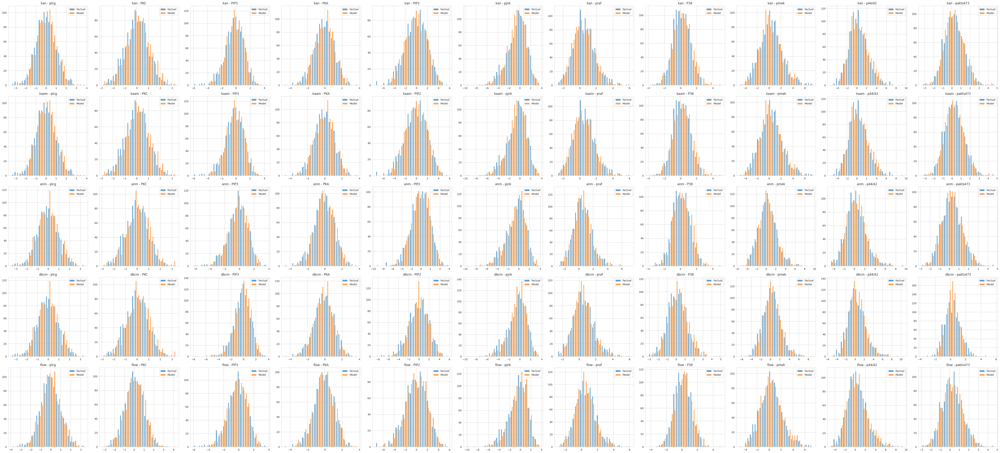

In [5]:
# Show the distributions of observational samples for all models compared to the factual data
nodes = factual_eval.columns
plt.subplots(len(model_names), len(nodes), figsize=(5 * len(nodes), 5 * len(model_names)))
for i, node in enumerate(nodes):
    for j, model_name in enumerate(model_names):
        obs_model = pd.read_csv(os.path.join(samples_dir, f"sachs_obs_samples_{model_name}.csv"))
        plt.subplot(len(model_names), len(nodes), j * len(nodes) + i + 1)
        plt.hist([factual_eval[node], obs_model[node]], bins=30, label=['Factual', 'Model'], alpha=0.7)
        plt.title(f'{model_name} - {node}')
        plt.legend(loc='best')
plt.tight_layout()
plt.show()

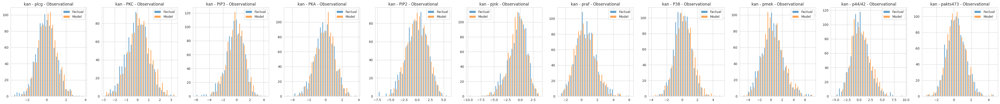

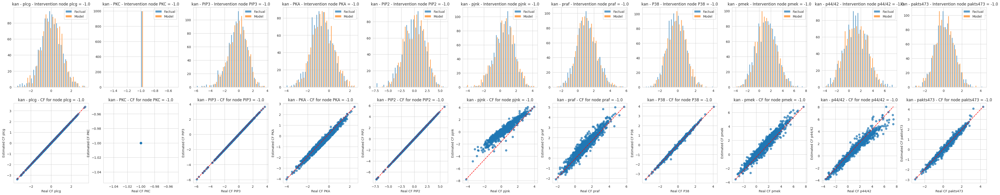

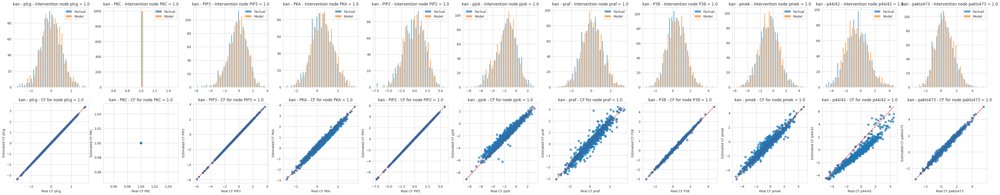

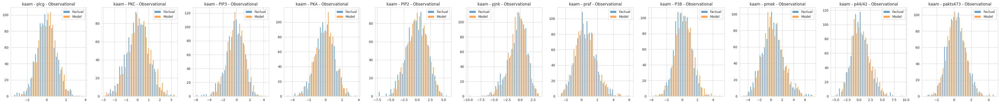

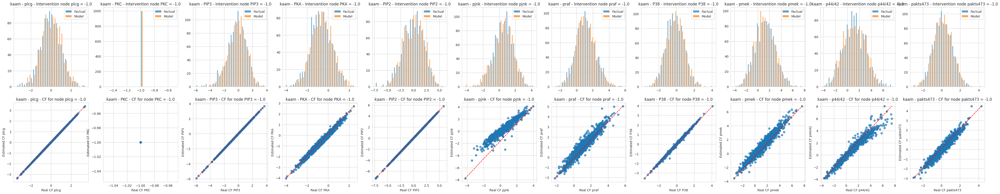

...

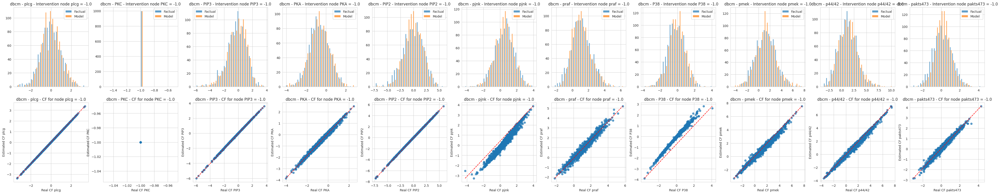

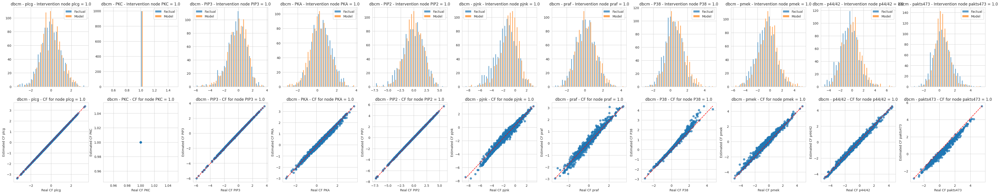

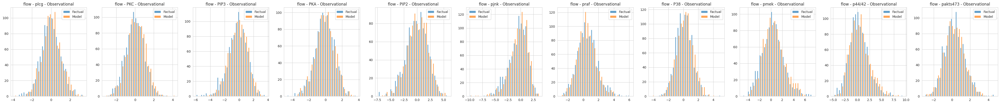

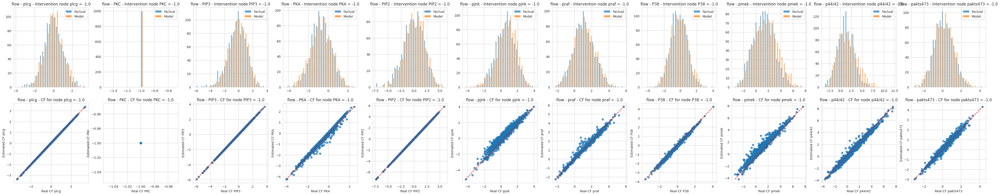

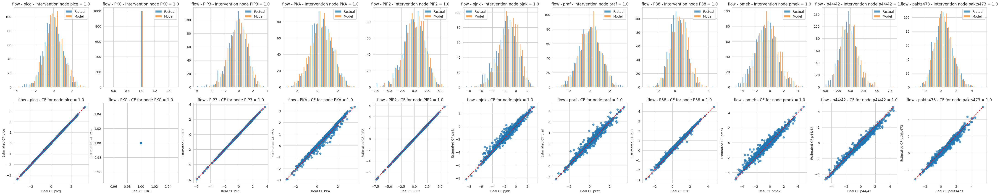

In [6]:
# Put one example of the distributions of observational, interventional and counterfactual samples for one dataset and n, for all models
model_names = ['kan', 'kaam', 'anm', 'dbcm', 'flow']  # Models used for evaluation

interventions = [('PKC', -1.0), ('PKC', 1.0)]

for model_name in model_names:
    obs_model = pd.read_csv(os.path.join(samples_dir, f"sachs_obs_samples_{model_name}.csv"))
    nodes = factual_eval.columns
    plt.subplots(1, len(nodes), figsize=(5 * len(nodes), 5))
    for i, node in enumerate(nodes):
        plt.subplot(1, len(nodes), i + 1)
        plt.hist([factual_eval[node], obs_model[node]], bins=30, label=['Factual', 'Model'], alpha=0.7)
        plt.title(f'{model_name} - {node} - Observational')
        plt.legend(loc='best')

    with open(os.path.join(data_dir, f'sachs_interventional_eval_{model_name}.pkl'), 'rb') as f:
        results_int = pickle.load(f)
    with open(os.path.join(data_dir, f'sachs_cf_eval_{model_name}.pkl'), 'rb') as f:
        results_cf = pickle.load(f)

    for inode, value in interventions:
        # Find in inter_vector the (node, value) pair that matches this
        cf_gt = None
        int_model = None
        cf_model = None
        for node_, value_, d_ in inter_vector:
            if inode == node_ and np.abs(value - value_) < 1e-3:
                cf_gt = d_
        for node_, value_, d_ in results_int:
            if inode == node_ and np.abs(value - value_) < 1e-3:
                int_model = d_
        for node_, value_, d_ in results_cf:
            if inode == node_ and np.abs(value - value_) < 1e-3:
                cf_model = d_

        if model_name == 'flow':
            int_model = int_model.astype(np.float64) # Flow outputs float32, ensure all is float64 to prevent type errors in the histogram of the intervention

        plt.subplots(2, len(nodes), figsize=(5 * len(nodes), 10))
        for i, node in enumerate(nodes):
            plt.subplot(2, len(nodes), i + 1)
            if node == inode and model_name == 'flow':  # To prevent errors in the histogram due to data types, this step is required
                int_model[node] = cf_gt[node]  # Just change the intervention to the right value (minimal differences due to flow being output as float32)
            plt.hist([cf_gt[node], int_model[node]], bins=30, label=['Factual', 'Model'], alpha=0.7)
            plt.title(f'{model_name} - {node} - Intervention node {node} = {value}')
            plt.legend(loc='best')

            plt.subplot(2, len(nodes), i + 1 + len(nodes))
            plt.scatter(cf_gt[node], cf_model[node], alpha=0.7)
            plt.plot([cf_gt[node].min(), cf_gt[node].max()], [cf_model[node].min(), cf_model[node].max()], 'r--')
            plt.xlabel(f'Real CF { node}')
            plt.ylabel(f'Estimated CF { node}')
            plt.title(f'{model_name} - {node} - CF for node {node} = {value}')

    plt.show()


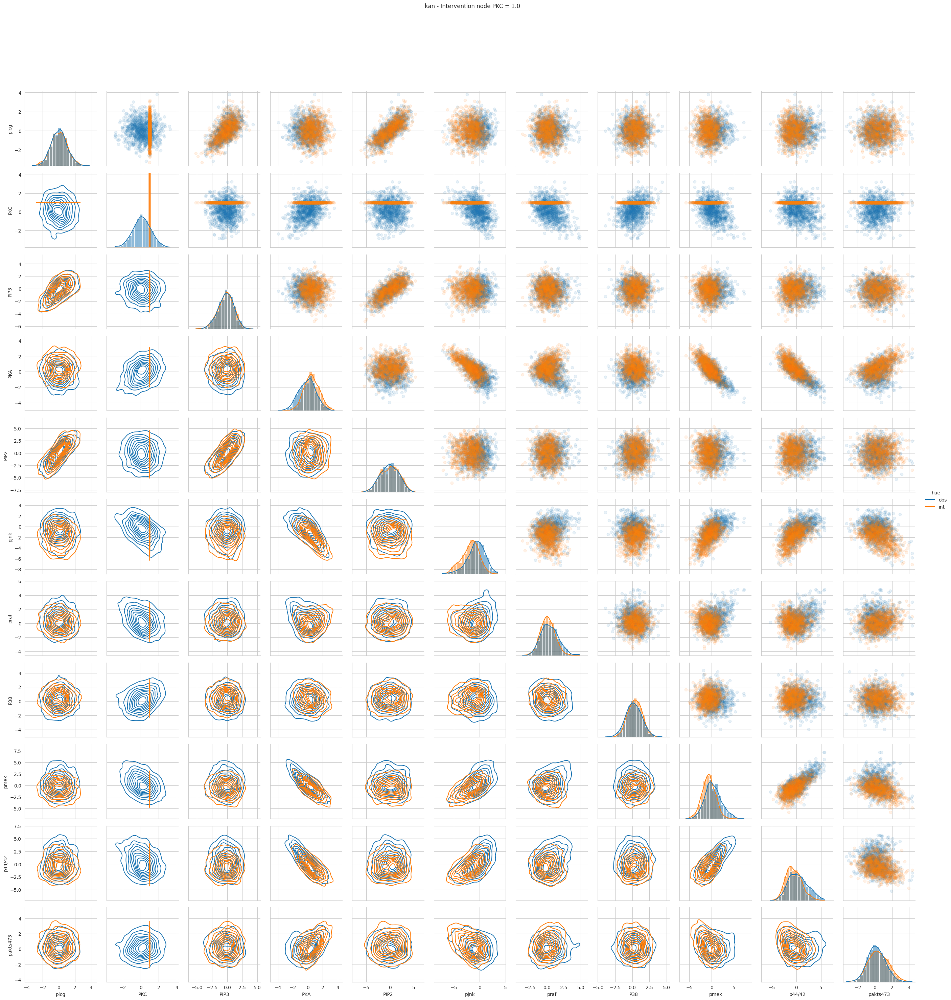

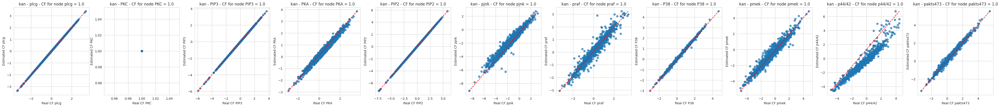

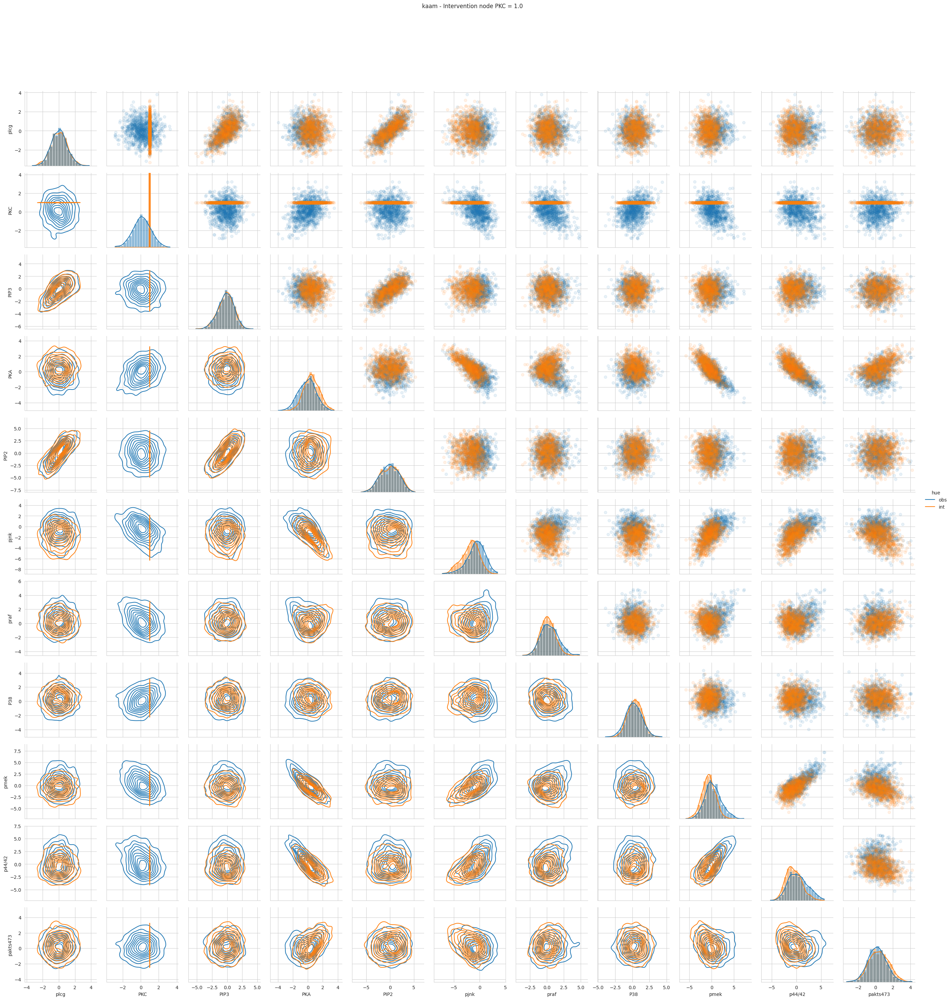

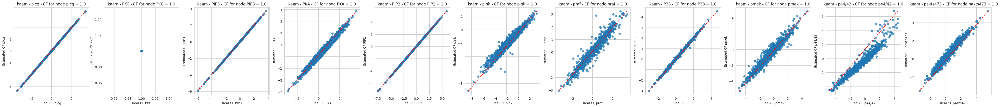

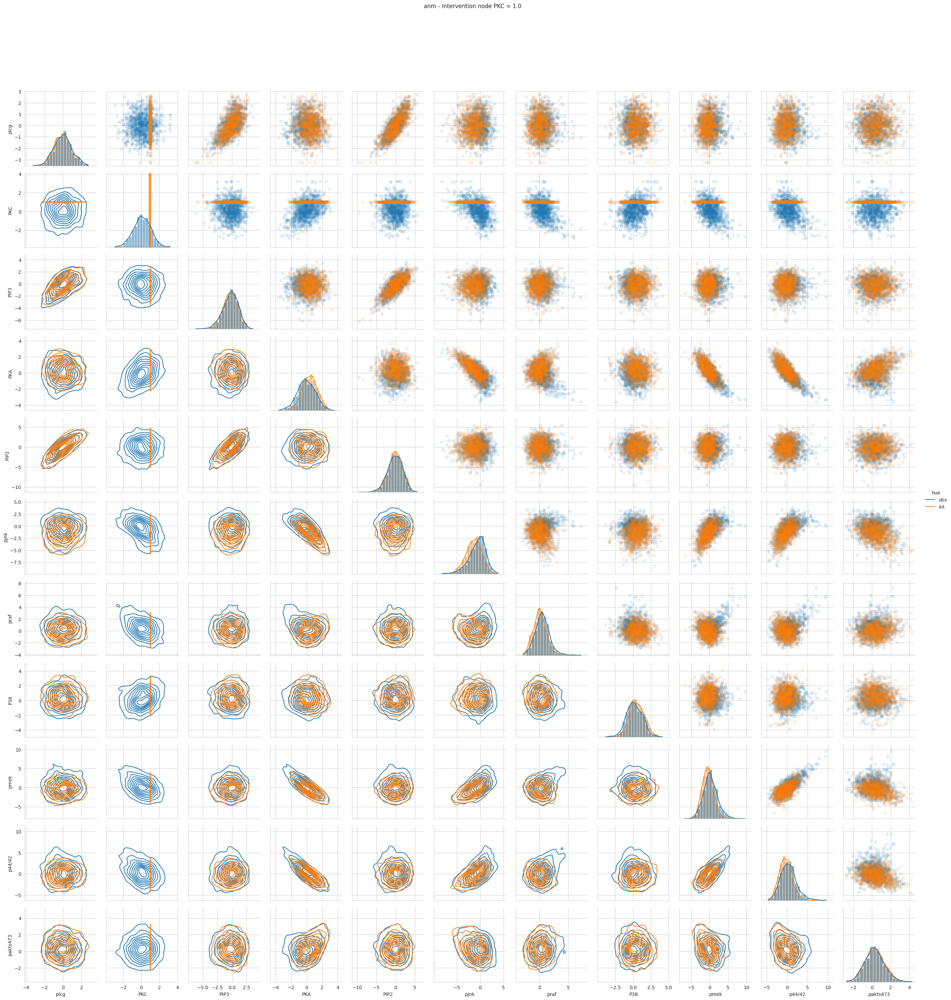

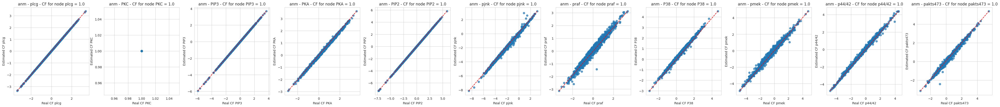

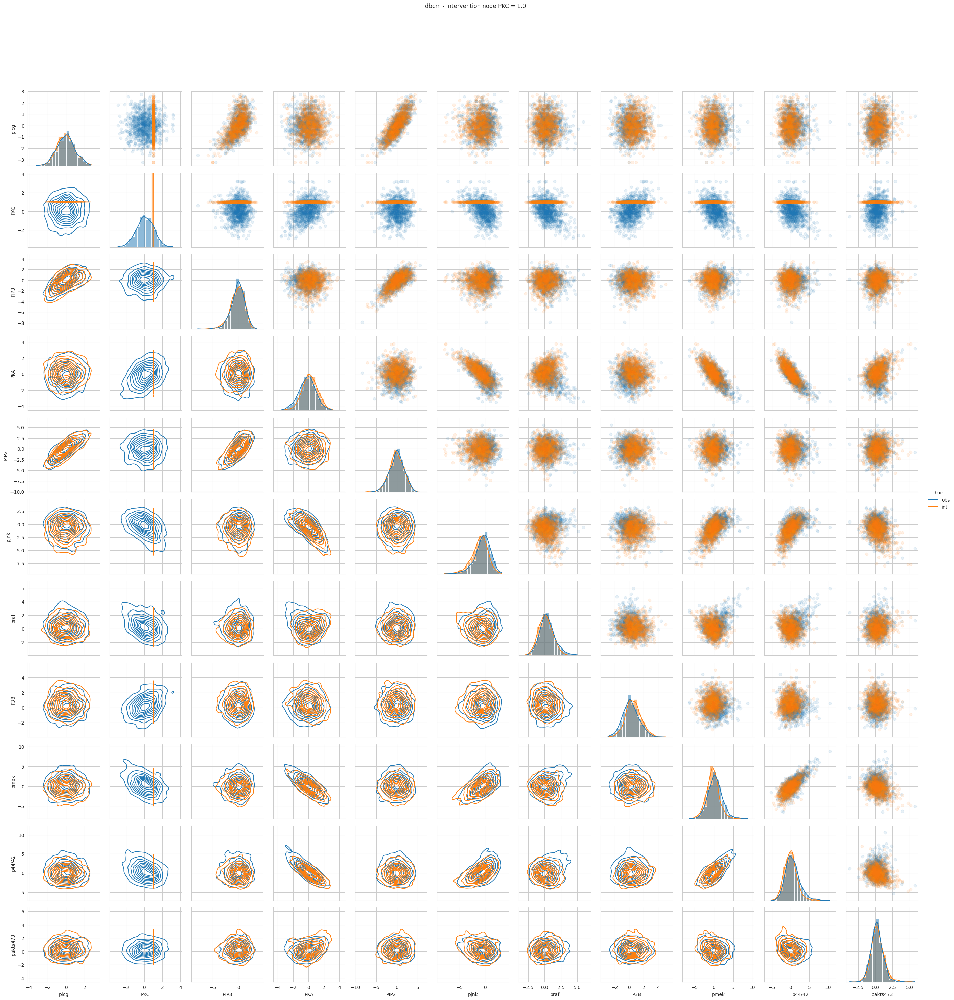

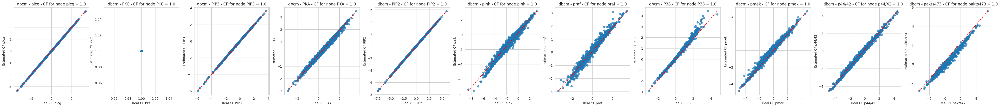

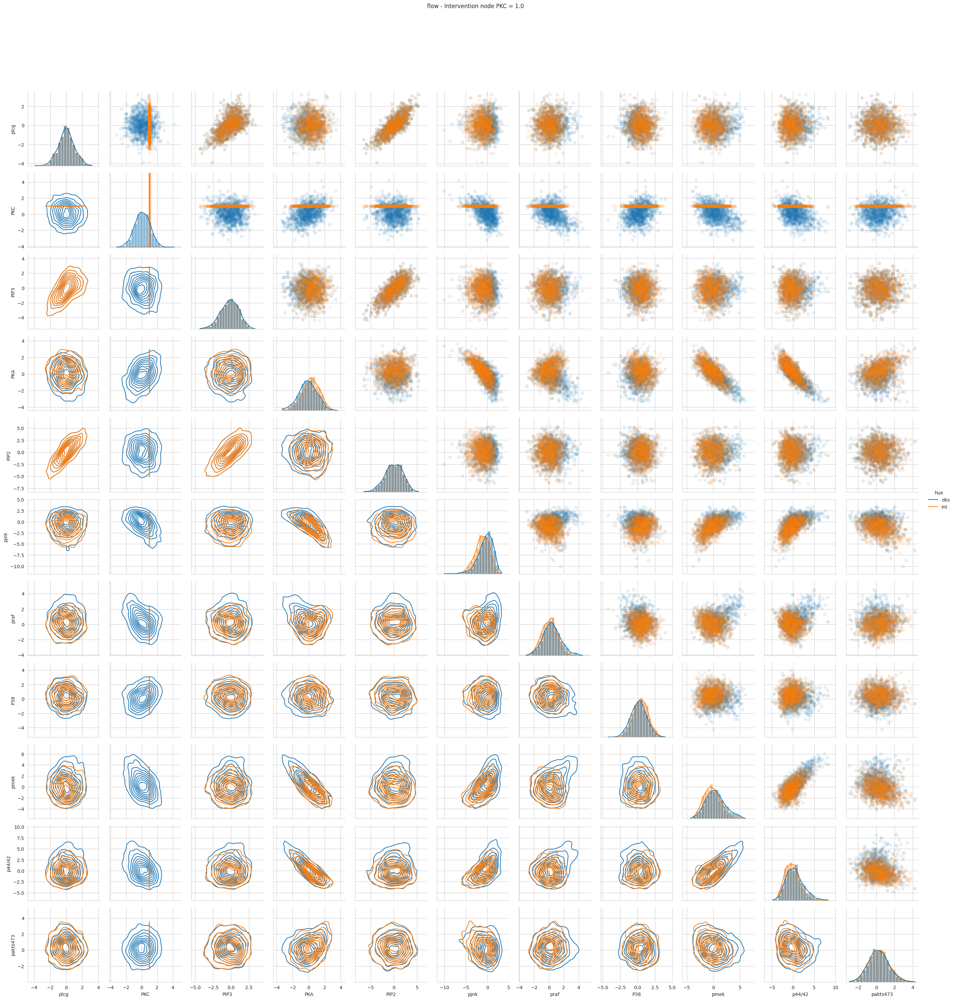

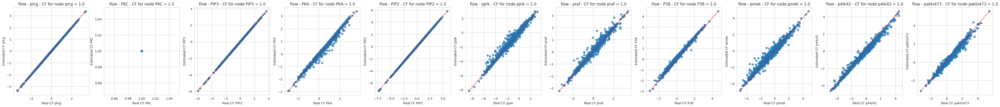

In [7]:
# Put one example of the distributions of observational, interventional and counterfactual samples for one dataset and n, for all models
interventions = [('PKC', 1.0)]
n = len(factual_eval)  # Number of samples used for evaluation
model_names = ['kan', 'kaam', 'anm', 'dbcm', 'flow']  # Models used for evaluation

for model_name in model_names:
    obs_model = pd.read_csv(os.path.join(samples_dir, f"sachs_obs_samples_{model_name}.csv"))
    with open(os.path.join(data_dir, f'sachs_interventional_eval_{model_name}.pkl'), 'rb') as f:
        results_int = pickle.load(f)
    with open(os.path.join(data_dir, f'sachs_cf_eval_{model_name}.pkl'), 'rb') as f:
        results_cf = pickle.load(f)
    nodes = factual_eval.columns

    obs_model['hue'] = 'obs'

    for node, value in interventions:
        # Find in inter_vector the (node, value) pair that matches this
        cf_gt = None
        int_model = None
        cf_model = None
        for node_, value_, d_ in inter_vector:
            if node == node_ and np.abs(value - value_) < 1e-3:
                cf_gt = d_
        for node_, value_, d_ in results_int:
            if node == node_ and np.abs(value - value_) < 1e-3:
                int_model = d_
        for node_, value_, d_ in results_cf:
            if node == node_ and np.abs(value - value_) < 1e-3:
                cf_model = d_

        int_model['hue'] = f'int'
        # Add a little noise to the intervened variables, done to prevent errors in KDE
        int_model[node] += 0.01 * np.random.randn(len(int_model))
        data = pd.concat([obs_model, int_model], ignore_index=True)

        g = sns.PairGrid(data, hue='hue')
        g.map_upper(plt.scatter, alpha=0.1)
        g.map_lower(sns.kdeplot, common_norm=False)
        g.map_diag(sns.histplot, kde=True, stat='proportion', common_norm=False, bins=20)
        _ = g.add_legend()

        for i in range(len(nodes)):
            g.diag_axes[i].set_ylim((0, 0.3)) # NOTE: carefully adjust this to obtain meaningful plots, i.e., the intervention, being discrete, causes a mess

        g.figure.suptitle(f'{model_name} - Intervention node {node} = {value}', y=1.08)
        plt.show()

        plt.subplots(1, len(nodes), figsize=(5 * len(nodes), 5))
        for i, node in enumerate(nodes):
            plt.subplot(1, len(nodes), i + 1)
            plt.scatter(cf_gt[node], cf_model[node], alpha=0.7)
            plt.plot([cf_gt[node].min(), cf_gt[node].max()], [cf_model[node].min(), cf_model[node].max()], 'r--')
            plt.xlabel(f'Real CF { node}')
            plt.ylabel(f'Estimated CF { node}')
            plt.title(f'{model_name} - {node} - CF for node {node} = {value}')
        plt.show()



Extracted formula for node plcg using KAAM model: N/A
Extracted formula for node PKC using KAAM model: N/A
Extracted formula for node PIP3 using KAAM model: -0.1569*plcg**2 + 0.8034*plcg - 0.0886


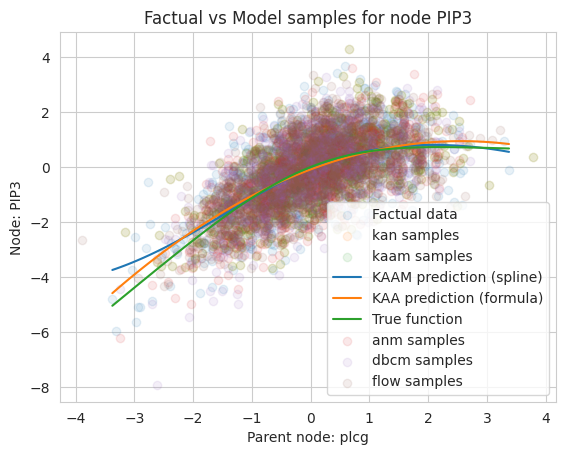

Extracted formula for node PKA using KAAM model: -0.0041*PKC**4 - 0.0021*PKC**3 - 0.0724*PKC**2 + 0.4636*PKC - 0.0393


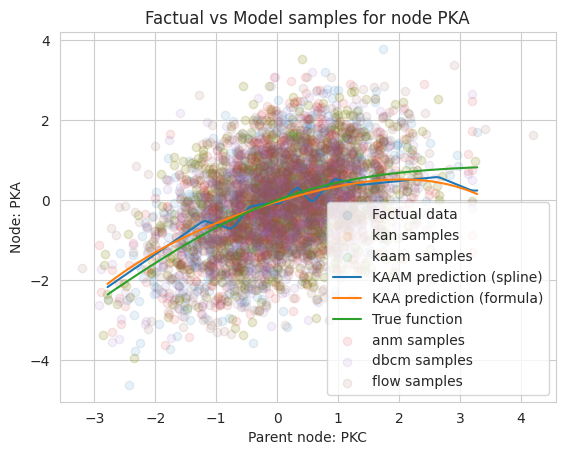

Extracted formula for node PIP2 using KAAM model: 0.5887*PIP3 - 0.0861*plcg**3 + 0.0737*plcg**2 + 1.2296*plcg + 0.0358
Extracted formula for node pjnk using KAAM model: -0.2159*PKA**2 - 0.9784*PKA + 0.0265*PKC**4 + 0.0207*PKC**3 - 0.2436*PKC**2 - 0.5401*PKC - 0.169
Extracted formula for node praf using KAAM model: -0.0109*PKA**4 - 0.0065*PKA**3 + 0.3305*PKA**2 - 0.1047*PKA + 0.1465*PKC**2 - 0.4128*PKC - 0.0247
Extracted formula for node P38 using KAAM model: -0.1057*PKA + 0.1217*PKC**2 + 0.3351*PKC - 0.0004
Extracted formula for node pmek using KAAM model: -1.1942*PKA - 0.0114*PKC**4 - 0.0061*PKC**3 + 0.0565*PKC**2 - 0.1998*PKC + 0.0023*praf**4 - 0.013*praf**3 + 0.0497*praf**2 + 0.024*praf + 0.1606
Extracted formula for node p44/42 using KAAM model: -0.8781*PKA - 0.0106*pmek**3 + 0.0864*pmek**2 + 0.3557*pmek - 0.0464
Extracted formula for node pakts473 using KAAM model: 0.0001*p44/42**4 + 0.0006*p44/42**3 + 0.0041*p44/42**2 + 0.0081*p44/42 + Piecewise((-0.1609*PKA - 0.5978, PKA < -0.12

In [8]:
model_names = ['kan', 'kaam', 'anm', 'dbcm', 'flow']

results_file = os.path.join(data_dir, f"sachs_results_kaam.pkl")
with open(results_file, 'rb') as f:
    results = pickle.load(f)

# Go node per node and show how they fit the data and extract the KAAM formulas

for node in factual_eval.columns:
    print(f'Extracted formula for node {node} using KAAM model: {results.get(f"kaam_formula_{node}", "N/A")}')
    if graph_sachs.in_degree(node) == 1:  # Single parent nodes are the ones we are visualizing
        parent_node = list(graph_sachs.predecessors(node))[0]
        plt.scatter(factual_eval[parent_node], factual_eval[node], label='Factual data', alpha=0.1)
        for model_name in model_names:
            # Get observational samples for the model
            obs_model = pd.read_csv(os.path.join(samples_dir, f"sachs_obs_samples_{model_name}.csv"))
            plt.scatter(obs_model[parent_node], obs_model[node], label=f'{model_name} samples', alpha=0.1)
            if model_name == 'kaam': # Additional info provided by the kaam
                plt.plot(results[f'x_vals_{node}'], results[f'kaam_pred_{node}'], label=f'KAAM prediction (spline)')
                plt.plot(results[f'x_vals_{node}'], results[f'formula_pred_{node}'], label=f'KAAM prediction (formula)')
                plt.plot(results[f'x_vals_{node}'], structural_eq[node](np.zeros((len(results[f'x_vals_{node}']), 1)), results[f'x_vals_{node}'].reshape(-1, 1)), label='True function')
        plt.xlabel(f'Parent node: {parent_node}')
        plt.ylabel(f'Node: {node}')
        plt.title(f'Factual vs Model samples for node {node}')
        plt.legend()
        plt.show()

print(f'MAE results for KAAM formulas on SACHS dataset:')
for node in factual_eval.columns:
    print(f'Node: {node}, MAE: {results.get(f"mae_{node}", "N/A")}')
print(f'Global MAE: {results.get("mae", "N/A")}')


 Parents of child node PIP3: {'plcg'}; we will compute interventions on plcg.
Full formula for Estimated Treatmen Effect of node PIP3 using KAAM model: -0.1569*plcg**2 + 0.8034*plcg - 0.0886
ATE formula estimated for child node PIP3 using KAAM model when intervening on node plcg with values (-1.0, 1.0): 1.60679626464844


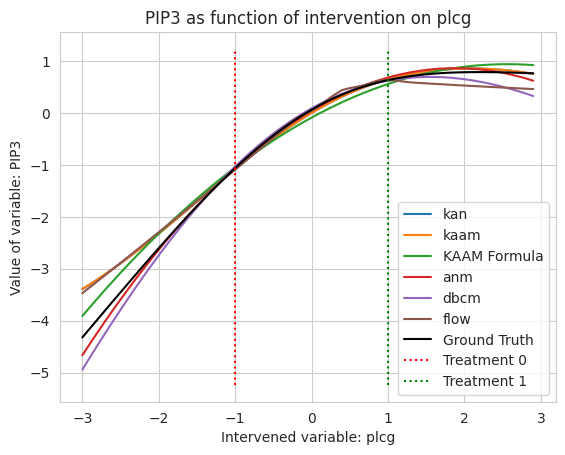

 Parents of child node PKA: {'PKC'}; we will compute interventions on PKC.
Full formula for Estimated Treatmen Effect of node PKA using KAAM model: -0.0041*PKC**4 - 0.0021*PKC**3 - 0.0724*PKC**2 + 0.4636*PKC - 0.0393
ATE formula estimated for child node PKA using KAAM model when intervening on node PKC with values (-1.0, 1.0): 0.922996520996094


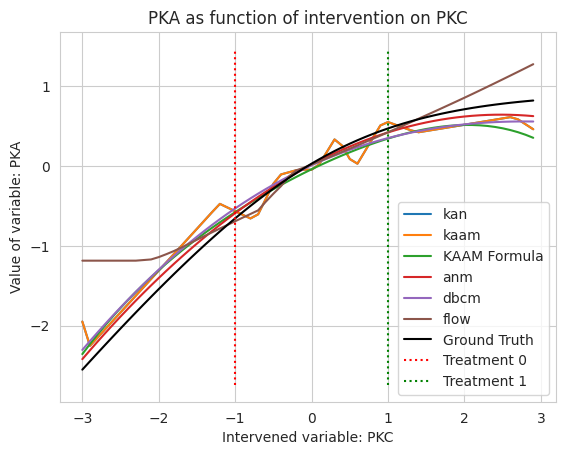

 Parents of child node PIP2: {'plcg', 'PIP3'}; we will compute interventions on plcg.
Full formula for Estimated Treatmen Effect of node PIP2 using KAAM model: 0.5887*PIP3 - 0.0861*plcg**3 + 0.0737*plcg**2 + 1.2296*plcg + 0.0358
ATE formula estimated for child node PIP2 using KAAM model when intervening on node plcg with values (-1.0, 1.0): 2.28699111938477


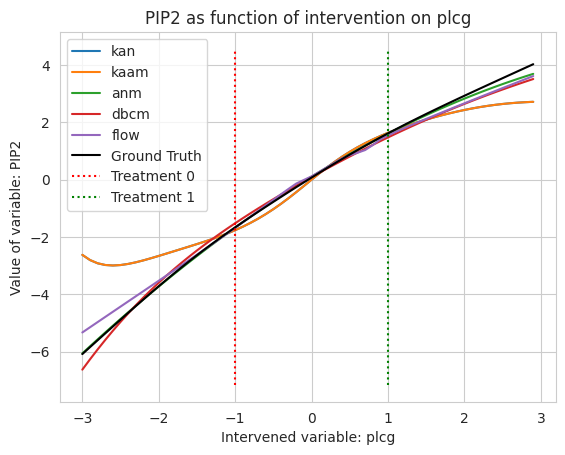

 Parents of child node pjnk: {'PKA', 'PKC'}; we will compute interventions on PKA.
Full formula for Estimated Treatmen Effect of node pjnk using KAAM model: -0.2159*PKA**2 - 0.9784*PKA + 0.0265*PKC**4 + 0.0207*PKC**3 - 0.2436*PKC**2 - 0.5401*PKC - 0.169
ATE formula estimated for child node pjnk using KAAM model when intervening on node PKA with values (-1.0, 1.0): -1.95680236816406


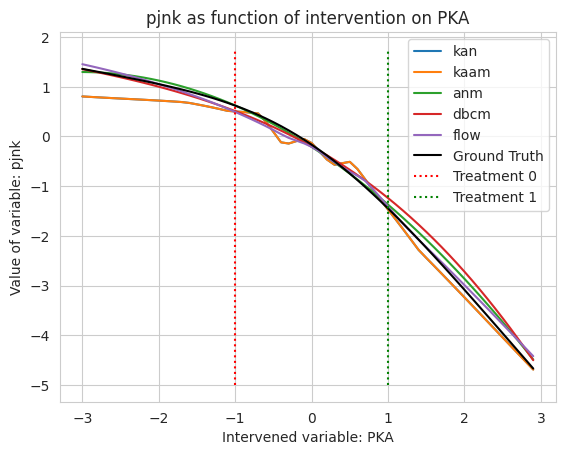

 Parents of child node praf: {'PKA', 'PKC'}; we will compute interventions on PKA.
Full formula for Estimated Treatmen Effect of node praf using KAAM model: -0.0109*PKA**4 - 0.0065*PKA**3 + 0.3305*PKA**2 - 0.1047*PKA + 0.1465*PKC**2 - 0.4128*PKC - 0.0247
ATE formula estimated for child node praf using KAAM model when intervening on node PKA with values (-1.0, 1.0): -0.222400665283203


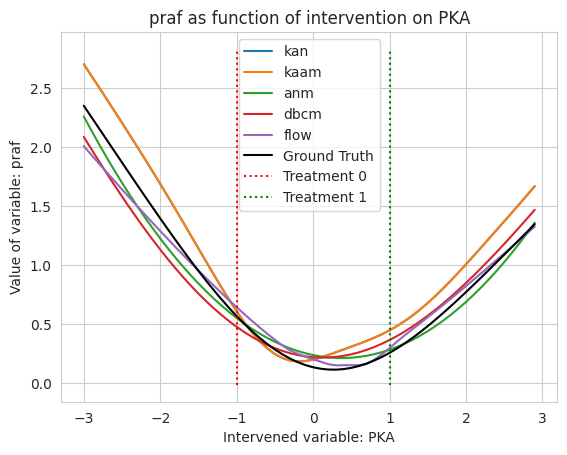

 Parents of child node P38: {'PKA', 'PKC'}; we will compute interventions on PKA.
Full formula for Estimated Treatmen Effect of node P38 using KAAM model: -0.1057*PKA + 0.1217*PKC**2 + 0.3351*PKC - 0.0004
ATE formula estimated for child node P38 using KAAM model when intervening on node PKA with values (-1.0, 1.0): -0.211399078369141


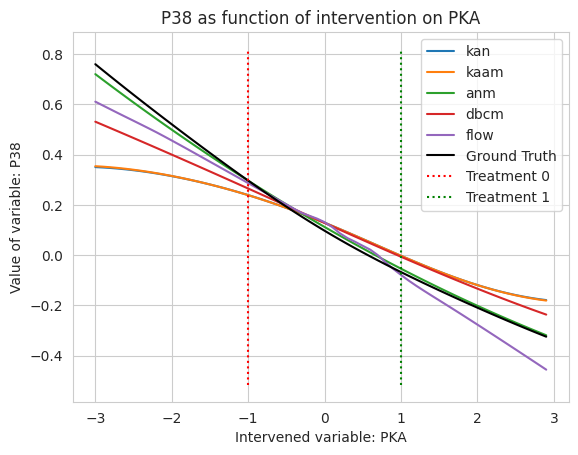

 Parents of child node pmek: {'PKA', 'PKC', 'praf'}; we will compute interventions on PKA.
Full formula for Estimated Treatmen Effect of node pmek using KAAM model: -1.1942*PKA - 0.0114*PKC**4 - 0.0061*PKC**3 + 0.0565*PKC**2 - 0.1998*PKC + 0.0023*praf**4 - 0.013*praf**3 + 0.0497*praf**2 + 0.024*praf + 0.1606
ATE formula estimated for child node pmek using KAAM model when intervening on node PKA with values (-1.0, 1.0): -2.38840103149414


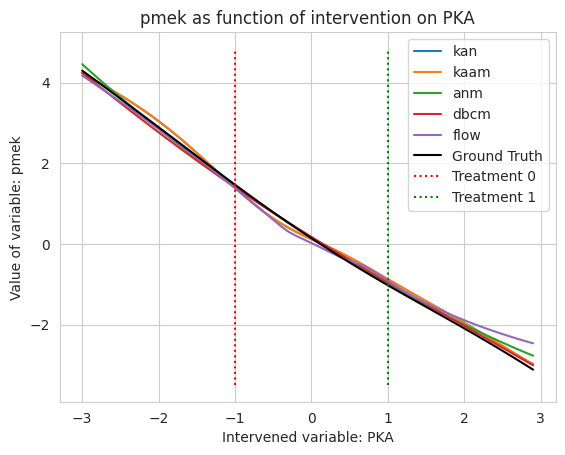

 Parents of child node p44/42: {'PKA', 'PKC', 'pmek', 'praf'}; we will compute interventions on PKA.
Full formula for Estimated Treatmen Effect of node p44/42 using KAAM model: -0.8781*PKA - 0.0106*pmek**3 + 0.0864*pmek**2 + 0.3557*pmek - 0.0464
ATE formula estimated for child node p44/42 using KAAM model when intervening on node PKA with values (-1.0, 1.0): -1.75619506835938


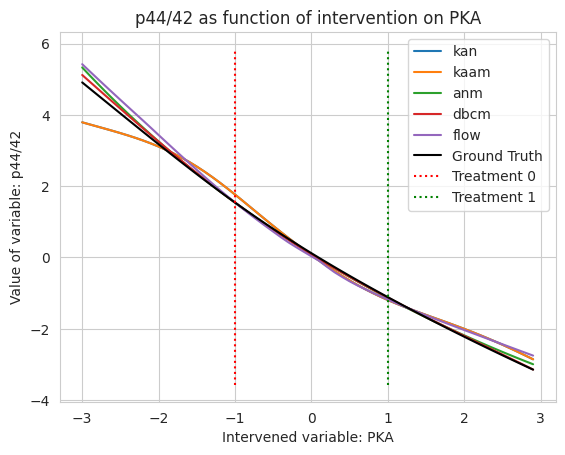

 Parents of child node pakts473: {'PKC', 'p44/42', 'pmek', 'PKA', 'praf'}; we will compute interventions on PKC.
Full formula for Estimated Treatmen Effect of node pakts473 using KAAM model: 0.0001*p44/42**4 + 0.0006*p44/42**3 + 0.0041*p44/42**2 + 0.0081*p44/42 + Piecewise((-0.1609*PKA - 0.5978, PKA < -0.1249), (0.8028*PKA - 0.4775, True)) + 0.3571
ATE formula estimated for child node pakts473 using KAAM model when intervening on node PKC with values (-1.0, 1.0): 0


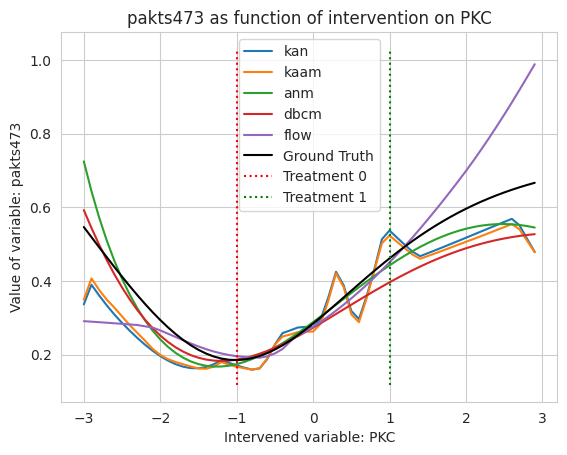

╒═══════════════╤══════════════╤══════════════╤════════════════════╤═════════════╤═════════════╤═════════════════╕
│ Parent node   │ Child node   │ Model        │   ATE Ground Truth │   ATE Model │   Abs Error │   Rel Error (%) │
╞═══════════════╪══════════════╪══════════════╪════════════════════╪═════════════╪═════════════╪═════════════════╡
│ plcg          │ PIP3         │ kan          │             1.6939 │      1.7250 │      0.0311 │          1.8360 │
├───────────────┼──────────────┼──────────────┼────────────────────┼─────────────┼─────────────┼─────────────────┤
│ plcg          │ PIP3         │ kaam         │             1.6939 │      1.7251 │      0.0312 │          1.8426 │
├───────────────┼──────────────┼──────────────┼────────────────────┼─────────────┼─────────────┼─────────────────┤
│ plcg          │ PIP3         │ KAAM formula │             1.6939 │      1.6068 │      0.0871 │          5.1436 │
├───────────────┼──────────────┼──────────────┼────────────────────┼────────────

In [8]:
# ATE example on a single variable: formula vs ground truth vs each model
# First, we obtain the nodes that are descendents of the intervened node
intervention_values = (-1.0, 1.0)  # intervention value 0, intervention value 1 (we'll compute this for all nodes with <= 2 parents)
model_names = ['kan', 'kaam', 'anm', 'dbcm', 'flow']

results_file = os.path.join(data_dir, f"sachs_results_kaam.pkl")  # KAAM results file to extract formulas
with open(results_file, 'rb') as f:
    results_kaam = pickle.load(f)

ate_table = []

for child_node in factual_eval.columns:
    n_parents = graph_sachs.in_degree(child_node)
    if n_parents > 0:  # Only when there exists at least a parent!
        parent_nodes = nx.ancestors(graph_sachs, child_node)
        parent_node = f'{list(parent_nodes)[0]}'  # We will only plot results intervening on the first parent to show the potential of using KAAMs
        print(f' Parents of child node {child_node}: {parent_nodes}; we will compute interventions on {parent_node}.')
        parent_cf_values = {'kaam_formula': None, 'kaam_ate_formula': None, parent_node: {}}
        parent_cf_values[parent_node] = {'cf_gt_0': None, 'cf_gt_1': None, 'gt_ate': None}
        for node_, value_, d_ in inter_vector:
            if parent_node == node_:
                if np.abs(value_ - intervention_values[0]) < 1e-3:
                    parent_cf_values[parent_node]['cf_gt_0'] = d_[child_node]
                if np.abs(value_ - intervention_values[1]) < 1e-3:
                    parent_cf_values[parent_node]['cf_gt_1'] = d_[child_node]
        parent_cf_values[parent_node]['gt_ate'] = np.mean(parent_cf_values[parent_node]['cf_gt_1'].to_numpy()) - np.mean(parent_cf_values[parent_node]['cf_gt_0'].to_numpy())

        for model_name in model_names:
            with open(os.path.join(data_dir, f'sachs_cf_eval_{model_name}.pkl'), 'rb') as f:
                results_cf = pickle.load(f)
            for node_, value_, d_ in results_cf:
                if parent_node == node_:
                    if np.abs(value_ - intervention_values[0]) < 1e-3:
                        parent_cf_values[parent_node][f'cf_{model_name}_0'] = d_[child_node]
                    if np.abs(value_ - intervention_values[1]) < 1e-3:
                        parent_cf_values[parent_node][f'cf_{model_name}_1'] = d_[child_node]
            parent_cf_values[parent_node][f'{model_name}_ate'] = np.mean(parent_cf_values[parent_node][f'cf_{model_name}_1'].to_numpy()) -  np.mean(parent_cf_values[parent_node][f'cf_{model_name}_0'].to_numpy())
            abs_ate_error = np.abs(parent_cf_values[parent_node]['gt_ate'] - parent_cf_values[parent_node][f'{model_name}_ate'])
            rel_ate_erro = 100 * abs_ate_error / np.abs(parent_cf_values[parent_node]['gt_ate'])
            ate_table.append([parent_node, child_node, model_name, parent_cf_values[parent_node]['gt_ate'], parent_cf_values[parent_node][f'{model_name}_ate'], abs_ate_error, rel_ate_erro])

            if model_name == 'kaam':
                # Now, create a symbolic function using the formulas extracted by KAAM
                child_node_formula = results_kaam.get(f'kaam_formula_{child_node}', None)
                if child_node_formula is None:
                    print(f'No formula for node {child_node} in KAAM model')
                else:
                    parent_cf_values['kaam_formula'] = child_node_formula
                    kaam_ate_formula = child_node_formula.subs(parent_node, intervention_values[1]) - child_node_formula.subs(parent_node, intervention_values[0])  # Note that we intervene always only on the first parent!
                    parent_cf_values['kaam_ate_formula'] = kaam_ate_formula
                    print(f'Full formula for Estimated Treatmen Effect of node {child_node} using KAAM model: {child_node_formula}')
                    print(f'ATE formula estimated for child node {child_node} using KAAM model when intervening on node {parent_node} with values {intervention_values}: {kaam_ate_formula}')
                    ate_formula_kaam = float(kaam_ate_formula)
                    abs_ate_error = np.abs(parent_cf_values[parent_node]['gt_ate'] - ate_formula_kaam)
                    rel_ate_erro = 100 * abs_ate_error / np.abs(parent_cf_values[parent_node]['gt_ate'])
                    ate_table.append([parent_node, child_node, 'KAAM formula', parent_cf_values[parent_node]['gt_ate'], ate_formula_kaam, abs_ate_error, rel_ate_erro])

            # Now, plot the expected effect formula
            cf_vals_ordered = []
            for value_o in list(cf_vector_values):
                for node_, value_, d_ in results_cf:
                    if parent_node == node_ and np.abs(value_ - value_o) < 1e-3:
                        cf_vals_ordered.append(np.mean(d_[child_node].to_numpy()))
            plt.plot(cf_vector_values, cf_vals_ordered, label=model_name)

            if model_name == 'kaam' and n_parents == 1:  # We can only plot this for single parent KAAMs
                kaam_cf_vals = []
                for x in list(cf_vector_values):
                    int_val_kaam = parent_cf_values['kaam_formula'].subs(parent_node, x)
                    kaam_cf_vals.append(float(int_val_kaam))
                plt.plot(cf_vector_values, kaam_cf_vals, label='KAAM Formula')

        # Now, let's obtain the ATE plot using the structural equations (ground truth), as a function of the intervened variable
        if child_node in structural_eq:
            cf_gt_vals = []
            cf_gt_vals_std = []
            for value_o in list(cf_vector_values):
                for node_, value_, d_ in inter_vector:
                    if parent_node == node_ and np.abs(value_ - value_o) < 1e-3:
                        cf_gt_vals.append(np.mean(d_[child_node].to_numpy()))
                        cf_gt_vals_std.append(np.std(d_[child_node].to_numpy()))
            cf_gt_vals = np.array(cf_gt_vals)
            cf_gt_vals_std = np.array(cf_gt_vals_std)
            #plt.fill_between(cf_vector_values, cf_gt_vals + 2 * cf_gt_vals_std, cf_gt_vals - 2 * cf_gt_vals_std, alpha=0.1, color='black')
            plt.plot(cf_vector_values, cf_gt_vals, label='Ground Truth', color='black')
            y_min, y_max = plt.ylim()
            plt.vlines(intervention_values[0], ymin=y_min, ymax=y_max, color='red', linestyle=':',
                       label=f'Treatment 0')
            plt.vlines(intervention_values[1], ymin=y_min, ymax=y_max, color='green', linestyle=':',
                       label=f'Treatment 1')
            plt.xlabel(f'Intervened variable: {parent_node}')
            plt.ylabel(f'Value of variable: {child_node}')
            plt.title(f'{child_node} as function of intervention on {parent_node}')
            plt.legend()
            plt.show()

print(tabulate(ate_table,
               headers=['Parent node', 'Child node', 'Model', 'ATE Ground Truth', 'ATE Model', 'Abs Error', 'Rel Error (%)'],
               floatfmt=".4f", tablefmt="fancy_grid"))

# Create an average ATE table, for each model compute the avg and std of the ATE error
ate_table_avg = []
for model_name in model_names + ['KAAM formula']:
    values_to_avg = []
    for row in ate_table:
        if row[2] == model_name:
            values_to_avg.append(row[5:])
    values_to_avg = np.array(values_to_avg)
    mean = np.mean(values_to_avg, axis=0)
    std = np.std(values_to_avg, axis=0)
    ate_table_avg.append([model_name] + [f'{mean[i]:.2f} ({std[i]:.2f})' for i in range(len(mean))])

print(tabulate(ate_table_avg, headers=['Model name', 'Abs error', 'Rel error (%)'], floatfmt=".4f", tablefmt="latex"))

pydev debugger: bytes arguments were passed to a new process creation function. Breakpoints may not work correctly.

Traceback (most recent call last):
  File "/home/juan/.pycharm_helpers/pydev/_pydev_bundle/pydev_monkey.py", line 261, in patch_args
    SetupHolder.setup['module'] = False  # clean module param from parent process
    ~~~~~~~~~~~~~~~~~^^^^^^^^^^
TypeError: 'NoneType' object does not support item assignment
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Computing ATE over the node plcg
Finished the ATE computation over the node plcg
Computing ATE over the node PKC
Finished the ATE computation over the node PKC


No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Computing ATE over the node PIP3
Computing ATE over the node PKA


No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Computing ATE over the node PIP2


No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Computing ATE over the node pjnk


No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Computing ATE over the node praf


No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.
No GPU automatically detected. Setting SETTINGS.GPU to 0, and SETTINGS.NJOBS to cpu_count.


Computing ATE over the node P38
Computing ATE over the node pmek
Computing ATE over the node p44/42
Computing ATE over the node pakts473
Finished the ATE computation over the node PKA
Finished the ATE computation over the node PIP3
Finished the ATE computation over the node PIP2
Finished the ATE computation over the node pjnk
Finished the ATE computation over the node praf
Finished the ATE computation over the node P38
Finished the ATE computation over the node p44/42
Finished the ATE computation over the node pmek
Finished the ATE computation over the node pakts473


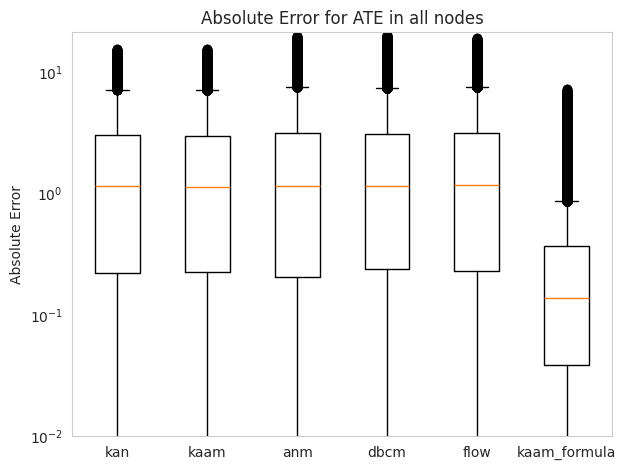

In [9]:
# ATE metrics evaluated on a grid for all possible interventions
model_names = ['kan', 'kaam', 'anm', 'dbcm', 'flow']

results_file = os.path.join(data_dir, f"sachs_results_kaam.pkl") # KAAM results file to extract formulas
with open(results_file, 'rb') as f:
    results_kaam = pickle.load(f)

ate_results_evaluation = {}

def compute_ate_per_int_node(child_node):
    print(f'Computing ATE over the node {child_node}')
    parent_nodes = nx.ancestors(graph_sachs, child_node)
    ate_vals = {}
    for parent_node in parent_nodes:
        ate_vals[parent_node] = {}
        for model_name in model_names + ['ground_truth', 'kaam_formula']:
            ate_vals[parent_node][model_name] = {}
            if model_name == 'kaam_formula':
                child_node_formula = results_kaam.get(f'kaam_formula_{child_node}', None)
                if child_node_formula is None:
                    print(f'No formula for node {child_node}')

            if model_name in model_names:
                with open(os.path.join(data_dir, f'sachs_cf_eval_{model_name}.pkl'), 'rb') as f:
                    results_cf = pickle.load(f)

            for value0 in list(cf_vector_values):
                ate_vals[parent_node][model_name][value0] = {}
                for value1 in list(cf_vector_values):
                    ate_vals[parent_node][model_name][value0][value1] = {}
                    if model_name == 'ground_truth':
                        cf_gt_0 = None
                        cf_gt_1 = None
                        for node_, value_, d_ in inter_vector:
                            if parent_node == node_:
                                if np.abs(value_ - value0) < 1e-3:
                                    cf_gt_0 = np.mean(d_[child_node].to_numpy())
                                if np.abs(value_ - value1) < 1e-3:
                                    cf_gt_1 = np.mean(d_[child_node].to_numpy())
                        ate_vals[parent_node][model_name][value0][value1] = cf_gt_1 - cf_gt_0
                    elif model_name == 'kaam_formula':
                        if child_node_formula is None:
                            ate = None
                        else:
                            ate = float(child_node_formula.subs(parent_node, value1) - child_node_formula.subs(parent_node, value0)) # Note that ATEs can always be obtained regardless of the number of parents due to the model being additive!
                        ate_vals[parent_node][model_name][value0][value1] = ate
                    else:
                        cf_model_0 = None
                        cf_model_1 = None
                        for node_, value_, d_ in results_cf:
                            if parent_node == node_:
                                if np.abs(value_ - value0) < 1e-3:
                                    cf_model_0 = np.mean(d_[child_node].to_numpy())
                                else:
                                    cf_model_1 = np.mean(d_[child_node].to_numpy())
                        ate_vals[parent_node][model_name][value0][value1] = cf_model_0 - cf_model_1
    print(f'Finished the ATE computation over the node {child_node}')
    return child_node, ate_vals

out = Parallel(n_jobs=20)(delayed(compute_ate_per_int_node)(child_node) for child_node in factual_eval.columns)

ate_results_evaluation = {}
for child_node, ate_node in out:
    ate_results_evaluation[child_node] = ate_node

ate_errors = []
for model_name in model_names + ['kaam_formula']:
    error = []
    for child_node in factual_eval.columns:
        for parent_node in ate_results_evaluation[child_node].keys():
            for value0 in list(cf_vector_values):
                for value1 in list(cf_vector_values):
                    ate_gt = ate_results_evaluation[child_node][parent_node]['ground_truth'][value0][value1]
                    ate_model = ate_results_evaluation[child_node][parent_node][model_name][value0][value1]
                    error.append(np.abs(ate_gt - ate_model))
    ate_errors.append(error)


plt.boxplot(ate_errors)
plt.xticks(np.arange(1, len(model_names) + 2), model_names + ['kaam_formula'])
plt.ylabel('Absolute Error')
plt.title('Absolute Error for ATE in all nodes')
plt.ylim(bottom=1e-2)
plt.yscale('log')
plt.grid()
plt.tight_layout()
plt.show()

No formula for noce None with formula
No formula for noce None with formula


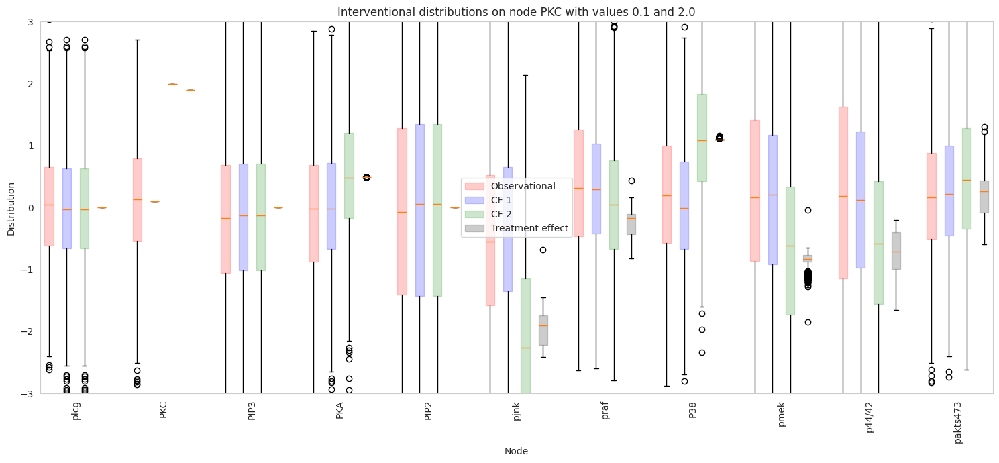

List of children nodes of PKC: ['P38', 'praf', 'pakts473', 'p44/42', 'pjnk', 'pmek', 'PKA']
Formula for child node P38: -0.1057*PKA + 0.1217*PKC**2 + 0.3351*PKC - 0.0004
KAAM ATE by formula on node P38 when PKC takes values 0.1 and 2.0: 1.12227085113525
Formula for child node praf: -0.0109*PKA**4 - 0.0065*PKA**3 + 0.3305*PKA**2 - 0.1047*PKA + 0.1465*PKC**2 - 0.4128*PKC - 0.0247
KAAM ATE by formula on node praf when PKC takes values 0.1 and 2.0: -0.199786148071289
Formula for child node pakts473: 0.0001*p44/42**4 + 0.0006*p44/42**3 + 0.0041*p44/42**2 + 0.0081*p44/42 + Piecewise((-0.1609*PKA - 0.5978, PKA < -0.1249), (0.8028*PKA - 0.4775, True)) + 0.3571
KAAM ATE by formula on node pakts473 when PKC takes values 0.1 and 2.0: 0
Formula for child node p44/42: -0.8781*PKA - 0.0106*pmek**3 + 0.0864*pmek**2 + 0.3557*pmek - 0.0464
KAAM ATE by formula on node p44/42 when PKC takes values 0.1 and 2.0: 0
Formula for child node pjnk: -0.2159*PKA**2 - 0.9784*PKA + 0.0265*PKC**4 + 0.0207*PKC**3 - 0.

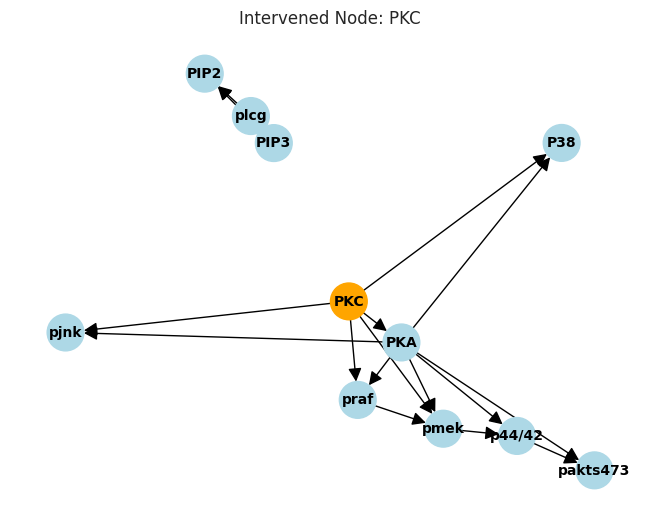

In [10]:
# Create a dropdown for selecting the node we want to intervene on
model_names = ['kan', 'kaam', 'anm', 'dbcm', 'flow']

model_dropdown = widgets.Dropdown(
    options=model_names,
    value=model_names[0],
    description='Model:',
)

node_dropdown = widgets.Dropdown(
    options=list(graph_sachs.nodes),
    value='PKC',
    description='Intervened Node:',
)
# Create sliders for selecting intervention values
cf_value0_slider = widgets.FloatSlider(
    value=-1.0,
    min=cf_min_val,
    max=cf_max_val,
    step=cf_step,
    description='CF Value 0',
)

cf_value1_slider = widgets.FloatSlider(
    value=1.0,
    min=cf_min_val,
    max=cf_max_val,
    step=cf_step,
    description='CF Value 1',
)
cf_results_all = {}
for model_name in model_names:
    with open(os.path.join(data_dir, f'sachs_cf_eval_{model_name}.pkl'), 'rb') as f:
        results_cf = pickle.load(f)
    cf_results_all[model_name] = deepcopy(results_cf)

obs_model_all = {}
for model_name in model_names:
    obs_model = pd.read_csv(os.path.join(samples_dir, f"sachs_obs_samples_{model_name}.csv"))
    obs_model_all[model_name] = deepcopy(obs_model)

results_file = os.path.join(data_dir, f"sachs_results_kaam.pkl") # KAAM results file to extract formulas
with open(results_file, 'rb') as f:
    results_kaam = pickle.load(f)

all_formulae = {}
for child_node in factual_eval.columns:
    all_formulae[child_node] = {}
    child_node_formula = results_kaam.get(f'kaam_formula_{child_node}', None)
    if child_node_formula is None:
        print(f'No formula for node {child_node}')
    all_formulae[child_node] = deepcopy(child_node_formula)

pos = nx.spring_layout(graph_sachs)  # Use the same layout always

def plot_function(model, node, value0, value1):
    cf_model_0 = None
    cf_model_1 = None
    for node_, value_, d_ in cf_results_all[model]:
        if node_ == node:
            if np.abs(value_ - value0) < 1e-3:
                cf_model_0 = d_
            if np.abs(value_ - value1) < 1e-3:
                cf_model_1 = d_

    ate_all = {}
    cf_all_0 = []
    cf_all_1 = []
    for m in cf_results_all.keys():
        for node_, value_, d_ in cf_results_all[m]:
            if node_ == node:
                if np.abs(value_ - value0) < 1e-3:
                    cf_all_0.append(d_)
                if np.abs(value_ - value1) < 1e-3:
                    cf_all_1.append(d_)
        ate_all[m] = cf_all_1[-1].mean() - cf_all_0[-1].mean()
    cf_all_0 = pd.concat(cf_all_0, axis=0)
    cf_all_1 = pd.concat(cf_all_1, axis=0)
    # Keep a random subset of samples to prevent slowing down the plot
    cf_all_0 = cf_all_0.sample(frac=1 / len(model_names)).reset_index(drop=True)
    cf_all_1 = cf_all_1.sample(frac=1 / len(model_names)).reset_index(drop=True)


    # Plot a large boxplot, including all variables and their values
    nodes = factual_eval.columns
    positions = np.arange(len(nodes)) * 6
    plt.figure(figsize=(15, 7))
    plt.boxplot([obs_model_all[model][node] for node in nodes], positions=positions, patch_artist=True, boxprops=dict(facecolor='r', color='r', alpha=0.2), label='Observational')
    plt.boxplot([cf_model_0[node] for node in nodes], positions=positions + 1, patch_artist=True, boxprops=dict(facecolor='b', color='b', alpha=0.2), label='CF 1')
    plt.boxplot([cf_model_1[node] for node in nodes], positions=positions + 2, patch_artist=True, boxprops=dict(facecolor='g', color='g', alpha=0.2), label='CF 2')
    plt.boxplot([cf_model_1[node] - cf_model_0[node] for node in nodes], positions=positions + 3, patch_artist=True, boxprops=dict(facecolor='k', color='k', alpha=0.2), label=f'Treatment effect ({model})')
    plt.boxplot([cf_all_1[node] - cf_all_0[node] for node in nodes], positions=positions + 4, patch_artist=True, boxprops=dict(facecolor='brown', color='brown', alpha=0.2), label='Treatment effect (all)')
    plt.xticks(positions + 1.5, nodes, rotation=90)
    plt.xlabel('Node')
    plt.ylabel('Distribution')
    plt.legend(loc='best')
    plt.title(f'Interventional distributions on node {node} with values {value0} and {value1}')
    plt.ylim(-3, 3)  # Limit y-axis for better visualization
    plt.grid()
    plt.tight_layout()
    plt.show()

    ate_all_df = pd.DataFrame(ate_all)
    ate_all_df['ATE_types'] = 'value_diff'
    print(f'ATE estimated for the intervention in node {node} with values {value0} and {value1}')
    print(ate_all_df)


    if model == 'kaam':
        child_nodes = list(nx.descendants(graph_sachs, node))
        print(f'List of children nodes of {node}: {child_nodes}')
        for child_node in child_nodes:
            child_node_formula = deepcopy(all_formulae[child_node])
            print(f'Formula for child node {child_node}: {child_node_formula}')
            ate_formula = child_node_formula.subs(node, value1) - child_node_formula.subs(node, value0)
            print(f'KAAM ATE by formula on node {child_node} when {node} takes values {value0} and {value1}: {ate_formula}')

    # Plot the graph highlighting the intervened node
    node_colors = ['lightblue' if n != node else 'orange' for n in graph_sachs.nodes]
    nx.draw(graph_sachs, pos, with_labels=True, node_size=700, node_color=node_colors, font_size=10, font_weight='bold', arrowsize=20)
    plt.title(f'Intervened Node: {node}')
    plt.show()

plot_function('kaam', 'PKC', 0.1, 2.0)

widgets.interact(plot_function, model=model_dropdown, node=node_dropdown, value0=cf_value0_slider, value1=cf_value1_slider)